In [1]:
# import packages

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust


import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d


# Helper: compute energy landscape
def compute_energy(data, bins):
    p, edges = np.histogram(data, bins=bins, density=True)
    E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, E



def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

import matplotlib as mpl
import matplotlib.pyplot as plt

# --- General figure scaling for Jupyter ---
mpl.rcParams.update({
    "figure.dpi": 150,          # lower DPI → smaller figures on screen
    "figure.figsize": (5, 3),   # default size in inches (width, height)
    "font.size": 10,            # base font size
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

import numpy as np
import matplotlib.pyplot as plt
import types

# ---------- helpers ----------
def _set_pi_ticks(ax):
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

def _energy_amp_and_curve(phi, bins):
    centers, E = compute_energy(phi, bins=bins)
    f = np.isfinite(E)
    if not f.any():
        return np.nan, centers, E, 0
    amp = float(np.nanmax(E[f]) - np.nanmin(E[f]))
    return amp, centers, E, int(f.sum())

def _radius_ok(m, pid, min_R=400.0):
    if not hasattr(m, "particle_data") or m.particle_data is None:
        return False
    R = None
    df = m.particle_data
    if "R" not in getattr(df, "columns", []):
        return False
    # try index first
    if pid in getattr(df, "index", []):
        R = df.loc[pid, "R"]
    # fallback: a 'group' column
    elif "group" in df.columns:
        row = df.loc[df["group"] == pid]
        if not row.empty:
            R = row.iloc[0]["R"]
    try:
        return float(R) > float(min_R)
    except Exception:
        return False

def _rot_end_ok(m, pid, rot_phase='rot-both', tol=2*np.pi):
    """
    Accept if |Δφ| ≤ tol over the rot_phase. Prefer m.trajectories[rot_phase][pid],
    else fall back to locs within protocol window.
    """
    # A) try precomputed trajectory
    try:
        s = m.trajectories[rot_phase][pid].dropna()
        v = np.asarray(s.values, float)
        if v.size >= 2:
            dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
            return np.isfinite(dv) and (abs(dv) <= float(tol))
    except Exception:
        pass

    # B) fallback via locs
    if not hasattr(m, "locs") or "phi" not in m.locs.columns or rot_phase not in m.protocol:
        return False
    locs = m.locs
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            return False
        locs = locs.copy()
        locs["t"] = locs["frame"] * float(m._average_tpf)
    t0, t1 = m.protocol[rot_phase][:2]
    df = locs[(locs["group"] == pid) & (locs["t"] >= t0) & (locs["t"] < t1)]
    if df.empty:
        return False
    v = np.asarray(df["phi"], float)
    if v.size < 2:
        return False
    dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
    return np.isfinite(dv) and (abs(dv) <= float(tol))

# ---------- main method (binds to each m): whitelist only + ALL three filters ----------
def _get_flat_particles(self,
                        threshold_kbt=2.5,
                        phase='umbrella',
                        bins=None,
                        rot_phase='rot-both',
                        rot_end_tol=2*np.pi,
                        radius_min=400.0):
    """
    Return and store m.flat_particles consisting ONLY of whitelist particles that satisfy:
      1) flat umbrella energy: max(E)-min(E) <= threshold_kbt (kBT units),
      2) rot-both end constraint: |Δφ| <= rot_end_tol (default 2π) over rot_phase,
      3) radius filter: R > radius_min from m.particle_data['R'].
    No other fields on m are modified.
    """
    # strict whitelist requirement
    if not hasattr(self, "whitelist") or self.whitelist is None or len(self.whitelist) == 0:
        raise AttributeError("m.whitelist must be set and non-empty.")

    if not hasattr(self, "locs") or "group" not in self.locs.columns or "phi" not in self.locs.columns:
        raise AttributeError("m.locs must exist with columns ['group','phi','frame'].")
    if not hasattr(self, "protocol") or phase not in self.protocol:
        raise AttributeError(f"m.protocol['{phase}'] is required.")
    if not hasattr(self, "_average_tpf"):
        raise AttributeError("m._average_tpf is required to derive time from frames.")

    # time column for phase slicing
    locs = self.locs.copy()
    if "t" not in locs.columns:
        locs["t"] = locs["frame"] * float(self._average_tpf)

    # bins exactly like your plots
    if bins is None:
        bins = np.deg2rad(np.arange(-180, 185, 5))

    # umbrella phase window
    t0, t1 = self.protocol[phase][:2]
    mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

    selected = []
    whitelist = sorted({int(p) for p in self.whitelist})
    present = set(int(g) for g in np.unique(locs["group"]))

    for pid in whitelist:
        if pid not in present:
            continue
        # radius check first (cheap)
        if not _radius_ok(self, pid, min_R=radius_min):
            continue
        # umbrella energy amplitude on whitelist particle
        df = locs[(locs["group"] == pid) & mask_phase]
        if df.empty:
            continue
        amp, _, E, nbin = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
        if not (np.isfinite(amp) and nbin >= 6 and amp <= float(threshold_kbt)):
            continue
        # trajectory end constraint on rot-both
        if not _rot_end_ok(self, pid, rot_phase=rot_phase, tol=rot_end_tol):
            continue
        selected.append(pid)

    self.flat_particles = selected
    return selected

# ---------- bind (idempotent) ----------
def bind_get_flat_particles(m_list):
    for _m in m_list:
        _m.get_flat_particles = types.MethodType(_get_flat_particles, _m)

# # ---------- overview plot: one subplot per m, overlay only the accepted flats ----------
def plot_flat_energy_overview(m_list,
                              threshold_kbt=2.5,
                              phase='umbrella',
                              rot_phase='rot-both',
                              rot_end_tol=2*np.pi,
                              radius_min=400.0):
    """
    Detects flat particles with ALL calibration filters per m (whitelist only),
    then draws one subplot per m with all accepted min-shifted energy landscapes.
    """
    bind_get_flat_particles(m_list)

    n = len(m_list)
    ncols = int(np.ceil(np.sqrt(n)))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.2*nrows))
    axes = np.atleast_1d(axes).ravel()

    bins = np.deg2rad(np.arange(-180, 185, 5))

    for ax, m in zip(axes, m_list):
        try:
            flats = m.get_flat_particles(threshold_kbt=threshold_kbt,
                                         phase=phase,
                                         bins=bins,
                                         rot_phase=rot_phase,
                                         rot_end_tol=rot_end_tol,
                                         radius_min=radius_min)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center', fontsize=7)
            ax.set_axis_off()
            continue

        if len(flats) == 0:
            ax.text(0.5, 0.5, "no eligible particles", ha='center', va='center', fontsize=9)
            ax.set_title(getattr(m, "name", "m"), fontsize=10)
            ax.set_xlim(-np.pi, np.pi)
            _set_pi_ticks(ax)
            continue

        # umbrella window for curves
        locs = m.locs.copy()
        if "t" not in locs.columns:
            locs["t"] = locs["frame"] * float(m._average_tpf)
        t0, t1 = m.protocol[phase][:2]
        mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

        # overlay min-shifted energies
        for pid in flats:
            df = locs[(locs["group"] == pid) & mask_phase]
            if df.empty:
                continue
            _, centers, E, _ = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
            if not np.isfinite(E).any():
                continue
            Es = E - np.nanmin(E)
            ax.plot(centers, Es, lw=1.2, color='k', alpha = 0.5)

        ax.set_title(getattr(m, "name", "m"), fontsize=10)
        ax.set_xlim(-np.pi, np.pi); _set_pi_ticks(ax)
        ax.set_xlabel(r'$\varphi$  / rad'); ax.set_ylabel(r'$V$ / $k_BT$')


    for j in range(len(m_list), len(axes)):
        axes[j].set_axis_off()

    plt.tight_layout()
    plt.show()




In [2]:
# import packages

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec
from pathlib import Path
import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust


import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd
from tqdm.auto import tqdm 

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc


import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust

import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d

import importlib
%load_ext autoreload
%autoreload 2

import roboarmanalysis as ra
from tqdm.auto import tqdm
from contextlib import contextmanager


# Helper: compute energy landscape
def compute_energy(data, bins):
    p, edges = np.histogram(data, bins=bins, density=True)
    E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, E



def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

import matplotlib as mpl
import matplotlib.pyplot as plt

# --- General figure scaling for Jupyter ---
mpl.rcParams.update({
    "figure.dpi": 50,          # lower DPI → smaller figures on screen
    "figure.figsize": (5, 3),   # default size in inches (width, height)
    "font.size": 10,            # base font size
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

import numpy as np
import matplotlib.pyplot as plt
import types

# ---------- helpers ----------
def _set_pi_ticks(ax):
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

def _energy_amp_and_curve(phi, bins):
    centers, E = compute_energy(phi, bins=bins)
    f = np.isfinite(E)
    if not f.any():
        return np.nan, centers, E, 0
    amp = float(np.nanmax(E[f]) - np.nanmin(E[f]))
    return amp, centers, E, int(f.sum())

def _radius_ok(m, pid, min_R=400.0):
    if not hasattr(m, "particle_data") or m.particle_data is None:
        return False
    R = None
    df = m.particle_data
    if "R" not in getattr(df, "columns", []):
        return False
    # try index first
    if pid in getattr(df, "index", []):
        R = df.loc[pid, "R"]
    # fallback: a 'group' column
    elif "group" in df.columns:
        row = df.loc[df["group"] == pid]
        if not row.empty:
            R = row.iloc[0]["R"]
    try:
        return float(R) > float(min_R)
    except Exception:
        return False

def _rot_end_ok(m, pid, rot_phase='rot-both', tol=2*np.pi):
    """
    Accept if |Δφ| ≤ tol over the rot_phase. Prefer m.trajectories[rot_phase][pid],
    else fall back to locs within protocol window.
    """
    # A) try precomputed trajectory
    try:
        s = m.trajectories[rot_phase][pid].dropna()
        v = np.asarray(s.values, float)
        if v.size >= 2:
            dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
            return np.isfinite(dv) and (abs(dv) <= float(tol))
    except Exception:
        pass

    # B) fallback via locs
    if not hasattr(m, "locs") or "phi" not in m.locs.columns or rot_phase not in m.protocol:
        return False
    locs = m.locs
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            return False
        locs = locs.copy()
        locs["t"] = locs["frame"] * float(m._average_tpf)
    t0, t1 = m.protocol[rot_phase][:2]
    df = locs[(locs["group"] == pid) & (locs["t"] >= t0) & (locs["t"] < t1)]
    if df.empty:
        return False
    v = np.asarray(df["phi"], float)
    if v.size < 2:
        return False
    dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
    return np.isfinite(dv) and (abs(dv) <= float(tol))

# ---------- main method (binds to each m): whitelist only + ALL three filters ----------
def _get_flat_particles(self,
                        threshold_kbt=2.5,
                        phase='umbrella',
                        bins=None,
                        rot_phase='rot-both',
                        rot_end_tol=2*np.pi,
                        radius_min=400.0):
    """
    Return and store m.flat_particles consisting ONLY of whitelist particles that satisfy:
      1) flat umbrella energy: max(E)-min(E) <= threshold_kbt (kBT units),
      2) rot-both end constraint: |Δφ| <= rot_end_tol (default 2π) over rot_phase,
      3) radius filter: R > radius_min from m.particle_data['R'].
    No other fields on m are modified.
    """
    # strict whitelist requirement
    if not hasattr(self, "whitelist") or self.whitelist is None or len(self.whitelist) == 0:
        raise AttributeError("m.whitelist must be set and non-empty.")

    if not hasattr(self, "locs") or "group" not in self.locs.columns or "phi" not in self.locs.columns:
        raise AttributeError("m.locs must exist with columns ['group','phi','frame'].")
    if not hasattr(self, "protocol") or phase not in self.protocol:
        raise AttributeError(f"m.protocol['{phase}'] is required.")
    if not hasattr(self, "_average_tpf"):
        raise AttributeError("m._average_tpf is required to derive time from frames.")

    # time column for phase slicing
    locs = self.locs.copy()
    if "t" not in locs.columns:
        locs["t"] = locs["frame"] * float(self._average_tpf)

    # bins exactly like your plots
    if bins is None:
        bins = np.deg2rad(np.arange(-180, 185, 5))

    # umbrella phase window
    t0, t1 = self.protocol[phase][:2]
    mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

    selected = []
    whitelist = sorted({int(p) for p in self.whitelist})
    present = set(int(g) for g in np.unique(locs["group"]))

    for pid in whitelist:
        if pid not in present:
            continue
        # radius check first (cheap)
        if not _radius_ok(self, pid, min_R=radius_min):
            continue
        # umbrella energy amplitude on whitelist particle
        df = locs[(locs["group"] == pid) & mask_phase]
        if df.empty:
            continue
        amp, _, E, nbin = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
        if not (np.isfinite(amp) and nbin >= 6 and amp <= float(threshold_kbt)):
            continue
        # trajectory end constraint on rot-both
        if not _rot_end_ok(self, pid, rot_phase=rot_phase, tol=rot_end_tol):
            continue
        selected.append(pid)

    self.flat_particles = selected
    return selected

# ---------- bind (idempotent) ----------
def bind_get_flat_particles(m_list):
    for _m in m_list:
        _m.get_flat_particles = types.MethodType(_get_flat_particles, _m)

# ---------- overview plot: one subplot per m, overlay only the accepted flats ----------
def plot_flat_energy_overview(m_list,
                              threshold_kbt=2.5,
                              phase='umbrella',
                              rot_phase='rot-both',
                              rot_end_tol=2*np.pi,
                              radius_min=400.0):
    """
    Detects flat particles with ALL calibration filters per m (whitelist only),
    then draws one subplot per m with all accepted min-shifted energy landscapes.
    """
    bind_get_flat_particles(m_list)

    n = len(m_list)
    ncols = int(np.ceil(np.sqrt(n)))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.2*nrows))
    axes = np.atleast_1d(axes).ravel()

    bins = np.deg2rad(np.arange(-180, 185, 5))

    for ax, m in zip(axes, m_list):
        try:
            flats = m.get_flat_particles(threshold_kbt=threshold_kbt,
                                         phase=phase,
                                         bins=bins,
                                         rot_phase=rot_phase,
                                         rot_end_tol=rot_end_tol,
                                         radius_min=radius_min)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center', fontsize=7)
            ax.set_axis_off()
            continue

        if len(flats) == 0:
            ax.text(0.5, 0.5, "no eligible particles", ha='center', va='center', fontsize=9)
            ax.set_title(getattr(m, "name", "m"), fontsize=10)
            ax.set_xlim(-np.pi, np.pi)
            _set_pi_ticks(ax)
            continue

        # umbrella window for curves
        locs = m.locs.copy()
        if "t" not in locs.columns:
            locs["t"] = locs["frame"] * float(m._average_tpf)
        t0, t1 = m.protocol[phase][:2]
        mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

        # overlay min-shifted energies
        for pid in flats:
            df = locs[(locs["group"] == pid) & mask_phase]
            if df.empty:
                continue
            _, centers, E, _ = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
            if not np.isfinite(E).any():
                continue
            Es = E - np.nanmin(E)
            ax.plot(centers, Es, lw=1.2, color='k', alpha = 0.5)

        ax.set_title(getattr(m, "name", "m"), fontsize=10)
        ax.set_xlim(-np.pi, np.pi); _set_pi_ticks(ax)
        ax.set_xlabel(r'$\varphi$  / rad'); ax.set_ylabel(r'$V$ / $k_BT$')


    for j in range(len(m_list), len(axes)):
        axes[j].set_axis_off()

    plt.tight_layout()
    plt.show()



import re
from math import inf
from typing import Iterable

# Variant order for sorting (unknowns last)
_VARIANT_ORDER = {'A':0, 'B':1, 'C':2, 'D':3, 'E':4}

def assign_conditions(m) -> None:
    """
    Parse m's path/filename and write:
      m.stator_variant ∈ {'A','B','C','D','E'} (or None)
      m.bias_voltage_V : float (or None)
      m.time_halfcycle_s : float seconds (or None)
      m.source_path : str (best-guess source path/filename)
      m._detect_notes : str (human-readable summary)
    Side effects only. Returns None.

    All helpers are defined locally to keep the API surface minimal.
    """

    # -------- helpers (local only) --------
    def _path_of(obj) -> str:
        for a in ("path","filepath","file","filename","source","source_file",
                  "hdf5_path","hdf5","directory","dirpath"):
            v = getattr(obj, a, None)
            if isinstance(v, str) and v:
                return v
        for a in ("meta","info","attrs","props"):
            d = getattr(obj, a, None)
            if isinstance(d, dict):
                for k in ("path","filepath","file","filename","source","source_file",
                          "hdf5_path","hdf5","directory","dirpath"):
                    v = d.get(k)
                    if isinstance(v, str) and v:
                        return v
        return str(obj)

    # Precedence: more specific first; restricted to A..E as requested
    _VARIANT_RULES = [
        (re.compile(r'[/\\]ratchet2_eds([/\\]|_|$)', re.I), 'F'),  # map EDS → E (change if you need 'F')
        (re.compile(r'[/\\]ratchet2_e([/\\]|_|$)',   re.I), 'C'),
        (re.compile(r'[/\\]ratchet2_8ds([/\\]|_|$)', re.I), 'E'),
        (re.compile(r'[/\\]ratchet2_8([/\\]|_|$)',   re.I), 'D'),
        (re.compile(r'[/\\]ratchet2_0([/\\]|_|$)',   re.I), 'B'),
        (re.compile(r'[/\\]ratchet1_0([/\\]|_|$)',   re.I), 'A'),
    ]
    def _detect_variant(s: str):
        for rgx, lab in _VARIANT_RULES:
            if rgx.search(s):
                return lab
        # defensive second pass with separators flattened
        snk = s.replace('\\', '_').replace('/', '_')
        for rgx, lab in _VARIANT_RULES:
            if rgx.search(snk):
                return lab
        return None

    # -------- /helpers --------

    s = _path_of(m)
    notes = []

    v = _detect_variant(s)
    try: setattr(m, "stator_variant", v)
    except Exception: notes.append("warn: cannot set stator_variant")
    notes.append(f"variant: {v}" if v else "variant: not found")


    try: setattr(m, "source_path", s)
    except Exception: pass
    try: setattr(m, "_detect_notes", "; ".join(notes))
    except Exception: pass


def reorder_by_variant(m_list: Iterable, annotate: bool = True):
    """
    Return a NEW list ordered by:
      1) stator_variant (A<B<C<D<E<Unknown),
      2) bias_voltage_V ascending (unknowns last),
      3) time_halfcycle_s ascending (unknowns last),
      4) original index (stable).
    If annotate=True, runs assign_conditions(m) for each m first.
    """
    packed = []
    for i, m in enumerate(m_list):
        if annotate:
            assign_conditions(m)

        v = getattr(m, "stator_variant", None)
        vkey = _VARIANT_ORDER.get(v, 10**6)

        packed.append((vkey, i, m))

    packed.sort(key=lambda t: (t[0], t[1]))
    return [t[-1] for t in packed]




def purge_locscolumns(m, cols=None):
    LOC_COLUMNS_TO_DROP = ['photosm', 'photons', 'sx', 'sy', 'bg', 'lpx', 'lpy', 'ellipticity', 'net_gradient']    
    if cols is None:
        cols = LOC_COLUMNS_TO_DROP
    if hasattr(m, 'locs') and isinstance(m.locs, pd.DataFrame):
        drop = [c for c in cols if c in m.locs.columns]
        if drop:
            m.locs = m.locs.drop(columns=drop)



# -------- optional vik colormap (fallback to coolwarm) --------
try:
    import cmcrameri.cm as cmc
    _vik = cmc.vik
except Exception:
    _vik = plt.cm.get_cmap("coolwarm")
    cmc = None

# -------- style --------
PAPER_RC = {
    "text.usetex": False, "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans",
    "font.size": 8, "axes.labelsize": 7, "axes.titlesize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 180,
    "axes.linewidth": 0.6, "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.size": 2.0, "ytick.major.size": 2.0, "svg.fonttype": "none",
}
def _style_ax(ax, grey="0.25"):
    for s in ax.spines.values():
        s.set_color(grey); s.set_linewidth(0.6)
    ax.tick_params(length=2.0, width=0.6, colors=grey)
    ax.xaxis.label.set_color(grey); ax.yaxis.label.set_color(grey)
    ax.title.set_color(grey); ax.grid(False)


import warnings

warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="Degrees of freedom <= 0 for slice", category=RuntimeWarning)

In [3]:
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap, to_rgba
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 300
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "mathtext.default": "regular",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

CK_colors = {
    "orange":    (215/255, 131/255,  41/255),
    "beige":     (225/255, 209/255, 180/255),
    "gold":      (226/255, 172/255,  72/255),
    "olive":     (140/255, 135/255,  59/255),
    "offwhite":  (222/255, 224/255, 213/255),
    "palecyan":  (167/255, 197/255, 197/255),
    "darkcyan":  (105/255, 155/255, 155/255),
    "lightblue": ( 73/255, 139/255, 167/255),
    "darkblue":  ( 46/255,  89/255, 108/255),
    "darkred":   (102/255,  27/255,  35/255),
    "grey":      (0.25, 0.25, 0.25),
    "midgrey":   (0.45, 0.45, 0.45),
    "lightgrey": (0.72, 0.72, 0.72),
    "black":      (0, 0, 0),
    "white":      (1, 1, 1),
    "warmgold":   (198/255, 161/255,  91/255),
    "target_teal": (111/255, 166/255, 166/255),
    "free_grey":      (201/255, 201/255, 201/255),  # #C9C9C9
    "fit_darkgrey":   ( 46/255,  46/255,  46/255),  # #2E2E2E
}


target_voltage_colors = {
    200: (190 / 255, 220 / 255, 218 / 255),
    250: (111 / 255, 166 / 255, 166 / 255),
    300: (46 / 255, 89 / 255, 108 / 255),
}

calibration_voltage_colors = {
    200: (238 / 255, 196 / 255, 105 / 255),
    250: (226 / 255, 172 / 255, 72 / 255),
    300: (198 / 255, 131 / 255, 41 / 255),
}

## Load and trim dataset

In [4]:
save_dir = Path(r"R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss")
keywords = ["fov04"]

exclude_keywords = []


stator_variant = None
full_execution = False
full_execution_convergence = False
full_execution_uncertainty = False

t_UMB = 5
t_DIFF = 60
dt_s = 0.005
t_diff = 1
umbrella_step_deg = 20


allowed_missed_percentage = 20



m_list_loaded = ra.load_multiple_measurements(
    save_dir,
    keywords=keywords,
    exclude_keywords=exclude_keywords,
)

save_dir = Path(r"R:\_06_Umbrella_Sampling\02_Figures\Figure_3\_plots")
save_dir_SI = Path(r"R:\_06_Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_3")


 >>> y-coordinates are flipped to account for TIRFM geometry (now aligns with micromanager and picasso).
Filtered localizations for a fit uncertainty less than 100nm.
...protocol.txt file not found in R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov04_11_UMB_200V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1.
Import the file with .get_protocol(path_to_your_txt_file)
Adding file: R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov04_11_UMB_200V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1\260707-fov04_11_UMB_200V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5

 >>> y-coordinates are flipped to account for TIRFM geometry (now aligns with micromanager and picasso).
Filtered localizations for a fit uncertainty less than 100nm.
...protocol.txt file not found in R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov04_12_UMB_250V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1.
Import the file with .get_protocol(path_to_your_txt_fil

In [5]:
m_list = m_list_loaded

# for m in m_list:
#     if "UMB" in Path(m.path).name:
#         m.get_flat_particles = types.MethodType(_get_flat_particles, m)

## Process dataset - assign phases, compute polar coordinates, trajectories

In [6]:
def flag_radial_outliers_by_std(
    m,
    *,
    group_col='group',
    rho_col='rho',
    R_col='R',
    flag_col='radial_outlier',
    n_sigma_inner=3.0,
    n_sigma_outer=3.0,
    min_points_sigma=50,
    verbose=True,
):
    """
    Per-particle radial outlier flagger, based on deviations from the per-particle
    radius R_i and per-particle σ(rho)_i.

        R_i      = m.particle_data.loc[i, R_col]
        σ_i      = std of rho over all locs of particle i (finite values only)
        keep if  R_i - n_sigma_inner * σ_i <= rho <= R_i + n_sigma_outer * σ_i

    ALWAYS overwrites `flag_col` completely on each call.
    """

    if not hasattr(m, "locs"):
        raise AttributeError("m has no attribute 'locs'.")
    if not hasattr(m, "particle_data"):
        raise AttributeError("m has no attribute 'particle_data'.")

    L = m.locs
    if group_col not in L.columns:
        raise KeyError(f"Column '{group_col}' not found in m.locs.")
    if rho_col not in L.columns:
        raise KeyError(f"Column '{rho_col}' not found in m.locs.")
    if R_col not in m.particle_data.columns:
        raise KeyError(f"Column '{R_col}' not found in m.particle_data.")

    # particle IDs and rho as arrays (no copy of sub-DataFrame)
    pid = L[group_col].astype("Int64")          # nullable ints
    rho = L[rho_col].to_numpy(float)

    # ------------------------------------------------------------------
    # 1) per-particle σ(rho) using a single groupby
    # ------------------------------------------------------------------
    # rows with a defined particle id and finite rho
    mask_valid = pid.notna().to_numpy() & np.isfinite(rho)
    if not np.any(mask_valid):
        if verbose:
            print("RadialOutliers(std): no finite rho values; nothing flagged.")
        L[flag_col] = False
        m.locs = L
        return dict(total_flagged_points=0,
                    n_particles_with_flags=0,
                    n_particles_with_sigma=0)

    df_valid = L.loc[mask_valid, [group_col, rho_col]]
    # one groupby pass: count + std
    stats = df_valid.groupby(group_col)[rho_col].agg(['count', 'std'])
    # require enough points and finite positive sigma
    good = (stats['count'] >= min_points_sigma) & np.isfinite(stats['std']) & (stats['std'] > 0)
    sigmas_rho = stats.loc[good, 'std']
    n_particles_sigma = int(sigmas_rho.shape[0])

    if n_particles_sigma == 0:
        if verbose:
            print("RadialOutliers(std): no particle met the min_points_sigma criterion; nothing flagged.")
        L[flag_col] = False
        m.locs = L
        return dict(total_flagged_points=0,
                    n_particles_with_flags=0,
                    n_particles_with_sigma=0)

    # ------------------------------------------------------------------
    # 2) map R_i and σ_i to each row (vectorised)
    # ------------------------------------------------------------------
    R_series = m.particle_data[R_col].astype(float)

    # pandas Int64 -> normal int index series for fast .map
    pid_int = pid.astype("Int64")   # already Int64, but ensures dtype
    R_for_row     = pid_int.map(R_series).to_numpy(float)
    sigma_for_row = pid_int.map(sigmas_rho).to_numpy(float)

    ok = (np.isfinite(rho) &
          np.isfinite(R_for_row) &
          np.isfinite(sigma_for_row) &
          (sigma_for_row > 0))

    lo = R_for_row - n_sigma_inner * sigma_for_row
    hi = R_for_row + n_sigma_outer * sigma_for_row

    mask_out = ok & ((rho < lo) | (rho > hi))

    # ALWAYS overwrite flag column
    L[flag_col] = mask_out
    m.locs = L

    total_flagged = int(mask_out.sum())
    if total_flagged > 0:
        # pid_int is nullable; dropna() then numpy(int)
        pids_flagged = np.unique(pid_int[mask_out].dropna().to_numpy(int))
        n_particles_with_flags = int(pids_flagged.size)
    else:
        n_particles_with_flags = 0

    summary = dict(
        total_flagged_points=total_flagged,
        n_particles_with_flags=n_particles_with_flags,
        n_particles_with_sigma=n_particles_sigma,
    )

    if verbose:
        print(
            f"RadialOutliers(std): σ(rho) estimated for {summary['n_particles_with_sigma']} particles; "
            f"flagged {summary['total_flagged_points']} points "
            f"in {summary['n_particles_with_flags']} particles."
        )

    return summary


import numpy as np

def purge_outlier_rows(
    m,
    flag_cols=('radial_outlier',),
    *,
    verbose=True,
):
    """
    Remove all rows from m.locs where ANY of the given flag columns is True,
    and then drop those flag columns from m.locs.

    Parameters
    ----------
    m : measurement object with .locs DataFrame
    flag_cols : str or iterable of str
        Boolean columns in m.locs that mark rows to remove.
    verbose : bool
        If True, print a short summary.

    Returns
    -------
    n_dropped : int
        Number of rows removed.
    """

    if not hasattr(m, "locs"):
        raise AttributeError("m has no attribute 'locs'.")

    L = m.locs
    if isinstance(flag_cols, str):
        flag_cols = [flag_cols]
    else:
        flag_cols = list(flag_cols)

    # sanity: all must exist
    for c in flag_cols:
        if c not in L.columns:
            raise KeyError(f"Column '{c}' not found in m.locs.")

    n0 = len(L)

    # build combined mask of rows to drop
    drop_mask = np.zeros(n0, dtype=bool)
    for c in flag_cols:
        col = L[c]
        if col.dtype != bool:
            flags = col.astype(bool).to_numpy()
        else:
            flags = col.to_numpy()
        drop_mask |= flags

    n_drop = int(drop_mask.sum())

    # keep unflagged rows only
    if n_drop > 0:
        L = L.loc[~drop_mask].copy()
    else:
        L = L.copy()

    # write back
    m.locs = L

def heal_trajectories_nan_sequences(
    m,
    *,
    phases=('ratch-y', 'ratch-x'),
    max_interp_gap=3,
    snapshot_attr='trajectories_raw',
    verbose=True
):
    """
    Heal short NaN runs in m.trajectories[phase] (DataFrames) and flag long runs.

    Assumptions
    -----------
    - m.trajectories[phase][pid] contains UNWRAPPED, cumulative angles
      (can run over many multiples of 2π).
    - No angular wrapping or modulo logic is applied here; we just interpolate
      in the numeric space already present.

    Behaviour
    ---------
    - For each phase and each particle (column):
        * Detect contiguous NaN runs in the 1D series.
        * If run length <= max_interp_gap and both endpoints are finite:
              linearly interpolate between endpoints.
              These points are marked True in nan_interp_mask[phase].
        * Otherwise:
              keep NaNs; mark them as long in nan_long_mask[phase].
    - A one-time snapshot of the original trajectories is stored as:
          getattr(m, snapshot_attr)
      if that attribute does not yet exist.
    - Masks are stored as DataFrames with same index/columns:
          m.nan_long_mask[phase]
          m.nan_interp_mask[phase]
    - A per-phase summary is stored as:
          m.nan_healing_summary[phase] = dict(...)
    - If verbose=True, prints:
          "HealNaN: healed <total_runs> NaN-sequences in <n_rotors> rotors."
      aggregated over all requested phases.
    """

    # ----------------------- one-time snapshot ------------------------
    if not hasattr(m, snapshot_attr):
        traj = getattr(m, 'trajectories', {})
        setattr(m, snapshot_attr, {ph: df.copy() for ph, df in traj.items()})

    # ensure containers on m
    if not hasattr(m, 'nan_long_mask'):
        m.nan_long_mask = {}
    if not hasattr(m, 'nan_interp_mask'):
        m.nan_interp_mask = {}
    if not hasattr(m, 'nan_healing_summary'):
        m.nan_healing_summary = {}

    nan_long_dict = {}
    nan_interp_dict = {}
    summary_per_phase = {}

    # -------------------- main per-phase loop -------------------------
    for phase in phases:
        if not hasattr(m, 'trajectories') or phase not in m.trajectories:
            continue

        df = m.trajectories[phase]
        if not isinstance(df, pd.DataFrame) or df.empty:
            continue

        healed = df.copy()
        long_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
        interp_mask = pd.DataFrame(False, index=df.index, columns=df.columns)

        n_rotors = len(df.columns)
        n_rotors_with_interp = 0
        n_rotors_with_long = 0
        n_runs_short = 0
        n_runs_long = 0

        for col in df.columns:
            s = df[col].to_numpy()
            isnan = np.isnan(s)
            if not isnan.any():
                continue

            n = len(s)
            i = 0
            col_interp = interp_mask[col].to_numpy()
            col_long = long_mask[col].to_numpy()

            has_interp_here = False
            has_long_here = False

            while i < n:
                if not isnan[i]:
                    i += 1
                    continue

                # start of NaN run
                start = i
                while i < n and isnan[i]:
                    i += 1
                end = i  # NaN run is [start, end)

                run_len = end - start
                before = start - 1
                after = end

                has_before = (before >= 0) and np.isfinite(s[before])
                has_after = (after < n) and np.isfinite(s[after])

                if run_len <= max_interp_gap and has_before and has_after:
                    # short, bridgeable gap → plain linear interpolation
                    y0 = s[before]
                    y1 = s[after]
                    t = np.arange(1, run_len + 1, dtype=float) / (run_len + 1)
                    vals = (1.0 - t) * y0 + t * y1

                    healed[col].iloc[start:end] = vals
                    col_interp[start:end] = True
                    has_interp_here = True
                    n_runs_short += 1
                else:
                    # long gap or missing endpoints → keep NaNs, mark as long
                    col_long[start:end] = True
                    has_long_here = True
                    n_runs_long += 1

            interp_mask[col] = col_interp
            long_mask[col] = col_long

            if has_interp_here:
                n_rotors_with_interp += 1
            if has_long_here:
                n_rotors_with_long += 1

        # write back per phase
        m.trajectories[phase] = healed
        m.nan_long_mask[phase] = long_mask
        m.nan_interp_mask[phase] = interp_mask

        summary = dict(
            n_rotors=n_rotors,
            n_rotors_with_interp=n_rotors_with_interp,
            n_rotors_with_long=n_rotors_with_long,
            n_runs_short=n_runs_short,
            n_runs_long=n_runs_long,
            max_interp_gap=max_interp_gap,
        )
        m.nan_healing_summary[phase] = summary

        nan_long_dict[phase] = long_mask
        nan_interp_dict[phase] = interp_mask
        summary_per_phase[phase] = summary

    # ------------------------- minimal verbose output -------------------------
    if verbose and summary_per_phase:
        # total number of healed NaN-runs over all phases
        total_healed_runs = sum(s["n_runs_short"] for s in summary_per_phase.values())

        # set of rotors that had at least one healed point in any phase
        healed_rotors = set()
        for df_interp in nan_interp_dict.values():
            cols = df_interp.columns[(df_interp.sum(axis=0) > 0).to_numpy()]
            for c in cols:
                try:
                    healed_rotors.add(int(c))
                except Exception:
                    healed_rotors.add(c)

        print(
            f"HealNaN: healed {total_healed_runs} NaN-sequences "
            f"in {len(healed_rotors)} rotors."
        )


In [7]:
# Assign phases, convert to polar coordinates, compute trajectories
columns_to_drop = ['photosm', 'photons', 'sx', 'sy', 'bg', 'lpx', 'lpy', 'ellipticity', 'net_gradient']
allowed_missed_percentage = 20



for idx, m in enumerate(m_list):
    name = Path(m.path).name
    print(name)

    if "UMB" in name:
        m.protocol = {}
        m.protocol["diff"] = (0, t_diff)

        n_windows = int(round(360 / umbrella_step_deg))
        if abs(n_windows * umbrella_step_deg - 360) > 1e-9:
            raise ValueError(
                f"umbrella_step_deg={umbrella_step_deg} does not divide 360 cleanly."
            )

        # Important:
        # Check "ccw" before "cw", because "ccw" contains the substring "cw".
        if "ccw" in name:
            direction = "ccw"
        elif "cw" in name:
            direction = "cw"
        else:
            direction = "ccw"

        if direction == "cw":
            umbrella_degs = [(360 - i * umbrella_step_deg) % 360 for i in range(n_windows)]
        else:
            umbrella_degs = [(i * umbrella_step_deg) % 360 for i in range(n_windows)]

        for i, deg in enumerate(umbrella_degs):
            start = t_diff + t_UMB * i
            m.protocol[f"deg-{deg}"] = (start, start + t_UMB)

        umbrella_end = t_diff + t_UMB * n_windows

        m.protocol["umbrella"] = (t_diff, umbrella_end)
        m.protocol["all"] = (0, umbrella_end)

    if "DIFF" in name:
        m.protocol = {"diff": (0, t_DIFF)}

    m._has_protocol = True
    m._num_phases = len(m.protocol)


260707-fov04_11_UMB_200V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5
260707-fov04_12_UMB_250V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5
260707-fov04_13_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5
260707-fov04_10_DIFF_60s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5


In [8]:
ra.fit_circles_with_reference_measurement(m_list, m_list, particles=None)


for idx, m in enumerate(m_list):
    if hasattr(m, "protocol") and "all" in m.protocol:
        t0, t1 = m.protocol["all"]
        duration_s = t1 - t0
    else:
        duration_s = (m.locs["frame"].max() - m.locs["frame"].min() + 1) * dt_s

    expected_frames = duration_s / dt_s
    frame_threshold = (1 - allowed_missed_percentage / 100) * expected_frames


    counts = m.locs.groupby("group")["frame"].nunique()
    bl = counts[counts < frame_threshold].index.tolist()
    m.add_to_blacklist(bl, silent=True)
    purge_locscolumns(m, cols = columns_to_drop)
    
    print(str(idx) + ': ' + Path(m.path).name + ' ' + str(len(m.whitelist)) + ' particles.')


for idx, m in enumerate(m_list):
    flag_radial_outliers_by_std(m, n_sigma_inner=4, n_sigma_outer=4)
    purge_outlier_rows(m)
    m.calc_trajectories()
    heal_trajectories_nan_sequences(m,phases=('umbrella'),max_interp_gap=3,verbose=True)


Fitting circles for whitelist:


  0%|          | 0/214 [00:00<?, ?it/s]

Compute polar coordinates for all measurements.
0: 260707-fov04_11_UMB_200V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5 195 particles.
1: 260707-fov04_12_UMB_250V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5 183 particles.
2: 260707-fov04_13_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5 185 particles.
3: 260707-fov04_10_DIFF_60s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5 191 particles.
RadialOutliers(std): σ(rho) estimated for 214 particles; flagged 6109 points in 213 particles.


Phases:   0%|          | 0/21 [00:00<?, ?it/s]

  diff:   0%|          | 0/195 [00:00<?, ?it/s]

  deg-0:   0%|          | 0/195 [00:00<?, ?it/s]

... (64 outputs left out)

  all:   0%|          | 0/185 [00:00<?, ?it/s]

RadialOutliers(std): σ(rho) estimated for 214 particles; flagged 8129 points in 203 particles.


Phases:   0%|          | 0/1 [00:00<?, ?it/s]

  diff:   0%|          | 0/191 [00:00<?, ?it/s]

### _[Inspect individual particle behavior]_

In [9]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps


try:
    import cmcrameri.cm as cmc
    _vik = cmc.vik
except Exception:
    _vik = colormaps.get_cmap("coolwarm")


def plot_diff_multi_umb_quickcheck(
    m_list,
    particles=None,
    diff_phase="diff",
    umb_phase="umbrella",
    flat_threshold_kbt=1.0,
    polar_rmax=500,
    bins=np.deg2rad(np.arange(-180, 185, 5)),
    max_particles=None,
    show_only_flat=False,

    # filters
    min_radius_nm=None,
    max_radius_nm=None,
    min_diff_barrier_kbt=None,
    max_diff_barrier_kbt=None,

    # lightweight controls
    figsize=None,
    dpi=80,
    scatter_max_points_diff=3500,
    scatter_max_points_umb_per_window=700,
    trajectory_max_points=3000,
    close_after_show=True,
    random_seed=1,

    # compact layout
    width_ratios=(0.95, 1.45, 0.95, 1.45, 1.35),
    left=0.04,
    right=0.99,
    bottom=0.11,
    top=0.86,
    wspace=0.28,
    hspace=0.42,

    # appearance
    diff_marker_size=5,
    umb_marker_size=4,
    diff_alpha=0.20,
    umb_alpha=0.28,
    traj_lw=0.8,
    energy_lw_diff=1.7,
    energy_lw_umb=1.4,
    circle_lw=1.15,
    circle_color="#D99A00",
):
    """
    Lightweight quickcheck plot:
      - one figure per rotor
      - all scatter clouds rasterized
      - compact default figure size
      - no umbrella shading
      - chronological umbrella window order
      - circle overlay
      - radius / barrier filters
      - figures closed after display
    """

    rng = np.random.default_rng(random_seed)

    c_diff = _vik(0.22)
    c_flat = "#AA752F"
    c_grey = "0.25"
    umb_cmap = colormaps.get_cmap("tab10")
    reds = colormaps.get_cmap("Reds")

    def is_umb(m):
        return "umb" in Path(str(m.path)).name.lower()

    def is_diff(m):
        name = Path(str(m.path)).name.lower()
        return ("diff" in name) and ("umb" not in name)

    def short_name(m):
        name = Path(str(m.path)).name
        m_step = re.search(r"_(\d+)deg_", name)
        m_volt = re.search(r"_(\d+)V_", name)
        step = f"{m_step.group(1)}deg" if m_step else "UMB"
        volt = f"{m_volt.group(1)}V" if m_volt else ""
        return f"{volt} {step}".strip()

    def locs_with_time(m):
        locs = m.locs.copy()
        if "t" not in locs.columns:
            if "frame" not in locs.columns:
                raise ValueError(f"{Path(str(m.path)).name}: neither 't' nor 'frame' found in m.locs.")
            locs["t"] = locs["frame"] * float(m._average_tpf)
        return locs

    def phase_df(m, particle, phase):
        if not hasattr(m, "protocol") or phase not in m.protocol:
            return locs_with_time(m).iloc[0:0].copy()
        locs = locs_with_time(m)
        t0, t1 = m.protocol[phase][:2]
        return locs[
            (locs["group"].astype(int) == int(particle))
            & (locs["t"] >= t0)
            & (locs["t"] < t1)
        ].copy()

    def downsample_df(df, nmax):
        if nmax is None or len(df) <= nmax:
            return df
        idx = rng.choice(df.index.to_numpy(), size=int(nmax), replace=False)
        idx = np.sort(idx)
        return df.loc[idx]

    def downsample_xy(x, y, nmax):
        x = np.asarray(x)
        y = np.asarray(y)
        if nmax is None or len(x) <= nmax:
            return x, y
        idx = rng.choice(np.arange(len(x)), size=int(nmax), replace=False)
        idx = np.sort(idx)
        return x[idx], y[idx]

    def energy_from_phi(phi):
        phi = np.asarray(phi, dtype=float)
        phi = ((phi + np.pi) % (2 * np.pi)) - np.pi
        phi = phi[np.isfinite(phi)]

        counts, edges = np.histogram(phi, bins=bins, density=False)
        centers = 0.5 * (edges[:-1] + edges[1:])

        p = counts.astype(float)
        if p.sum() > 0:
            p /= p.sum()

        E = np.full_like(p, np.nan, dtype=float)
        mask = p > 0
        E[mask] = -np.log(p[mask])

        if np.isfinite(E).any():
            E -= np.nanmin(E)
            amp = float(np.nanmax(E) - np.nanmin(E))
        else:
            amp = np.nan

        return centers, E, amp

    def style_ax(ax):
        for s in ax.spines.values():
            s.set_linewidth(0.6)
            s.set_color(c_grey)
        ax.tick_params(length=2.0, width=0.6, colors=c_grey, labelsize=7)
        ax.xaxis.label.set_color(c_grey)
        ax.yaxis.label.set_color(c_grey)
        ax.title.set_color(c_grey)
        ax.grid(False)

    def pi_axis(ax):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"], fontsize=7)

    def get_particle_circle(m, particle):
        xc = yc = R = np.nan

        if not hasattr(m, "particle_data"):
            return xc, yc, R

        pd = m.particle_data

        try:
            row = None

            if hasattr(pd, "index") and int(particle) in pd.index:
                row = pd.loc[int(particle)]
            else:
                for col in ["particle", "particle_id", "pid", "group", "track", "trajectory"]:
                    if hasattr(pd, "columns") and col in pd.columns:
                        hit = pd[pd[col].astype(int) == int(particle)]
                        if len(hit):
                            row = hit.iloc[0]
                            break

            if row is None:
                return xc, yc, R

            for key in ["xc", "x0", "center_x", "cx"]:
                if key in row:
                    xc = float(row[key])
                    break
            for key in ["yc", "y0", "center_y", "cy"]:
                if key in row:
                    yc = float(row[key])
                    break
            for key in ["R", "r", "radius", "radius_nm"]:
                if key in row:
                    R = float(row[key])
                    break

        except Exception:
            pass

        return xc, yc, R

    def chronological_umb_windows(m_umb):
        if not hasattr(m_umb, "protocol"):
            return []

        windows = []
        for name, val in m_umb.protocol.items():
            if not str(name).startswith("deg-"):
                continue
            try:
                t0 = float(val[0])
                deg = float(str(name).replace("deg-", ""))
                windows.append((t0, deg, name))
            except Exception:
                continue

        windows = sorted(windows, key=lambda x: (x[0], x[1]))
        return [w[2] for w in windows]

    def draw_xy_or_polar_scatter(ax, df, m, particle, color, title, marker_size, alpha, open_marker=False, nmax=1000):
        xc, yc, R = get_particle_circle(m, particle)
        has_xy = ("x" in df.columns) and ("y" in df.columns)
        has_phi_rho = ("phi" in df.columns) and ("rho" in df.columns)

        d = downsample_df(df, nmax)

        if has_xy:
            if open_marker:
                ax.scatter(
                    d["x"], d["y"],
                    s=marker_size,
                    facecolors="none",
                    edgecolors=color,
                    linewidths=0.40,
                    alpha=alpha,
                    rasterized=True,
                )
            else:
                ax.scatter(
                    d["x"], d["y"],
                    s=marker_size,
                    color=color,
                    alpha=alpha,
                    linewidths=0,
                    rasterized=True,
                )

            if np.isfinite(xc) and np.isfinite(yc) and np.isfinite(R) and R > 0:
                th = np.linspace(0, 2 * np.pi, 361)
                ax.plot(
                    xc + R * np.cos(th),
                    yc + R * np.sin(th),
                    color=circle_color,
                    lw=circle_lw,
                    zorder=10,
                )
                ax.plot([xc], [yc], marker="+", ms=4.5, mew=0.8, color=circle_color, zorder=11)

                rr = max(float(polar_rmax), float(R * 1.15))
                ax.set_xlim(xc - rr, xc + rr)
                ax.set_ylim(yc - rr, yc + rr)

            ax.set_aspect("equal", adjustable="box")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(title, fontsize=8)
            style_ax(ax)

        elif has_phi_rho:
            if open_marker:
                ax.scatter(
                    d["phi"], d["rho"],
                    s=marker_size,
                    facecolors="none",
                    edgecolors=color,
                    linewidths=0.40,
                    alpha=alpha,
                    rasterized=True,
                )
            else:
                ax.scatter(
                    d["phi"], d["rho"],
                    s=marker_size,
                    color=color,
                    alpha=alpha,
                    linewidths=0,
                    rasterized=True,
                )

            if np.isfinite(R) and R > 0:
                th = np.linspace(-np.pi, np.pi, 361)
                ax.plot(th, np.full_like(th, R), color=circle_color, lw=circle_lw, zorder=10)

            ax.set_rlim(0, polar_rmax)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(True, lw=0.35, alpha=0.30)
            ax.set_title(title, fontsize=8)

        else:
            ax.text(
                0.5, 0.5, "no x/y or phi/rho",
                ha="center", va="center",
                transform=ax.transAxes,
                fontsize=8, color=c_grey,
            )
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(title, fontsize=8)
            style_ax(ax)

    m_diff = next((m for m in m_list if is_diff(m)), None)
    m_umbs = [m for m in m_list if is_umb(m)]

    if m_diff is None:
        raise ValueError("No standalone DIFF dataset found from m.path.")
    if len(m_umbs) == 0:
        raise ValueError("No UMB datasets found from m.path.")

    if particles is None:
        if hasattr(m_diff, "whitelist"):
            particles = sorted(map(int, m_diff.whitelist))
        else:
            particles = sorted(map(int, m_diff.locs["group"].unique()))
    else:
        particles = list(map(int, particles))

    present_diff = set(map(int, m_diff.locs["group"].unique()))
    present_umbs = [set(map(int, m.locs["group"].unique())) for m in m_umbs]

    particles = [
        p for p in particles
        if p in present_diff and any(p in present for present in present_umbs)
    ]

    particle_records = []
    for particle in particles:
        df_diff = phase_df(m_diff, particle, diff_phase)
        if df_diff.empty or "phi" not in df_diff.columns:
            continue

        _, _, amp_diff = energy_from_phi(df_diff["phi"].to_numpy())
        _, _, R = get_particle_circle(m_diff, particle)

        if min_radius_nm is not None and (not np.isfinite(R) or R < min_radius_nm):
            continue
        if max_radius_nm is not None and (not np.isfinite(R) or R > max_radius_nm):
            continue
        if min_diff_barrier_kbt is not None and (not np.isfinite(amp_diff) or amp_diff < min_diff_barrier_kbt):
            continue
        if max_diff_barrier_kbt is not None and (not np.isfinite(amp_diff) or amp_diff > max_diff_barrier_kbt):
            continue

        particle_records.append((particle, amp_diff, R))

    if max_particles is not None:
        particle_records = particle_records[:int(max_particles)]

    flat_particles = []

    n_umbs = len(m_umbs)
    if figsize is None:
        figsize = (13.2, 2.8 + 1.55 * max(0, n_umbs - 1))

    for particle, amp_diff, R_particle in particle_records:
        df_diff = phase_df(m_diff, particle, diff_phase)
        is_flat_particle = np.isfinite(amp_diff) and amp_diff <= flat_threshold_kbt

        if show_only_flat and not is_flat_particle:
            continue

        if is_flat_particle:
            flat_particles.append(int(particle))

        has_xy_diff = ("x" in df_diff.columns) and ("y" in df_diff.columns)

        fig = plt.figure(figsize=figsize, dpi=dpi)

        gs = fig.add_gridspec(
            n_umbs,
            5,
            width_ratios=width_ratios,
            left=left,
            right=right,
            bottom=bottom,
            top=top,
            wspace=wspace,
            hspace=hspace,
        )

        if has_xy_diff:
            ax_diff_scatter = fig.add_subplot(gs[:, 0])
        else:
            ax_diff_scatter = fig.add_subplot(gs[:, 0], projection="polar")

        ax_diff_traj = fig.add_subplot(gs[:, 1])
        ax_energy = fig.add_subplot(gs[:, 4])

        draw_xy_or_polar_scatter(
            ax=ax_diff_scatter,
            df=df_diff,
            m=m_diff,
            particle=particle,
            color=c_diff,
            title="free diffusion scatter",
            marker_size=diff_marker_size,
            alpha=diff_alpha,
            open_marker=False,
            nmax=scatter_max_points_diff,
        )

        t = df_diff["t"].to_numpy() - df_diff["t"].iloc[0]
        phi_u = np.unwrap(df_diff["phi"].to_numpy()) / (2 * np.pi)
        t_ds, phi_ds = downsample_xy(t, phi_u, trajectory_max_points)
        ax_diff_traj.plot(t_ds, phi_ds, color=c_diff, lw=traj_lw)
        ax_diff_traj.set_title("free diffusion trajectory", fontsize=8)
        ax_diff_traj.set_xlabel("time / s", fontsize=7)
        ax_diff_traj.set_ylabel(r"$\varphi/(2\pi)$", fontsize=7)
        style_ax(ax_diff_traj)

        c, E, amp = energy_from_phi(df_diff["phi"].to_numpy())
        ax_energy.plot(c, E, color=c_diff, lw=energy_lw_diff, label=f"free diff, ΔE={amp:.2f}")

        for umb_idx, m_umb in enumerate(m_umbs):
            umb_color = umb_cmap(umb_idx % 10)
            umb_label = short_name(m_umb)
            umb_windows = chronological_umb_windows(m_umb)

            window_colors = [
                reds(v) for v in np.linspace(0.25, 1.0, max(len(umb_windows), 1))
            ]

            df_umb = phase_df(m_umb, particle, umb_phase)
            has_xy_umb = ("x" in df_umb.columns) and ("y" in df_umb.columns)

            if has_xy_umb:
                ax_umb_scatter = fig.add_subplot(gs[umb_idx, 2])
            else:
                ax_umb_scatter = fig.add_subplot(gs[umb_idx, 2], projection="polar")

            ax_umb_traj = fig.add_subplot(gs[umb_idx, 3])

            any_window_data = False
            for phase_name, window_color in zip(umb_windows, window_colors):
                dfw = phase_df(m_umb, particle, phase_name)
                if dfw.empty:
                    continue
                any_window_data = True

                draw_xy_or_polar_scatter(
                    ax=ax_umb_scatter,
                    df=dfw,
                    m=m_umb,
                    particle=particle,
                    color=window_color,
                    title=f"umbrella windows: {umb_label}",
                    marker_size=umb_marker_size,
                    alpha=umb_alpha,
                    open_marker=True,
                    nmax=scatter_max_points_umb_per_window,
                )

            if not any_window_data:
                ax_umb_scatter.text(
                    0.5, 0.5, "no window localizations",
                    ha="center", va="center",
                    transform=ax_umb_scatter.transAxes,
                    fontsize=8, color=c_grey,
                )
                ax_umb_scatter.set_xticks([])
                ax_umb_scatter.set_yticks([])
                ax_umb_scatter.set_title(f"umbrella windows: {umb_label}", fontsize=8)

            if not df_umb.empty and "phi" in df_umb.columns:
                t = df_umb["t"].to_numpy() - df_umb["t"].iloc[0]
                phi_u = np.unwrap(df_umb["phi"].to_numpy()) / (2 * np.pi)
                t_ds, phi_ds = downsample_xy(t, phi_u, trajectory_max_points)
                ax_umb_traj.plot(t_ds, phi_ds, color=umb_color, lw=traj_lw)

                c, E, amp = energy_from_phi(df_umb["phi"].to_numpy())
                ax_energy.plot(c, E, color=umb_color, lw=energy_lw_umb, label=f"{umb_label}, raw ΔE={amp:.2f}")
            else:
                ax_umb_traj.text(
                    0.5, 0.5, "no localizations",
                    ha="center", va="center",
                    transform=ax_umb_traj.transAxes,
                    fontsize=8, color=c_grey,
                )

            ax_umb_traj.set_title(f"umbrella trajectory: {umb_label}", fontsize=8)
            ax_umb_traj.set_xlabel("time / s", fontsize=7)
            ax_umb_traj.set_ylabel(r"$\varphi/(2\pi)$", fontsize=7)
            style_ax(ax_umb_traj)

        ax_energy.axhline(
            flat_threshold_kbt,
            color=c_flat,
            lw=0.8,
            ls="--",
            alpha=0.8,
            label=f"flat threshold {flat_threshold_kbt:.1f} kBT",
        )
        ax_energy.set_title("Boltzmann inversion consistency", fontsize=8)
        ax_energy.set_xlabel(r"$\varphi$", fontsize=7)
        ax_energy.set_ylabel(r"$E-E_\mathrm{min}$ / $k_BT$", fontsize=7)
        pi_axis(ax_energy)
        style_ax(ax_energy)
        ax_energy.legend(frameon=False, fontsize=6, loc="best")

        title_color = c_flat if is_flat_particle else c_grey
        flat_txt = " | FLAT" if is_flat_particle else ""
        radius_txt = f"   R = {R_particle:.1f} nm" if np.isfinite(R_particle) else ""

        fig.suptitle(
            f"Particle {particle}{flat_txt}   ΔE_diff = {amp_diff:.2f} kBT{radius_txt}",
            x=0.04,
            y=0.965,
            ha="left",
            fontsize=10,
            fontweight="bold",
            color=title_color,
        )

        plt.show()
        plt.close(fig)

    m_diff.flat_particles = flat_particles

    for m_umb in m_umbs:
        present_umb = set(map(int, m_umb.locs["group"].unique()))
        m_umb.flat_particles = [p for p in flat_particles if p in present_umb]

    return flat_particles

In [10]:
# %matplotlib inline

# flat_particles = plot_diff_multi_umb_quickcheck(
#     m_list,
#     particles=None,
#     flat_threshold_kbt=1.5,
#     max_particles=None,
#     show_only_flat=False,
#     min_radius_nm=None,
#     max_radius_nm=None,
#     min_diff_barrier_kbt=None,
#     max_diff_barrier_kbt=None,
#     figsize=(11.2, 3.8),
#     scatter_max_points_diff=2500,
#     scatter_max_points_umb_per_window=500,
#     trajectory_max_points=2000,
# )

# stop

## Identify calibration rotors and compute in situ bias strength

####  i. Identify calibration rotors based on radii and flat energy landscape

In [11]:
def identify_calibration_target_rotors(
    m_list,
    radius_mu_nm=300.0,
    radius_sigma_nm=5.0,
    radius_n_sigma=1.0,
    threshold_kBT=1.0,
    min_diff_locs=100,
    min_umb_window_locs=20,
    nbins=72,
    smooth_bins=5,
    fig_width_mm=180,
    fig_height_mm=64,
    save_dir=None,
    save_prefix="SI_flat_calibration_rotors",
    stator_variant=None,
    show_marginals=True,
    show_target_rotors=False,
    nbins_radius_marginal=36,
    nbins_energy_marginal=36,
    energy_lw=1.15,
    energy_alpha=0.72,
    scatter_s_other=11,
    scatter_s_selected=15,
    C=None,
    radius_selection_mode="gmm2",      # "gmm2" or "fixed"
    radius_filter_source="gmm",        # "manual" or "gmm"
    gmm_n_init=12,
    gmm_max_iter=300,
    gmm_tol=1e-6,
    gmm_min_sigma_nm=1.0,
    print_radius_fit=True,
    overlay_radius_fit=True,
    store_rotors_to_m=True,
    target_radius_n_sigma=1.0,
    target_min_dG_kBT=None,            # None -> use threshold_kBT
):
    """
    Identify rotor candidates from radius, DIFF landscape, and UMB-window coverage.

    Stores only:
        m.flat_rotors
        m.target_rotors

    Does not return anything.
    Does not create:
        m.flat_particles
        m.target_particles
        m.flat_particles_reliable
        m.calibration_rotors

    flat_rotors:
        small-radius GMM/manual component
        low DIFF energy landscape
        sufficient UMB-window coverage

    target_rotors:
        large-radius GMM component
        high DIFF energy landscape
        sufficient UMB-window coverage

    Figure behavior:
        always shows flat/calibration candidates in the scatter and energy panels
        optionally highlights target candidates in the scatter panel only
        never shows target energy landscapes
    """

    from pathlib import Path
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    if C is None:
        raise ValueError("Pass C=CK_colors.")

    required_colors = [
        "orange", "gold", "olive", "lightblue", "darkblue", "darkcyan",
        "darkred", "grey", "lightgrey", "black",
    ]
    missing = [k for k in required_colors if k not in C]
    if missing:
        raise ValueError(f"C is missing required color keys: {missing}")

    C = dict(C)

    nbins = int(nbins)
    smooth_bins = int(smooth_bins)

    if target_min_dG_kBT is None:
        target_min_dG_kBT = float(threshold_kBT)

    if nbins < 4:
        raise ValueError("nbins must be >= 4.")
    if smooth_bins < 1:
        raise ValueError("smooth_bins must be >= 1.")
    if smooth_bins % 2 == 0:
        raise ValueError("smooth_bins must be odd, e.g. 1, 3, 5, 7.")
    if radius_selection_mode not in ("gmm2", "fixed"):
        raise ValueError("radius_selection_mode must be 'gmm2' or 'fixed'.")
    if radius_filter_source not in ("manual", "gmm"):
        raise ValueError("radius_filter_source must be 'manual' or 'gmm'.")
    if radius_selection_mode == "fixed" and radius_filter_source == "gmm":
        raise ValueError("radius_filter_source='gmm' requires radius_selection_mode='gmm2'.")
    if float(radius_sigma_nm) <= 0:
        raise ValueError("radius_sigma_nm must be > 0.")
    if float(radius_n_sigma) <= 0:
        raise ValueError("radius_n_sigma must be > 0.")
    if float(target_radius_n_sigma) <= 0:
        raise ValueError("target_radius_n_sigma must be > 0.")

    bins = np.linspace(-np.pi, np.pi, nbins + 1)
    phi_centers = 0.5 * (bins[:-1] + bins[1:])

    def is_standalone_diff(m):
        name = Path(str(getattr(m, "path", ""))).name.lower()
        return ("diff" in name) and ("umb" not in name)

    def is_umb(m):
        name = Path(str(getattr(m, "path", ""))).name.lower()
        if "diff" in name:
            return False
        if "umb" in name:
            return True
        return hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys()
        )

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def get_group_array(m):
        if "group" not in m.locs.columns:
            raise ValueError("m.locs must contain 'group'.")
        return m.locs["group"].to_numpy(dtype=int)

    def get_phi_array(m):
        if "phi" not in m.locs.columns:
            raise ValueError("m.locs must contain 'phi'. Run polar_coordinates() first.")
        return m.locs["phi"].to_numpy(dtype=float)

    def get_time_array(m):
        if "t" in m.locs.columns:
            return m.locs["t"].to_numpy(dtype=float)
        if "averagetime" in m.locs.columns:
            return m.locs["averagetime"].to_numpy(dtype=float)
        if "time" in m.locs.columns:
            return m.locs["time"].to_numpy(dtype=float)
        if "time_s" in m.locs.columns:
            return m.locs["time_s"].to_numpy(dtype=float)
        if hasattr(m, "_average_tpf") and "frame" in m.locs.columns:
            return m.locs["frame"].to_numpy(dtype=float) * float(m._average_tpf)
        if hasattr(m, "average_tpf") and "frame" in m.locs.columns:
            return m.locs["frame"].to_numpy(dtype=float) * float(m.average_tpf)
        if hasattr(m, "fps") and "frame" in m.locs.columns:
            return m.locs["frame"].to_numpy(dtype=float) / float(m.fps)

        raise ValueError(
            f"UMB file {Path(str(getattr(m, 'path', ''))).name} needs time information."
        )

    def get_particles(m):
        return set(get_group_array(m))

    def get_R_nm(m, p):
        if not hasattr(m, "particle_data"):
            return np.nan

        pd_ = m.particle_data
        p = int(p)

        if hasattr(pd_, "loc"):
            if p in pd_.index and "R" in pd_.columns:
                return float(pd_.loc[p, "R"])
            if "group" in pd_.columns and "R" in pd_.columns:
                d = pd_[pd_["group"].astype(int) == p]
                if len(d):
                    return float(d["R"].iloc[0])
            return np.nan

        if isinstance(pd_, dict):
            try:
                if "R" in pd_:
                    R = pd_["R"]
                    if isinstance(R, dict):
                        return float(R[p])
                    return float(np.asarray(R, dtype=float)[p])
                if p in pd_ and isinstance(pd_[p], dict) and "R" in pd_[p]:
                    return float(pd_[p]["R"])
            except Exception:
                return np.nan

        try:
            return float(pd_[p]["R"])
        except Exception:
            return np.nan

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return []

        windows = []

        for key, value in m.protocol.items():
            match = re.match(r"^deg-(\d+(?:\.\d+)?)$", str(key))
            if not match:
                continue

            while (
                isinstance(value, (tuple, list))
                and len(value) == 1
                and isinstance(value[0], (tuple, list))
            ):
                value = value[0]

            deg = float(match.group(1))
            t0 = float(value[0])
            t1 = float(value[1])
            windows.append((t0, deg, str(key), t0, t1))

        return [(deg, key, t0, t1) for _, deg, key, t0, t1 in sorted(windows, key=lambda x: (x[0], x[1]))]

    def circular_fill_nan(y):
        y = np.asarray(y, dtype=float)
        out = y.copy()
        finite = np.isfinite(out)

        if finite.all():
            return out
        if finite.sum() == 0:
            return out
        if finite.sum() == 1:
            out[~finite] = out[finite][0]
            return out

        idx = np.arange(len(out))
        valid_idx = idx[finite]
        valid_y = out[finite]

        idx_ext = np.concatenate([valid_idx - len(out), valid_idx, valid_idx + len(out)])
        y_ext = np.concatenate([valid_y, valid_y, valid_y])

        out[~finite] = np.interp(idx[~finite], idx_ext, y_ext)
        return out

    def circular_moving_mean(y, window_bins):
        y = np.asarray(y, dtype=float)

        if window_bins <= 1:
            return y.copy()

        y_filled = circular_fill_nan(y)
        half = window_bins // 2
        padded = np.concatenate([y_filled[-half:], y_filled, y_filled[:half]])
        kernel = np.ones(window_bins, dtype=float) / float(window_bins)

        return np.convolve(padded, kernel, mode="valid")

    def boltzmann_inverse_from_phi(phi):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        n_phi = int(len(phi))
        E_raw = np.full(nbins, np.nan, dtype=float)
        E = np.full(nbins, np.nan, dtype=float)

        if n_phi < int(min_diff_locs):
            return E_raw, E, np.nan, n_phi

        counts, _ = np.histogram(phi, bins=bins)
        p = counts.astype(float)

        if p.sum() <= 0:
            return E_raw, E, np.nan, n_phi

        p /= p.sum()
        occupied = p > 0
        E_raw[occupied] = -np.log(p[occupied])

        if not np.isfinite(E_raw).any():
            return E_raw, E, np.nan, n_phi

        E_raw -= np.nanmin(E_raw)
        E = circular_moving_mean(E_raw, smooth_bins)
        E -= np.nanmin(E)

        dG = float(np.nanmax(E) - np.nanmin(E))
        return E_raw, E, dG, n_phi

    def normal_pdf(x, mu, sigma):
        x = np.asarray(x, dtype=float)
        sigma = max(float(sigma), float(gmm_min_sigma_nm))
        return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (np.sqrt(2.0 * np.pi) * sigma)

    def fit_two_gaussian_mixture_1d(x, n_init=12, max_iter=300, tol=1e-6, min_sigma=1.0):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]

        if len(x) < 6:
            return None

        best = None
        eps = 1e-12

        spread = np.std(x)
        if not np.isfinite(spread) or spread < min_sigma:
            spread = max(min_sigma, 1.0)

        qs = np.quantile(x, [0.2, 0.35, 0.65, 0.8])
        init_pairs = [
            (qs[0], qs[3]),
            (qs[1], qs[2]),
            (np.min(x), np.max(x)),
        ]

        rng = np.random.default_rng(12345)
        while len(init_pairs) < int(n_init):
            q1 = rng.uniform(0.10, 0.40)
            q2 = rng.uniform(0.60, 0.90)
            init_pairs.append(tuple(np.quantile(x, [q1, q2])))

        for mu1_init, mu2_init in init_pairs[:int(n_init)]:
            mu1 = float(mu1_init)
            mu2 = float(mu2_init)
            s1 = float(max(spread * 0.5, min_sigma))
            s2 = float(max(spread * 0.5, min_sigma))
            w1 = 0.5
            w2 = 0.5
            prev_ll = -np.inf

            for _ in range(int(max_iter)):
                p1 = w1 * normal_pdf(x, mu1, s1)
                p2 = w2 * normal_pdf(x, mu2, s2)
                denom = p1 + p2 + eps

                r1 = p1 / denom
                r2 = p2 / denom

                N1 = np.sum(r1)
                N2 = np.sum(r2)

                if N1 < eps or N2 < eps:
                    break

                w1 = float(N1 / len(x))
                w2 = float(N2 / len(x))

                mu1 = float(np.sum(r1 * x) / N1)
                mu2 = float(np.sum(r2 * x) / N2)

                s1 = float(np.sqrt(np.sum(r1 * (x - mu1) ** 2) / N1))
                s2 = float(np.sqrt(np.sum(r2 * (x - mu2) ** 2) / N2))

                s1 = max(s1, min_sigma)
                s2 = max(s2, min_sigma)

                ll = float(np.sum(np.log(denom)))

                if abs(ll - prev_ll) < tol:
                    break

                prev_ll = ll

            p1 = w1 * normal_pdf(x, mu1, s1)
            p2 = w2 * normal_pdf(x, mu2, s2)
            ll = float(np.sum(np.log(p1 + p2 + eps)))

            cand = {
                "weights": np.array([w1, w2], dtype=float),
                "mus": np.array([mu1, mu2], dtype=float),
                "sigmas": np.array([s1, s2], dtype=float),
                "loglik": ll,
            }

            if best is None or cand["loglik"] > best["loglik"]:
                best = cand

        if best is None:
            return None

        order = np.argsort(best["mus"])
        w = best["weights"][order]
        mu = best["mus"][order]
        sigma = best["sigmas"][order]

        return {
            "mode": "gmm2",
            "small": {
                "weight": float(w[0]),
                "mu": float(mu[0]),
                "sigma": float(sigma[0]),
            },
            "large": {
                "weight": float(w[1]),
                "mu": float(mu[1]),
                "sigma": float(sigma[1]),
            },
            "loglik": float(best["loglik"]),
        }

    def get_radius_table():
        radius_values = {}

        for m in m_list:
            for p in get_particles(m):
                R = get_R_nm(m, p)
                if np.isfinite(R):
                    radius_values.setdefault(int(p), []).append(float(R))

        rows = []

        for p, values in radius_values.items():
            values = np.asarray(values, dtype=float)
            values = values[np.isfinite(values)]

            if len(values):
                rows.append({
                    "particle": int(p),
                    "R_nm": float(np.median(values)),
                    "R_std_nm": float(np.std(values)),
                })

        return pd.DataFrame(rows)

    def get_radius_fit_and_filter(radius_df):
        x = radius_df["R_nm"].to_numpy(float)
        x = x[np.isfinite(x)]

        radius_fit = None

        if radius_selection_mode == "gmm2":
            radius_fit = fit_two_gaussian_mixture_1d(
                x,
                n_init=gmm_n_init,
                max_iter=gmm_max_iter,
                tol=gmm_tol,
                min_sigma=gmm_min_sigma_nm,
            )

        if radius_fit is None:
            radius_fit = {
                "mode": "fixed",
                "small": {
                    "weight": np.nan,
                    "mu": float(radius_mu_nm),
                    "sigma": float(max(radius_sigma_nm, gmm_min_sigma_nm)),
                },
                "large": {
                    "weight": np.nan,
                    "mu": np.nan,
                    "sigma": np.nan,
                },
                "loglik": np.nan,
            }

        if radius_filter_source == "gmm":
            mu_filter = float(radius_fit["small"]["mu"])
            sigma_filter = float(max(radius_fit["small"]["sigma"], gmm_min_sigma_nm))
        else:
            mu_filter = float(radius_mu_nm)
            sigma_filter = float(radius_sigma_nm)

        r_low = mu_filter - float(radius_n_sigma) * sigma_filter
        r_high = mu_filter + float(radius_n_sigma) * sigma_filter

        radius_fit["filter"] = {
            "source": str(radius_filter_source),
            "mu": float(mu_filter),
            "sigma": float(sigma_filter),
            "n_sigma": float(radius_n_sigma),
            "low": float(r_low),
            "high": float(r_high),
        }

        if radius_fit["mode"] == "gmm2" and np.isfinite(radius_fit["large"]["mu"]):
            target_mu = float(radius_fit["large"]["mu"])
            target_sigma = float(max(radius_fit["large"]["sigma"], gmm_min_sigma_nm))
            target_low = target_mu - float(target_radius_n_sigma) * target_sigma
            target_high = target_mu + float(target_radius_n_sigma) * target_sigma
        else:
            target_mu = np.nan
            target_sigma = np.nan
            target_low = r_high
            target_high = np.inf

        radius_fit["target_filter"] = {
            "source": "large_radius_gmm_component" if np.isfinite(target_mu) else "above_flat_filter",
            "mu": float(target_mu) if np.isfinite(target_mu) else np.nan,
            "sigma": float(target_sigma) if np.isfinite(target_sigma) else np.nan,
            "n_sigma": float(target_radius_n_sigma),
            "low": float(target_low),
            "high": float(target_high) if np.isfinite(target_high) else np.inf,
            "target_min_dG_kBT": float(target_min_dG_kBT),
        }

        return radius_fit

    def get_umb_coverage_table(m_umbs):
        all_particles = set()
        min_counts_by_particle = {}
        ok_by_particle = {}

        for m in m_umbs:
            windows = get_deg_windows(m)

            if len(windows) == 0:
                raise ValueError(
                    f"UMB file {Path(str(getattr(m, 'path', ''))).name} has no deg-* windows."
                )

            group = get_group_array(m)
            frame = m.locs["frame"].to_numpy() if "frame" in m.locs.columns else np.arange(len(group))
            time = get_time_array(m)

            particles_here = set(group)
            all_particles |= particles_here

            starts = np.array([w[2] for w in windows], dtype=float)
            ends = np.array([w[3] for w in windows], dtype=float)

            idx = np.searchsorted(starts, time, side="right") - 1
            valid = (idx >= 0) & (idx < len(windows))
            valid &= time < ends[np.clip(idx, 0, len(windows) - 1)]

            if not np.any(valid):
                for p in particles_here:
                    p = int(p)
                    min_counts_by_particle[p] = min(min_counts_by_particle.get(p, np.inf), 0)
                    ok_by_particle[p] = False
                continue

            tmp = pd.DataFrame({
                "particle": group[valid].astype(int),
                "window": idx[valid].astype(int),
                "frame": frame[valid],
            })

            counts = (
                tmp.groupby(["particle", "window"], observed=True)["frame"]
                .nunique()
                .unstack(fill_value=0)
            )

            counts = counts.reindex(columns=np.arange(len(windows)), fill_value=0)

            for p in particles_here:
                p = int(p)

                if p in counts.index:
                    mc = int(counts.loc[p].min())
                else:
                    mc = 0

                min_counts_by_particle[p] = min(min_counts_by_particle.get(p, np.inf), mc)
                ok_by_particle[p] = bool(ok_by_particle.get(p, True) and (mc >= int(min_umb_window_locs)))

        rows = []

        for p in sorted(all_particles):
            p = int(p)
            rows.append({
                "particle": p,
                "has_UMB": True,
                "min_umb_window_locs": int(min_counts_by_particle.get(p, 0)),
                "umb_window_ok": bool(ok_by_particle.get(p, False)),
            })

        return pd.DataFrame(rows)

    def style_ax(ax, labelsize=7):
        for spine in ax.spines.values():
            spine.set_linewidth(0.55)
            spine.set_color("black")
        ax.tick_params(
            axis="both",
            which="major",
            length=2.0,
            width=0.55,
            labelsize=labelsize,
            color="black",
            labelcolor="black",
            pad=1.4,
        )

    def style_marginal_ax(ax):
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
        for side in ["left", "bottom"]:
            ax.spines[side].set_linewidth(0.55)
            ax.spines[side].set_color("black")
        ax.tick_params(
            axis="both",
            which="major",
            length=1.8,
            width=0.5,
            labelsize=6,
            color="black",
            labelcolor="black",
            pad=1.2,
        )

    def pi_axis(ax):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        ax.set_xticklabels(["−π", "−π/2", "0", "π/2", "π"])

    if store_rotors_to_m:
        for m in m_list:
            m.flat_rotors = []
            m.target_rotors = []

    m_diffs = [m for m in m_list if is_standalone_diff(m)]
    m_umbs = [m for m in m_list if is_umb(m)]

    if len(m_diffs) == 0:
        raise ValueError("No standalone DIFF file found. UMB-internal diff is not used.")
    if len(m_umbs) == 0:
        raise ValueError("No UMB file found. UMB files are needed for deg-* window coverage.")

    radius_df = get_radius_table()
    radius_fit = get_radius_fit_and_filter(radius_df)
    umb_df = get_umb_coverage_table(m_umbs)

    r_low = float(radius_fit["filter"]["low"])
    r_high = float(radius_fit["filter"]["high"])
    target_low = float(radius_fit["target_filter"]["low"])
    target_high = float(radius_fit["target_filter"]["high"])

    if print_radius_fit:
        print(
            f"GMM/fitted small-radius component: "
            f"mu = {radius_fit['small']['mu']:.2f} nm, "
            f"sigma = {radius_fit['small']['sigma']:.2f} nm"
            + (
                f", weight = {radius_fit['small']['weight']:.3f}"
                if np.isfinite(radius_fit["small"]["weight"])
                else ""
            )
        )

        if radius_fit["mode"] == "gmm2":
            print(
                f"GMM/fitted large-radius component: "
                f"mu = {radius_fit['large']['mu']:.2f} nm, "
                f"sigma = {radius_fit['large']['sigma']:.2f} nm, "
                f"weight = {radius_fit['large']['weight']:.3f}"
            )

        print(
            f"flat radius filter source: {radius_fit['filter']['source']}; "
            f"interval = [{r_low:.2f}, {r_high:.2f}] nm"
        )

        target_high_text = f"{target_high:.2f}" if np.isfinite(target_high) else "inf"
        print(
            f"target radius filter source: {radius_fit['target_filter']['source']}; "
            f"interval = [{target_low:.2f}, {target_high_text}] nm"
        )
        print(f"target ΔG filter: ΔG >= {float(target_min_dG_kBT):.2f} kBT")

    phi_chunks = {}

    for m in m_diffs:
        group = get_group_array(m)
        phi = get_phi_array(m)
        good = np.isfinite(phi)

        for p in np.unique(group[good]):
            p = int(p)
            phi_chunks.setdefault(p, []).append(phi[good & (group == p)])

    all_rotors = sorted(
        set(radius_df["particle"].astype(int).tolist())
        | set(umb_df["particle"].astype(int).tolist())
        | set(phi_chunks.keys())
    )

    radius_map = dict(zip(radius_df["particle"].astype(int), radius_df["R_nm"].astype(float)))
    radius_std_map = dict(zip(radius_df["particle"].astype(int), radius_df["R_std_nm"].astype(float)))
    umb_min_map = dict(zip(umb_df["particle"].astype(int), umb_df["min_umb_window_locs"].astype(int)))
    umb_ok_map = dict(zip(umb_df["particle"].astype(int), umb_df["umb_window_ok"].astype(bool)))
    has_umb_set = set(umb_df["particle"].astype(int).tolist())

    rows = []
    flat_energy_curves = []

    for p in all_rotors:
        p = int(p)

        if p in phi_chunks:
            phi_p = phi_chunks[p][0] if len(phi_chunks[p]) == 1 else np.concatenate(phi_chunks[p])
        else:
            phi_p = np.array([], dtype=float)

        _, E, dG, n_diff_locs = boltzmann_inverse_from_phi(phi_p)

        R_nm = float(radius_map.get(p, np.nan))
        has_diff = bool(p in phi_chunks)
        has_umb = bool(p in has_umb_set)
        umb_ok = bool(umb_ok_map.get(p, False))

        common_ok = bool(
            has_diff
            and has_umb
            and n_diff_locs >= int(min_diff_locs)
            and umb_ok
            and np.isfinite(R_nm)
            and np.isfinite(dG)
        )

        flat_radius_ok = bool(np.isfinite(R_nm) and (r_low <= R_nm <= r_high))
        flat_energy_ok = bool(np.isfinite(dG) and dG <= float(threshold_kBT))

        if np.isfinite(target_high):
            target_radius_ok = bool(np.isfinite(R_nm) and (target_low <= R_nm <= target_high))
        else:
            target_radius_ok = bool(np.isfinite(R_nm) and R_nm >= target_low)

        target_energy_ok = bool(np.isfinite(dG) and dG >= float(target_min_dG_kBT))

        is_flat_rotor = bool(common_ok and flat_radius_ok and flat_energy_ok)
        is_target_rotor = bool(common_ok and target_radius_ok and target_energy_ok and not is_flat_rotor)

        rows.append({
            "rotor": p,
            "R_nm": R_nm,
            "R_std_nm": float(radius_std_map.get(p, np.nan)),
            "dG": float(dG) if np.isfinite(dG) else np.nan,
            "n_diff_locs": int(n_diff_locs),
            "min_umb_window_locs": int(umb_min_map.get(p, 0)),
            "has_DIFF": has_diff,
            "has_UMB": has_umb,
            "umb_window_ok": umb_ok,
            "flat_radius_ok": flat_radius_ok,
            "flat_energy_ok": flat_energy_ok,
            "target_radius_ok": target_radius_ok,
            "target_energy_ok": target_energy_ok,
            "flat_rotors": is_flat_rotor,
            "target_rotors": is_target_rotor,
        })

        if is_flat_rotor and np.isfinite(E).any():
            flat_energy_curves.append((p, E.copy()))

    info = pd.DataFrame(rows)

    flat_rotors = info.loc[info["flat_rotors"], "rotor"].astype(int).tolist()
    target_rotors = info.loc[info["target_rotors"], "rotor"].astype(int).tolist()

    flat_set = set(flat_rotors)
    target_set = set(target_rotors)

    for m in m_list:
        present = get_particles(m)
        m.flat_rotors = sorted([int(p) for p in present if int(p) in flat_set])
        m.target_rotors = sorted([int(p) for p in present if int(p) in target_set])

    if print_radius_fit:
        print(f"selected flat rotor candidates: {len(flat_rotors)}")
        if len(flat_rotors):
            print("flat rotor IDs:", flat_rotors)

        print(f"selected target rotor candidates: {len(target_rotors)}")
        if len(target_rotors):
            print("target rotor IDs:", target_rotors)

    if save_dir is not None:
        plt.rcParams.update({
            "font.family": "sans-serif",
            "font.sans-serif": ["Arial", "DejaVu Sans"],
            "mathtext.fontset": "custom",
            "mathtext.rm": "Arial",
            "mathtext.it": "Arial:italic",
            "mathtext.bf": "Arial:bold",
            "axes.linewidth": 0.55,
            "svg.fonttype": "none",
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        })

        fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

        outer = fig.add_gridspec(
            1,
            2,
            width_ratios=[1.18 if show_marginals else 1.0, 1.0],
            left=0.075,
            right=0.985,
            bottom=0.20,
            top=0.90,
            wspace=0.30,
        )

        if show_marginals:
            gs_left = outer[0, 0].subgridspec(
                2,
                2,
                height_ratios=[0.28, 1.0],
                width_ratios=[1.0, 0.25],
                hspace=0.06,
                wspace=0.06,
            )
            ax_histx = fig.add_subplot(gs_left[0, 0])
            ax0 = fig.add_subplot(gs_left[1, 0])
            ax_histy = fig.add_subplot(gs_left[1, 1], sharey=ax0)
        else:
            ax0 = fig.add_subplot(outer[0, 0])
            ax_histx = None
            ax_histy = None

        ax1 = fig.add_subplot(outer[0, 1])

        finite = np.isfinite(info["R_nm"]) & np.isfinite(info["dG"])

        if finite.any():
            x = info.loc[finite, "R_nm"].to_numpy(float)
            y = info.loc[finite, "dG"].to_numpy(float)

            x_pad = 0.07 * max(np.nanmax(x) - np.nanmin(x), 1)
            y_pad = 0.08 * max(np.nanmax(y) - np.nanmin(y), 1)

            xlim = (np.nanmin(x) - x_pad, np.nanmax(x) + x_pad)
            ylim = (max(0, np.nanmin(y) - y_pad), np.nanmax(y) + y_pad)
        else:
            xlim = (r_low - 20, r_high + 20)
            ylim = (0, max(3, threshold_kBT * 1.8))

        mu_sel = float(radius_fit["filter"]["mu"])

        ax0.axvspan(r_low, r_high, color=C["orange"], alpha=0.08, lw=0)
        ax0.axhspan(ylim[0], threshold_kBT, color=C["orange"], alpha=0.04, lw=0)
        ax0.axvline(mu_sel, color=C["orange"], lw=0.8, ls="-")
        ax0.axvline(r_low, color=C["orange"], lw=0.7, ls="--")
        ax0.axvline(r_high, color=C["orange"], lw=0.7, ls="--")
        ax0.axhline(threshold_kBT, color=C["orange"], lw=0.7, ls="--")

        selected = finite & info["flat_rotors"].astype(bool)
        target_selected = finite & info["target_rotors"].astype(bool)

        coverage_fail = finite & (
            ~info["has_UMB"].astype(bool)
            | ~info["umb_window_ok"].astype(bool)
            | (info["n_diff_locs"] < int(min_diff_locs))
        )

        hidden_target = target_selected if show_target_rotors else np.zeros(len(info), dtype=bool)

        other = finite & ~selected & ~hidden_target & ~coverage_fail
        radius_only = other & info["flat_radius_ok"].astype(bool) & ~info["flat_energy_ok"].astype(bool)
        flat_only = other & ~info["flat_radius_ok"].astype(bool) & info["flat_energy_ok"].astype(bool)
        neither = other & ~radius_only & ~flat_only

        ax0.scatter(
            info.loc[neither, "R_nm"],
            info.loc[neither, "dG"],
            s=scatter_s_other,
            color=C["darkblue"],
            alpha=0.30,
            linewidths=0,
            rasterized=True,
        )

        ax0.scatter(
            info.loc[coverage_fail, "R_nm"],
            info.loc[coverage_fail, "dG"],
            s=scatter_s_other,
            facecolors="none",
            edgecolors=C["lightgrey"],
            linewidths=0.45,
            alpha=0.8,
            rasterized=True,
        )

        ax0.scatter(
            info.loc[radius_only, "R_nm"],
            info.loc[radius_only, "dG"],
            s=scatter_s_other + 4,
            color=C["gold"],
            alpha=0.80,
            linewidths=0,
            rasterized=True,
        )

        ax0.scatter(
            info.loc[flat_only, "R_nm"],
            info.loc[flat_only, "dG"],
            s=scatter_s_other + 4,
            color=C["lightblue"],
            alpha=0.80,
            linewidths=0,
            rasterized=True,
        )

        if show_target_rotors:
            ax0.scatter(
                info.loc[target_selected, "R_nm"],
                info.loc[target_selected, "dG"],
                s=scatter_s_selected + 3,
                color=C["lightblue"],
                edgecolors=C["black"],
                linewidths=0.45,
                alpha=0.98,
                zorder=5,
                rasterized=True,
                label="target cand.",
            )

        ax0.scatter(
            info.loc[selected, "R_nm"],
            info.loc[selected, "dG"],
            s=scatter_s_selected,
            color=C["orange"],
            edgecolors=C["black"],
            linewidths=0.45,
            alpha=0.98,
            zorder=6,
            rasterized=True,
            label="flat cand." if show_target_rotors else None,
        )

        if show_target_rotors:
            ax0.legend(frameon=False, fontsize=6, loc="upper left", handlelength=1.0)

        ax0.set_xlim(*xlim)
        ax0.set_ylim(*ylim)
        ax0.set_xlabel(r"$r$ / nm", fontsize=7)
        ax0.set_ylabel(r"$\Delta G_\mathrm{max}$ / $k_\mathrm{B}T$", fontsize=7)
        style_ax(ax0)

        if show_marginals:
            x_all = info.loc[finite, "R_nm"].to_numpy(float)
            x_sel = info.loc[selected, "R_nm"].to_numpy(float)
            y_all = info.loc[finite, "dG"].to_numpy(float)
            y_sel = info.loc[selected, "dG"].to_numpy(float)

            x_bins = np.linspace(xlim[0], xlim[1], int(nbins_radius_marginal) + 1)
            y_bins = np.linspace(ylim[0], ylim[1], int(nbins_energy_marginal) + 1)

            ax_histx.hist(
                x_all,
                bins=x_bins,
                color=C["lightgrey"],
                alpha=0.55,
                linewidth=0,
            )

            if len(x_sel):
                ax_histx.hist(
                    x_sel,
                    bins=x_bins,
                    color=C["orange"],
                    alpha=0.80,
                    linewidth=0,
                )

            ax_histx.axvline(mu_sel, color=C["orange"], lw=0.8, ls="-")
            ax_histx.axvline(r_low, color=C["orange"], lw=0.7, ls="--")
            ax_histx.axvline(r_high, color=C["orange"], lw=0.7, ls="--")

            if overlay_radius_fit and radius_fit["mode"] == "gmm2" and np.isfinite(x_all).sum() > 2:
                xg = np.linspace(xlim[0], xlim[1], 600)
                bw = float(np.mean(np.diff(x_bins)))
                N = len(x_all)

                y_small = N * bw * radius_fit["small"]["weight"] * normal_pdf(
                    xg,
                    radius_fit["small"]["mu"],
                    radius_fit["small"]["sigma"],
                )

                y_large = N * bw * radius_fit["large"]["weight"] * normal_pdf(
                    xg,
                    radius_fit["large"]["mu"],
                    radius_fit["large"]["sigma"],
                )

                ax_histx.plot(xg, y_small, color=C["orange"], lw=1.0)
                ax_histx.plot(xg, y_large, color=C["darkblue"], lw=1.0)
                ax_histx.plot(xg, y_small + y_large, color=C["grey"], lw=0.9, ls="--")

            ax_histx.set_xlim(*xlim)
            ax_histx.set_ylabel("count", fontsize=6)
            ax_histx.tick_params(labelbottom=False)
            style_marginal_ax(ax_histx)

            ax_histy.hist(
                y_all,
                bins=y_bins,
                orientation="horizontal",
                color=C["lightgrey"],
                alpha=0.55,
                linewidth=0,
            )

            if len(y_sel):
                ax_histy.hist(
                    y_sel,
                    bins=y_bins,
                    orientation="horizontal",
                    color=C["orange"],
                    alpha=0.80,
                    linewidth=0,
                )

            ax_histy.axhline(threshold_kBT, color=C["orange"], lw=0.7, ls="--")
            ax_histy.set_ylim(*ylim)
            ax_histy.set_xlabel("count", fontsize=6)
            ax_histy.tick_params(labelleft=False)
            style_marginal_ax(ax_histy)

        energy_colors = [
            C["darkblue"],
            C["lightblue"],
            C.get("darkcyan", C["darkblue"]),
            C["olive"],
            C["gold"],
            C["orange"],
            C["darkred"],
        ]

        for idx, (_, E) in enumerate(flat_energy_curves):
            if not np.isfinite(E).any():
                continue

            ax1.plot(
                phi_centers,
                E,
                color=energy_colors[idx % len(energy_colors)],
                lw=energy_lw,
                alpha=energy_alpha,
                zorder=2,
            )

        ax1.axhline(threshold_kBT, color=C["orange"], lw=0.75, ls="--", zorder=1)
        ax1.set_ylim(0, threshold_kBT * 1.2)

        yticks = np.arange(0, threshold_kBT * 1.21, 0.5)
        ax1.set_yticks(yticks)
        ax1.set_yticklabels([f"{v:g}" for v in yticks])

        ax1.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=7)
        ax1.set_ylabel(r"$\Delta G(\mathrm{\varphi})$ / $k_\mathrm{B}T$", fontsize=7)

        pi_axis(ax1)
        style_ax(ax1)

        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        save_prefix_final = f"{stator_variant}__{save_prefix}" if stator_variant is not None else save_prefix

        fig.savefig(save_dir / f"{save_prefix_final}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{save_prefix_final}.svg", bbox_inches="tight")

        plt.show()
        plt.close(fig)

    return None

GMM/fitted small-radius component: mu = 334.35 nm, sigma = 12.02 nm, weight = 0.591
GMM/fitted large-radius component: mu = 369.53 nm, sigma = 6.32 nm, weight = 0.409
flat radius filter source: gmm; interval = [322.33, 346.37] nm
target radius filter source: large_radius_gmm_component; interval = [344.27, 394.80] nm
target ΔG filter: ΔG >= 3.00 kBT
selected flat rotor candidates: 53
flat rotor IDs: [2, 17, 18, 21, 28, 29, 32, 33, 43, 46, 49, 52, 55, 61, 62, 66, 68, 71, 72, 73, 81, 82, 84, 85, 89, 95, 100, 116, 117, 119, 120, 121, 125, 132, 139, 142, 144, 147, 149, 158, 160, 166, 168, 171, 173, 176, 178, 179, 184, 186, 203, 208, 212]
selected target rotor candidates: 93
target rotor IDs: [0, 3, 4, 5, 9, 12, 13, 14, 15, 22, 24, 26, 31, 34, 35, 36, 37, 41, 42, 44, 45, 47, 51, 53, 58, 59, 60, 67, 70, 75, 76, 77, 79, 80, 86, 87, 92, 94, 96, 98, 99, 101, 102, 108, 109, 110, 111, 115, 122, 124, 126, 128, 129, 134, 135, 136, 140, 141, 145, 148, 150, 151, 152, 153, 155, 157, 159, 161, 163, 164,

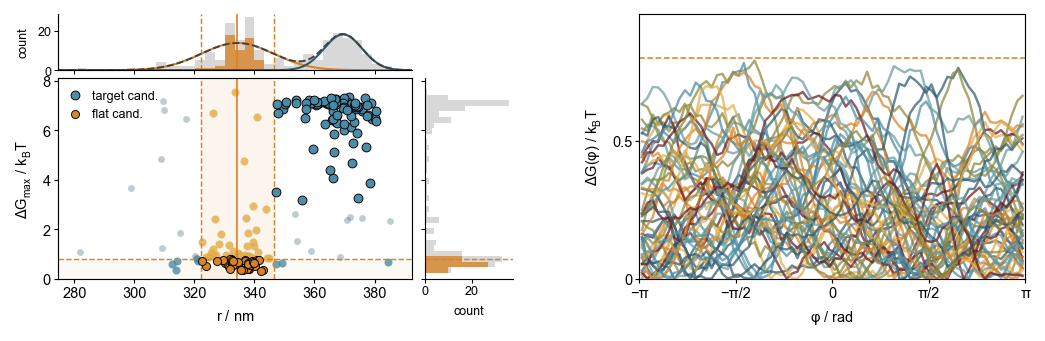

In [12]:
identify_calibration_target_rotors(
    m_list=m_list,
    radius_mu_nm=300.0,
    radius_sigma_nm=5.0,
    radius_n_sigma=1,
    threshold_kBT=0.8,
    min_diff_locs=100,
    min_umb_window_locs=20,
    nbins=72,
    smooth_bins=5,
    fig_width_mm=180,
    fig_height_mm=64,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig3a_voltage__identify_calibration_rotors",
    stator_variant=None,
    C=CK_colors,
    radius_selection_mode="gmm2",
    radius_filter_source="gmm",
    target_radius_n_sigma=4.0,
    target_min_dG_kBT=3.0,
    show_target_rotors=True,
)

#### ii. Filter calibration rotors based on umbrella measurements

In [124]:
def filter_calibration_rotors(
    m_list,
    calibration_voltage_colors,
    target_voltage_colors,
    selection_voltage=300,
    min_locs_per_window=20,
    min_valid_window_fraction=0.80,
    min_Rbar=0.55,
    min_kappa=0.50,
    max_kappa=25.0,
    max_kappa_std=3.0,
    max_kappa_cv=0.25,
    max_kappa_fold=1.80,
    max_center_error_deg=15.0,
    max_center_rmse_deg=12.0,
    max_center_error_range_deg=25.0,
    min_tracking_corr=0.97,
    min_tracking_slope=0.90,
    max_tracking_slope=1.10,
    max_cross_kappa_cv=None,
    max_cross_window_kappa_cv=None,
    max_cross_mu_rmse_deg=8.0,
    ensemble_center_mad=3.5,
    ensemble_kappa_mad=3.5,
    max_mean_abs_steering_error_deg=None,
    make_rawfigure=True,
    make_summaryfigure=True,
    max_raw_particles=12,
    raw_particle_sort='best',
    raw_hist_bins=90,
    rolling_mean_n=3,
    potential_psi_max=None,
    store_candidate_diagnostics=False,
    save_dir=None,
    raw_fig_name='SI_calibration_rotors_voltage_rawdata',
    summary_fig_name='SI_calibration_rotors_voltage_summary',
    stator_variant=None,
    raw_fig_width_mm=180,
    raw_panel_height_mm=25,
    summary_fig_width_mm=172,
    summary_fig_height_mm=100,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=6,
    box_point_size=10,
    box_point_alpha=0.35,
    box_width_voltage=18.0,
    box_jitter_voltage=2.0,
    box_face_alpha=0.24,
    max_points_per_box=None,
    random_seed=1,
    summary_panel_labels=('a', 'b', 'c', 'd', 'e', 'f'),
    summary_panel_label_fontsize=10,
    summary_panel_label_fontfamily='Arial',
    summary_panel_label_fontweight='bold',
    summary_panel_label_x_rel=-0.18,
    summary_panel_label_y_rel=0.05,
    C=CK_colors,
):
    """
    Fast, lightweight calibration-rotor selection using the former
    ``standard`` criteria.

    Raw figure changes
    ------------------
    - Row annotations are shown as "rotor i", "rotor ii", ... instead of the
      true particle IDs.

    Summary figure changes
    ----------------------
    - Panel labels a, b, c, ... are added in Arial, bold, with controllable
      relative x-offset via ``summary_panel_label_x_rel``.
    - Y-axis labels use indexed symbols: Δφ_i, κ_i, <φ_i>, <|Δφ_i|>, <κ_i>.
    - Voltage tick labels are rendered as integers (e.g. 200, 250, 300).
    """
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path

    if C is None:
        raise ValueError('Pass C=CK_colors.')
    if potential_psi_max is None:
        potential_psi_max = np.pi / 2
    if not isinstance(calibration_voltage_colors, dict) or not calibration_voltage_colors:
        raise ValueError('calibration_voltage_colors must be a non-empty dictionary.')
    if not isinstance(target_voltage_colors, dict) or not target_voltage_colors:
        raise ValueError('target_voltage_colors must be a non-empty dictionary.')

    selection_voltage = int(round(selection_voltage))
    min_locs_per_window = int(np.ceil(min_locs_per_window))
    min_valid_window_fraction = float(min_valid_window_fraction)
    rolling_mean_n = max(1, int(rolling_mean_n))
    command_shift_rad = np.deg2rad(-90)
    rng = np.random.default_rng(int(random_seed))

    def mm(x):
        return float(x) / 25.4

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def finite(x):
        x = np.asarray(x, dtype=float)
        return x[np.isfinite(x)]

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [item for sub in x for item in flatten(sub)]
        return [x]

    def m_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f'm_list[{i}]' if i is not None else 'unknown'

    def parse_voltage(m):
        text = str(getattr(m, 'path', m_name(m)))
        matches = re.findall(r'(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])', text, flags=re.IGNORECASE)
        return int(round(float(matches[-1]))) if matches else None

    def is_umb(m):
        text = str(getattr(m, 'path', m_name(m))).upper()
        return 'UMB' in text and 'DIFF' not in text and hasattr(m, 'protocol')

    def ensure_columns(m):
        if not hasattr(m, 'locs') or m.locs is None:
            raise ValueError(f'{m_name(m)} has no m.locs.')
        if 'group_int' not in m.locs.columns:
            if 'group' not in m.locs.columns:
                raise ValueError(f"{m_name(m)}: m.locs requires 'group'.")
            m.locs['group_int'] = m.locs['group'].astype(int)
        if 't' not in m.locs.columns:
            if 'averagetime' in m.locs.columns:
                m.locs['t'] = m.locs['averagetime'].astype(float)
            elif 'time' in m.locs.columns:
                m.locs['t'] = m.locs['time'].astype(float)
            elif 'time_s' in m.locs.columns:
                m.locs['t'] = m.locs['time_s'].astype(float)
            elif hasattr(m, '_average_tpf'):
                m.locs['t'] = m.locs['frame'].astype(float) * float(m._average_tpf)
            elif hasattr(m, 'average_tpf'):
                m.locs['t'] = m.locs['frame'].astype(float) * float(m.average_tpf)
            elif hasattr(m, 'fps'):
                m.locs['t'] = m.locs['frame'].astype(float) / float(m.fps)
            else:
                raise ValueError(f'{m_name(m)} needs time information.')
        if 'phi' not in m.locs.columns:
            raise ValueError(f"{m_name(m)}: m.locs requires 'phi'.")

    def phase_angle_deg(key):
        text = str(key).lower()
        if any(word in text for word in ['diff', 'umbrella', 'all', 'drift', 'dark', 'pause']):
            return np.nan
        patterns = [r'^deg[-_]?(-?\d+(?:\.\d+)?)$', r'(-?\d+(?:\.\d+)?)\s*deg', r'pos[-_]?(-?\d+(?:\.\d+)?)', r'angle[-_]?(-?\d+(?:\.\d+)?)', r'phi[-_]?(-?\d+(?:\.\d+)?)', r'cmd[-_]?(-?\d+(?:\.\d+)?)']
        for pattern in patterns:
            match = re.search(pattern, text)
            if match:
                return float(match.group(1)) % 360
        return np.nan

    def phase_bounds(m, phase):
        value = m.protocol[phase]
        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict)):
            value = value[0]
        if isinstance(value, dict):
            t0 = next((value[k] for k in ['start', 'start_time', 't_start', 'begin'] if k in value), None)
            t1 = next((value[k] for k in ['end', 'end_time', 't_end', 'stop'] if k in value), None)
            if t0 is None or t1 is None:
                raise ValueError(f'Cannot parse protocol entry {phase}: {value}')
            return float(t0), float(t1)
        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])
        raise ValueError(f'Cannot parse protocol entry {phase}: {value}')

    def deg_phases(m):
        phases = []
        for phase in m.protocol:
            angle = phase_angle_deg(phase)
            if not np.isfinite(angle):
                continue
            t0, t1 = phase_bounds(m, phase)
            phases.append((t0, t1, angle, phase))
        return [phase for _, _, _, phase in sorted(phases, key=lambda x: (x[0], x[1]))]

    def circ_mean(phi):
        phi = finite(phi)
        return float(np.angle(np.mean(np.exp(1j * phi)))) if len(phi) else np.nan

    def resultant_length(phi):
        phi = finite(phi)
        return float(np.abs(np.mean(np.exp(1j * phi)))) if len(phi) else np.nan

    def circ_std(phi):
        R = resultant_length(phi)
        return float(np.sqrt(-2 * np.log(R))) if np.isfinite(R) and 0 < R <= 1 else np.nan

    def kappa_from_R(R, n=None):
        if not np.isfinite(R) or R <= 0:
            return np.nan
        R = min(float(R), 0.999999)
        if R < 0.53:
            kappa = 2 * R + R ** 3 + 5 * R ** 5 / 6
        elif R < 0.85:
            kappa = -0.4 + 1.39 * R + 0.43 / (1 - R)
        else:
            kappa = 1 / (R ** 3 - 4 * R ** 2 + 3 * R)
        if n is not None and 0 < n < 15:
            if 0 < kappa < 2:
                kappa = max(kappa - 2 / (n * kappa), 0)
            elif kappa >= 2:
                kappa = (n - 1) ** 3 * kappa / (n ** 3 + n)
            else:
                return np.nan
        return float(kappa) if np.isfinite(kappa) else np.nan

    def vonmises_pdf(x, mu, kappa):
        x = np.asarray(x, dtype=float)
        if not np.isfinite(mu) or not np.isfinite(kappa) or kappa <= 0:
            return np.full_like(x, np.nan)
        return np.exp(kappa * np.cos(wrap_pi(x - mu))) / (2 * np.pi * np.i0(kappa))

    def periodic_rolling_mean(y, n):
        y = np.asarray(y, dtype=float)
        if n <= 1:
            return y.copy()
        out = np.full_like(y, np.nan)
        left, right = n // 2, n - n // 2 - 1
        for i in range(len(y)):
            idx = [(i + j) % len(y) for j in range(-left, right + 1)]
            vals = finite(y[idx])
            if len(vals):
                out[i] = np.nanmean(vals)
        return out

    def robust_mad_z(x):
        x = np.asarray(x, dtype=float)
        median = np.nanmedian(x)
        mad = np.nanmedian(np.abs(x - median))
        if not np.isfinite(mad) or mad <= 0:
            return np.zeros_like(x)
        return 0.6745 * (x - median) / mad

    def get_radius(m, particle):
        data = getattr(m, 'particle_data', None)
        try:
            if hasattr(data, 'loc'):
                if particle in data.index and 'R' in data.columns:
                    return float(data.loc[particle, 'R'])
                if 'group' in data.columns and 'R' in data.columns:
                    row = data[data['group'].astype(int) == int(particle)]
                    return float(row.iloc[0]['R']) if len(row) else np.nan
            if isinstance(data, dict):
                if 'R' in data:
                    return float(data['R'][particle])
                if particle in data and isinstance(data[particle], dict):
                    return float(data[particle].get('R', np.nan))
        except Exception:
            pass
        return np.nan

    def measurement_color(voltage):
        return calibration_voltage_colors.get(int(voltage), C['grey'])

    def blend(c1, c2, t):
        c1 = np.asarray(c1[:3], dtype=float)
        c2 = np.asarray(c2[:3], dtype=float)
        return tuple((1.0 - float(t)) * c1 + float(t) * c2)

    def window_colors(n):
        anchors = np.array([C['darkblue'], C['lightblue'], C['palecyan'], C['olive'], C['gold'], C['orange'], C['darkred'], C['gold'], C['olive'], C['palecyan'], C['lightblue'], C['darkblue']], dtype=float)
        if n <= 1:
            return np.array([C['darkblue']], dtype=float)
        x0, x = np.linspace(0, 1, len(anchors)), np.linspace(0, 1, n)
        return np.column_stack([np.interp(x, x0, anchors[:, i]) for i in range(3)])

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.55)
            spine.set_color(C['black'])
        ax.tick_params(width=0.55, length=2.2, labelsize=tick_label_size, color=C['black'], labelcolor=C['black'], pad=1.4)

    def set_pi_ticks(ax, half=False):
        if half:
            ax.set_xlim(-np.pi / 2, np.pi / 2)
            ax.set_xticks([-np.pi / 2, 0, np.pi / 2])
            ax.set_xticklabels(['$-\\mathrm{\\pi}/2$', '0', '$\\mathrm{\\pi}/2$'])
        else:
            ax.set_xlim(-np.pi, np.pi)
            ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
            ax.set_xticklabels(['$-\\mathrm{\\pi}$', '$-\\mathrm{\\pi}/2$', '0', '$\\mathrm{\\pi}/2$', '$\\mathrm{\\pi}$'])

    def to_roman(n):
        values = [(1000, 'm'), (900, 'cm'), (500, 'd'), (400, 'cd'), (100, 'c'), (90, 'xc'), (50, 'l'), (40, 'xl'), (10, 'x'), (9, 'ix'), (5, 'v'), (4, 'iv'), (1, 'i')]
        n = int(n)
        if n <= 0:
            return str(n)
        out = []
        for v, sym in values:
            while n >= v:
                out.append(sym)
                n -= v
        return ''.join(out)

    def fmt_voltage(v):
        return f'{int(round(float(v)))}' if np.isfinite(v) else ''

    def expand_values(x, n):
        if np.isscalar(x):
            return [float(x)] * n
        vals = list(x)
        if len(vals) == n:
            return [float(v) for v in vals]
        if len(vals) == 1:
            return [float(vals[0])] * n
        raise ValueError(f'Expected scalar or length-{n} value, got {len(vals)}.')

    # def add_summary_panel_labels(fig, axes, labels, x_rel=-0.18, y_rel=0.05, fontsize=10, fontfamily='Arial', fontweight='bold'):
    #     axes = list(axes)
    #     n = len(axes)
    #     labels = [str(v) for v in (list(labels) if labels is not None else [chr(97 + i) for i in range(n)])]
    #     if len(labels) < n:
    #         labels = labels + [chr(97 + i) for i in range(len(labels), n)]
    #     x_rel = expand_values(x_rel, n)
    #     y_rel = expand_values(y_rel, 2 if n >= 2 else 1)
    #     fig.canvas.draw_idle()
    #     positions = [ax.get_position() for ax in axes]
    #     top_row = positions[:3]
    #     bottom_row = positions[3:6] if n >= 6 else positions[3:]
    #     row_specs = []
    #     if top_row:
    #         row_specs.append((0, len(top_row), max(p.y1 for p in top_row) + y_rel[0] * np.mean([p.height for p in top_row])))
    #     if bottom_row:
    #         row_specs.append((3, 3 + len(bottom_row), max(p.y1 for p in bottom_row) + y_rel[min(1, len(y_rel) - 1)] * np.mean([p.height for p in bottom_row])))
    #     for start, stop, y in row_specs:
    #         for i in range(start, min(stop, n)):
    #             p = positions[i]
    #             fig.text(p.x0 + x_rel[i] * p.width, y, labels[i], ha='left', va='bottom', fontsize=fontsize, fontfamily=fontfamily, fontweight=fontweight, color='black')
    def add_summary_panel_labels(fig, axes, labels, x_rel=-0.18, y_rel=0.05, fontsize=10, fontfamily='Arial', fontweight='bold'):
        if labels is None:
            return
    
        axes = list(axes)
        n = len(axes)
        labels = [str(v) for v in labels]
    
        if len(labels) < n:
            labels = labels + [chr(97 + i) for i in range(len(labels), n)]
    
        x_rel = expand_values(x_rel, n)
        y_rel = expand_values(y_rel, 2 if n >= 2 else 1)
        fig.canvas.draw_idle()
    
        positions = [ax.get_position() for ax in axes]
        top_row = positions[:3]
        bottom_row = positions[3:6] if n >= 6 else positions[3:]
    
        row_specs = []
    
        if top_row:
            y_top = max(p.y1 for p in top_row) + y_rel[0] * np.mean([p.height for p in top_row])
            row_specs.append((0, len(top_row), y_top))
    
        if bottom_row:
            y_bottom = max(p.y1 for p in bottom_row) + y_rel[min(1, len(y_rel) - 1)] * np.mean([p.height for p in bottom_row])
            row_specs.append((3, 3 + len(bottom_row), y_bottom))
    
        for start, stop, y in row_specs:
            for i in range(start, min(stop, n)):
                p = positions[i]
                fig.text(p.x0 + x_rel[i] * p.width, y, labels[i], ha='left', va='bottom', fontsize=fontsize, fontfamily=fontfamily, fontweight=fontweight, color='black')

    def build_measurement_cache(m, particles):
        ensure_columns(m)
        phases = deg_phases(m)
        voltage = parse_voltage(m)
        phase_rows = []
        for window_index, phase in enumerate(phases):
            t0, t1 = phase_bounds(m, phase)
            angle = (phase_angle_deg(phase) + 180) % 360 - 180
            phase_rows.append({'window_index': int(window_index), 'phase': str(phase), 't0': float(t0), 't1': float(t1), 'deg_display': float(angle), 'phi_cmd_rad': float(wrap_pi(np.deg2rad(angle)))})
        phase_df = pd.DataFrame(phase_rows)
        particle_array = np.asarray(sorted({int(p) for p in particles}), dtype=int)
        groups = m.locs['group_int'].to_numpy(dtype=int, copy=False)
        times = m.locs['t'].to_numpy(dtype=float, copy=False)
        phi_all = m.locs['phi'].to_numpy(dtype=float, copy=False)
        keep = np.isin(groups, particle_array) & np.isfinite(times) & np.isfinite(phi_all)
        groups, times, phi_all = groups[keep], times[keep], wrap_pi(phi_all[keep])
        window_index = np.full(len(times), -1, dtype=np.int16)
        for row in phase_rows:
            window_index[(times >= row['t0']) & (times < row['t1'])] = int(row['window_index'])
        keep = window_index >= 0
        compact = pd.DataFrame({'particle': groups[keep].astype(np.int32, copy=False), 'window_index': window_index[keep].astype(np.int16, copy=False), 'phi': phi_all[keep].astype(np.float32, copy=False)})
        return {'m': m, 'voltage': int(voltage), 'phases': phases, 'phase_df': phase_df, 'compact': compact}

    def build_window_dataframe_from_caches(caches, particles):
        particles = np.asarray(sorted({int(p) for p in particles}), dtype=int)
        rows = []
        for measurement_index, cache in enumerate(caches):
            compact, phase_df, n_windows = cache['compact'], cache['phase_df'], len(cache['phase_df'])
            if len(compact):
                work = compact.copy()
                phi = work['phi'].to_numpy(dtype=float, copy=False)
                work['cos_phi'], work['sin_phi'] = np.cos(phi), np.sin(phi)
                grouped = work.groupby(['particle', 'window_index'], sort=False, observed=True).agg(n_locs=('phi', 'size'), sum_cos=('cos_phi', 'sum'), sum_sin=('sin_phi', 'sum'))
            else:
                grouped = pd.DataFrame(columns=['n_locs', 'sum_cos', 'sum_sin'])
                grouped.index = pd.MultiIndex.from_arrays([[], []], names=['particle', 'window_index'])
            full_index = pd.MultiIndex.from_product([particles, np.arange(n_windows, dtype=int)], names=['particle', 'window_index'])
            grouped = grouped.reindex(full_index, fill_value=0).reset_index()
            n_locs = grouped['n_locs'].to_numpy(dtype=int)
            sum_cos, sum_sin = grouped['sum_cos'].to_numpy(dtype=float), grouped['sum_sin'].to_numpy(dtype=float)
            mu_fit, Rbar = np.full(len(grouped), np.nan), np.full(len(grouped), np.nan)
            valid_n = n_locs >= int(min_locs_per_window)
            mu_fit[valid_n] = np.arctan2(sum_sin[valid_n], sum_cos[valid_n])
            Rbar[valid_n] = np.sqrt(sum_cos[valid_n] ** 2 + sum_sin[valid_n] ** 2) / n_locs[valid_n]
            kappa = np.full(len(grouped), np.nan)
            valid_R = valid_n & np.isfinite(Rbar) & (Rbar > 0)
            kappa[valid_R] = np.fromiter((kappa_from_R(r, n=int(n)) for r, n in zip(Rbar[valid_R], n_locs[valid_R])), dtype=float, count=int(np.sum(valid_R)))
            mu_display = wrap_pi(mu_fit - command_shift_rad)
            phase_lookup = phase_df.set_index('window_index')
            phi_cmd = grouped['window_index'].map(phase_lookup['phi_cmd_rad']).to_numpy(dtype=float)
            deg_display = grouped['window_index'].map(phase_lookup['deg_display']).to_numpy(dtype=float)
            phase_name = grouped['window_index'].map(phase_lookup['phase']).astype(str).to_numpy()
            center_error = np.rad2deg(wrap_pi(mu_display - phi_cmd))
            center_error[~valid_n] = np.nan
            radius_map = {int(p): get_radius(cache['m'], int(p)) for p in particles}
            r_nm = grouped['particle'].map(radius_map).to_numpy(dtype=float)
            window_ok = valid_n & np.isfinite(Rbar) & (Rbar >= float(min_Rbar)) & np.isfinite(kappa) & (kappa >= float(min_kappa)) & (kappa <= float(max_kappa)) & np.isfinite(center_error) & (np.abs(center_error) <= float(max_center_error_deg))
            rows.append(pd.DataFrame({'measurement_index': int(measurement_index), 'measurement_name': m_name(cache['m']), 'voltage': int(cache['voltage']), 'voltage_label': f"{int(cache['voltage'])}", 'particle': grouped['particle'].to_numpy(dtype=int), 'phase': phase_name, 'window_index': grouped['window_index'].to_numpy(dtype=int), 'n_windows': int(n_windows), 'deg_display': deg_display, 'phi_cmd_rad': phi_cmd, 'r_nm': r_nm, 'n_locs': n_locs, 'mu_fit_rad': mu_fit, 'mu_display_rad': mu_display, 'Rbar': Rbar, 'kappa': kappa, 'center_error_deg': center_error, 'abs_center_error_deg': np.abs(center_error), 'window_ok': window_ok}))
        return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

    def cached_phi(cache, particle, window_index):
        compact = cache['compact']
        if len(compact) == 0:
            return np.array([], dtype=float)
        mask = (compact['particle'].to_numpy(dtype=int, copy=False) == int(particle)) & (compact['window_index'].to_numpy(dtype=int, copy=False) == int(window_index))
        return compact.loc[mask, 'phi'].to_numpy(dtype=float, copy=False)

    def make_particle_summary(df):
        rows = []
        group_columns = ['measurement_index', 'measurement_name', 'voltage', 'voltage_label', 'particle']
        for keys, group in df.groupby(group_columns, sort=True, observed=True):
            measurement_index, measurement_name, voltage, voltage_label, particle = keys
            valid = group[np.isfinite(group['kappa']) & np.isfinite(group['center_error_deg']) & np.isfinite(group['mu_display_rad'])].copy()
            kappa = valid['kappa'].to_numpy(float)
            errors = valid['center_error_deg'].to_numpy(float)
            x, y = valid['phi_cmd_rad'].to_numpy(float), valid['mu_display_rad'].to_numpy(float)
            kappa_mean = float(np.nanmean(kappa)) if len(kappa) else np.nan
            kappa_std = float(np.nanstd(kappa, ddof=1)) if len(kappa) > 1 else 0.0
            kappa_cv = kappa_std / kappa_mean if np.isfinite(kappa_mean) and kappa_mean > 0 else np.nan
            kappa_median = float(np.nanmedian(kappa)) if len(kappa) else np.nan
            kappa_fold = float(np.nanmax(np.maximum(kappa / kappa_median, kappa_median / kappa))) if len(kappa) and np.isfinite(kappa_median) and (kappa_median > 0) else np.nan
            tracking_corr, tracking_slope = np.nan, np.nan
            if len(valid) >= 4:
                order = np.argsort(x)
                xu, yu = np.unwrap(x[order]), np.unwrap(y[order])
                yu -= 2 * np.pi * np.round(np.nanmedian(yu - xu) / (2 * np.pi))
                if np.nanstd(xu) > 0 and np.nanstd(yu) > 0:
                    tracking_corr = float(np.corrcoef(xu, yu)[0, 1])
                try:
                    tracking_slope = float(np.polyfit(xu, yu, 1)[0])
                except Exception:
                    pass
            n_windows, n_valid, n_ok = int(len(group)), int(len(valid)), int(np.sum(group['window_ok'].to_numpy(bool)))
            center_rmse = float(np.sqrt(np.nanmean(errors ** 2))) if len(errors) else np.nan
            passes_measurement = n_windows > 0 and n_valid / n_windows >= float(min_valid_window_fraction) and n_ok / n_windows >= float(min_valid_window_fraction) and np.isfinite(kappa_mean) and float(min_kappa) <= kappa_mean <= float(max_kappa) and np.isfinite(kappa_std) and kappa_std <= float(max_kappa_std) and np.isfinite(kappa_cv) and kappa_cv <= float(max_kappa_cv) and np.isfinite(kappa_fold) and kappa_fold <= float(max_kappa_fold) and np.isfinite(center_rmse) and center_rmse <= float(max_center_rmse_deg) and len(errors) > 0 and float(np.nanmax(np.abs(errors))) <= float(max_center_error_deg) and float(np.nanmax(errors) - np.nanmin(errors)) <= float(max_center_error_range_deg) and np.isfinite(tracking_corr) and tracking_corr >= float(min_tracking_corr) and np.isfinite(tracking_slope) and float(min_tracking_slope) <= tracking_slope <= float(max_tracking_slope) and len(valid) > 0 and float(np.nanmean(valid['Rbar'])) >= float(min_Rbar)
            mean_abs_error = float(np.nanmean(np.abs(errors))) if len(errors) else np.nan
            if max_mean_abs_steering_error_deg is not None:
                passes_measurement &= np.isfinite(mean_abs_error) and mean_abs_error <= float(max_mean_abs_steering_error_deg)
            rows.append({'measurement_index': int(measurement_index), 'measurement_name': str(measurement_name), 'voltage': int(voltage), 'voltage_label': str(voltage_label), 'particle': int(particle), 'r_nm': float(np.nanmedian(group['r_nm'].to_numpy(float))), 'n_windows': n_windows, 'n_valid_windows': n_valid, 'n_ok_windows': n_ok, 'valid_window_fraction': n_valid / n_windows if n_windows else 0.0, 'Rbar_mean': float(np.nanmean(valid['Rbar'])) if len(valid) else np.nan, 'kappa_mean': kappa_mean, 'kappa_std': kappa_std, 'kappa_cv': kappa_cv, 'kappa_fold': kappa_fold, 'mean_steering_error_deg': float(np.nanmean(errors)) if len(errors) else np.nan, 'mean_abs_steering_error_deg': mean_abs_error, 'center_error_rmse_deg': center_rmse, 'max_center_error_deg': float(np.nanmax(np.abs(errors))) if len(errors) else np.nan, 'center_error_range_deg': float(np.nanmax(errors) - np.nanmin(errors)) if len(errors) else np.nan, 'tracking_corr': tracking_corr, 'tracking_slope': tracking_slope, 'passes_measurement': bool(passes_measurement)})
        return pd.DataFrame(rows)

    def make_cross_voltage_summary(window_df, particle_summary, n_measurements):
        rows = []
        for particle, group in window_df.groupby('particle', sort=True, observed=True):
            particle = int(particle)
            pm = particle_summary[particle_summary['particle'].astype(int) == particle].copy()
            kappa_by_voltage = pm['kappa_mean'].to_numpy(float)
            kappa_by_voltage = kappa_by_voltage[np.isfinite(kappa_by_voltage) & (kappa_by_voltage > 0)]
            cross_kappa_cv = float(np.nanstd(kappa_by_voltage, ddof=1) / np.nanmean(kappa_by_voltage)) if len(kappa_by_voltage) >= 2 and np.nanmean(kappa_by_voltage) > 0 else (0.0 if len(kappa_by_voltage) == 1 else np.nan)
            cross_window_cvs, center_residuals_deg = [], []
            for _, window_group in group.groupby('phi_cmd_rad', sort=True, observed=True):
                kappa_window = window_group['kappa'].to_numpy(float)
                kappa_window = kappa_window[np.isfinite(kappa_window) & (kappa_window > 0)]
                if len(kappa_window) >= 2 and np.nanmean(kappa_window) > 0:
                    cross_window_cvs.append(float(np.nanstd(kappa_window, ddof=1) / np.nanmean(kappa_window)))
                mu = window_group['mu_display_rad'].to_numpy(float)
                mu = mu[np.isfinite(mu)]
                if len(mu) >= 2:
                    mu0 = circ_mean(mu)
                    center_residuals_deg.extend(np.rad2deg(wrap_pi(mu - mu0)).tolist())
            cross_window_kappa_cv = float(np.nanmedian(cross_window_cvs)) if cross_window_cvs else np.nan
            cross_mu_rmse = float(np.sqrt(np.nanmean(np.asarray(center_residuals_deg, dtype=float) ** 2))) if center_residuals_deg else np.nan
            all_measurements_pass = len(pm) == int(n_measurements) and bool(pm['passes_measurement'].all())
            cross_kappa_ok = True if max_cross_kappa_cv is None else (np.isfinite(cross_kappa_cv) and cross_kappa_cv <= float(max_cross_kappa_cv))
            cross_window_kappa_ok = True if max_cross_window_kappa_cv is None else (np.isfinite(cross_window_kappa_cv) and cross_window_kappa_cv <= float(max_cross_window_kappa_cv))
            cross_mu_ok = True if max_cross_mu_rmse_deg is None else (np.isfinite(cross_mu_rmse) and cross_mu_rmse <= float(max_cross_mu_rmse_deg))
            rows.append({'particle': particle, 'r_nm': float(np.nanmedian(group['r_nm'].to_numpy(float))), 'cross_kappa_cv': cross_kappa_cv, 'cross_window_kappa_cv': cross_window_kappa_cv, 'cross_mu_rmse_deg': cross_mu_rmse, 'n_measurements_passed': int(np.sum(pm['passes_measurement'].to_numpy(bool))), 'n_measurements_expected': int(n_measurements), 'pre_reliable': bool(all_measurements_pass and cross_kappa_ok and cross_window_kappa_ok and cross_mu_ok)})
        return pd.DataFrame(rows)

    def apply_ensemble_filter(window_df, cross_summary):
        out = cross_summary.copy()
        pre_particles = set(out.loc[out['pre_reliable'], 'particle'].astype(int))
        if len(pre_particles) < 5:
            out['is_reliable'] = out['pre_reliable'].astype(bool)
            return out
        bad_particles, subset = set(), window_df[window_df['particle'].astype(int).isin(pre_particles)].copy()
        for _, group in subset.groupby(['measurement_index', 'phi_cmd_rad'], sort=False, observed=True):
            center_z, kappa_z = robust_mad_z(group['center_error_deg'].to_numpy(float)), robust_mad_z(group['kappa'].to_numpy(float))
            for particle, zc, zk in zip(group['particle'].astype(int), center_z, kappa_z):
                if (np.isfinite(zc) and abs(zc) > float(ensemble_center_mad)) or (np.isfinite(zk) and abs(zk) > float(ensemble_kappa_mad)):
                    bad_particles.add(int(particle))
        out['is_reliable'] = out['pre_reliable'] & ~out['particle'].astype(int).isin(bad_particles)
        return out

    def make_voltage_summary(df):
        rows = []
        group_columns = ['measurement_index', 'measurement_name', 'voltage', 'voltage_label', 'window_index', 'phi_cmd_rad']
        for keys, group in df.groupby(group_columns, sort=True, observed=True):
            measurement_index, measurement_name, voltage, voltage_label, window_index, phi_cmd = keys
            kappa, errors, mu = finite(group['kappa']), finite(group['center_error_deg']), finite(group['mu_display_rad'])
            rows.append({'measurement_index': int(measurement_index), 'measurement_name': str(measurement_name), 'voltage': int(voltage), 'voltage_label': str(voltage_label), 'window_index': int(window_index), 'phi_cmd_rad': float(phi_cmd), 'kappa_mean': float(np.nanmean(kappa)) if len(kappa) else np.nan, 'kappa_std': float(np.nanstd(kappa, ddof=1)) if len(kappa) > 1 else np.nan, 'center_error_mean_deg': float(np.nanmean(errors)) if len(errors) else np.nan, 'center_error_std_deg': float(np.nanstd(errors, ddof=1)) if len(errors) > 1 else np.nan, 'mu_mean_rad': circ_mean(mu), 'mu_std_rad': circ_std(mu)})
        if not rows:
            cols = ['measurement_index', 'measurement_name', 'voltage', 'voltage_label', 'window_index', 'phi_cmd_rad', 'kappa_mean', 'kappa_std', 'center_error_mean_deg', 'center_error_std_deg', 'mu_mean_rad', 'mu_std_rad', 'kappa_roll']
            return pd.DataFrame(columns=cols)
        out = pd.DataFrame(rows).sort_values(['measurement_index', 'window_index']).reset_index(drop=True)
        out['kappa_roll'] = np.nan
        for _, indices in out.groupby('measurement_index').groups.items():
            indices = list(indices)
            out.loc[indices, 'kappa_roll'] = periodic_rolling_mean(out.loc[indices, 'kappa_mean'].to_numpy(float), rolling_mean_n)
        return out[['measurement_index', 'measurement_name', 'voltage', 'voltage_label', 'window_index', 'phi_cmd_rad', 'kappa_mean', 'kappa_std', 'center_error_mean_deg', 'center_error_std_deg', 'mu_mean_rad', 'mu_std_rad', 'kappa_roll']]

    def add_voltage_boxplot(ax, particles_df, voltage_ticks, column):
        fit_darkgrey = C.get('fit_darkgrey', (46 / 255, 46 / 255, 46 / 255))
        box_data, box_positions, box_colors = [], [], []
        for voltage in voltage_ticks:
            color = measurement_color(voltage)
            values = particles_df.loc[particles_df['voltage'].astype(int) == int(voltage), column].to_numpy(float)
            values = values[np.isfinite(values)]
            values_scatter = values[rng.choice(len(values), size=int(max_points_per_box), replace=False)] if max_points_per_box is not None and len(values) > int(max_points_per_box) else values
            if len(values_scatter):
                jitter = np.clip(rng.normal(0.0, float(box_jitter_voltage), size=len(values_scatter)), -2.0 * float(box_jitter_voltage), 2.0 * float(box_jitter_voltage))
                ax.scatter(np.full(len(values_scatter), float(voltage)) + jitter, values_scatter, s=float(box_point_size), facecolor=color, edgecolor=blend(color, fit_darkgrey, 0.18), linewidth=0.18, alpha=float(box_point_alpha), rasterized=True, zorder=2)
            box_data.append(values)
            box_positions.append(float(voltage))
            box_colors.append(color)
        if any(len(v) for v in box_data):
            bp = ax.boxplot(box_data, positions=box_positions, widths=float(box_width_voltage), patch_artist=True, showfliers=False, whis=(5, 95), zorder=4)
            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor((*color[:3], float(box_face_alpha)))
                patch.set_edgecolor(blend(color, fit_darkgrey, 0.14))
                patch.set_linewidth(0.85)
            expanded = [color for color in box_colors for _ in range(2)]
            for whisker, color in zip(bp['whiskers'], expanded):
                whisker.set_color(blend(color, fit_darkgrey, 0.14))
                whisker.set_linewidth(0.75)
            for cap, color in zip(bp['caps'], expanded):
                cap.set_color(blend(color, fit_darkgrey, 0.14))
                cap.set_linewidth(0.75)
            for median in bp['medians']:
                median.set_color(fit_darkgrey)
                median.set_linewidth(1.15)

    all_measurements = flatten(m_list)
    all_umb = [m for m in all_measurements if is_umb(m) and len(deg_phases(m))]
    if not all_umb:
        raise ValueError('No valid UMB measurements found.')
    by_voltage = {}
    for m in all_umb:
        voltage = parse_voltage(m)
        if voltage is not None:
            by_voltage.setdefault(voltage, []).append(m)
    for voltage in by_voltage:
        by_voltage[voltage] = sorted(by_voltage[voltage], key=m_name)
    if selection_voltage not in by_voltage:
        raise ValueError(f'No {selection_voltage} V UMB found. Available UMB voltages: {sorted(by_voltage)}')

    selection_candidates = [m for m in by_voltage[selection_voltage] if len(getattr(m, 'flat_rotors', []))]
    if not selection_candidates:
        names = '\n'.join(f'  {m_name(m)}' for m in by_voltage[selection_voltage])
        raise ValueError(f'No {selection_voltage} V UMB contains a non-empty m.flat_rotors.\nAvailable runs:\n{names}')

    selection_m = selection_candidates[0]
    comparison_measurements = [selection_m if voltage == selection_voltage else by_voltage[voltage][0] for voltage in sorted(by_voltage)]
    candidates = sorted({int(p) for p in getattr(selection_m, 'flat_rotors', [])})
    caches = [build_measurement_cache(m, candidates) for m in comparison_measurements]
    calibration_df = build_window_dataframe_from_caches(caches, candidates)
    particle_summary = make_particle_summary(calibration_df)
    cross_summary = make_cross_voltage_summary(calibration_df, particle_summary, len(comparison_measurements))
    cross_summary = apply_ensemble_filter(calibration_df, cross_summary)
    calibration_rotors = sorted(cross_summary.loc[cross_summary['is_reliable'], 'particle'].astype(int))
    calibration_set = set(calibration_rotors)

    calibration_df['is_reliable'] = calibration_df['particle'].astype(int).isin(calibration_set)
    particle_summary['is_reliable'] = particle_summary['particle'].astype(int).isin(calibration_set)
    selection_summary = particle_summary[particle_summary['measurement_index'] == comparison_measurements.index(selection_m)].copy()
    selection_summary = selection_summary.merge(cross_summary[['particle', 'cross_kappa_cv', 'cross_window_kappa_cv', 'cross_mu_rmse_deg', 'pre_reliable', 'is_reliable']], on='particle', how='left', suffixes=('', '_cross'))
    selection_summary['is_reliable'] = selection_summary['particle'].astype(int).isin(calibration_set)
    reliable_df = calibration_df[calibration_df['is_reliable']].copy()
    reliable_particle_summary = particle_summary[particle_summary['is_reliable']].copy()
    voltage_summary = make_voltage_summary(reliable_df)

    if len(calibration_rotors) == 0:
        print('WARNING: no calibration rotor passed the full old-standard criteria.')
        print('The function will still store empty result tables and can generate the raw candidate gallery.')

    for measurement_index, m in enumerate(comparison_measurements):
        present = set(m.locs['group_int'].astype(int).unique())
        selected_here = sorted(calibration_set & present)
        m.calibration_rotors = selected_here
        m.kappa_calibration_by_window = reliable_df[reliable_df['measurement_index'] == measurement_index].reset_index(drop=True).copy()
        m.kappa_calibration_particle_summary = reliable_particle_summary[reliable_particle_summary['measurement_index'] == measurement_index].reset_index(drop=True).copy()
        m.kappa_calibration_voltage_summary = voltage_summary.copy()
        m.calibration_voltage_colors = dict(calibration_voltage_colors)
        m.target_voltage_colors = dict(target_voltage_colors)

    if store_candidate_diagnostics:
        selection_m.calibration_candidate_window_diagnostics = calibration_df.reset_index(drop=True).copy()
        selection_m.calibration_candidate_particle_diagnostics = particle_summary.reset_index(drop=True).copy()
        selection_m.calibration_candidate_cross_voltage_diagnostics = cross_summary.reset_index(drop=True).copy()

    for m in all_measurements:
        if not hasattr(m, 'locs') or m.locs is None:
            continue
        if 'group_int' in m.locs.columns:
            present = set(m.locs['group_int'].astype(int).unique())
        elif 'group' in m.locs.columns:
            present = set(m.locs['group'].astype(int).unique())
        else:
            continue
        m.calibration_rotors = sorted(calibration_set & present)
        m.calibration_voltage_colors = dict(calibration_voltage_colors)
        m.target_voltage_colors = dict(target_voltage_colors)

    print(f'selection UMB: {selection_voltage} V')
    print(f'  {m_name(selection_m)}')
    print(f'candidate m.flat_rotors from selected UMB: n = {len(candidates)}')
    print(f'm.calibration_rotors: n = {len(calibration_rotors)}: {calibration_rotors}')
    print('standard criteria evaluated across all comparison voltages:')
    for index, m in enumerate(comparison_measurements):
        marker = '  <- candidate source' if m is selection_m else ''
        print(f'  {index:02d} | {parse_voltage(m)} V | {m_name(m)}{marker}')

    plt.rcParams.update({'font.size': fontsize, 'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'], 'mathtext.fontset': 'custom', 'mathtext.rm': 'Arial', 'mathtext.it': 'Arial:italic', 'mathtext.bf': 'Arial:bold', 'axes.linewidth': 0.55, 'axes.labelsize': axis_label_size, 'xtick.labelsize': tick_label_size, 'ytick.labelsize': tick_label_size, 'svg.fonttype': 'none', 'pdf.fonttype': 42, 'ps.fonttype': 42})
    prefix = f'{stator_variant}__' if stator_variant is not None and str(stator_variant).strip() else ''

    if make_rawfigure:
        if raw_particle_sort == 'best':
            order = selection_summary[selection_summary['particle'].isin(calibration_rotors)].sort_values(['mean_abs_steering_error_deg', 'kappa_cv', 'particle'])['particle'].astype(int).tolist()
        else:
            order = sorted(calibration_rotors)
        if not order:
            order = candidates.copy()
        if max_raw_particles is not None:
            order = order[:int(max_raw_particles)]
        nrows, ncols = max(1, len(order)), len(comparison_measurements)
        fig, axes = plt.subplots(nrows, ncols, figsize=(mm(max(raw_fig_width_mm, 48 * ncols)), mm(max(45, 18 + raw_panel_height_mm * nrows))), squeeze=False)
        bins, xfit = np.linspace(-np.pi, np.pi, raw_hist_bins + 1), np.linspace(-np.pi, np.pi, 1200)
        for row_index, particle in enumerate(order):
            rotor_label = f'rotor {to_roman(row_index + 1)}'
            for measurement_index, m in enumerate(comparison_measurements):
                ax = axes[row_index, measurement_index]
                cache, phases, colors = caches[measurement_index], caches[measurement_index]['phases'], window_colors(len(caches[measurement_index]['phases']))
                for window_index, (phase, color) in enumerate(zip(phases, colors)):
                    phi = cached_phi(cache, particle, window_index)
                    if len(phi) < min_locs_per_window:
                        continue
                    histogram, edges = np.histogram(phi, bins=bins, density=True)
                    centers = 0.5 * (edges[:-1] + edges[1:])
                    row = calibration_df[(calibration_df['measurement_index'] == measurement_index) & (calibration_df['particle'] == int(particle)) & (calibration_df['window_index'] == int(window_index))]
                    mu = float(row['mu_fit_rad'].iloc[0]) if len(row) else np.nan
                    kappa = float(row['kappa'].iloc[0]) if len(row) else np.nan
                    ax.plot(centers, histogram, color=color, lw=0.55, alpha=0.45)
                    if np.isfinite(mu) and np.isfinite(kappa):
                        ax.plot(xfit, vonmises_pdf(xfit, mu, kappa), color=color, lw=1.0, alpha=0.95)
                voltage = parse_voltage(m)
                if row_index == 0:
                    ax.set_title(f'{int(voltage)} V', color=C['black'], fontsize=axis_label_size)
                if measurement_index == 0:
                    ax.set_ylabel(f'{rotor_label}\ndensity', fontsize=axis_label_size)
                else:
                    ax.set_yticklabels([])
                if row_index == nrows - 1:
                    ax.set_xlabel('$\\mathrm{\\varphi}$ / rad', fontsize=axis_label_size)
                else:
                    ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
                set_pi_ticks(ax)
                style_axis(ax)
        fig.tight_layout()
        if save_dir is not None:
            save_path = Path(save_dir)
            save_path.mkdir(parents=True, exist_ok=True)
            fig.savefig(save_path / f'{prefix}{raw_fig_name}.png', dpi=300, bbox_inches='tight')
            fig.savefig(save_path / f'{prefix}{raw_fig_name}.svg', bbox_inches='tight')
        plt.show()
        plt.close(fig)

    if make_summaryfigure:
        fig, axes = plt.subplots(2, 3, figsize=(mm(summary_fig_width_mm), mm(summary_fig_height_mm)))
        axA, axB, axC, axD, axE, axF = axes.ravel()
        voltages = sorted(int(v) for v in voltage_summary['voltage'].dropna().unique()) if len(voltage_summary) else []
        for voltage in voltages:
            color = measurement_color(voltage)
            group = voltage_summary[voltage_summary['voltage'].astype(int) == int(voltage)].sort_values('phi_cmd_rad')
            x = group['phi_cmd_rad'].to_numpy(float)
            axA.errorbar(x, group['center_error_mean_deg'], yerr=group['center_error_std_deg'], fmt='o-', color=color, ecolor=color, lw=1.0, elinewidth=0.55, ms=2.6, capsize=1.3, label=f'{int(voltage)} V')
            axB.errorbar(x, group['kappa_mean'], yerr=group['kappa_std'], fmt='o', color=color, ecolor=color, lw=0, elinewidth=0.55, ms=2.6, capsize=1.3)
            axB.plot(x, group['kappa_roll'], '-', color=color, lw=1.2)
            axC.errorbar(x, group['mu_mean_rad'], yerr=group['mu_std_rad'], fmt='o-', color=color, ecolor=color, lw=1.0, elinewidth=0.55, ms=2.6, capsize=1.3)
        axA.axhline(0, color=C['grey'], lw=0.6, ls='--')
        axC.plot([-np.pi, np.pi], [-np.pi, np.pi], '--', color=C['grey'], lw=0.7)
        axA.set_ylabel('$\\Delta\\varphi_i$ / $^\\circ$', fontsize=axis_label_size)
        axB.set_ylabel('$\\kappa_i$ / $k_\\mathrm{B}T$ rad$^{-2}$', fontsize=axis_label_size)
        axC.set_ylabel('$\\langle\\varphi_i\\rangle$ / rad', fontsize=axis_label_size)
        for ax in [axA, axB, axC]:
            set_pi_ticks(ax)
            ax.set_xlabel('$\\varphi_\\mathrm{cmd}$ / rad', fontsize=axis_label_size)
            style_axis(ax)
        if voltages:
            leg = axA.legend(frameon=True, fontsize=tick_label_size, facecolor='white', framealpha=0.65)
            leg.get_frame().set_edgecolor('none')
            leg.get_frame().set_linewidth(0.0)

        reliable_particles = particle_summary[particle_summary['is_reliable']].copy()
        voltage_ticks = sorted(int(v) for v in reliable_particles['voltage'].dropna().unique()) if len(reliable_particles) else []
        add_voltage_boxplot(axD, reliable_particles, voltage_ticks, 'mean_abs_steering_error_deg')
        add_voltage_boxplot(axE, reliable_particles, voltage_ticks, 'kappa_mean')
        axD.set_ylabel('$\\langle|\\Delta\\varphi_i|\\rangle$ / $^\\circ$', fontsize=axis_label_size)
        axE.set_ylabel('$\\langle\\kappa_i\\rangle$ / $k_\\mathrm{B}T$ rad$^{-2}$', fontsize=axis_label_size)
        for ax in [axD, axE]:
            if voltage_ticks:
                ax.set_xticks(voltage_ticks)
                ax.set_xticklabels([fmt_voltage(v) for v in voltage_ticks])
            ax.set_xlabel('bias voltage / V', fontsize=axis_label_size)
            style_axis(ax)

        psi = np.linspace(-potential_psi_max, potential_psi_max, 500)
        for voltage in voltage_ticks:
            group = reliable_particles[reliable_particles['voltage'].astype(int) == int(voltage)]
            kappa = group['kappa_mean'].mean()
            if np.isfinite(kappa):
                axF.plot(psi, kappa * (1 - np.cos(psi)), color=measurement_color(voltage), lw=1.3, label=f'{int(voltage)} V')
        set_pi_ticks(axF, half=True)
        axF.set_xlabel('$\\psi$ / rad', fontsize=axis_label_size)
        axF.set_ylabel('$U$ / $k_\\mathrm{B}T$', fontsize=axis_label_size)
        if voltage_ticks:
            axF.legend(frameon=False, fontsize=tick_label_size)
        style_axis(axF)

        fig.tight_layout()
        add_summary_panel_labels(fig, [axA, axB, axC, axD, axE, axF], summary_panel_labels, x_rel=summary_panel_label_x_rel, y_rel=summary_panel_label_y_rel, fontsize=summary_panel_label_fontsize, fontfamily=summary_panel_label_fontfamily, fontweight=summary_panel_label_fontweight)
        if save_dir is not None:
            save_path = Path(save_dir)
            save_path.mkdir(parents=True, exist_ok=True)
            fig.savefig(save_path / f'{prefix}{summary_fig_name}.png', dpi=300, bbox_inches='tight')
            fig.savefig(save_path / f'{prefix}{summary_fig_name}.svg', bbox_inches='tight')
        plt.show()
        plt.close(fig)
    return None

selection UMB: 300 V
  260707-fov04_13_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5
candidate m.flat_rotors from selected UMB: n = 53
m.calibration_rotors: n = 30: [2, 18, 21, 28, 29, 32, 33, 43, 49, 61, 62, 68, 81, 84, 85, 89, 95, 100, 125, 139, 142, 144, 147, 168, 171, 173, 176, 179, 184, 212]
standard criteria evaluated across all comparison voltages:
  00 | 200 V | 260707-fov04_11_UMB_200V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5
  01 | 250 V | 260707-fov04_12_UMB_250V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5
  02 | 300 V | 260707-fov04_13_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5  <- candidate source


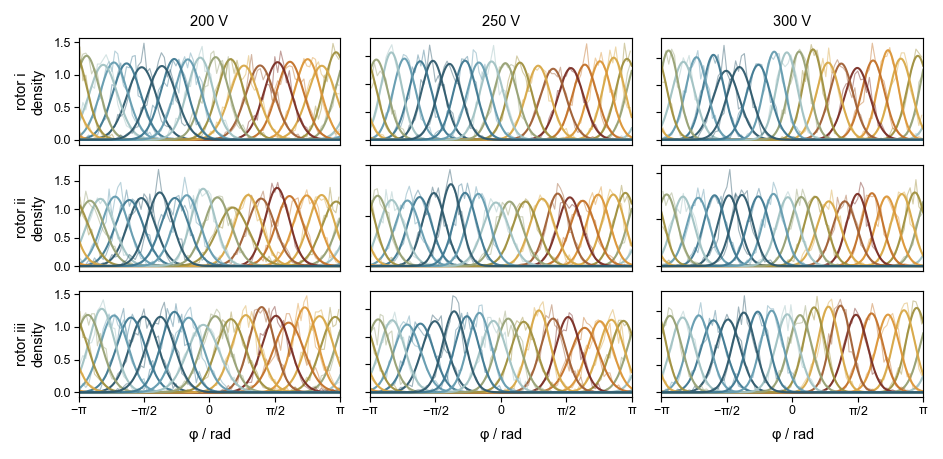

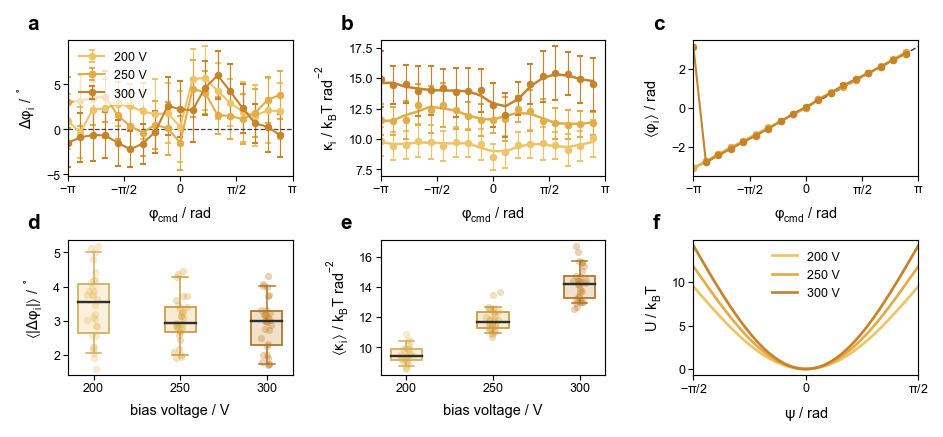

In [174]:
filter_calibration_rotors(
    m_list=m_list,
    calibration_voltage_colors=calibration_voltage_colors,
    target_voltage_colors=target_voltage_colors,
    selection_voltage=300,
    make_rawfigure=True,
    make_summaryfigure=True,
    raw_fig_width_mm=160,
    raw_panel_height_mm=20,
    summary_fig_width_mm=160,
    summary_fig_height_mm=70,

    max_raw_particles = 3,
    
    summary_panel_labels=('a', 'b', 'c', 'd', 'e', 'f'),
    summary_panel_label_x_rel=-0.18,
    summary_panel_label_y_rel=0.05,
    save_dir=save_dir_SI,
    stator_variant=stator_variant,
    raw_fig_name='SI_toFig3a_voltage__calibration_rotors__exemplary_rotors',
    summary_fig_name='SI_toFig3a_voltage__filter_calibration_rotors__ensemble_metrics',
    C=CK_colors,
)

## Estimate consensus trim time for umbrella windows with restraint potentials for target rotors

#### i. Check autocorrelation function per rotor / window

In [15]:
def calc_autocorrelation_times(
    m_list,
    include_diff=True,
    min_locs_for_tau=500,
    max_lag_s=1.0,
    f_trim=2.0,
):
    """
    Compute autocorrelation times for angular traces.

    Stored on each measurement:
        m.autocorrelation_df
        m.autocorrelation_trim_s

    The trim is measurement-specific:
        m.autocorrelation_trim_s = f_trim * q75(tau_s over UMB rows of this m)

    DIFF rows can be stored in m.autocorrelation_df, but DIFF is never used
    to determine m.autocorrelation_trim_s.
    """

    import re
    import numpy as np
    import pandas as pd
    from pathlib import Path

    particle_col = "group"
    phi_col = "phi"
    phi0_offset_rad = -np.pi / 2

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def parse_voltage(m):
        s = path_string(m)
        matches = re.findall(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])",
            s,
            flags=re.IGNORECASE,
        )
        if not matches:
            return np.nan
        return float(matches[-1])

    def voltage_label(v):
        if not np.isfinite(v):
            return "unknownV"
        if float(v).is_integer():
            return f"{int(v)}V"
        return f"{float(v):g}V"

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def as_int_list(x):
        if x is None:
            return []
        try:
            return sorted(set(int(v) for v in list(x)))
        except Exception:
            try:
                return [int(x)]
            except Exception:
                return []

    def ensure_group_int(m):
        if "group_int" not in m.locs.columns:
            if particle_col not in m.locs.columns:
                raise KeyError(f"{measurement_name(m)} needs m.locs['{particle_col}'].")
            m.locs["group_int"] = m.locs[particle_col].astype(int)

    def ensure_time_column(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError("m.locs is missing.")

        if "t" in m.locs.columns:
            return

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)
            return

        if "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)
            return

        if "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)
            return

        if "frame" in m.locs.columns and hasattr(m, "_average_tpf"):
            m.locs["t"] = m.locs["frame"].astype(float) * float(m._average_tpf)
            return

        if "frame" in m.locs.columns and hasattr(m, "fps"):
            m.locs["t"] = m.locs["frame"].astype(float) / float(m.fps)
            return

        raise ValueError("Need t, averagetime, time, time_s, or frame + _average_tpf/fps.")

    def infer_dt_default(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass

        if hasattr(m, "fps"):
            try:
                fps = float(getattr(m, "fps"))
                if np.isfinite(fps) and fps > 0:
                    return 1.0 / fps
            except Exception:
                pass

        return 0.005

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("t0", value.get("t_start", None)))
            t1 = value.get("end", value.get("t1", value.get("t_end", value.get("stop", None))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def acf_fft(x, max_lag):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]

        n = x.size

        if n < 4:
            return np.array([1.0]), np.array([0])

        x = x - np.mean(x)
        var = np.var(x)

        if not np.isfinite(var) or var <= 1e-30:
            return np.ones(1), np.array([0])

        nfft = 1 << (2 * n - 1).bit_length()
        fx = np.fft.fft(x, n=nfft)
        acf = np.fft.ifft(fx * np.conjugate(fx)).real[:n]
        acf = acf / (var * np.arange(n, 0, -1))
        acf = acf / acf[0]

        max_lag = int(min(max_lag, n - 1))
        lags = np.arange(max_lag + 1)

        return acf[: max_lag + 1], lags

    def tau_from_acf(acf, dt):
        acf = np.asarray(acf, dtype=float)

        if acf.size < 2:
            return float(dt), 1.0

        rho = acf[1:].copy()
        rho = rho[np.isfinite(rho)]

        if rho.size == 0:
            g = 1.0
        else:
            first_non_positive = np.where(rho <= 0)[0]
            if first_non_positive.size:
                rho = rho[: first_non_positive[0]]

            rho = rho[np.isfinite(rho)]

            if rho.size == 0:
                g = 1.0
            else:
                g = 1.0 + 2.0 * np.sum(rho)

        g = float(max(g, 1.0))
        tau_s = float(0.5 * g * dt)

        return tau_s, g

    def get_particle_radius_dict(m):
        radius = {}
        pdata = getattr(m, "particle_data", None)

        if pdata is None:
            return radius

        if isinstance(pdata, pd.DataFrame):
            if "R" not in pdata.columns:
                return radius

            for idx, row in pdata.iterrows():
                try:
                    radius[int(idx)] = float(row["R"])
                except Exception:
                    pass

            if "group" in pdata.columns:
                for _, row in pdata.iterrows():
                    try:
                        radius[int(row["group"])] = float(row["R"])
                    except Exception:
                        pass

            return radius

        if isinstance(pdata, dict):
            if "R" not in pdata:
                return radius

            R = pdata["R"]

            if isinstance(R, dict):
                for k, v in R.items():
                    try:
                        radius[int(k)] = float(v)
                    except Exception:
                        pass
                return radius

            try:
                arr = np.asarray(R, dtype=float)
                for i, val in enumerate(arr):
                    if np.isfinite(val):
                        radius[int(i)] = float(val)
            except Exception:
                pass

        return radius

    def get_particles_and_classes(m):
        whitelist = as_int_list(getattr(m, "whitelist", None))

        if not whitelist:
            if hasattr(m, "locs") and m.locs is not None and "group_int" in m.locs.columns:
                whitelist = sorted(set(m.locs["group_int"].astype(int).tolist()))
            elif hasattr(m, "locs") and m.locs is not None and particle_col in m.locs.columns:
                whitelist = sorted(set(m.locs[particle_col].astype(int).tolist()))

        whitelist = sorted(set(int(p) for p in whitelist))

        calibration = set(as_int_list(getattr(m, "calibration_rotors", None)))
        target = set(as_int_list(getattr(m, "target_rotors", None)))

        overlap = calibration & target
        if overlap:
            raise ValueError(
                f"{measurement_name(m)} has rotors in both m.calibration_rotors and "
                f"m.target_rotors: {sorted(overlap)}"
            )

        class_by_particle = {}

        for p in whitelist:
            if p in calibration:
                class_by_particle[int(p)] = "calibration"
            elif p in target:
                class_by_particle[int(p)] = "target"
            else:
                class_by_particle[int(p)] = "other"

        return whitelist, class_by_particle

    def iter_phases(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError(f"{measurement_name(m)} needs m.protocol.")

        phases = []

        for label, value in m.protocol.items():
            if not isinstance(label, str) or not label.startswith("deg-"):
                continue

            try:
                deg = float(label.split("-")[1])
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            deg_display = ((deg + 180.0) % 360.0) - 180.0
            phi0 = float(wrap_pi(np.deg2rad(deg_display) + phi0_offset_rad))

            phases.append({
                "phase": str(label),
                "phase_type": "umbrella",
                "window_index": None,
                "deg": float(deg),
                "deg_display": float(deg_display),
                "phi0": float(phi0),
                "start": float(start),
                "stop": float(stop),
            })

        phases = sorted(phases, key=lambda d: d["deg"])

        for i, row in enumerate(phases):
            row["window_index"] = int(i)

        if include_diff and "diff" in m.protocol:
            start, stop = protocol_bounds(m.protocol["diff"])
            phases.insert(0, {
                "phase": "diff",
                "phase_type": "diff",
                "window_index": -1,
                "deg": np.nan,
                "deg_display": np.nan,
                "phi0": np.nan,
                "start": float(start),
                "stop": float(stop),
            })

        return phases

    def compute_row(
        m,
        measurement_index,
        particle,
        rotor_class,
        radius_dict,
        phase_info,
        t_particle,
        phi_particle,
        dt_default,
        voltage,
        vlabel,
    ):
        start = float(phase_info["start"])
        stop = float(phase_info["stop"])

        sel = (t_particle >= start) & (t_particle < stop)

        if not np.any(sel):
            return None

        t = t_particle[sel] - start
        phi = wrap_pi(phi_particle[sel])

        order = np.argsort(t, kind="mergesort")
        t = t[order]
        phi = phi[order]

        n_locs = int(phi.size)

        if n_locs < int(min_locs_for_tau):
            return None

        if t.size >= 3:
            dt = float(np.nanmedian(np.diff(t)))
            if not np.isfinite(dt) or dt <= 0:
                dt = float(dt_default)
        else:
            dt = float(dt_default)

        if phase_info["phase_type"] == "umbrella":
            psi = wrap_pi(phi - float(phase_info["phi0"]))
        else:
            mu = circular_mean(phi)
            if np.isfinite(mu):
                psi = wrap_pi(phi - mu)
            else:
                psi = wrap_pi(phi)

        max_lag = int(max(1, min(n_locs - 1, np.ceil(float(max_lag_s) / float(dt)))))
        acf, lags = acf_fft(psi, max_lag=max_lag)
        tau_s, g_stat = tau_from_acf(acf, dt)

        return {
            "measurement_index": int(measurement_index),
            "measurement_name": measurement_name(m, measurement_index),
            "voltage": float(voltage) if np.isfinite(voltage) else np.nan,
            "voltage_label": str(vlabel),
            "particle": int(particle),
            "rotor_class": str(rotor_class),
            "R_nm": float(radius_dict.get(int(particle), np.nan)),
            "phase": str(phase_info["phase"]),
            "phase_type": str(phase_info["phase_type"]),
            "window_index": int(phase_info["window_index"]),
            "deg": float(phase_info["deg"]) if np.isfinite(phase_info["deg"]) else np.nan,
            "deg_display": float(phase_info["deg_display"]) if np.isfinite(phase_info["deg_display"]) else np.nan,
            "phase_start_s": float(start),
            "phase_stop_s": float(stop),
            "phase_duration_s": float(stop - start),
            "n_locs": int(n_locs),
            "dt_s": float(dt),
            "max_lag_s": float(max_lag * dt),
            "tau_s": float(tau_s),
            "tau_rho_s": float(tau_s),
            "tau_int_s": float(tau_s),
            "g_statistical_inefficiency": float(g_stat),
        }

    m_flat = flatten(m_list)

    for measurement_index, m in enumerate(m_flat):
        if not hasattr(m, "locs") or m.locs is None:
            continue

        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            continue

        phases = iter_phases(m)

        if len(phases) == 0:
            continue

        ensure_time_column(m)
        ensure_group_int(m)

        if phi_col not in m.locs.columns:
            raise KeyError(f"{measurement_name(m, measurement_index)}: m.locs needs '{phi_col}'.")

        particles, class_by_particle = get_particles_and_classes(m)

        if len(particles) == 0:
            m.autocorrelation_df = pd.DataFrame()
            m.autocorrelation_trim_s = np.nan
            continue

        radius_dict = get_particle_radius_dict(m)
        voltage = parse_voltage(m)
        vlabel = voltage_label(voltage)
        dt_default = infer_dt_default(m)

        g_all = m.locs["group_int"].to_numpy(dtype=int, copy=False)
        t_all = m.locs["t"].to_numpy(dtype=float, copy=False)
        phi_all = wrap_pi(m.locs[phi_col].to_numpy(dtype=float, copy=False))

        ok = np.isfinite(t_all) & np.isfinite(phi_all)
        ok &= np.isin(g_all, np.asarray(particles, dtype=int))

        g_all = g_all[ok]
        t_all = t_all[ok]
        phi_all = phi_all[ok]

        rows = []

        for particle in particles:
            psel = g_all == int(particle)

            if not np.any(psel):
                continue

            t_particle = t_all[psel]
            phi_particle = phi_all[psel]

            for phase_info in phases:
                row = compute_row(
                    m=m,
                    measurement_index=measurement_index,
                    particle=int(particle),
                    rotor_class=class_by_particle[int(particle)],
                    radius_dict=radius_dict,
                    phase_info=phase_info,
                    t_particle=t_particle,
                    phi_particle=phi_particle,
                    dt_default=dt_default,
                    voltage=voltage,
                    vlabel=vlabel,
                )

                if row is not None:
                    rows.append(row)

        df = pd.DataFrame(rows)

        if len(df):
            d_umb = df[df["phase_type"].astype(str) == "umbrella"].copy()
            tau_vals = d_umb["tau_s"].to_numpy(float) if len(d_umb) else np.array([], dtype=float)
            tau_vals = tau_vals[np.isfinite(tau_vals) & (tau_vals > 0)]

            if tau_vals.size:
                measurement_trim_s = float(f_trim) * float(np.nanquantile(tau_vals, 0.75))
            else:
                measurement_trim_s = np.nan
        else:
            measurement_trim_s = np.nan

        m.autocorrelation_df = df
        m.autocorrelation_trim_s = measurement_trim_s

    return None

In [16]:
calc_autocorrelation_times(
    m_list=m_list,
    include_diff=True,
    min_locs_for_tau=t_UMB*0.5,
    max_lag_s=1.0,
    f_trim=2.0,
)


#### ii. Plot autocorrelation overview across measurements

In [109]:
def plot_autocorrelation_from_measurements(
    m_list,
    rotor_classes=('calibration', 'target'),
    include_diff_column=False,
    show_other_rotors=False,
    n_max_rotors_per_subset=20,
    max_lag_s=0.5,
    acf_grid_n=160,
    random_seed=7,
    stator_variant=None,
    save_dir=None,
    save_prefix='SI_measurement_resolved_autocorrelation_curves',
    fig_width_mm=180,
    fig_height_mm=78,
    fontsize=8,
    axis_label_size=None,
    tick_label_size=None,
    title_size=None,
    annotation_size=None,
    calibration_voltage_colors=None,
    target_voltage_colors=None,
    diff_calibration_color=(0.68, 0.68, 0.68),
    diff_target_color=(0.3, 0.3, 0.3),
    other_color=(0.45, 0.45, 0.45),
    summary_ylim_calibration_s=(0, 0.12),
    summary_ylim_target_s=(0, 0.3),
    summary_column_width=1.16,
    summary_spacer_width=0.18,
    summary_hspace=0.08,
    summary_ytick_step_s=0.1,
    panel_labels=('a', 'b', 'c', 'd'),
    panel_label_fontsize=10,
    panel_label_fontfamily='Arial',
    panel_label_fontweight='bold',
    acf_panel_label_x_rel=-0.2,
    summary_panel_label_x_rel=-0.28,
    panel_label_y_rel=0.04,
    C=CK_colors,
):
    """
    Plot measurement-resolved angular autocorrelation curves.

    ACF columns
    -----------
    - The optional diffusion column uses only phase_type == "diff" from
      standalone DIFF measurements.
    - Short diff phases embedded in UMB measurements are excluded.
    - Each UMB recording contributes its phase_type == "umbrella" data.

    Summary column
    --------------
    The final column contains two vertically stacked boxplot panels:

    - top: calibration-rotor tau versus bias voltage
    - bottom: target-rotor tau versus bias voltage

    DIFF is included as the first category in both summary boxplots.
    UMB replicas at the same voltage are pooled.

    Returns
    -------
    None
    """
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.gridspec import GridSpec
    particle_col = 'group'
    phi_col = 'phi'
    phi0_offset_rad = -np.pi / 2
    dt_s = 0.005
    acf_xlim_s = (dt_s, float(max_lag_s))
    C = C() if callable(C) else dict(C)
    axis_label_size = fontsize if axis_label_size is None else axis_label_size
    tick_label_size = fontsize - 1 if tick_label_size is None else tick_label_size
    title_size = fontsize if title_size is None else title_size
    annotation_size = fontsize - 2 if annotation_size is None else annotation_size
    if calibration_voltage_colors is None:
        calibration_voltage_colors = {200: (238 / 255, 196 / 255, 105 / 255), 250: (226 / 255, 172 / 255, 72 / 255), 300: (198 / 255, 131 / 255, 41 / 255)}
    if target_voltage_colors is None:
        target_voltage_colors = {200: (190 / 255, 220 / 255, 218 / 255), 250: (111 / 255, 166 / 255, 166 / 255), 300: (46 / 255, 89 / 255, 108 / 255)}
    calibration_voltage_colors = {float(k): v for k, v in calibration_voltage_colors.items()}
    target_voltage_colors = {float(k): v for k, v in target_voltage_colors.items()}
    rotor_classes = [str(rc) for rc in rotor_classes]
    if show_other_rotors and 'other' not in rotor_classes:
        rotor_classes.append('other')
    if not show_other_rotors:
        rotor_classes = [rc for rc in rotor_classes if rc != 'other']
    rng = np.random.default_rng(int(random_seed))

    def mm_to_inch(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == '':
            return str(name)
        return f'{str(stator_variant).strip()}__{name}'

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ''

    def is_umb_measurement(m):
        name = Path(path_string(m)).name.upper()
        protocol = getattr(m, 'protocol', None)
        if 'UMB' in name:
            return True
        if 'DIFF' in name and 'UMB' not in name:
            return False
        return isinstance(protocol, dict) and any((isinstance(key, str) and key.lower().startswith('deg-') for key in protocol))

    def is_standalone_diff_measurement(m):
        name = Path(path_string(m)).name.upper()
        protocol = getattr(m, 'protocol', None)
        if is_umb_measurement(m):
            return False
        if 'DIFF' in name:
            return True
        if isinstance(protocol, dict):
            has_diff = any((str(key).lower() == 'diff' for key in protocol))
            has_umbrella_windows = any((isinstance(key, str) and key.lower().startswith('deg-') for key in protocol))
            return has_diff and (not has_umbrella_windows)
        return False

    def parse_voltage(m):
        matches = re.findall('(?<!\\d)(\\d+(?:\\.\\d+)?)\\s*V(?![A-Za-z])', path_string(m), flags=re.IGNORECASE)
        return float(matches[-1]) if matches else np.nan

    def voltage_label(voltage):
        if not np.isfinite(voltage):
            return 'unknown V'
        return f'{int(voltage)} V' if float(voltage).is_integer() else f'{float(voltage):g} V'

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if phi.size == 0:
            return np.nan
        z = np.mean(np.exp(1j * phi))
        return np.nan if np.abs(z) < 1e-15 else float(np.angle(z))

    def nearest_voltage_key(voltage, color_dict):
        if not np.isfinite(voltage) or len(color_dict) == 0:
            return None
        keys = np.asarray(sorted(color_dict.keys()), dtype=float)
        return float(keys[np.argmin(np.abs(keys - float(voltage)))])

    def first_color(color_dict, fallback):
        if len(color_dict) == 0:
            return fallback
        return color_dict[float(sorted(color_dict.keys())[0])]

    def class_panel_color(rotor_class, panel_kind, panel_voltage):
        rotor_class = str(rotor_class)
        if panel_kind == 'diff':
            if rotor_class == 'calibration':
                return diff_calibration_color
            if rotor_class == 'target':
                return diff_target_color
            return other_color
        if rotor_class == 'calibration':
            key = nearest_voltage_key(panel_voltage, calibration_voltage_colors)
            return calibration_voltage_colors.get(key, first_color(calibration_voltage_colors, (0.6, 0.6, 0.6)))
        if rotor_class == 'target':
            key = nearest_voltage_key(panel_voltage, target_voltage_colors)
            return target_voltage_colors.get(key, first_color(target_voltage_colors, (0.5, 0.5, 0.5)))
        return other_color

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.55)
            spine.set_color('black')
        ax.tick_params(length=2, width=0.55, labelsize=tick_label_size, color='black', labelcolor='black', pad=1.4)
        ax.grid(False)

    def ensure_group_int(m):
        if 'group_int' in m.locs.columns:
            return
        if particle_col not in m.locs.columns:
            raise KeyError("m.locs needs column 'group'.")
        m.locs['group_int'] = m.locs[particle_col].astype(int)

    def ensure_time_column(m):
        if 't' in m.locs.columns:
            return
        for source_col in ['averagetime', 'time', 'time_s']:
            if source_col in m.locs.columns:
                m.locs['t'] = m.locs[source_col].astype(float)
                return
        if 'frame' in m.locs.columns:
            dt_here = float(getattr(m, '_average_tpf', getattr(m, 'average_tpf', dt_s)))
            m.locs['t'] = m.locs['frame'].astype(float) * dt_here
            return
        raise ValueError('Need t, averagetime, time, time_s, or frame.')

    def acf_fft_regularized(x, max_lag):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]
        if x.size < 4:
            return (np.array([1.0]), np.array([0]))
        x = x - np.mean(x)
        var = np.var(x)
        if not np.isfinite(var) or var <= 1e-30:
            return (np.ones(1), np.array([0]))
        n = x.size
        max_lag = int(min(max_lag, n - 1))
        nfft = 1 << (2 * n - 1).bit_length()
        fx = np.fft.fft(x, n=nfft)
        acf = np.fft.ifft(fx * np.conjugate(fx)).real[:n]
        acf = acf / (var * np.arange(n, 0, -1))
        acf = acf / acf[0]
        return (acf[:max_lag + 1], np.arange(max_lag + 1))

    def interpolate_to_grid(lag_s, acf, lag_grid):
        lag_s = np.asarray(lag_s, dtype=float)
        acf = np.asarray(acf, dtype=float)
        keep = np.isfinite(lag_s) & np.isfinite(acf) & (lag_s >= dt_s)
        if keep.sum() < 3:
            return None
        lag_s = lag_s[keep]
        acf = acf[keep]
        order = np.argsort(lag_s, kind='mergesort')
        lag_s = lag_s[order]
        acf = acf[order]
        y = np.interp(lag_grid, lag_s, acf, left=np.nan, right=np.nan)
        return y if np.isfinite(y).any() else None

    def robust_summary(curves):
        if len(curves) == 0:
            return None
        arr = np.vstack(curves)
        med = np.full(arr.shape[1], np.nan)
        for j in range(arr.shape[1]):
            x = arr[:, j]
            x = x[np.isfinite(x)]
            if x.size:
                med[j] = np.median(x)
        return med if np.isfinite(med).any() else None

    def get_phi_trace_from_locs(m, particle, row):
        ensure_time_column(m)
        ensure_group_int(m)
        if phi_col not in m.locs.columns:
            raise KeyError("m.locs needs column 'phi'.")
        start = float(row['phase_start_s'])
        stop = float(row['phase_stop_s'])
        d = m.locs.loc[m.locs['group_int'].astype(int) == int(particle), ['group_int', 't', phi_col]].copy()
        if len(d) == 0:
            return None
        t = d['t'].to_numpy(float)
        phi = wrap_pi(d[phi_col].to_numpy(float))
        sel = np.isfinite(t) & np.isfinite(phi) & (t >= start) & (t < stop)
        if not np.any(sel):
            return None
        t = t[sel] - start
        phi = phi[sel]
        order = np.argsort(t, kind='mergesort')
        t = t[order]
        phi = phi[order]
        if len(phi) < 4:
            return None
        if str(row['phase_type']).lower() == 'umbrella':
            deg_display = float(row['deg_display'])
            phi0 = float(wrap_pi(np.deg2rad(deg_display) + phi0_offset_rad))
            psi = wrap_pi(phi - phi0)
        else:
            mu = circular_mean(phi)
            psi = wrap_pi(phi - mu) if np.isfinite(mu) else wrap_pi(phi)
        psi = psi - np.nanmean(psi)
        return (t, psi)

    def get_tau_col(df):
        for col in ['tau_s', 'tau_rho_s', 'tau_int_s']:
            if col in df.columns:
                return col
        raise KeyError('m.autocorrelation_df needs tau_s, tau_rho_s, or tau_int_s.')

    def collect_panel_items(m_list):
        m_flat = flatten(m_list)
        items = []
        if include_diff_column:
            diff_rows = []
            for measurement_index, m in enumerate(m_flat):
                if not is_standalone_diff_measurement(m):
                    continue
                df = getattr(m, 'autocorrelation_df', None)
                if df is None or len(df) == 0:
                    continue
                d = df.copy()
                d = d[d['phase_type'].astype(str).str.lower() == 'diff'].copy()
                d = d[d['rotor_class'].astype(str).isin(rotor_classes)].copy()
                if len(d) == 0:
                    continue
                d['_source_measurement_index'] = int(measurement_index)
                d['_source_measurement_object'] = [m] * len(d)
                diff_rows.append(d)
            if not diff_rows:
                raise ValueError("include_diff_column=True, but no standalone DIFF measurement containing phase_type == 'diff' was found.")
            diff_df = pd.concat(diff_rows, ignore_index=True)
            items.append({'panel_index': 0, 'measurement_index': -1, 'measurement': None, 'label': 'diffusion', 'data': diff_df, 'panel_kind': 'diff', 'voltage': np.nan})
        for measurement_index, m in enumerate(m_flat):
            if not is_umb_measurement(m):
                continue
            df = getattr(m, 'autocorrelation_df', None)
            if df is None or len(df) == 0:
                continue
            d = df.copy()
            d = d[d['phase_type'].astype(str).str.lower() == 'umbrella'].copy()
            d = d[d['rotor_class'].astype(str).isin(rotor_classes)].copy()
            if len(d) == 0:
                continue
            d['_source_measurement_index'] = int(measurement_index)
            d['_source_measurement_object'] = [m] * len(d)
            voltage = parse_voltage(m)
            items.append({'panel_index': len(items), 'measurement_index': int(measurement_index), 'measurement': m, 'label': voltage_label(voltage), 'data': d, 'panel_kind': 'umbrella', 'voltage': voltage})
        return items

    def make_voltage_boxplot(ax, tau_df_plot, rotor_class, show_xaxis, ylim_s=None, ytick_step_s=0.1):
        d = tau_df_plot[tau_df_plot['rotor_class'].astype(str) == str(rotor_class)].copy()
        if len(d) == 0:
            ax.text(0.5, 0.5, f'no {rotor_class} data', transform=ax.transAxes, ha='center', va='center', fontsize=annotation_size)
            ax.set_ylabel(f'{rotor_class}\n' + '$\\tau$ / s', fontsize=axis_label_size)
            if ylim_s is not None:
                ax.set_ylim(float(ylim_s[0]), float(ylim_s[1]))
            if ytick_step_s is not None and float(ytick_step_s) > 0:
                ymin, ymax = ax.get_ylim()
                ticks = np.arange(np.ceil(ymin / float(ytick_step_s)) * float(ytick_step_s), ymax + 0.5 * float(ytick_step_s), float(ytick_step_s))
                ax.set_yticks(ticks)
            if not show_xaxis:
                ax.set_xticks([])
            style_axis(ax)
            return
        umbrella_voltages = sorted(set(d.loc[(d['panel_kind'].astype(str) == 'umbrella') & np.isfinite(d['voltage'].astype(float)), 'voltage'].astype(float).tolist()))
        categories = [{'label': 'diff.', 'panel_kind': 'diff', 'voltage': np.nan}]
        categories.extend([{'label': f'{int(voltage)}' if float(voltage).is_integer() else f'{float(voltage):g}', 'panel_kind': 'umbrella', 'voltage': float(voltage)} for voltage in umbrella_voltages])
        positions = np.arange(1, len(categories) + 1, dtype=float)
        data = []
        colors = []
        for category in categories:
            if category['panel_kind'] == 'diff':
                vals = d.loc[d['panel_kind'].astype(str) == 'diff', 'tau_s'].to_numpy(float)
                color = class_panel_color(rotor_class, 'diff', np.nan)
            else:
                vals = d.loc[(d['panel_kind'].astype(str) == 'umbrella') & np.isclose(d['voltage'].astype(float), float(category['voltage'])), 'tau_s'].to_numpy(float)
                color = class_panel_color(rotor_class, 'umbrella', category['voltage'])
            vals = vals[np.isfinite(vals) & (vals > 0)]
            data.append(vals)
            colors.append(color)
        for position, vals, color in zip(positions, data, colors):
            if vals.size == 0:
                continue
            jitter = np.clip(rng.normal(0, 0.055, size=vals.size), -0.14, 0.14)
            ax.scatter(np.full(vals.size, position) + jitter, vals, s=7, facecolor=color, edgecolor='none', alpha=0.28, rasterized=True, zorder=1)
        nonempty = [(position, vals, color) for position, vals, color in zip(positions, data, colors) if vals.size > 0]
        if nonempty:
            bp = ax.boxplot([item[1] for item in nonempty], positions=[item[0] for item in nonempty], widths=0.55, patch_artist=True, showfliers=False, whis=(5, 95), medianprops={'color': 'black', 'linewidth': 0.85}, whiskerprops={'color': 'black', 'linewidth': 0.55}, capprops={'color': 'black', 'linewidth': 0.55}, boxprops={'color': 'black', 'linewidth': 0.55})
            for patch, item in zip(bp['boxes'], nonempty):
                patch.set_facecolor(item[2])
                patch.set_alpha(0.55)
        ax.set_xlim(0.45, len(categories) + 0.55)
        if ylim_s is not None:
            ax.set_ylim(float(ylim_s[0]), float(ylim_s[1]))
        if ytick_step_s is not None and float(ytick_step_s) > 0:
            ymin, ymax = ax.get_ylim()
            ticks = np.arange(np.ceil(ymin / float(ytick_step_s)) * float(ytick_step_s), ymax + 0.5 * float(ytick_step_s), float(ytick_step_s))
            ax.set_yticks(ticks)
        ax.set_ylabel(f'{rotor_class}\n' + '$\\tau$ / s', fontsize=axis_label_size)
        ax.set_xticks(positions)
        if show_xaxis:
            ax.set_xticklabels([category['label'] for category in categories])
            ax.set_xlabel('bias condition', fontsize=axis_label_size)
        else:
            ax.set_xticklabels([])
            ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
            ax.set_xlabel('')
        style_axis(ax)
    panel_items = collect_panel_items(m_list)
    if len(panel_items) == 0:
        raise ValueError('No usable m.autocorrelation_df found. Run calc_autocorrelation_times(...) first.')
    required_cols = {'particle', 'rotor_class', 'phase_type', 'phase_start_s', 'phase_stop_s'}
    for panel in panel_items:
        missing = sorted(required_cols - set(panel['data'].columns))
        if missing:
            raise ValueError(f'm.autocorrelation_df is missing columns: {missing}.')
        get_tau_col(panel['data'])
    n_panels = len(panel_items)
    n_rows = len(rotor_classes)
    lag_grid = np.geomspace(dt_s, float(max_lag_s), int(acf_grid_n))
    selected_particles_by_subset = {(str(rc), int(panel['panel_index'])): set() for rc in rotor_classes for panel in panel_items}
    curves_by_subset = {(str(rc), int(panel['panel_index'])): [] for rc in rotor_classes for panel in panel_items}
    tau_plot_rows = []
    for panel in panel_items:
        panel_index = int(panel['panel_index'])
        df_panel = panel['data']
        tau_col = get_tau_col(df_panel)
        for rotor_class in rotor_classes:
            d_rc = df_panel[df_panel['rotor_class'].astype(str) == str(rotor_class)].copy()
            if len(d_rc) == 0:
                continue
            particles = sorted(set(d_rc['particle'].astype(int).tolist()))
            if n_max_rotors_per_subset is not None and len(particles) > int(n_max_rotors_per_subset):
                particles = sorted(rng.choice(np.asarray(particles, dtype=int), size=int(n_max_rotors_per_subset), replace=False).astype(int).tolist())
            selected_particles_by_subset[str(rotor_class), panel_index].update(particles)
            d_rc = d_rc[d_rc['particle'].astype(int).isin(particles)].copy()
            for _, row in d_rc.iterrows():
                particle = int(row['particle'])
                m_source = row['_source_measurement_object']
                out = get_phi_trace_from_locs(m_source, particle, row)
                if out is None:
                    continue
                _, psi = out
                max_lag = int(max(1, min(len(psi) - 1, np.ceil(float(max_lag_s) / dt_s))))
                acf, lags = acf_fft_regularized(psi, max_lag=max_lag)
                lag_s = lags.astype(float) * dt_s
                y = interpolate_to_grid(lag_s, acf, lag_grid)
                if y is not None:
                    curves_by_subset[str(rotor_class), panel_index].append(y)
                tau_plot_rows.append({'panel_index': panel_index, 'measurement_index': int(row['_source_measurement_index']), 'measurement_label': str(panel['label']), 'panel_kind': str(panel['panel_kind']), 'voltage': float(panel['voltage']), 'rotor_class': str(rotor_class), 'particle': particle, 'phase': str(row['phase']) if 'phase' in row.index else '', 'phase_type': str(row['phase_type']), 'tau_s': float(row[tau_col])})
    tau_df_plot = pd.DataFrame(tau_plot_rows)
    if len(tau_df_plot) == 0:
        raise ValueError('No ACF curves could be generated.')
    fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))
    gs = GridSpec(n_rows, n_panels + 2, figure=fig, left=0.065, right=0.985, bottom=0.145, top=0.885, wspace=0.22, hspace=0.08, width_ratios=[1.0] * n_panels + [float(summary_spacer_width)] + [float(summary_column_width)])
    acf_axes_by_row = {}
    for row_index, rotor_class in enumerate(rotor_classes):
        for column_index, panel in enumerate(panel_items):
            panel_index = int(panel['panel_index'])
            ax = fig.add_subplot(gs[row_index, column_index])
            if column_index == 0:
                acf_axes_by_row[row_index] = ax
            ax.set_rasterization_zorder(2)
            color = class_panel_color(rotor_class, panel['panel_kind'], panel['voltage'])
            curves = curves_by_subset.get((str(rotor_class), panel_index), [])
            for y in curves:
                ax.plot(lag_grid, y, color=color, lw=0.42, alpha=0.16, rasterized=True, zorder=1)
            median_curve = robust_summary(curves)
            if median_curve is not None:
                ax.plot(lag_grid, median_curve, color='black', lw=1.0, ls='--', alpha=0.85, zorder=4)
            rows_here = tau_df_plot[(tau_df_plot['rotor_class'].astype(str) == str(rotor_class)) & (tau_df_plot['panel_index'].astype(int) == panel_index)]
            tau_here = rows_here['tau_s'].to_numpy(float)
            tau_here = tau_here[np.isfinite(tau_here) & (tau_here > 0)]
            if tau_here.size:
                ax.axvline(np.nanmedian(tau_here), color=color, lw=0.9, ls=':', alpha=0.95, zorder=5)
            ax.axhline(0, color='black', lw=0.45, alpha=0.35)
            ax.set_xscale('log')
            ax.set_xlim(*acf_xlim_s)
            ax.set_ylim(-0.18, 1.02)
            ax.set_yticks([0, 0.5, 1])
            ax.set_yticklabels(['0', '0.5', '1'])
            if row_index == n_rows - 1:
                ax.set_xlabel('$\\delta t$ / s', fontsize=axis_label_size)
            else:
                ax.set_xticklabels([])
            if column_index == 0:
                ax.set_ylabel(f'{rotor_class}\n' + '$\\rho_{\\psi\\psi}(\\delta t)$', fontsize=axis_label_size)
            else:
                ax.set_yticklabels([])
            if row_index == 0:
                ax.set_title(panel['label'], fontsize=title_size, pad=3)
            n_rotors_here = len(selected_particles_by_subset.get((str(rotor_class), panel_index), []))
            ax.text(0.98, 0.97, f'n={n_rotors_here}', transform=ax.transAxes, ha='right', va='top', fontsize=annotation_size, color='black')
            style_axis(ax)
    summary_gs = gs[:, -1].subgridspec(2, 1, hspace=float(summary_hspace))
    ax_summary_calibration = fig.add_subplot(summary_gs[0, 0])
    ax_summary_target = fig.add_subplot(summary_gs[1, 0], sharex=ax_summary_calibration)
    make_voltage_boxplot(ax=ax_summary_calibration, tau_df_plot=tau_df_plot, rotor_class='calibration', show_xaxis=False, ylim_s=summary_ylim_calibration_s, ytick_step_s=summary_ytick_step_s)
    make_voltage_boxplot(ax=ax_summary_target, tau_df_plot=tau_df_plot, rotor_class='target', show_xaxis=True, ylim_s=summary_ylim_target_s, ytick_step_s=summary_ytick_step_s)
    panel_labels = tuple(panel_labels) if panel_labels is not None else ()
    label_axes = [acf_axes_by_row.get(0), acf_axes_by_row.get(1), ax_summary_calibration, ax_summary_target]
    if len(panel_labels) > 0:
        row_y = {}
        for row_index in range(min(2, n_rows)):
            ax_row = acf_axes_by_row.get(row_index)
            if ax_row is not None:
                bbox = ax_row.get_position()
                row_y[row_index] = bbox.y1 + float(panel_label_y_rel) * bbox.height
        for label_index, (label, ax_label) in enumerate(zip(panel_labels, label_axes)):
            if ax_label is None or label is None or str(label).strip() == '':
                continue
            bbox = ax_label.get_position()
            row_index = 0 if label_index in (0, 2) else 1
            x_rel = float(acf_panel_label_x_rel) if label_index < 2 else float(summary_panel_label_x_rel)
            y = row_y.get(row_index, bbox.y1 + float(panel_label_y_rel) * bbox.height)
            fig.text(bbox.x0 + x_rel * bbox.width, y, str(label), ha='right', va='bottom', fontsize=panel_label_fontsize, fontfamily=panel_label_fontfamily, fontweight=panel_label_fontweight, color='black')
    if save_dir is not None and save_prefix is not None and (str(save_prefix).strip() != ''):
        save_dir = Path(save_dir).expanduser()
        save_dir.mkdir(parents=True, exist_ok=True)
        out = prefixed_name(save_prefix)
        png_path = save_dir / f'{out}.png'
        svg_path = save_dir / f'{out}.svg'
        fig.savefig(png_path, dpi=300, bbox_inches='tight')
        fig.savefig(svg_path, bbox_inches='tight')
        print('Saved:', png_path.resolve())
        print('Saved:', svg_path.resolve())
    plt.show()
    plt.close(fig)
    return None

Saved: \\nas.ads.mwn.de\tuph\e14\users\lweiss\_06_Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_3\SI_to_fig3a_voltage__autocorrelation_curves.png
Saved: \\nas.ads.mwn.de\tuph\e14\users\lweiss\_06_Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_3\SI_to_fig3a_voltage__autocorrelation_curves.svg


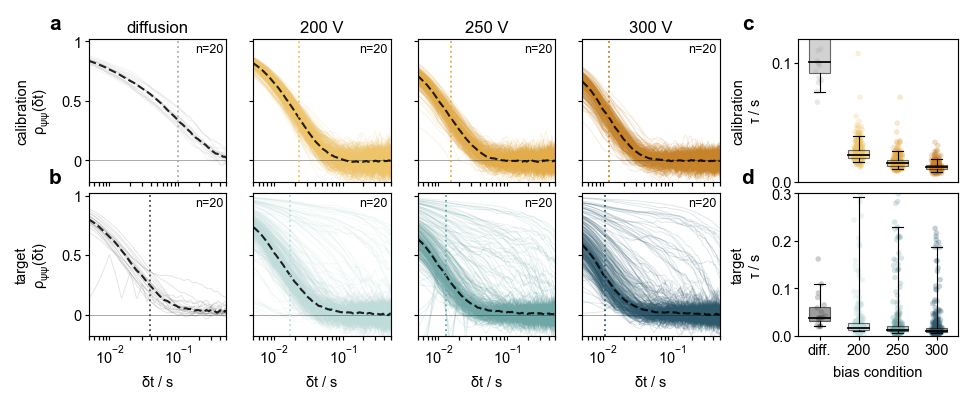

In [113]:
plot_autocorrelation_from_measurements(
    m_list=m_list,
    rotor_classes=("calibration", "target"),
    include_diff_column=True,
    show_other_rotors=False,
    n_max_rotors_per_subset=20,
    max_lag_s=0.5,
    acf_grid_n=160,
    random_seed=7,
    calibration_voltage_colors=calibration_voltage_colors,
    target_voltage_colors=target_voltage_colors,
    panel_labels=("a", "b", "c", "d"),
    panel_label_fontsize=10,
    panel_label_fontfamily="Arial",
    panel_label_fontweight="bold",
    acf_panel_label_x_rel=-0.20,
    summary_panel_label_x_rel=-0.28,
    panel_label_y_rel=0.04,
    fig_width_mm=160,
    fig_height_mm=68,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    title_size=8,
    annotation_size=6,
    stator_variant=stator_variant,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig3a_voltage__autocorrelation_curves",
    C=CK_colors,
)

## SI | Stationarity and overlap during umbrella sampling 

#### i. Compute stationarity during umbrella windows and overlap of distributions from neighboring windows

In [19]:
def compute_stationarity_overlap_target_rotors(
    m_list,
    min_locs_after_trim=100,
    min_locs_calibration_center=50,
    min_frame_coverage=None,
):
    """
    Compute lean UMB QC metrics for already-defined calibration and target rotors.

    Reads from each UMB measurement:
        m.calibration_rotors
        m.target_rotors
        m.trajectories
        m.protocol
        m.autocorrelation_trim_s

    Stores on each UMB measurement:
        m.voltage_stationarity_overlap_window_df

    Stored table contains only plot-relevant columns:
        measurement_index
        measurement_name
        voltage
        rotor_class
        particle
        phase
        window_index
        deg
        deg_display
        phi0_cmd_deg
        mean_phi_deg
        calib_mean_phi_deg
        command_error_deg
        calib_target_error_deg
        half_overlap
        half_mean_shift_deg
        neighbor_overlap_mean
        neighbor2_overlap_mean

    No radius-based target inference.
    No flat-particle logic.
    No particle summary tables.
    No return objects.
    """

    import re
    import gc
    import numpy as np
    import pandas as pd
    from pathlib import Path

    particle_col = "group"
    phi0_offset_rad = -np.pi / 2
    nbins = 72

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def measurement_name(m, i=None):
        try:
            return Path(path_string(m)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def parse_voltage(m):
        s = path_string(m)
        hits = re.findall(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])",
            s,
            flags=re.IGNORECASE,
        )
        if not hits:
            return np.nan

        v = float(hits[-1])
        if abs(v - round(v)) < 1e-9:
            return int(round(v))
        return v

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def wrap_deg(x):
        return (np.asarray(x, dtype=float) + 180.0) % 360.0 - 180.0

    def as_int_list(x):
        if x is None:
            return []
        if isinstance(x, (str, bytes)):
            return []
        try:
            return sorted(set(int(v) for v in list(x)))
        except Exception:
            try:
                return [int(x)]
            except Exception:
                return []

    def is_umb(m):
        name = path_string(m).upper()

        if "DIFF" in name:
            return False

        if "UMB" in name:
            return True

        return (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys())
        )

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError("m.protocol is missing or not a dict.")

        rows = []

        for label, value in m.protocol.items():
            if not isinstance(label, str) or not label.startswith("deg-"):
                continue

            try:
                deg = float(label.split("-")[1]) % 360.0
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            phi0_cmd = float(wrap_pi(np.deg2rad(deg) + float(phi0_offset_rad)))

            rows.append({
                "phase": str(label),
                "deg": float(deg),
                "deg_display": float(((deg + 180.0) % 360.0) - 180.0),
                "phi0_cmd_rad": float(phi0_cmd),
                "phi0_cmd_deg": float(np.rad2deg(phi0_cmd)),
                "start": float(start),
                "stop": float(stop),
            })

        if len(rows) == 0:
            raise ValueError("No parseable deg-* umbrella windows found.")

        df = pd.DataFrame(rows).sort_values("phi0_cmd_rad").reset_index(drop=True)
        df["window_index"] = np.arange(len(df), dtype=int)

        return df

    def infer_frame_time(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass

        if hasattr(m, "fps"):
            try:
                fps = float(getattr(m, "fps"))
                if np.isfinite(fps) and fps > 0:
                    return 1.0 / fps
            except Exception:
                pass

        return 0.005

    def get_trim_s(m):
        trim_s = getattr(m, "autocorrelation_trim_s", np.nan)

        try:
            trim_s = float(trim_s)
        except Exception:
            trim_s = np.nan

        if np.isfinite(trim_s) and trim_s >= 0:
            return trim_s

        return 0.0

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def hist_counts(phi, edges, min_count):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        if phi.size < int(min_count):
            return np.zeros(len(edges) - 1, dtype=np.int32), 0

        counts, _ = np.histogram(phi, bins=edges, density=False)
        return counts.astype(np.int32), int(phi.size)

    def hist_overlap_from_counts(c1, n1, c2, n2):
        if n1 <= 0 or n2 <= 0:
            return np.nan

        p1 = np.asarray(c1, dtype=float) / float(n1)
        p2 = np.asarray(c2, dtype=float) / float(n2)

        return float(np.sum(np.minimum(p1, p2)))

    def get_rotor_subsets(m):
        calibration = as_int_list(getattr(m, "calibration_rotors", None))
        target = as_int_list(getattr(m, "target_rotors", None))

        if len(calibration) == 0:
            raise ValueError(f"{measurement_name(m)}: m.calibration_rotors is missing or empty.")

        if len(target) == 0:
            raise ValueError(f"{measurement_name(m)}: m.target_rotors is missing or empty.")

        overlap = set(calibration) & set(target)

        if overlap:
            raise ValueError(
                f"{measurement_name(m)}: rotors are both calibration and target: {sorted(overlap)}"
            )

        return sorted(set(calibration)), sorted(set(target))

    def pick_phase_column(df):
        for col in ["phase", "protocol", "phase_name", "window", "segment"]:
            if col in df.columns:
                return col
        return None

    def pick_group_column(df):
        for col in ["group", "group_int", "particle", "particle_id"]:
            if col in df.columns:
                return col
        return None

    def pick_phi_column(df):
        for col in [
            "phi_unwrapped",
            "phi_unwrap",
            "phi_unwrapped_rad",
            "unwrapped_phi",
            "phi_cont",
            "phi_continuous",
            "phi_trajectory",
            "phi",
        ]:
            if col in df.columns:
                return col
        return None

    def get_phase_container(m, phase):
        if not hasattr(m, "trajectories") or m.trajectories is None:
            raise ValueError("m.trajectories missing. Run calc_trajectories() first.")

        tr = m.trajectories

        if isinstance(tr, dict):
            if phase in tr:
                return tr[phase]
            if str(phase) in tr:
                return tr[str(phase)]

            for key in tr.keys():
                if str(key) == str(phase):
                    return tr[key]

            return None

        if isinstance(tr, pd.DataFrame):
            phase_col = pick_phase_column(tr)

            if phase_col is None:
                return tr

            return tr[tr[phase_col].astype(str) == str(phase)].copy()

        return None

    def extract_particle_trace(obj, particle):
        particle = int(particle)

        if obj is None:
            return None

        if isinstance(obj, pd.DataFrame):
            df = obj

            group_col = pick_group_column(df)
            phi_col = pick_phi_column(df)

            if group_col is not None and phi_col is not None:
                d = df[df[group_col].astype(int) == particle].copy()

                if len(d) == 0:
                    return None

                if "frame" in d.columns:
                    d = d.sort_values("frame", kind="mergesort")
                elif "t" in d.columns:
                    d = d.sort_values("t", kind="mergesort")
                elif "time_s" in d.columns:
                    d = d.sort_values("time_s", kind="mergesort")
                elif "time" in d.columns:
                    d = d.sort_values("time", kind="mergesort")

                return np.asarray(d[phi_col].to_numpy(float), dtype=float)

            possible_cols = [
                particle,
                str(particle),
                f"{particle}",
                f"p{particle}",
                f"particle_{particle}",
            ]

            for col in possible_cols:
                if col in df.columns:
                    return np.asarray(df[col].to_numpy(float), dtype=float)

            return None

        if isinstance(obj, dict):
            if particle in obj:
                return extract_particle_trace(obj[particle], particle)
            if str(particle) in obj:
                return extract_particle_trace(obj[str(particle)], particle)

            for key in obj.keys():
                if str(key) == str(particle):
                    return extract_particle_trace(obj[key], particle)

            return None

        arr = np.asarray(obj)

        if arr.ndim == 1:
            return arr.astype(float)

        if arr.ndim == 2:
            if particle < arr.shape[0]:
                return arr[particle, :].astype(float)
            if particle < arr.shape[1]:
                return arr[:, particle].astype(float)

        return None

    def trim_trace_by_frames(phi, trim_s, dt):
        phi = np.asarray(phi, dtype=float)

        if phi.size == 0:
            return phi

        n_trim = int(np.floor(float(trim_s) / float(dt)))
        n_trim = max(0, min(n_trim, phi.size))

        return phi[n_trim:]

    def frame_coverage_of(phi):
        phi = np.asarray(phi, dtype=float)

        if phi.size == 0:
            return np.nan

        return float(np.isfinite(phi).sum() / phi.size)

    def passes_frame_coverage(phi):
        if min_frame_coverage is None:
            return True

        cov = frame_coverage_of(phi)

        if not np.isfinite(cov):
            return False

        return cov >= float(min_frame_coverage)

    def compute_half_stationarity(phi, edges):
        phi = np.asarray(phi, dtype=float)

        if phi.size < 2:
            return np.nan, np.nan

        half_idx = phi.size // 2
        phi_first = phi[:half_idx]
        phi_second = phi[half_idx:]

        if np.isfinite(phi_first).sum() < int(min_locs_after_trim):
            return np.nan, np.nan

        if np.isfinite(phi_second).sum() < int(min_locs_after_trim):
            return np.nan, np.nan

        c1, n1 = hist_counts(phi_first, edges, min_count=min_locs_after_trim)
        c2, n2 = hist_counts(phi_second, edges, min_count=min_locs_after_trim)

        half_overlap = hist_overlap_from_counts(c1, n1, c2, n2)

        mu_first = circular_mean(phi_first)
        mu_second = circular_mean(phi_second)

        half_mean_shift = (
            float(wrap_pi(mu_second - mu_first))
            if np.isfinite(mu_first) and np.isfinite(mu_second)
            else np.nan
        )

        return half_overlap, half_mean_shift

    def finite_pair_mean(a, b):
        vals = np.asarray([a, b], dtype=float)
        return float(np.nanmean(vals)) if np.any(np.isfinite(vals)) else np.nan

    m_flat = flatten(m_list)
    umb_measurements = [(i, m) for i, m in enumerate(m_flat) if is_umb(m)]

    if len(umb_measurements) == 0:
        raise ValueError("No UMB measurements found in m_list.")

    edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)

    for measurement_index, m in umb_measurements:
        name = measurement_name(m, measurement_index)
        voltage = parse_voltage(m)
        dt = infer_frame_time(m)
        trim_s = get_trim_s(m)
        windows = get_deg_windows(m)

        calibration_particles, target_particles = get_rotor_subsets(m)
        all_particles_needed = sorted(set(calibration_particles).union(set(target_particles)))

        phase_objects = {}
        for _, w in windows.iterrows():
            phase = str(w["phase"])
            phase_objects[phase] = get_phase_container(m, phase)

        trace_cache = {}

        for _, w in windows.iterrows():
            phase = str(w["phase"])
            obj = phase_objects.get(phase, None)

            phase_cache = {}

            for pid in all_particles_needed:
                phi = extract_particle_trace(obj, int(pid))

                if phi is None:
                    continue

                phi = trim_trace_by_frames(phi, trim_s=trim_s, dt=dt)
                phase_cache[int(pid)] = phi

            trace_cache[phase] = phase_cache

        calib_mu_by_wi = {}

        for _, w in windows.iterrows():
            phase = str(w["phase"])
            wi = int(w["window_index"])

            phi_pool = []

            for pid in calibration_particles:
                phi = trace_cache.get(phase, {}).get(int(pid), None)

                if phi is None or not passes_frame_coverage(phi):
                    continue

                finite_phi = phi[np.isfinite(phi)]

                if finite_phi.size >= int(min_locs_calibration_center):
                    phi_pool.append(finite_phi)

            if len(phi_pool):
                phi_concat = np.concatenate(phi_pool)
                calib_mu_by_wi[wi] = circular_mean(phi_concat)
            else:
                calib_mu_by_wi[wi] = np.nan

        row_cache = []
        counts_by_particle_window = {}

        ensemble_particles = [
            ("calibration", calibration_particles),
            ("target", target_particles),
        ]

        for rotor_class, particle_list in ensemble_particles:
            for particle in particle_list:
                particle = int(particle)

                for _, w in windows.iterrows():
                    phase = str(w["phase"])
                    wi = int(w["window_index"])
                    phi0_cmd_deg = float(w["phi0_cmd_deg"])

                    phi = trace_cache.get(phase, {}).get(particle, None)

                    if phi is None:
                        finite_phi = np.array([], dtype=float)
                    else:
                        usable_for_window = passes_frame_coverage(phi)
                        finite_phi = phi[np.isfinite(phi)] if usable_for_window else np.array([], dtype=float)

                    if finite_phi.size >= int(min_locs_after_trim):
                        mu = circular_mean(finite_phi)
                        counts, n_hist = hist_counts(finite_phi, edges, min_count=min_locs_after_trim)
                    else:
                        mu = np.nan
                        counts = np.zeros(int(nbins), dtype=np.int32)
                        n_hist = 0

                    counts_by_particle_window[(rotor_class, particle, wi)] = (counts, int(n_hist))

                    half_overlap, half_mean_shift = (
                        compute_half_stationarity(phi, edges)
                        if phi is not None and passes_frame_coverage(phi)
                        else (np.nan, np.nan)
                    )

                    mean_phi_deg = float(np.rad2deg(mu)) if np.isfinite(mu) else np.nan
                    calib_mu = calib_mu_by_wi.get(wi, np.nan)
                    calib_mean_phi_deg = float(np.rad2deg(calib_mu)) if np.isfinite(calib_mu) else np.nan

                    command_error_deg = (
                        float(np.abs(wrap_deg(mean_phi_deg - phi0_cmd_deg)))
                        if np.isfinite(mean_phi_deg) and np.isfinite(phi0_cmd_deg)
                        else np.nan
                    )

                    calib_target_error_deg = (
                        float(np.abs(wrap_deg(mean_phi_deg - calib_mean_phi_deg)))
                        if rotor_class == "target"
                        and np.isfinite(mean_phi_deg)
                        and np.isfinite(calib_mean_phi_deg)
                        else np.nan
                    )

                    row_cache.append({
                        "measurement_index": int(measurement_index),
                        "measurement_name": name,
                        "voltage": voltage,
                        "rotor_class": str(rotor_class),
                        "particle": int(particle),
                        "phase": phase,
                        "window_index": wi,
                        "deg": float(w["deg"]),
                        "deg_display": float(w["deg_display"]),
                        "phi0_cmd_deg": phi0_cmd_deg,
                        "mean_phi_deg": mean_phi_deg,
                        "calib_mean_phi_deg": calib_mean_phi_deg,
                        "command_error_deg": command_error_deg,
                        "calib_target_error_deg": calib_target_error_deg,
                        "half_overlap": float(half_overlap) if np.isfinite(half_overlap) else np.nan,
                        "half_mean_shift_deg": (
                            float(np.rad2deg(half_mean_shift))
                            if np.isfinite(half_mean_shift)
                            else np.nan
                        ),
                    })

        wis = windows["window_index"].astype(int).to_numpy()
        nwin = len(wis)

        overlap_map = {}

        for rotor_class, particle_list in ensemble_particles:
            for particle in particle_list:
                particle = int(particle)

                for k, wi in enumerate(wis):
                    wi = int(wi)

                    wprev1 = int(wis[(k - 1) % nwin])
                    wnext1 = int(wis[(k + 1) % nwin])
                    wprev2 = int(wis[(k - 2) % nwin])
                    wnext2 = int(wis[(k + 2) % nwin])

                    c_i, n_i = counts_by_particle_window.get(
                        (rotor_class, particle, wi),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )

                    c_p1, n_p1 = counts_by_particle_window.get(
                        (rotor_class, particle, wprev1),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )
                    c_n1, n_n1 = counts_by_particle_window.get(
                        (rotor_class, particle, wnext1),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )

                    c_p2, n_p2 = counts_by_particle_window.get(
                        (rotor_class, particle, wprev2),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )
                    c_n2, n_n2 = counts_by_particle_window.get(
                        (rotor_class, particle, wnext2),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )

                    overlap_prev1 = hist_overlap_from_counts(c_i, n_i, c_p1, n_p1)
                    overlap_next1 = hist_overlap_from_counts(c_i, n_i, c_n1, n_n1)

                    overlap_prev2 = hist_overlap_from_counts(c_i, n_i, c_p2, n_p2)
                    overlap_next2 = hist_overlap_from_counts(c_i, n_i, c_n2, n_n2)

                    overlap_map[(rotor_class, particle, wi)] = {
                        "neighbor_overlap_mean": finite_pair_mean(overlap_prev1, overlap_next1),
                        "neighbor2_overlap_mean": finite_pair_mean(overlap_prev2, overlap_next2),
                    }

        for row in row_cache:
            key = (row["rotor_class"], int(row["particle"]), int(row["window_index"]))
            vals = overlap_map.get(key, {})
            row["neighbor_overlap_mean"] = vals.get("neighbor_overlap_mean", np.nan)
            row["neighbor2_overlap_mean"] = vals.get("neighbor2_overlap_mean", np.nan)

        m.voltage_stationarity_overlap_window_df = pd.DataFrame(row_cache)

        del phase_objects
        del trace_cache
        del counts_by_particle_window
        del overlap_map
        gc.collect()

    return None

In [20]:
compute_stationarity_overlap_target_rotors(
    m_list=m_list,
    min_locs_after_trim=100,
    min_locs_calibration_center=50,
    min_frame_coverage=None,
)

#### ii. Plot stationarity overview across measurements

In [86]:
def plot_stationarity_from_measurements(
    m_list,
    target_voltage_colors,
    calibration_voltage_colors,
    failure_threshold_deg=25.0,
    metric_source="window",
    rotor_classes=("calibration", "target"),
    fig_width_mm=180,
    fig_height_mm=100,
    stator_variant="L4",
    save_dir=None,
    save_prefix="stationarity_steering_connectivity_by_UMB",
    C=CK_colors,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    point_size=8,
    point_alpha=0.28,
    max_points_per_box=350,
    strip_jitter=0.045,
    box_width=0.28,
    group_gap=1.12,
    class_offset=0.18,
    failure_bar_width=0.50,
    box_face_alpha=0.24,
    failure_ylim=None,
    stationarity_ylim=None,
    neighbor_ylim=None,
    neighbor2_ylim=None,
    steering_ylim_calibration=None,
    steering_ylim_target=None,
    shift_ylim_calibration=None,
    shift_ylim_target=None,
    panel_label_x=-0.24,
    panel_label_y=1.10,
    panel_label_fontsize=10,
    first_column_gap_ratio=0.34,
    subplot_wspace=0.36,
    subplot_hspace=0.58,
    print_summary=False,
    dpi=300,
):
    """
    UMB-resolved umbrella QC plot with six panels in a 2 x 3 layout.

    Panels a and d use separate y-axes:
        left:  calibration rotors
        right: target rotors

    The first-column gap is controlled independently by
    first_column_gap_ratio.

    Required beforehand:
        compute_stationarity_overlap_target_rotors(...)

    Returns None.
    """

    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.ticker import MaxNLocator

    if metric_source not in ("window", "particle"):
        raise ValueError("metric_source must be 'window' or 'particle'.")

    if not isinstance(target_voltage_colors, dict) or not target_voltage_colors:
        raise ValueError("target_voltage_colors must be a non-empty dictionary.")

    if not isinstance(calibration_voltage_colors, dict) or not calibration_voltage_colors:
        raise ValueError("calibration_voltage_colors must be a non-empty dictionary.")

    C = C() if callable(C) else dict(C)

    black = C.get("black", (0, 0, 0))
    fit_darkgrey = C.get("fit_darkgrey", (46 / 255, 46 / 255, 46 / 255))
    warmgold = C.get("warmgold", C.get("gold", (226 / 255, 172 / 255, 72 / 255)))
    target_teal = C.get("target_teal", (111 / 255, 166 / 255, 166 / 255))
    lightgrey = C.get("lightgrey", (0.72, 0.72, 0.72))

    # Use the darker 300 V colors for the dual-axis labels, ticks and spines.
    calibration_axis_color = calibration_voltage_colors.get(
        300,
        calibration_voltage_colors.get(max(calibration_voltage_colors), warmgold),
    )
    target_axis_color = target_voltage_colors.get(
        300,
        target_voltage_colors.get(max(target_voltage_colors), target_teal),
    )

    rng = np.random.default_rng(1)

    def mm_to_in(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def measurement_name(m, i=None):
        try:
            return Path(path_string(m)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def is_umb(m):
        name = path_string(m).upper()

        if "DIFF" in name:
            return False
        if "UMB" in name:
            return True

        return (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(
                isinstance(key, str) and key.startswith("deg-")
                for key in m.protocol
            )
        )

    def parse_voltage_from_name(name):
        hits = re.findall(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])",
            str(name),
            flags=re.IGNORECASE,
        )

        if not hits:
            return None

        voltage = float(hits[-1])

        if abs(voltage - round(voltage)) < 1e-9:
            return int(round(voltage))

        return voltage

    def clean_voltage(voltage):
        try:
            voltage = float(voltage)

            if abs(voltage - round(voltage)) < 1e-9:
                return int(round(voltage))

            return voltage
        except Exception:
            return voltage

    def voltage_label(voltage, fallback_index):
        try:
            voltage = clean_voltage(voltage)

            if isinstance(voltage, (int, np.integer)):
                return f"{int(voltage)}"

            if np.isfinite(float(voltage)):
                return f"{float(voltage):g}"
        except Exception:
            pass

        return f"UMB {fallback_index + 1}"

    def blend(c1, c2, t):
        c1 = np.asarray(c1[:3], dtype=float)
        c2 = np.asarray(c2[:3], dtype=float)
        return tuple((1.0 - float(t)) * c1 + float(t) * c2)

    def get_color(rotor_class, voltage):
        rotor_class = str(rotor_class)
        voltage = clean_voltage(voltage)

        if rotor_class == "calibration":
            return calibration_voltage_colors.get(voltage, warmgold)

        if rotor_class == "target":
            return target_voltage_colors.get(voltage, target_teal)

        return lightgrey

    def style_boxed_ax(ax):
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.60)
            spine.set_color(black)

        ax.tick_params(
            length=2.0,
            width=0.60,
            labelsize=float(tick_label_size),
            colors=black,
            pad=1.4,
            direction="out",
        )
        ax.grid(False)

    def style_dual_axes(ax_left, ax_right, left_color, right_color):
        ax_left.spines["left"].set_visible(True)
        ax_left.spines["left"].set_linewidth(0.75)
        ax_left.spines["left"].set_color(left_color)
        ax_left.spines["right"].set_visible(False)

        ax_left.spines["top"].set_visible(True)
        ax_left.spines["top"].set_linewidth(0.60)
        ax_left.spines["top"].set_color(black)
        ax_left.spines["bottom"].set_visible(True)
        ax_left.spines["bottom"].set_linewidth(0.60)
        ax_left.spines["bottom"].set_color(black)

        ax_left.tick_params(
            axis="x",
            length=2.0,
            width=0.60,
            labelsize=float(tick_label_size),
            colors=black,
            pad=1.4,
            direction="out",
        )
        ax_left.tick_params(
            axis="y",
            length=2.0,
            width=0.75,
            labelsize=float(tick_label_size),
            colors=left_color,
            pad=1.4,
            direction="out",
        )
        ax_left.yaxis.label.set_color(left_color)
        ax_left.grid(False)

        ax_right.patch.set_visible(False)
        ax_right.set_zorder(ax_left.get_zorder() + 1)
        ax_right.spines["right"].set_visible(True)
        ax_right.spines["right"].set_linewidth(0.75)
        ax_right.spines["right"].set_color(right_color)
        ax_right.spines["left"].set_visible(False)
        ax_right.spines["top"].set_visible(False)
        ax_right.spines["bottom"].set_visible(False)

        ax_right.tick_params(
            axis="y",
            length=2.0,
            width=0.75,
            labelsize=float(tick_label_size),
            colors=right_color,
            pad=1.4,
            direction="out",
        )
        ax_right.tick_params(axis="x", bottom=False, labelbottom=False)
        ax_right.yaxis.label.set_color(right_color)
        ax_right.grid(False)

    def auto_ylim(y, kind):
        y = np.asarray(y, dtype=float)
        y = y[np.isfinite(y)]

        if y.size == 0:
            return (0.0, 10.0) if kind in ("shift", "steering") else (0.0, 1.0)

        if kind in ("shift", "steering"):
            hi = max(float(np.nanpercentile(y, 98)) * 1.15, 4.0)
            return 0.0, hi

        lo = np.nanpercentile(y, 2)
        hi = np.nanpercentile(y, 98)

        if not np.isfinite(lo) or not np.isfinite(hi):
            return 0.0, 1.0

        span = max(hi - lo, 0.10)
        y0 = max(0.0, lo - 0.16 * span)
        y1 = min(1.02, hi + 0.20 * span)

        if y1 - y0 < 0.18:
            mid = 0.5 * (y0 + y1)
            y0 = max(0.0, mid - 0.09)
            y1 = min(1.02, mid + 0.09)

        return float(y0), float(y1)

    def collect_window_tables():
        parts = []
        umb_counter = 0

        for i, m in enumerate(flatten(m_list)):
            if not is_umb(m):
                continue

            df = getattr(m, "voltage_stationarity_overlap_window_df", None)

            if not isinstance(df, pd.DataFrame) or len(df) == 0:
                continue

            d = df.copy()
            name = measurement_name(m, i)

            if "measurement_index" not in d.columns:
                d["measurement_index"] = int(i)

            if "measurement_name" not in d.columns:
                d["measurement_name"] = name

            if "voltage" not in d.columns:
                parsed_voltage = parse_voltage_from_name(name)
                d["voltage"] = np.nan if parsed_voltage is None else parsed_voltage

            if "rotor_class" not in d.columns:
                d["rotor_class"] = (
                    d["ensemble"].astype(str)
                    if "ensemble" in d.columns
                    else "target"
                )

            d["voltage"] = d["voltage"].map(clean_voltage)
            d["_umb_index"] = int(umb_counter)
            d["_umb_source_index"] = int(i)
            d["_umb_name"] = name

            first_voltage = d["voltage"].dropna()

            if len(first_voltage):
                d["_umb_voltage"] = clean_voltage(first_voltage.iloc[0])
            else:
                parsed_voltage = parse_voltage_from_name(name)
                d["_umb_voltage"] = (
                    np.nan
                    if parsed_voltage is None
                    else clean_voltage(parsed_voltage)
                )

            d["_umb_label"] = voltage_label(
                d["_umb_voltage"].iloc[0],
                umb_counter,
            )

            parts.append(d)
            umb_counter += 1

        if not parts:
            raise ValueError(
                "No stored UMB QC tables found. "
                "Run compute_stationarity_overlap_target_rotors(...) first."
            )

        out = pd.concat(parts, ignore_index=True)
        out["rotor_class"] = out["rotor_class"].astype(str)

        required = [
            "particle",
            "command_error_deg",
            "calib_target_error_deg",
            "half_overlap",
            "half_mean_shift_deg",
            "neighbor_overlap_mean",
            "neighbor2_overlap_mean",
        ]

        for col in required:
            if col not in out.columns:
                out[col] = np.nan

        out["abs_half_mean_shift_deg"] = np.abs(
            out["half_mean_shift_deg"].to_numpy(float)
        )

        out["failed_target_vs_calib"] = (
            out["rotor_class"].astype(str).eq("target")
            & np.isfinite(out["calib_target_error_deg"].to_numpy(float))
            & (
                out["calib_target_error_deg"].to_numpy(float)
                > float(failure_threshold_deg)
            )
        )

        return out

    def make_metric_table(window_df, source):
        d = window_df.copy()
        d["_use_for_qc_metric"] = True

        d.loc[
            d["rotor_class"].astype(str).eq("target")
            & d["failed_target_vs_calib"].astype(bool),
            "_use_for_qc_metric",
        ] = False

        if source == "window":
            return d

        rows = []
        group_cols = [
            "_umb_index",
            "_umb_label",
            "_umb_name",
            "_umb_voltage",
            "measurement_index",
            "measurement_name",
            "voltage",
            "rotor_class",
            "particle",
        ]

        for keys, g in d.groupby(group_cols, dropna=False, sort=False):
            (
                umb_index,
                umb_label,
                umb_name,
                umb_voltage,
                measurement_index,
                measurement_name_value,
                voltage,
                rotor_class,
                particle,
            ) = keys

            g_qc = g[g["_use_for_qc_metric"].astype(bool)].copy()
            command_error = g["command_error_deg"].to_numpy(float)
            half_overlap = g_qc["half_overlap"].to_numpy(float)
            half_shift = g_qc["abs_half_mean_shift_deg"].to_numpy(float)
            neighbor_overlap = g_qc["neighbor_overlap_mean"].to_numpy(float)
            neighbor2_overlap = g_qc["neighbor2_overlap_mean"].to_numpy(float)

            rows.append({
                "_umb_index": int(umb_index),
                "_umb_label": umb_label,
                "_umb_name": umb_name,
                "_umb_voltage": umb_voltage,
                "measurement_index": measurement_index,
                "measurement_name": measurement_name_value,
                "voltage": voltage,
                "rotor_class": rotor_class,
                "particle": particle,
                "command_error_deg": (
                    float(np.nanmedian(command_error))
                    if np.any(np.isfinite(command_error))
                    else np.nan
                ),
                "half_overlap": (
                    float(np.nanmedian(half_overlap))
                    if len(g_qc) and np.any(np.isfinite(half_overlap))
                    else np.nan
                ),
                "abs_half_mean_shift_deg": (
                    float(np.nanmedian(half_shift))
                    if len(g_qc) and np.any(np.isfinite(half_shift))
                    else np.nan
                ),
                "neighbor_overlap_mean": (
                    float(np.nanmedian(neighbor_overlap))
                    if len(g_qc) and np.any(np.isfinite(neighbor_overlap))
                    else np.nan
                ),
                "neighbor2_overlap_mean": (
                    float(np.nanmedian(neighbor2_overlap))
                    if len(g_qc) and np.any(np.isfinite(neighbor2_overlap))
                    else np.nan
                ),
                "_use_for_qc_metric": True,
            })

        return pd.DataFrame(rows)

    def make_failure_summary(window_df):
        target_df = window_df[
            window_df["rotor_class"].astype(str).eq("target")
        ].copy()

        rows = []

        if len(target_df) == 0:
            return pd.DataFrame(columns=[
                "_umb_index",
                "_umb_label",
                "_umb_name",
                "_umb_voltage",
                "mean_failed",
                "std_failed",
                "n_target_particles",
            ])

        for umb_index, g_u in target_df.groupby("_umb_index", sort=True):
            fail_counts = []

            for _, g_p in g_u.groupby("particle", sort=True):
                fail_counts.append(
                    int(np.sum(g_p["failed_target_vs_calib"].astype(bool)))
                )

            fail_counts = np.asarray(fail_counts, dtype=float)

            if fail_counts.size:
                rows.append({
                    "_umb_index": int(umb_index),
                    "_umb_label": str(g_u["_umb_label"].iloc[0]),
                    "_umb_name": str(g_u["_umb_name"].iloc[0]),
                    "_umb_voltage": g_u["_umb_voltage"].iloc[0],
                    "mean_failed": float(np.nanmean(fail_counts)),
                    "std_failed": (
                        float(np.nanstd(fail_counts, ddof=1))
                        if fail_counts.size > 1
                        else 0.0
                    ),
                    "n_target_particles": int(fail_counts.size),
                })

        return pd.DataFrame(rows)

    def get_values(df, metric_key):
        col = {
            "steering": "command_error_deg",
            "stationarity": "half_overlap",
            "shift": "abs_half_mean_shift_deg",
            "neighbor": "neighbor_overlap_mean",
            "neighbor2": "neighbor2_overlap_mean",
        }[metric_key]

        if col not in df.columns:
            return np.array([], dtype=float)

        y = df[col].to_numpy(float)
        return y[np.isfinite(y)]

    def plot_box_data(ax, plot_df, metric_key, rotor_classes_use):
        box_data = []
        box_pos = []
        box_colors = []

        for umb_index in umb_indices:
            voltage = umb_voltage_by_index[umb_index]

            for rotor_class in rotor_classes_use:
                if (umb_index, rotor_class) not in pos:
                    continue

                g = plot_df[
                    plot_df["_umb_index"].astype(int).eq(int(umb_index))
                    & plot_df["rotor_class"].astype(str).eq(str(rotor_class))
                ].copy()

                if metric_key != "steering" and "_use_for_qc_metric" in g.columns:
                    g = g[g["_use_for_qc_metric"].astype(bool)].copy()

                y = get_values(g, metric_key)

                if y.size == 0:
                    continue

                x0 = pos[(umb_index, rotor_class)]
                color = get_color(rotor_class, voltage)
                y_scatter = y

                if (
                    max_points_per_box is not None
                    and y_scatter.size > int(max_points_per_box)
                ):
                    take = rng.choice(
                        np.arange(y_scatter.size),
                        size=int(max_points_per_box),
                        replace=False,
                    )
                    y_scatter = y_scatter[take]

                jitter = rng.normal(
                    0.0,
                    float(strip_jitter),
                    size=y_scatter.size,
                )
                jitter = np.clip(
                    jitter,
                    -2.0 * float(strip_jitter),
                    2.0 * float(strip_jitter),
                )

                ax.scatter(
                    np.full(y_scatter.size, x0) + jitter,
                    y_scatter,
                    s=float(point_size),
                    facecolor=color,
                    edgecolor=blend(color, fit_darkgrey, 0.18),
                    linewidth=0.18,
                    alpha=float(point_alpha),
                    rasterized=True,
                    zorder=2,
                )

                box_data.append(y)
                box_pos.append(x0)
                box_colors.append(color)

        if box_data:
            bp = ax.boxplot(
                box_data,
                positions=box_pos,
                widths=float(box_width),
                patch_artist=True,
                showfliers=False,
                whis=(5, 95),
                zorder=4,
            )

            for patch, color in zip(bp["boxes"], box_colors):
                patch.set_facecolor((*color[:3], float(box_face_alpha)))
                patch.set_edgecolor(blend(color, fit_darkgrey, 0.14))
                patch.set_linewidth(0.85)

            expanded_colors = [
                color
                for color in box_colors
                for _ in range(2)
            ]

            for whisker, color in zip(bp["whiskers"], expanded_colors):
                whisker.set_color(blend(color, fit_darkgrey, 0.14))
                whisker.set_linewidth(0.75)

            for cap, color in zip(bp["caps"], expanded_colors):
                cap.set_color(blend(color, fit_darkgrey, 0.14))
                cap.set_linewidth(0.75)

            for median in bp["medians"]:
                median.set_color(fit_darkgrey)
                median.set_linewidth(1.15)

        return box_pos

    def add_boxplot_panel(ax, plot_df, metric_key, ylabel, ylim, kind):
        box_pos = plot_box_data(
            ax,
            plot_df,
            metric_key,
            rotor_classes,
        )

        ax.set_ylabel(ylabel, fontsize=float(axis_label_size))

        if box_pos:
            ax.set_xlim(min(box_pos) - 0.38, max(box_pos) + 0.38)

        if ylim is not None:
            ax.set_ylim(*ylim)
        else:
            ax.set_ylim(*auto_ylim(get_values(plot_df, metric_key), kind))

        style_boxed_ax(ax)

    def add_dual_boxplot_panel(
        ax_left,
        ax_right,
        plot_df,
        metric_key,
        ylabel,
        ylim_calibration,
        ylim_target,
        kind,
    ):
        calibration_pos = plot_box_data(
            ax_left,
            plot_df,
            metric_key,
            ("calibration",),
        )

        target_pos = plot_box_data(
            ax_right,
            plot_df,
            metric_key,
            ("target",),
        )

        all_positions = list(calibration_pos) + list(target_pos)

        if all_positions:
            xlim = (
                min(all_positions) - 0.38,
                max(all_positions) + 0.38,
            )
            ax_left.set_xlim(*xlim)
            ax_right.set_xlim(*xlim)

        calibration_values = get_values(
            plot_df[
                plot_df["rotor_class"].astype(str).eq("calibration")
            ],
            metric_key,
        )

        target_values = get_values(
            plot_df[
                plot_df["rotor_class"].astype(str).eq("target")
            ],
            metric_key,
        )

        ax_left.set_ylim(
            *(ylim_calibration or auto_ylim(calibration_values, kind))
        )
        ax_right.set_ylim(
            *(ylim_target or auto_ylim(target_values, kind))
        )

        ax_left.set_ylabel(
            "calibration\n" + ylabel,
            fontsize=float(axis_label_size),
            color=calibration_axis_color,
            labelpad=4,
        )

        ax_right.set_ylabel(
            "target",
            fontsize=float(axis_label_size),
            color=target_axis_color,
            rotation=270,
            va="bottom",
            labelpad=2,
        )

        style_dual_axes(
            ax_left,
            ax_right,
            calibration_axis_color,
            target_axis_color,
        )

    window_df = collect_window_tables()
    metric_df = make_metric_table(window_df, metric_source)
    failure_summary_df = make_failure_summary(window_df)

    umb_order = (
        window_df[
            [
                "_umb_index",
                "_umb_label",
                "_umb_name",
                "_umb_voltage",
            ]
        ]
        .drop_duplicates()
        .sort_values("_umb_index")
        .reset_index(drop=True)
    )

    if len(umb_order) == 0:
        raise ValueError("No UMB measurements found in stored QC tables.")

    umb_indices = umb_order["_umb_index"].astype(int).tolist()
    umb_labels = umb_order["_umb_label"].astype(str).tolist()

    umb_voltage_by_index = {
        int(row["_umb_index"]): clean_voltage(row["_umb_voltage"])
        for _, row in umb_order.iterrows()
    }

    rotor_classes = [str(rotor_class) for rotor_class in rotor_classes]
    centers = np.arange(len(umb_indices), dtype=float) * float(group_gap)
    pos = {}

    for i, umb_index in enumerate(umb_indices):
        if len(rotor_classes) == 1:
            pos[(umb_index, rotor_classes[0])] = centers[i]
        else:
            if "calibration" in rotor_classes:
                pos[(umb_index, "calibration")] = (
                    centers[i] - float(class_offset)
                )

            if "target" in rotor_classes:
                pos[(umb_index, "target")] = (
                    centers[i] + float(class_offset)
                )

            extra = [
                rotor_class
                for rotor_class in rotor_classes
                if rotor_class not in ("calibration", "target")
            ]

            for j, rotor_class in enumerate(extra):
                pos[(umb_index, rotor_class)] = (
                    centers[i]
                    + (j + 2) * float(class_offset)
                )

    if print_summary:
        print("")
        print("UMB QC plot statistics")
        print("-----------------------")
        print(
            "Target failure definition: "
            "|target mean phi - calibration mean phi| "
            f"> {float(failure_threshold_deg):g}°."
        )
        print("Panels a and d use separate calibration and target y-axis scales.")
        print("Stationarity/connectivity panels exclude failed target windows.")
        print("")

    plt.rcParams.update({
        "font.size": float(fontsize),
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": float(axis_label_size),
        "xtick.labelsize": float(tick_label_size),
        "ytick.labelsize": float(tick_label_size),
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig = plt.figure(
        figsize=(
            mm_to_in(fig_width_mm),
            mm_to_in(fig_height_mm),
        )
    )

    # The second GridSpec column is an empty spacer. This increases only
    # the gap between visual columns 1 and 2.
    gs = fig.add_gridspec(
        2,
        4,
        width_ratios=[
            1.0,
            float(first_column_gap_ratio),
            1.0,
            1.0,
        ],
        left=0.105,
        right=0.965,
        bottom=0.105,
        top=0.935,
        wspace=float(subplot_wspace),
        hspace=float(subplot_hspace),
    )

    ax_steer = fig.add_subplot(gs[0, 0])
    ax_fail = fig.add_subplot(gs[0, 2])
    ax_half = fig.add_subplot(gs[0, 3])

    ax_shift = fig.add_subplot(gs[1, 0])
    ax_neigh = fig.add_subplot(gs[1, 2])
    ax_neigh2 = fig.add_subplot(gs[1, 3])

    ax_steer_target = ax_steer.twinx()
    ax_shift_target = ax_shift.twinx()

    add_dual_boxplot_panel(
        ax_left=ax_steer,
        ax_right=ax_steer_target,
        plot_df=metric_df,
        metric_key="steering",
        ylabel=r"$|\langle\varphi\rangle-\varphi_\mathrm{cmd}|$ / °",
        ylim_calibration=steering_ylim_calibration,
        ylim_target=steering_ylim_target,
        kind="steering",
    )

    means = []
    stds = []

    for umb_index in umb_indices:
        g = failure_summary_df[
            failure_summary_df["_umb_index"]
            .astype(int)
            .eq(int(umb_index))
        ]

        means.append(
            float(g["mean_failed"].iloc[0])
            if len(g)
            else np.nan
        )
        stds.append(
            float(g["std_failed"].iloc[0])
            if len(g)
            else np.nan
        )

    for umb_index, x0, mean, std in zip(
        umb_indices,
        centers,
        means,
        stds,
    ):
        if not np.isfinite(mean):
            continue

        color = get_color(
            "target",
            umb_voltage_by_index[umb_index],
        )

        ax_fail.bar(
            x0,
            mean,
            width=float(failure_bar_width),
            color=color,
            edgecolor=blend(color, fit_darkgrey, 0.20),
            linewidth=0.60,
            alpha=0.86,
            zorder=3,
        )

        if np.isfinite(std) and std > 0:
            ax_fail.errorbar(
                x0,
                mean,
                yerr=std,
                fmt="+",
                ecolor=fit_darkgrey,
                color=fit_darkgrey,
                elinewidth=0.75,
                capsize=2.2,
                capthick=0.75,
                zorder=4,
            )

    ax_fail.axhline(
        0,
        color=fit_darkgrey,
        lw=0.55,
        alpha=0.60,
    )

    if failure_ylim is not None:
        ax_fail.set_ylim(*failure_ylim)
    else:
        y = np.asarray(means, float) + np.asarray(stds, float)
        y = y[np.isfinite(y)]

        ax_fail.set_ylim(
            0,
            max(
                1.0,
                float(np.nanmax(y)) * 1.20,
            )
            if y.size
            else 1.0,
        )

    ax_fail.set_xlim(
        centers[0] - 0.38,
        centers[-1] + 0.38,
    )
    ax_fail.yaxis.set_major_locator(
        MaxNLocator(integer=False, nbins=4)
    )
    ax_fail.set_ylabel(
        r"$N_\mathrm{fail}$ per target rotor",
        fontsize=float(axis_label_size),
    )
    style_boxed_ax(ax_fail)

    add_boxplot_panel(
        ax=ax_half,
        plot_df=metric_df,
        metric_key="stationarity",
        ylabel=r"$O_{1/2}$",
        ylim=stationarity_ylim,
        kind="overlap",
    )

    add_dual_boxplot_panel(
        ax_left=ax_shift,
        ax_right=ax_shift_target,
        plot_df=metric_df,
        metric_key="shift",
        ylabel=r"$|\Delta\bar{\varphi}_{1/2}|$ / °",
        ylim_calibration=shift_ylim_calibration,
        ylim_target=shift_ylim_target,
        kind="shift",
    )

    add_boxplot_panel(
        ax=ax_neigh,
        plot_df=metric_df,
        metric_key="neighbor",
        ylabel=r"$O_{n,n+1}$",
        ylim=neighbor_ylim,
        kind="overlap",
    )

    add_boxplot_panel(
        ax=ax_neigh2,
        plot_df=metric_df,
        metric_key="neighbor2",
        ylabel=r"$O_{n,n+2}$",
        ylim=neighbor2_ylim,
        kind="overlap",
    )

    primary_axes = [
        ax_steer,
        ax_fail,
        ax_half,
        ax_shift,
        ax_neigh,
        ax_neigh2,
    ]

    for ax in primary_axes:
        ax.set_xticks(centers)
        ax.set_xticklabels(
            umb_labels,
            fontsize=float(tick_label_size),
        )
        ax.set_xlabel(
            "bias voltage / V",
            fontsize=float(axis_label_size),
        )

    for ax, panel_letter in zip(
        primary_axes,
        ["a", "b", "c", "d", "e", "f"],
    ):
        ax.text(
            float(panel_label_x),
            float(panel_label_y),
            panel_letter,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=float(panel_label_fontsize),
            fontweight="bold",
            fontfamily="Arial",
            color=black,
            clip_on=False,
        )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        prefix = (
            f"{stator_variant}__{save_prefix}"
            if stator_variant is not None and len(str(stator_variant))
            else save_prefix
        )

        fig.savefig(
            save_dir / f"{prefix}.png",
            dpi=int(dpi),
            bbox_inches="tight",
        )
        fig.savefig(
            save_dir / f"{prefix}.svg",
            dpi=int(dpi),
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    return None

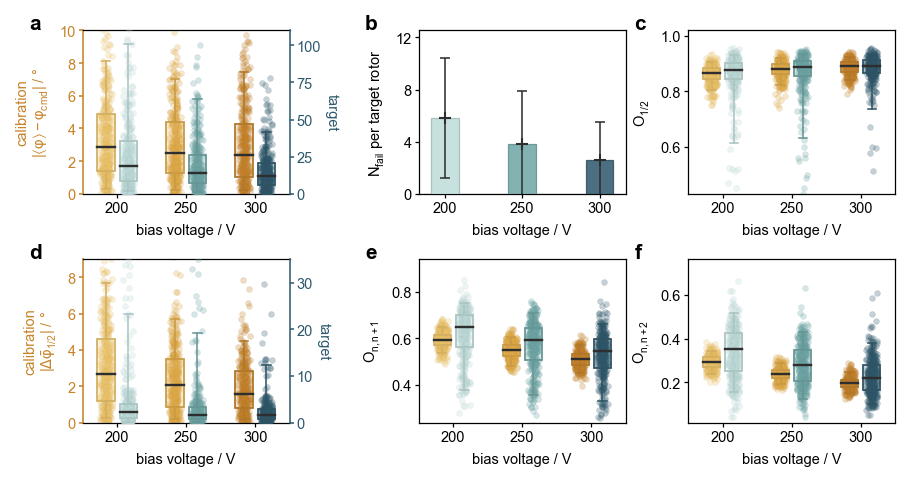

In [93]:
plot_stationarity_from_measurements(
    m_list=m_list,
    failure_threshold_deg=25.0,
    metric_source="window",

    rotor_classes=("calibration", "target"),
    target_voltage_colors=target_voltage_colors,
    calibration_voltage_colors=calibration_voltage_colors,

    fig_width_mm=160,
    fig_height_mm=80,

    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,

    box_width=0.28,
    failure_bar_width=0.40,
    group_gap=1.12,
    class_offset=0.18,

    steering_ylim_calibration=(0, 10),
    steering_ylim_target=(0, 110),
    shift_ylim_calibration=(0, 9),
    shift_ylim_target=(0, 35),

    panel_label_x=-0.26,
    panel_label_y=1.10,
    panel_label_fontsize=10,

    first_column_gap_ratio=0.02,
    subplot_wspace=0.40,
    subplot_hspace=0.40,

    stator_variant=stator_variant,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig3a_voltage__stationarity_steering_connectivity",
)

#### iii. Plot exemplary data of calibration rotor and target rotor for single m

In [23]:
def plot_exemplary_data_rotors(
    m_list,
    particle=None,
    rotor_index=None,
    measurement_index=0,
    rotor_class="target",
    center_phase="deg-100",
    example_phases=None,
    n_neighbor_windows=5,
    C=CK_colors,
    hist_bins=72,
    rolling_mean_s=0.10,
    max_trace_points=500,
    fig_width_mm=180,
    fig_height_mm=120,
    save_dir=None,
    save_prefix="umbrella_qc_single_particle_lean",
    stator_variant=None,
):
    """
    Lean single-particle umbrella QC plot.

    Compatible with the new lean QC storage:
        m.voltage_stationarity_overlap_window_df

    Required on each UMB measurement:
        m.voltage_stationarity_overlap_window_df
        m.trajectories
        m.protocol

    Optional rotor lists:
        target:
            m.target_rotors
            m.target_particles

        calibration:
            m.calibration_rotors
            m.flat_rotors
            m.flat_particles_reliable
            m.flat_particles

    Particle selection:
        1) particle=<id> directly uses that particle id.
        2) rotor_index=<i> selects from the corresponding rotor list.
        3) if neither is given, auto-selects from the QC window table.

    Notes
    -----
    - Does not require m.voltage_stationarity_overlap_particle_df.
    - Does not write anything back into m.
    - Derives radian columns locally from degree columns if needed.
    - Recomputes only the traces/histograms needed for the shown particle.
    - Saves only if save_dir is not None.
    - Closes the figure after display.
    - Returns None.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    phi0_offset_rad = -np.pi / 2

    rotor_class = str(rotor_class).lower().strip()
    if rotor_class not in {"target", "calibration"}:
        raise ValueError("rotor_class must be 'target' or 'calibration'.")


    cmd_color = C["black"]
    calib_color = C["warmgold"]
    selected_color = C["target_teal"] if rotor_class == "target" else C["warmgold"]

    overlap_fill_color = (
        (*C["target_teal"][:3], 0.450)
        if rotor_class == "target"
        else (*C["beige"][:3], 0.75)
    )

    raw_trace_color = (0.82, 0.82, 0.82)
    smooth_trace_color = C["black"]
    early_color = C["lightgrey"]
    late_color = C["black"]
    overlap_i_color = C["black"]
    overlap_j_color = C["midgrey"]
    selected_band_color = (0.88, 0.88, 0.88)

    heat_cmap = LinearSegmentedColormap.from_list(
        "white_to_selected",
        [(1, 1, 1, 1), tuple(list(selected_color) + [1.0])],
        N=256,
    )

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def wrap_deg(x):
        return (np.asarray(x, dtype=float) + 180.0) % 360.0 - 180.0

    def align_angle_to_reference(angle, reference):
        angle = np.asarray(angle, dtype=float)
        reference = np.asarray(reference, dtype=float)
        return reference + wrap_pi(angle - reference)

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def as_int_list(x):
        if x is None:
            return []
        if isinstance(x, (pd.Series, np.ndarray)):
            x = x.tolist()
        if isinstance(x, (list, tuple, set)):
            out = []
            for v in x:
                try:
                    fv = float(v)
                    if np.isfinite(fv):
                        out.append(int(fv))
                except Exception:
                    pass
            return out
        try:
            return [int(x)]
        except Exception:
            return []

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == "":
            return str(name)
        return f"{str(stator_variant).strip()}__{name}"

    def style_ax(ax, labelsize=6.5):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=labelsize,
            color="black",
            labelcolor="black",
        )

    def is_umb(m):
        s = str(getattr(m, "path", "")).upper()

        if "DIFF" in s:
            return False

        if "UMB" in s:
            return True

        return hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys()
        )

    def infer_dt(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass

        if hasattr(m, "fps"):
            try:
                fps = float(getattr(m, "fps"))
                if np.isfinite(fps) and fps > 0:
                    return 1.0 / fps
            except Exception:
                pass

        return 0.005

    def infer_trim_s(m, wdf):
        if hasattr(m, "autocorrelation_trim_s"):
            try:
                v = float(m.autocorrelation_trim_s)
                if np.isfinite(v) and v >= 0:
                    return v
            except Exception:
                pass

        if hasattr(m, "wham_trim_s"):
            try:
                v = float(m.wham_trim_s)
                if np.isfinite(v) and v >= 0:
                    return v
            except Exception:
                pass

        if "trim_s" in wdf.columns and len(wdf):
            vals = wdf["trim_s"].to_numpy(float)
            vals = vals[np.isfinite(vals) & (vals >= 0)]
            if vals.size:
                return float(vals[0])

        return 0.0

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}.")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}.")

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError("m.protocol missing or not a dict.")

        rows = []

        for phase, value in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue

            try:
                deg = float(phase.split("-")[1]) % 360.0
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            phi0_cmd = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))

            rows.append({
                "phase": str(phase),
                "deg": float(deg),
                "deg_display": float(((deg + 180.0) % 360.0) - 180.0),
                "phi0_cmd_rad": float(phi0_cmd),
                "phi0_cmd_deg": float(np.rad2deg(phi0_cmd)),
                "start": float(start),
                "stop": float(stop),
            })

        if not rows:
            raise ValueError("No parseable deg-* umbrella windows found.")

        df = pd.DataFrame(rows).sort_values("phi0_cmd_rad").reset_index(drop=True)
        df["window_index"] = np.arange(len(df), dtype=int)

        return df

    def hist_density(phi, edges):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.zeros(len(edges) - 1, dtype=float)

        counts, _ = np.histogram(phi, bins=edges)
        total = counts.sum()

        if total <= 0:
            return np.zeros(len(edges) - 1, dtype=float)

        dphi = float(edges[1] - edges[0])

        return counts.astype(float) / (float(total) * dphi)

    def get_example_window_indices(windows):
        if example_phases is not None:
            out = []

            for ph in list(example_phases):
                hit = windows[windows["phase"].astype(str) == str(ph)]

                if len(hit):
                    out.append(int(hit["window_index"].iloc[0]))

            if not out:
                raise ValueError("None of the requested example_phases were found.")

            return out

        if center_phase is None:
            center_i = len(windows) // 2
        else:
            hit = windows[windows["phase"].astype(str) == str(center_phase)]
            center_i = int(hit["window_index"].iloc[0]) if len(hit) else len(windows) // 2

        n = max(1, int(n_neighbor_windows))
        n_left = n // 2
        n_right = n - n_left - 1
        nwin = len(windows)

        return [int((center_i + j) % nwin) for j in range(-n_left, n_right + 1)]

    def smooth_trace_time(t, y, rolling_mean_s):
        t = np.asarray(t, dtype=float)
        y = np.asarray(y, dtype=float)

        if t.size < 3 or rolling_mean_s is None or rolling_mean_s <= 0:
            return y.copy()

        dt = np.nanmedian(np.diff(t))

        if not np.isfinite(dt) or dt <= 0:
            return y.copy()

        win = max(3, int(round(float(rolling_mean_s) / dt)))

        if win % 2 == 0:
            win += 1

        if win >= y.size:
            win = y.size if y.size % 2 else y.size - 1

        if win < 3:
            return y.copy()

        finite = np.isfinite(y)
        y0 = np.where(finite, y, 0.0)
        w0 = finite.astype(float)

        kernel = np.ones(win, dtype=float)
        pad = win // 2

        ypad = np.pad(y0, pad_width=pad, mode="edge")
        wpad = np.pad(w0, pad_width=pad, mode="edge")

        num = np.convolve(ypad, kernel, mode="valid")
        den = np.convolve(wpad, kernel, mode="valid")

        out = np.full_like(y, np.nan, dtype=float)
        ok = den > 0
        out[ok] = num[ok] / den[ok]

        return out

    def downsample(t, y, nmax):
        t = np.asarray(t)
        y = np.asarray(y)

        if t.size <= int(nmax):
            return t, y

        idx = np.linspace(0, t.size - 1, int(nmax)).astype(int)

        return t[idx], y[idx]

    def pick_col(df, candidates):
        for col in candidates:
            if col in df.columns:
                return col
        return None

    def get_phase_container(m, phase):
        tr = getattr(m, "trajectories", None)

        if tr is None:
            raise ValueError("m.trajectories missing. Run calc_trajectories() first.")

        if isinstance(tr, dict):
            if phase in tr:
                return tr[phase]
            if str(phase) in tr:
                return tr[str(phase)]

            for key in tr:
                if str(key) == str(phase):
                    return tr[key]

            return None

        if isinstance(tr, pd.DataFrame):
            phase_col = pick_col(tr, ["phase", "protocol", "phase_name", "window", "segment"])

            if phase_col is None:
                return tr

            return tr[tr[phase_col].astype(str) == str(phase)].copy()

        return tr

    def extract_particle_trace(obj, pid):
        pid = int(pid)

        if obj is None:
            return np.array([], dtype=float)

        if isinstance(obj, pd.DataFrame):
            group_col = pick_col(obj, ["group", "group_int", "particle", "particle_id"])
            phi_col = pick_col(
                obj,
                [
                    "phi_unwrapped",
                    "phi_unwrap",
                    "phi_unwrapped_rad",
                    "unwrapped_phi",
                    "phi_cont",
                    "phi_continuous",
                    "phi_trajectory",
                    "phi",
                ],
            )

            if group_col is not None and phi_col is not None:
                d = obj[obj[group_col].astype(int) == pid].copy()

                if len(d) == 0:
                    return np.array([], dtype=float)

                sort_col = pick_col(d, ["frame", "t", "time_s", "time"])

                if sort_col is not None:
                    d = d.sort_values(sort_col, kind="mergesort")

                return d[phi_col].to_numpy(float)

            for col in [pid, str(pid), f"p{pid}", f"particle_{pid}"]:
                if col in obj.columns:
                    return obj[col].to_numpy(float)

            return np.array([], dtype=float)

        if isinstance(obj, dict):
            if pid in obj:
                return extract_particle_trace(obj[pid], pid)
            if str(pid) in obj:
                return extract_particle_trace(obj[str(pid)], pid)

            for key in obj:
                if str(key) == str(pid):
                    return extract_particle_trace(obj[key], pid)

            return np.array([], dtype=float)

        arr = np.asarray(obj)

        if arr.ndim == 1:
            return arr.astype(float)

        if arr.ndim == 2:
            if pid < arr.shape[0]:
                return arr[pid, :].astype(float)
            if pid < arr.shape[1]:
                return arr[:, pid].astype(float)

        return np.array([], dtype=float)

    def get_trace_for_phase(m, pid, phase, trim_s, dt):
        phi = extract_particle_trace(get_phase_container(m, phase), pid)
        phi = np.asarray(phi, dtype=float)

        if phi.size == 0:
            return np.array([], dtype=float), np.array([], dtype=float)

        n_trim = max(0, min(phi.size, int(np.floor(float(trim_s) / float(dt)))))
        phi = phi[n_trim:]

        t = np.arange(phi.size, dtype=float) * float(dt)

        return t, wrap_pi(phi)

    def get_rotor_list(m, rotor_class):
        if rotor_class == "target":
            attrs = ["target_rotors", "target_particles"]
        else:
            attrs = ["calibration_rotors", "flat_rotors", "flat_particles_reliable", "flat_particles"]

        for attr in attrs:
            if hasattr(m, attr):
                vals = as_int_list(getattr(m, attr))

                if vals:
                    return vals, attr

        return [], None

    def resolve_particle(m, particle, rotor_index, rotor_class, window_df):
        if particle is not None:
            return int(particle)

        rotor_list, source_attr = get_rotor_list(m, rotor_class)

        if rotor_index is not None:
            if not rotor_list:
                raise ValueError(
                    f"rotor_index was given, but no {rotor_class} rotor list exists on this measurement."
                )

            idx = int(rotor_index)

            if idx < 0 or idx >= len(rotor_list):
                raise IndexError(
                    f"rotor_index={idx} outside m.{source_attr}, which has n={len(rotor_list)} entries."
                )

            return int(rotor_list[idx])

        d = window_df.copy()

        if "rotor_class" in d.columns:
            d = d[d["rotor_class"].astype(str).str.lower().str.strip() == rotor_class].copy()
        elif rotor_list:
            d = d[d["particle"].astype(int).isin(rotor_list)].copy()

        if len(d) == 0 and rotor_list:
            return int(rotor_list[0])

        if len(d) == 0:
            raise ValueError(
                f"Could not auto-select a {rotor_class} rotor. "
                "Pass particle=<id> or rotor_index=<i>."
            )

        score_rows = []

        for pid, g in d.groupby("particle", sort=True):
            score = 0.0

            if "half_overlap" in g.columns:
                vals = g["half_overlap"].to_numpy(float)
                score += float(np.nanmedian(vals)) if np.any(np.isfinite(vals)) else 0.0

            if "neighbor_overlap_mean" in g.columns:
                vals = g["neighbor_overlap_mean"].to_numpy(float)
                score += float(np.nanmedian(vals)) if np.any(np.isfinite(vals)) else 0.0

            if "half_mean_shift_deg" in g.columns:
                vals = np.abs(g["half_mean_shift_deg"].to_numpy(float))
                shift = float(np.nanmedian(vals)) if np.any(np.isfinite(vals)) else 0.0
                score -= 0.01 * shift

            score_rows.append((int(pid), score))

        if not score_rows:
            row = d.sort_values("particle").iloc[0]
            return int(row["particle"])

        return int(sorted(score_rows, key=lambda x: x[1], reverse=True)[0][0])

    def make_local_plot_columns(wdf):
        wdf = wdf.copy()

        if "phi0_cmd_rad" not in wdf.columns:
            if "phi0_cmd_deg" in wdf.columns:
                wdf["phi0_cmd_rad"] = np.deg2rad(wdf["phi0_cmd_deg"].to_numpy(float))
            else:
                raise KeyError("Need phi0_cmd_deg or phi0_cmd_rad in m.voltage_stationarity_overlap_window_df.")

        if "phi0_cmd_deg" not in wdf.columns:
            wdf["phi0_cmd_deg"] = np.rad2deg(wdf["phi0_cmd_rad"].to_numpy(float))

        if "mean_phi_rad" not in wdf.columns and "mean_phi_deg" in wdf.columns:
            wdf["mean_phi_rad"] = np.deg2rad(wdf["mean_phi_deg"].to_numpy(float))

        if "mean_phi_deg" not in wdf.columns and "mean_phi_rad" in wdf.columns:
            wdf["mean_phi_deg"] = np.rad2deg(wdf["mean_phi_rad"].to_numpy(float))

        if "calib_mean_phi_rad" not in wdf.columns and "calib_mean_phi_deg" in wdf.columns:
            wdf["calib_mean_phi_rad"] = np.deg2rad(wdf["calib_mean_phi_deg"].to_numpy(float))

        if "calib_mean_phi_deg" not in wdf.columns and "calib_mean_phi_rad" in wdf.columns:
            wdf["calib_mean_phi_deg"] = np.rad2deg(wdf["calib_mean_phi_rad"].to_numpy(float))

        if "target_mean_phi_rad" not in wdf.columns and "target_mean_phi_deg" in wdf.columns:
            wdf["target_mean_phi_rad"] = np.deg2rad(wdf["target_mean_phi_deg"].to_numpy(float))

        if "target_mean_phi_deg" not in wdf.columns and "target_mean_phi_rad" in wdf.columns:
            wdf["target_mean_phi_deg"] = np.rad2deg(wdf["target_mean_phi_rad"].to_numpy(float))

        if "delta_target_minus_calib_mean_phi_deg" not in wdf.columns:
            if "mean_phi_deg" in wdf.columns and "calib_mean_phi_deg" in wdf.columns:
                wdf["delta_target_minus_calib_mean_phi_deg"] = wrap_deg(
                    wdf["mean_phi_deg"].to_numpy(float)
                    - wdf["calib_mean_phi_deg"].to_numpy(float)
                )
            elif "calib_target_error_deg" in wdf.columns:
                wdf["delta_target_minus_calib_mean_phi_deg"] = wdf["calib_target_error_deg"].to_numpy(float)
            else:
                wdf["delta_target_minus_calib_mean_phi_deg"] = np.nan

        if "neighbor_overlap_min" not in wdf.columns and "neighbor_overlap_mean" in wdf.columns:
            wdf["neighbor_overlap_min"] = wdf["neighbor_overlap_mean"].to_numpy(float)

        if "neighbor2_overlap_min" not in wdf.columns and "neighbor2_overlap_mean" in wdf.columns:
            wdf["neighbor2_overlap_min"] = wdf["neighbor2_overlap_mean"].to_numpy(float)

        return wdf

    m_flat = flatten(m_list)

    if not m_flat:
        raise ValueError("m_list is empty.")

    measurement_index = int(measurement_index)

    if measurement_index < 0 or measurement_index >= len(m_flat):
        raise IndexError(f"measurement_index={measurement_index} outside m_list length {len(m_flat)}.")

    m = m_flat[measurement_index]

    if not is_umb(m):
        raise ValueError(
            f"measurement_index={measurement_index} does not look like an UMB measurement."
        )

    window_df = getattr(m, "voltage_stationarity_overlap_window_df", None)

    if window_df is None or len(window_df) == 0:
        raise ValueError("m.voltage_stationarity_overlap_window_df is missing or empty.")

    window_df = window_df.copy()

    if "measurement_index" in window_df.columns:
        window_df = window_df[window_df["measurement_index"].astype(int) == measurement_index].copy()

    particle = resolve_particle(
        m=m,
        particle=particle,
        rotor_index=rotor_index,
        rotor_class=rotor_class,
        window_df=window_df,
    )

    wdf = window_df[window_df["particle"].astype(int) == int(particle)].copy()

    if "rotor_class" in wdf.columns:
        wdf_class = wdf[wdf["rotor_class"].astype(str).str.lower().str.strip() == rotor_class].copy()

        if len(wdf_class):
            wdf = wdf_class

    if len(wdf) == 0:
        raise ValueError(
            f"No stored QC rows found for particle={particle}, rotor_class={rotor_class}."
        )

    wdf = wdf.sort_values("window_index").reset_index(drop=True)
    wdf = make_local_plot_columns(wdf)

    windows = get_deg_windows(m)
    dt = infer_dt(m)
    trim_s = infer_trim_s(m, wdf)

    example_wi = get_example_window_indices(windows)

    edges_phi = np.linspace(-np.pi, np.pi, int(hist_bins) + 1)
    centers_phi = 0.5 * (edges_phi[:-1] + edges_phi[1:])

    window_cache = {}

    for _, row in windows.iterrows():
        wi = int(row["window_index"])
        phase = str(row["phase"])
        t, phi = get_trace_for_phase(m, particle, phase, trim_s, dt)

        window_cache[wi] = {
            "phase": phase,
            "t": t,
            "phi": phi,
            "density": hist_density(phi, edges_phi),
        }

    density_arr = np.asarray(
        [window_cache[int(wi)]["density"] for wi in wdf["window_index"].astype(int)],
        dtype=float,
    )

    fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

    left = 0.045
    right = 0.985
    bottom = 0.075
    top = 0.94

    nrows = len(example_wi)
    row_gap = 0.016
    row_h = (top - bottom - row_gap * (nrows - 1)) / nrows

    w_heat = 0.18
    w_trace = 0.18
    w_stat = 0.16
    w_overlap = 0.16
    w_metrics = right - left - w_heat - w_trace - w_stat - w_overlap - 4 * 0.035

    x_heat = left
    x_trace = x_heat + w_heat + 0.035
    x_stat = x_trace + w_trace + 0.035
    x_overlap = x_stat + w_stat + 0.035
    x_metrics = x_overlap + w_overlap + 0.035

    ax_heat = fig.add_axes([x_heat, bottom, w_heat, top - bottom])

    vmax = None
    if np.any(np.isfinite(density_arr)):
        vmax0 = float(np.nanpercentile(density_arr, 95))
        if np.isfinite(vmax0) and vmax0 > 0:
            vmax = vmax0

    ax_heat.imshow(
        density_arr,
        aspect="auto",
        interpolation="nearest",
        origin="lower",
        extent=[-np.pi, np.pi, -0.5, len(density_arr) - 0.5],
        cmap=heat_cmap,
        vmin=0,
        vmax=vmax,
        alpha=0.80,
    )

    cmd_phi = wdf["phi0_cmd_rad"].to_numpy(float)
    ywin = np.arange(len(wdf), dtype=float)

    wi_to_rowpos = {int(wi): i for i, wi in enumerate(wdf["window_index"].astype(int))}

    for wi in example_wi:
        if int(wi) in wi_to_rowpos:
            y = wi_to_rowpos[int(wi)]
            ax_heat.axhspan(
                y - 0.45,
                y + 0.45,
                color=selected_band_color,
                alpha=0.20,
                lw=0,
                zorder=0,
            )

    ax_heat.plot(
        cmd_phi,
        ywin,
        lw=1.15,
        ls="--",
        color=cmd_color,
        label=r"$\varphi_\mathrm{cmd}$",
        zorder=4,
    )

    if "calib_mean_phi_rad" in wdf.columns:
        calib_phi = align_angle_to_reference(wdf["calib_mean_phi_rad"].to_numpy(float), cmd_phi)

        ax_heat.plot(
            calib_phi,
            ywin,
            marker="o",
            ms=2.2,
            lw=0.95,
            color=calib_color,
            label="calib.",
            zorder=5,
        )

    if "mean_phi_rad" in wdf.columns:
        mean_phi = align_angle_to_reference(wdf["mean_phi_rad"].to_numpy(float), cmd_phi)

        ax_heat.plot(
            mean_phi,
            ywin,
            marker="o",
            ms=2.2,
            lw=0.95,
            color=selected_color,
            label="target" if rotor_class == "target" else "selected",
            zorder=6,
        )
    elif "target_mean_phi_rad" in wdf.columns:
        mean_phi = align_angle_to_reference(wdf["target_mean_phi_rad"].to_numpy(float), cmd_phi)

        ax_heat.plot(
            mean_phi,
            ywin,
            marker="o",
            ms=2.2,
            lw=0.95,
            color=selected_color,
            label="target",
            zorder=6,
        )

    ax_heat.set_xlim(-1.10 * np.pi, 1.10 * np.pi)
    ax_heat.set_xlabel(r"$\varphi$ / rad", fontsize=7)
    ax_heat.set_ylabel("window index", fontsize=7)
    ax_heat.set_xticks([-np.pi, 0, np.pi])
    ax_heat.set_xticklabels([r"$-\pi$", "0", r"$\pi$"], fontsize=6)
    ax_heat.legend(
        frameon=False,
        fontsize=5.4,
        loc="lower right",
        handlelength=1.2,
        borderpad=0.1,
        labelspacing=0.2,
    )
    style_ax(ax_heat)

    stat_share_ax = None
    overlap_share_ax = None

    for r, wi in enumerate(example_wi):
        y0 = top - (r + 1) * row_h - r * row_gap

        win_row = windows[windows["window_index"].astype(int) == int(wi)].iloc[0]
        phi0 = float(win_row["phi0_cmd_rad"])

        t = window_cache[int(wi)]["t"]
        phi = window_cache[int(wi)]["phi"]
        psi = wrap_pi(phi - phi0)

        ax = fig.add_axes([x_trace, y0, w_trace, row_h])

        t_plot, psi_plot = downsample(t, psi, max_trace_points)
        psi_smooth = smooth_trace_time(t_plot, psi_plot, rolling_mean_s)

        ax.plot(
            t_plot,
            np.rad2deg(psi_plot),
            lw=0.40,
            color=raw_trace_color,
            alpha=0.85,
            rasterized=True,
        )
        ax.plot(
            t_plot,
            np.rad2deg(psi_smooth),
            lw=1.00,
            color=smooth_trace_color,
            alpha=0.95,
        )
        ax.axhline(0, lw=0.45, color="black", alpha=0.30)
        ax.set_ylim(-55, 55)
        ax.set_yticks([-50, 0, 50])
        ax.set_ylabel(r"$\psi$ / °", fontsize=6.5)

        if r == nrows - 1:
            ax.set_xlabel("time after trim / s", fontsize=6.5)
        else:
            ax.set_xticklabels([])

        style_ax(ax, labelsize=6)

        if stat_share_ax is None:
            ax = fig.add_axes([x_stat, y0, w_stat, row_h])
            stat_share_ax = ax
        else:
            ax = fig.add_axes([x_stat, y0, w_stat, row_h], sharey=stat_share_ax)

        finite_psi = psi[np.isfinite(psi)]

        if finite_psi.size >= 4:
            half = finite_psi.size // 2
            p_first = hist_density(finite_psi[:half], edges_phi)
            p_second = hist_density(finite_psi[half:], edges_phi)

            ax.plot(centers_phi, p_first, lw=1.00, color=early_color, alpha=0.95)
            ax.plot(centers_phi, p_second, lw=1.15, color=late_color, alpha=0.95)

        ax.set_xlim(-0.5 * np.pi, 0.5 * np.pi)
        ax.set_xticks([-0.5 * np.pi, 0, 0.5 * np.pi])
        ax.set_xticklabels([r"$-\pi/2$", "0", r"$\pi/2$"], fontsize=6)
        ax.set_ylabel("density", fontsize=6.5)

        if r == nrows - 1:
            ax.set_xlabel(r"$\psi$ / rad", fontsize=6.5)
        else:
            ax.set_xticklabels([])

        style_ax(ax, labelsize=6)

        if overlap_share_ax is None:
            ax = fig.add_axes([x_overlap, y0, w_overlap, row_h])
            overlap_share_ax = ax
        else:
            ax = fig.add_axes([x_overlap, y0, w_overlap, row_h], sharey=overlap_share_ax)

        next_wi = int((int(wi) + 1) % len(windows))
        phi_next = window_cache[next_wi]["phi"]

        p_i = hist_density(phi, edges_phi)
        p_j = hist_density(phi_next, edges_phi)
        p_min = np.minimum(p_i, p_j)

        ax.fill_between(
            centers_phi,
            0,
            p_min,
            color=overlap_fill_color,
            linewidth=0,
            zorder=1,
        )
        ax.plot(centers_phi, p_i, lw=1.05, color=overlap_i_color, alpha=0.95, zorder=3)
        ax.plot(centers_phi, p_j, lw=1.05, color=overlap_j_color, alpha=0.95, zorder=2)

        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, 0, np.pi])
        ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"], fontsize=6)
        ax.set_ylabel("density", fontsize=6.5)

        if r == nrows - 1:
            ax.set_xlabel(r"$\varphi$ / rad", fontsize=6.5)
        else:
            ax.set_xticklabels([])

        style_ax(ax, labelsize=6)

    metrics_h_gap = 0.06
    metrics_h = (top - bottom - 2 * metrics_h_gap) / 3

    ax_m1 = fig.add_axes([x_metrics, bottom + 2 * (metrics_h + metrics_h_gap), w_metrics, metrics_h])
    ax_m2 = fig.add_axes([x_metrics, bottom + 1 * (metrics_h + metrics_h_gap), w_metrics, metrics_h])
    ax_m3 = fig.add_axes([x_metrics, bottom, w_metrics, metrics_h])

    x = wdf["phi0_cmd_deg"].to_numpy(float)
    sort = np.argsort(x)
    x_sorted = x[sort]

    def shade_metric_ax(ax):
        xvals = wdf["phi0_cmd_deg"].to_numpy(float)
        xvals = xvals[np.isfinite(xvals)]

        dx = np.nanmedian(np.abs(np.diff(np.sort(xvals)))) if xvals.size > 1 else 20.0

        if not np.isfinite(dx) or dx <= 0:
            dx = 20.0

        for wi in example_wi:
            row = wdf[wdf["window_index"].astype(int) == int(wi)]

            if len(row) == 0:
                continue

            xx = float(row["phi0_cmd_deg"].iloc[0])

            ax.axvspan(
                xx - 0.35 * dx,
                xx + 0.35 * dx,
                color=selected_band_color,
                alpha=0.35,
                lw=0,
                zorder=0,
            )

    for ax in [ax_m1, ax_m2, ax_m3]:
        shade_metric_ax(ax)

    if rotor_class == "target" and "delta_target_minus_calib_mean_phi_deg" in wdf.columns:
        delta = wdf["delta_target_minus_calib_mean_phi_deg"].to_numpy(float)
        delta_label = r"$\Delta\langle\varphi\rangle$ / °"
    elif "command_error_deg" in wdf.columns:
        delta = wdf["command_error_deg"].to_numpy(float)
        delta_label = r"$|\langle\varphi\rangle-\varphi_\mathrm{cmd}|$ / °"
    elif "mean_phi_deg" in wdf.columns and "phi0_cmd_deg" in wdf.columns:
        delta = wrap_deg(wdf["mean_phi_deg"].to_numpy(float) - wdf["phi0_cmd_deg"].to_numpy(float))
        delta_label = r"$\langle\varphi\rangle-\varphi_\mathrm{cmd}$ / °"
    else:
        delta = np.full(len(wdf), np.nan)
        delta_label = r"$\Delta\varphi$ / °"

    ax_m1.axhline(0, lw=0.5, color="black", alpha=0.40, zorder=1)
    ax_m1.plot(x_sorted, delta[sort], marker="o", ms=2.1, lw=0.90, color="black", zorder=3)
    ax_m1.set_ylabel(delta_label, fontsize=6.5)
    ax_m1.set_xticklabels([])
    style_ax(ax_m1, labelsize=6)

    if "half_overlap" in wdf.columns:
        ax_m2.plot(
            x_sorted,
            wdf["half_overlap"].to_numpy(float)[sort],
            marker="o",
            ms=2.1,
            lw=0.90,
            color="black",
            zorder=3,
        )

    ax_m2.set_ylim(0, 1.03)
    ax_m2.set_ylabel(r"$O_{1/2}$", fontsize=6.5)
    ax_m2.set_xticklabels([])
    style_ax(ax_m2, labelsize=6)

    if "neighbor_overlap_mean" in wdf.columns:
        ax_m3.plot(
            x_sorted,
            wdf["neighbor_overlap_mean"].to_numpy(float)[sort],
            marker="o",
            ms=2.1,
            lw=0.90,
            color="black",
            label=r"$O_{n,n+1}$",
            zorder=3,
        )

    if "neighbor2_overlap_mean" in wdf.columns:
        ax_m3.plot(
            x_sorted,
            wdf["neighbor2_overlap_mean"].to_numpy(float)[sort],
            lw=0.85,
            color=C["midgrey"],
            label=r"$O_{n,n+2}$",
            zorder=2,
        )

    ax_m3.set_ylim(0, 1.03)
    ax_m3.set_ylabel(r"$O_\mathrm{neighbor}$", fontsize=6.5)
    ax_m3.set_xlabel(r"$\varphi_\mathrm{cmd}$ / °", fontsize=6.5)
    ax_m3.legend(frameon=False, fontsize=5.8, handlelength=1.0)
    style_ax(ax_m3, labelsize=6)

    xmin = np.nanmin(x_sorted) if np.any(np.isfinite(x_sorted)) else -180
    xmax = np.nanmax(x_sorted) if np.any(np.isfinite(x_sorted)) else 180

    for ax in [ax_m1, ax_m2, ax_m3]:
        ax.set_xlim(xmin - 5, xmax + 5)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        suffix = f"{rotor_class}_p{int(particle)}"

        if rotor_index is not None:
            suffix = f"{rotor_class}_idx{int(rotor_index)}_p{int(particle)}"

        out_name = f"{prefixed_name(save_prefix)}__{suffix}"

        fig.savefig(save_dir / f"{out_name}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{out_name}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None

In [24]:
# if full_execution:
#     plot_exemplary_data_rotors(
#         m_list,
#         measurement_index=0,
#         rotor_class="calibration",
#         rotor_index=0,
#         C=CK_colors,
#         save_dir=save_dir,
#         save_prefix="Fig2_exemplary_rotor",
#         stator_variant=stator_variant,
#     )
    
#     plot_exemplary_data_rotors(
#         m_list,
#         measurement_index=0,
#         rotor_class="target",
#         rotor_index=0,
#         save_dir=save_dir,
#         C=CK_colors,
#         save_prefix="Fig2_exemplary_rotor",
#         stator_variant=stator_variant,
#     )

#### iv. Plot exemplary data for different voltages as overlap

In [127]:
def plot_exemplary_data_rotors(
    m_list,
    calibration_voltage_colors,
    target_voltage_colors,
    particle=None,
    rotor_index=0,
    rotor_class="target",
    voltage_order=(200, 250, 300),
    reference_voltage=300,
    center_phase="deg-100",
    example_phases=None,
    n_neighbor_windows=3,
    stationarity_hist_xlim_deg=None,
    stationarity_hist_xticks_deg=None,
    neighbor_hist_xlim_deg=None,
    neighbor_hist_xticks_deg=None,
    command_marker="v",
    command_marker_size=3.5,
    command_marker_y_fraction=-0.045,
    command_marker_margin_fraction=0.09,
    metrics_column_gap=0.085,
    voltage_group_gap=0.040,
    selected_band_alpha=0.42,
    C=CK_colors,
    hist_bins=72,
    fig_width_mm=180,
    fig_height_mm=100,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=6,
    save_dir=None,
    save_prefix="Fig2_exemplary_rotor_voltage_overlay",
    stator_variant=None,
    show_panel_labels=True,
    show_main_panel_labels=True,
    show_metric_panel_labels=True,
    panel_labels_main=("a", "b", "c"),
    panel_labels_metrics=("d", "e", "f"),
    panel_label_x_main=-0.18,
    panel_label_y_main=1.03,
    panel_label_x_metrics=-0.18,
    panel_label_y_metrics=1.03,
    panel_label_fontsize=10,
):
    """
    Same-rotor umbrella QC comparison across bias voltages.

    Layout
    ------
    Column 1
        One angular-density heatmap per voltage, with selected-window shading.

    Column 2
        Early/late density comparison O_{1/2}, shown in absolute phi.

    Column 3
        Neighboring-window overlap O_{n,n+1}, shown in absolute phi.

    Column 4
        Voltage-overlaid QC metrics:
            Delta phi
            O_1/2
            O_n,n+1

    Notes
    -----
    - One filename-sorted UMB measurement is used per requested voltage.
    - The same particle ID is used at every voltage.
    - Voltage colors are supplied externally.
    - PNG saving is hardcoded at 300 dpi.
    - No data are written back into m.
    - Returns None.
    """

    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    phi0_offset_rad = -np.pi / 2
    rotor_class = str(rotor_class).lower().strip()

    if rotor_class not in {"target", "calibration"}:
        raise ValueError("rotor_class must be 'target' or 'calibration'.")
    if not isinstance(calibration_voltage_colors, dict) or not calibration_voltage_colors:
        raise ValueError("calibration_voltage_colors must be a non-empty dictionary.")
    if not isinstance(target_voltage_colors, dict) or not target_voltage_colors:
        raise ValueError("target_voltage_colors must be a non-empty dictionary.")

    C = C() if callable(C) else dict(C)
    cmd_color = C["black"]
    early_alpha = 0.45
    late_alpha = 0.95
    overlap_i_color = C["black"]
    overlap_j_color = C["midgrey"]
    selected_band_color = (0.88, 0.88, 0.88)
    voltage_colors = target_voltage_colors if rotor_class == "target" else calibration_voltage_colors

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def wrap_deg(x):
        return (np.asarray(x, dtype=float) + 180) % 360 - 180

    def align_angle_to_reference(angle, reference):
        angle = np.asarray(angle, dtype=float)
        reference = np.asarray(reference, dtype=float)
        return reference + wrap_pi(angle - reference)

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            return [item for sub in obj for item in flatten(sub)]
        return [obj]

    def as_int_list(values):
        if values is None:
            return []
        if isinstance(values, (pd.Series, np.ndarray)):
            values = values.tolist()
        if not isinstance(values, (list, tuple, set)):
            values = [values]

        out = []
        for value in values:
            try:
                value = float(value)
                if np.isfinite(value):
                    out.append(int(value))
            except Exception:
                pass
        return out

    def prefixed_name(name):
        return str(name) if stator_variant is None or not str(stator_variant).strip() else f"{str(stator_variant).strip()}__{name}"

    def measurement_name(m, index=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{index}]" if index is not None else "unknown"

    def parse_voltage(m):
        text = str(getattr(m, "path", measurement_name(m)))
        hits = re.findall(r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])", text, flags=re.IGNORECASE)

        if not hits:
            return None

        voltage = float(hits[-1])
        return int(round(voltage)) if abs(voltage - round(voltage)) < 1e-9 else voltage

    def voltage_color(voltage):
        return voltage_colors.get(voltage, C["grey"])

    def style_main_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.60)
            spine.set_color(C["black"])

        ax.tick_params(
            length=2.0, width=0.60, labelsize=tick_label_size,
            color=C["black"], labelcolor=C["black"], pad=1.4,
        )
        ax.grid(False)

    def style_mini_hist_ax(ax):
        ax.spines["bottom"].set_visible(True)
        ax.spines["bottom"].set_linewidth(0.60)
        ax.spines["bottom"].set_color(C["black"])
        ax.spines["left"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["top"].set_visible(False)

        ax.tick_params(
            axis="x", length=1.6, width=0.55, labelsize=tick_label_size,
            color=C["black"], labelcolor=C["black"], pad=1.2,
        )
        ax.tick_params(axis="y", left=False, right=False, labelleft=False, labelright=False)
        ax.grid(False)

    def is_umb(m):
        name = str(getattr(m, "path", measurement_name(m))).upper()

        if "DIFF" in name:
            return False
        if "UMB" in name:
            return True

        return (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(key, str) and key.startswith("deg-") for key in m.protocol)
        )

    def infer_dt(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass

        if hasattr(m, "fps"):
            try:
                fps = float(m.fps)
                if np.isfinite(fps) and fps > 0:
                    return 1 / fps
            except Exception:
                pass

        return 0.005

    def infer_trim_s(m, window_df):
        for attr in ["autocorrelation_trim_s", "wham_trim_s"]:
            if hasattr(m, attr):
                try:
                    value = float(getattr(m, attr))
                    if np.isfinite(value) and value >= 0:
                        return value
                except Exception:
                    pass

        if "trim_s" in window_df.columns:
            values = window_df["trim_s"].to_numpy(float)
            values = values[np.isfinite(values) & (values >= 0)]

            if len(values):
                return float(values[0])

        return 0.0

    def protocol_bounds(value):
        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict)):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}.")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}.")

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError("m.protocol missing or not a dictionary.")

        rows = []

        for phase, value in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue

            try:
                deg = float(phase.split("-")[1]) % 360
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            phi0_cmd = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))

            rows.append({
                "phase": str(phase),
                "deg": float(deg),
                "deg_display": float(((deg + 180) % 360) - 180),
                "phi0_cmd_rad": phi0_cmd,
                "phi0_cmd_deg": float(np.rad2deg(phi0_cmd)),
                "start": float(start),
                "stop": float(stop),
            })

        if not rows:
            raise ValueError("No parseable deg-* umbrella windows found.")

        out = pd.DataFrame(rows).sort_values("phi0_cmd_rad").reset_index(drop=True)
        out["window_index"] = np.arange(len(out), dtype=int)

        return out

    def hist_density(phi, edges):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        if len(phi) == 0:
            return np.zeros(len(edges) - 1, dtype=float)

        counts, _ = np.histogram(phi, bins=edges)
        total = counts.sum()

        if total <= 0:
            return np.zeros(len(edges) - 1, dtype=float)

        dphi = float(edges[1] - edges[0])
        return counts.astype(float) / (float(total) * dphi)

    def hist_density_linear(values, edges):
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]

        if len(values) == 0:
            return np.zeros(len(edges) - 1, dtype=float)

        counts, _ = np.histogram(values, bins=edges)
        total = counts.sum()

        if total <= 0:
            return np.zeros(len(edges) - 1, dtype=float)

        dx = float(edges[1] - edges[0])
        return counts.astype(float) / (float(total) * dx)

    def get_example_window_indices(windows):
        if example_phases is not None:
            out = []

            for phase in example_phases:
                hit = windows[windows["phase"].astype(str) == str(phase)]

                if len(hit):
                    out.append(int(hit["window_index"].iloc[0]))

            if not out:
                raise ValueError("None of example_phases was found.")

            return out

        hit = windows[windows["phase"].astype(str) == str(center_phase)] if center_phase is not None else pd.DataFrame()
        center_index = int(hit["window_index"].iloc[0]) if len(hit) else len(windows) // 2

        n = max(1, int(n_neighbor_windows))
        n_left = n // 2
        n_right = n - n_left - 1
        n_windows = len(windows)

        return [
            int((center_index + offset) % n_windows)
            for offset in range(-n_left, n_right + 1)
        ]

    def pick_column(df, candidates):
        for column in candidates:
            if column in df.columns:
                return column

        return None

    def get_phase_container(m, phase):
        trajectories = getattr(m, "trajectories", None)

        if trajectories is None:
            raise ValueError("m.trajectories missing. Run calc_trajectories() first.")

        if isinstance(trajectories, dict):
            if phase in trajectories:
                return trajectories[phase]
            if str(phase) in trajectories:
                return trajectories[str(phase)]

            for key in trajectories:
                if str(key) == str(phase):
                    return trajectories[key]

            return None

        if isinstance(trajectories, pd.DataFrame):
            phase_column = pick_column(
                trajectories,
                ["phase", "protocol", "phase_name", "window", "segment"],
            )

            if phase_column is None:
                return trajectories

            return trajectories[
                trajectories[phase_column].astype(str).eq(str(phase))
            ].copy()

        return trajectories

    def extract_particle_trace(obj, particle_id):
        particle_id = int(particle_id)

        if obj is None:
            return np.array([], dtype=float)

        if isinstance(obj, pd.DataFrame):
            group_column = pick_column(obj, ["group", "group_int", "particle", "particle_id"])
            phi_column = pick_column(
                obj,
                [
                    "phi_unwrapped", "phi_unwrap", "phi_unwrapped_rad",
                    "unwrapped_phi", "phi_cont", "phi_continuous",
                    "phi_trajectory", "phi",
                ],
            )

            if group_column is not None and phi_column is not None:
                data = obj[obj[group_column].astype(int).eq(particle_id)].copy()

                if len(data) == 0:
                    return np.array([], dtype=float)

                sort_column = pick_column(data, ["frame", "t", "time_s", "time"])

                if sort_column is not None:
                    data = data.sort_values(sort_column, kind="mergesort")

                return data[phi_column].to_numpy(float)

            for column in [particle_id, str(particle_id), f"p{particle_id}", f"particle_{particle_id}"]:
                if column in obj.columns:
                    return obj[column].to_numpy(float)

            return np.array([], dtype=float)

        if isinstance(obj, dict):
            if particle_id in obj:
                return extract_particle_trace(obj[particle_id], particle_id)
            if str(particle_id) in obj:
                return extract_particle_trace(obj[str(particle_id)], particle_id)

            for key in obj:
                if str(key) == str(particle_id):
                    return extract_particle_trace(obj[key], particle_id)

            return np.array([], dtype=float)

        array = np.asarray(obj)

        if array.ndim == 1:
            return array.astype(float)

        if array.ndim == 2:
            if particle_id < array.shape[0]:
                return array[particle_id, :].astype(float)
            if particle_id < array.shape[1]:
                return array[:, particle_id].astype(float)

        return np.array([], dtype=float)

    def get_trace_for_phase(m, particle_id, phase, trim_s, dt):
        phi = extract_particle_trace(get_phase_container(m, phase), particle_id)
        phi = np.asarray(phi, dtype=float)

        if len(phi) == 0:
            return np.array([], dtype=float), np.array([], dtype=float)

        n_trim = max(0, min(len(phi), int(np.floor(float(trim_s) / float(dt)))))
        phi = phi[n_trim:]
        t = np.arange(len(phi), dtype=float) * float(dt)

        return t, wrap_pi(phi)

    def get_rotor_list(m):
        attrs = (
            ["target_rotors", "target_particles"]
            if rotor_class == "target"
            else ["calibration_rotors", "flat_rotors", "flat_particles_reliable", "flat_particles"]
        )

        for attr in attrs:
            if hasattr(m, attr):
                values = as_int_list(getattr(m, attr))

                if values:
                    return values, attr

        return [], None

    def resolve_particle(reference_m, window_df=None):
        if particle is not None:
            return int(particle)

        rotor_list, source_attr = get_rotor_list(reference_m)

        if rotor_list:
            idx = 0 if rotor_index is None else int(rotor_index)

            if idx < 0 or idx >= len(rotor_list):
                raise IndexError(
                    f"rotor_index={idx} outside m.{source_attr}, "
                    f"which contains {len(rotor_list)} rotors."
                )

            return int(rotor_list[idx])

        if window_df is None or len(window_df) == 0:
            raise ValueError(
                f"No stored {rotor_class} rotor list found on "
                f"{measurement_name(reference_m)} and no window_df for auto-selection."
            )

        data = window_df.copy()

        if "rotor_class" in data.columns:
            data = data[
                data["rotor_class"].astype(str).str.lower().str.strip().eq(rotor_class)
            ].copy()

        if len(data) == 0:
            raise ValueError(
                f"Could not auto-select a {rotor_class} rotor. "
                "Pass particle=<id> or rotor_index=<i>."
            )

        return int(data.sort_values("particle").iloc[0]["particle"])

    def make_local_plot_columns(window_df):
        window_df = window_df.copy()

        if "phi0_cmd_rad" not in window_df.columns:
            if "phi0_cmd_deg" not in window_df.columns:
                raise KeyError("Need phi0_cmd_deg or phi0_cmd_rad.")

            window_df["phi0_cmd_rad"] = np.deg2rad(
                window_df["phi0_cmd_deg"].to_numpy(float)
            )

        if "phi0_cmd_deg" not in window_df.columns:
            window_df["phi0_cmd_deg"] = np.rad2deg(
                window_df["phi0_cmd_rad"].to_numpy(float)
            )

        if "mean_phi_rad" not in window_df.columns and "mean_phi_deg" in window_df.columns:
            window_df["mean_phi_rad"] = np.deg2rad(
                window_df["mean_phi_deg"].to_numpy(float)
            )

        if "mean_phi_deg" not in window_df.columns and "mean_phi_rad" in window_df.columns:
            window_df["mean_phi_deg"] = np.rad2deg(
                window_df["mean_phi_rad"].to_numpy(float)
            )

        if "calib_mean_phi_rad" not in window_df.columns and "calib_mean_phi_deg" in window_df.columns:
            window_df["calib_mean_phi_rad"] = np.deg2rad(
                window_df["calib_mean_phi_deg"].to_numpy(float)
            )

        if "calib_mean_phi_deg" not in window_df.columns and "calib_mean_phi_rad" in window_df.columns:
            window_df["calib_mean_phi_deg"] = np.rad2deg(
                window_df["calib_mean_phi_rad"].to_numpy(float)
            )

        if "target_mean_phi_rad" not in window_df.columns and "target_mean_phi_deg" in window_df.columns:
            window_df["target_mean_phi_rad"] = np.deg2rad(
                window_df["target_mean_phi_deg"].to_numpy(float)
            )

        if "target_mean_phi_deg" not in window_df.columns and "target_mean_phi_rad" in window_df.columns:
            window_df["target_mean_phi_deg"] = np.rad2deg(
                window_df["target_mean_phi_rad"].to_numpy(float)
            )

        if "delta_target_minus_calib_mean_phi_deg" not in window_df.columns:
            if "mean_phi_deg" in window_df.columns and "calib_mean_phi_deg" in window_df.columns:
                window_df["delta_target_minus_calib_mean_phi_deg"] = wrap_deg(
                    window_df["mean_phi_deg"].to_numpy(float)
                    - window_df["calib_mean_phi_deg"].to_numpy(float)
                )
            elif "calib_target_error_deg" in window_df.columns:
                window_df["delta_target_minus_calib_mean_phi_deg"] = (
                    window_df["calib_target_error_deg"].to_numpy(float)
                )
            else:
                window_df["delta_target_minus_calib_mean_phi_deg"] = np.nan

        return window_df

    def match_window(data, reference_wi, reference_phase):
        hit = data["windows"][
            data["windows"]["window_index"].astype(int).eq(int(reference_wi))
        ]

        if len(hit):
            return int(hit["window_index"].iloc[0]), str(hit["phase"].iloc[0])

        hit = data["windows"][
            data["windows"]["phase"].astype(str).eq(str(reference_phase))
        ]

        if len(hit):
            return int(hit["window_index"].iloc[0]), str(hit["phase"].iloc[0])

        return None, None

    all_measurements = flatten(m_list)
    umb_measurements = [m for m in all_measurements if is_umb(m)]
    by_voltage = {}

    for m in umb_measurements:
        voltage = parse_voltage(m)

        if voltage is not None:
            by_voltage.setdefault(voltage, []).append(m)

    voltage_order = [int(v) for v in voltage_order if int(v) in by_voltage]

    if not voltage_order:
        raise ValueError("None of the requested voltages was found in m_list.")

    for voltage in voltage_order:
        by_voltage[voltage] = sorted(by_voltage[voltage], key=measurement_name)

    selected_measurements = {
        voltage: by_voltage[voltage][0]
        for voltage in voltage_order
    }

    if reference_voltage not in selected_measurements:
        raise ValueError(
            f"reference_voltage={reference_voltage} is unavailable. "
            f"Available voltages: {voltage_order}"
        )

    reference_m = selected_measurements[reference_voltage]
    reference_window_df = getattr(
        reference_m,
        "voltage_stationarity_overlap_window_df",
        None,
    )

    particle = resolve_particle(reference_m, reference_window_df)
    measurement_data = {}

    for voltage in voltage_order:
        m = selected_measurements[voltage]
        window_df = getattr(m, "voltage_stationarity_overlap_window_df", None)

        if window_df is None or len(window_df) == 0:
            raise ValueError(
                f"{measurement_name(m)} has no voltage_stationarity_overlap_window_df."
            )

        window_df = window_df.copy()
        particle_df = window_df[
            window_df["particle"].astype(int).eq(int(particle))
        ].copy()

        if "rotor_class" in particle_df.columns:
            class_df = particle_df[
                particle_df["rotor_class"]
                .astype(str)
                .str.lower()
                .str.strip()
                .eq(rotor_class)
            ].copy()

            if len(class_df):
                particle_df = class_df

        if len(particle_df) == 0:
            raise ValueError(
                f"Particle {particle} has no stored {rotor_class} QC rows at {voltage} V."
            )

        particle_df = (
            make_local_plot_columns(particle_df)
            .sort_values("window_index")
            .reset_index(drop=True)
        )

        windows = get_deg_windows(m)
        dt = infer_dt(m)
        trim_s = infer_trim_s(m, particle_df)

        measurement_data[voltage] = {
            "m": m,
            "wdf": particle_df,
            "windows": windows,
            "dt": dt,
            "trim_s": trim_s,
        }

    reference_windows = measurement_data[reference_voltage]["windows"]
    example_window_indices = get_example_window_indices(reference_windows)

    selected_window_rows = reference_windows[
        reference_windows["window_index"]
        .astype(int)
        .isin([int(wi) for wi in example_window_indices])
    ].sort_values("window_index").copy()

    phi_edges = np.linspace(-np.pi, np.pi, int(hist_bins) + 1)
    phi_centers = 0.5 * (phi_edges[:-1] + phi_edges[1:])

    center_row = (
        reference_windows[
            reference_windows["phase"].astype(str) == str(center_phase)
        ]
        if center_phase is not None
        else pd.DataFrame()
    )

    if len(center_row):
        center_phi_cmd_deg = float(center_row["phi0_cmd_deg"].iloc[0])
    else:
        center_reference_wi = int(
            example_window_indices[len(example_window_indices) // 2]
        )

        center_phi_cmd_deg = float(
            reference_windows.loc[
                reference_windows["window_index"]
                .astype(int)
                .eq(center_reference_wi),
                "phi0_cmd_deg",
            ].iloc[0]
        )

    selected_phi_cmd_deg = selected_window_rows["phi0_cmd_deg"].to_numpy(float)
    selected_phi_cmd_deg = center_phi_cmd_deg + wrap_deg(
        selected_phi_cmd_deg - center_phi_cmd_deg
    )
    selected_phi_cmd_deg = np.sort(selected_phi_cmd_deg)

    if stationarity_hist_xlim_deg is None:
        stationarity_xlim_deg = (
            float(selected_phi_cmd_deg[0]) - 50,
            float(selected_phi_cmd_deg[-1]) + 50,
        )
    else:
        if (
            not isinstance(stationarity_hist_xlim_deg, (tuple, list))
            or len(stationarity_hist_xlim_deg) != 2
        ):
            raise ValueError(
                "stationarity_hist_xlim_deg must be None or (xmin_deg, xmax_deg)."
            )

        stationarity_xlim_deg = tuple(
            float(v) for v in stationarity_hist_xlim_deg
        )

        if stationarity_xlim_deg[1] <= stationarity_xlim_deg[0]:
            raise ValueError(
                "stationarity_hist_xlim_deg must satisfy xmax_deg > xmin_deg."
            )

    if stationarity_hist_xticks_deg is None:
        tick_step = 45
        tick_start = np.ceil(stationarity_xlim_deg[0] / tick_step) * tick_step
        tick_stop = np.floor(stationarity_xlim_deg[1] / tick_step) * tick_step
        stationarity_ticks_deg = np.arange(
            tick_start,
            tick_stop + 0.5 * tick_step,
            tick_step,
        )

        if len(stationarity_ticks_deg) > 4:
            stationarity_ticks_deg = stationarity_ticks_deg[::2]

        if len(stationarity_ticks_deg) < 2:
            stationarity_ticks_deg = np.linspace(*stationarity_xlim_deg, 3)
    else:
        stationarity_ticks_deg = np.asarray(
            stationarity_hist_xticks_deg,
            dtype=float,
        ).ravel()

        stationarity_ticks_deg = stationarity_ticks_deg[
            np.isfinite(stationarity_ticks_deg)
        ]

        if len(stationarity_ticks_deg) == 0:
            raise ValueError(
                "stationarity_hist_xticks_deg must contain at least one finite angle."
            )

    if neighbor_hist_xlim_deg is None:
        overlap_xlim_deg = (
            float(selected_phi_cmd_deg[0]) - 50,
            float(selected_phi_cmd_deg[-1]) + 50,
        )
    else:
        if (
            not isinstance(neighbor_hist_xlim_deg, (tuple, list))
            or len(neighbor_hist_xlim_deg) != 2
        ):
            raise ValueError(
                "neighbor_hist_xlim_deg must be None or (xmin_deg, xmax_deg)."
            )

        overlap_xlim_deg = tuple(float(v) for v in neighbor_hist_xlim_deg)

        if overlap_xlim_deg[1] <= overlap_xlim_deg[0]:
            raise ValueError(
                "neighbor_hist_xlim_deg must satisfy xmax_deg > xmin_deg."
            )

    if neighbor_hist_xticks_deg is None:
        tick_step = 45
        tick_start = np.ceil(overlap_xlim_deg[0] / tick_step) * tick_step
        tick_stop = np.floor(overlap_xlim_deg[1] / tick_step) * tick_step
        overlap_ticks_deg = np.arange(
            tick_start,
            tick_stop + 0.5 * tick_step,
            tick_step,
        )

        if len(overlap_ticks_deg) > 4:
            overlap_ticks_deg = overlap_ticks_deg[::2]

        if len(overlap_ticks_deg) < 2:
            overlap_ticks_deg = np.linspace(*overlap_xlim_deg, 3)
    else:
        overlap_ticks_deg = np.asarray(
            neighbor_hist_xticks_deg,
            dtype=float,
        ).ravel()

        overlap_ticks_deg = overlap_ticks_deg[
            np.isfinite(overlap_ticks_deg)
        ]

        if len(overlap_ticks_deg) == 0:
            raise ValueError(
                "neighbor_hist_xticks_deg must contain at least one finite angle."
            )

    stationarity_edges_deg = np.linspace(
        *stationarity_xlim_deg,
        int(hist_bins) + 1,
    )
    stationarity_centers_deg = 0.5 * (
        stationarity_edges_deg[:-1]
        + stationarity_edges_deg[1:]
    )

    overlap_edges_deg = np.linspace(
        *overlap_xlim_deg,
        int(hist_bins) + 1,
    )
    overlap_centers_deg = 0.5 * (
        overlap_edges_deg[:-1]
        + overlap_edges_deg[1:]
    )

    stationarity_ymax = 0
    overlap_ymax = 0

    for voltage in voltage_order:
        data = measurement_data[voltage]
        window_cache = {}

        for _, row in data["windows"].iterrows():
            window_index = int(row["window_index"])
            phase = str(row["phase"])

            t, phi = get_trace_for_phase(
                data["m"],
                particle,
                phase,
                data["trim_s"],
                data["dt"],
            )

            phi = wrap_pi(phi)

            window_cache[window_index] = {
                "phase": phase,
                "t": t,
                "phi": phi,
                "density_phi": hist_density(phi, phi_edges),
            }

        data["window_cache"] = window_cache

        data["density_array"] = np.asarray(
            [
                window_cache[int(window_index)]["density_phi"]
                for window_index in data["wdf"]["window_index"].astype(int)
            ],
            dtype=float,
        )

        for reference_wi in example_window_indices:
            reference_phase = str(
                reference_windows[
                    reference_windows["window_index"]
                    .astype(int)
                    .eq(int(reference_wi))
                ]["phase"].iloc[0]
            )

            local_wi, _ = match_window(
                data,
                reference_wi,
                reference_phase,
            )

            if local_wi is None:
                continue

            phi = data["window_cache"][local_wi]["phi"]

            phi0 = float(
                data["windows"][
                    data["windows"]["window_index"]
                    .astype(int)
                    .eq(int(local_wi))
                ]["phi0_cmd_rad"].iloc[0]
            )

            phi_abs_deg = np.rad2deg(
                align_angle_to_reference(phi, phi0)
            )

            finite_phi = phi_abs_deg[
                np.isfinite(phi_abs_deg)
            ]

            if len(finite_phi) >= 4:
                half = len(finite_phi) // 2

                first_density = hist_density_linear(
                    finite_phi[:half],
                    stationarity_edges_deg,
                )

                second_density = hist_density_linear(
                    finite_phi[half:],
                    stationarity_edges_deg,
                )

                stationarity_ymax = max(
                    stationarity_ymax,
                    float(np.nanmax(first_density)),
                    float(np.nanmax(second_density)),
                )

            next_wi = int(
                (local_wi + 1)
                % len(data["windows"])
            )

            next_phi = data["window_cache"][next_wi]["phi"]

            phi_i_deg = np.rad2deg(
                align_angle_to_reference(phi, phi0)
            )

            phi_j_deg = np.rad2deg(
                align_angle_to_reference(next_phi, phi0)
            )

            p_i = hist_density_linear(
                phi_i_deg,
                overlap_edges_deg,
            )

            p_j = hist_density_linear(
                phi_j_deg,
                overlap_edges_deg,
            )

            overlap_ymax = max(
                overlap_ymax,
                float(np.nanmax(p_i)),
                float(np.nanmax(p_j)),
            )

    stationarity_ylim_top = stationarity_ymax * 1.08 if stationarity_ymax > 0 else 1
    overlap_ylim_top = overlap_ymax * 1.08 if overlap_ymax > 0 else 1
    stationarity_marker_y = float(command_marker_y_fraction) * stationarity_ylim_top
    overlap_marker_y = float(command_marker_y_fraction) * overlap_ylim_top
    stationarity_ylim_bottom = -abs(float(command_marker_margin_fraction)) * stationarity_ylim_top
    overlap_ylim_bottom = -abs(float(command_marker_margin_fraction)) * overlap_ylim_top

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig = plt.figure(
        figsize=(
            mm_to_inch(fig_width_mm),
            mm_to_inch(fig_height_mm),
        )
    )

    left = 0.045
    right = 0.985
    bottom = 0.085
    top = 0.965

    column_gap = 0.042
    heat_width = 0.255
    stat_width = 0.145
    overlap_width = 0.145

    x_heat = left
    x_stat = x_heat + heat_width + column_gap
    x_overlap = x_stat + stat_width + column_gap
    x_metrics = x_overlap + overlap_width + float(metrics_column_gap)
    metrics_width = right - x_metrics

    if metrics_width <= 0.08:
        raise ValueError(
            "metrics_column_gap is too large for the selected figure width."
        )

    n_voltages = len(voltage_order)
    heat_gap = 0.018

    heat_height = (
        top
        - bottom
        - (n_voltages - 1) * heat_gap
    ) / n_voltages

    for voltage_index, voltage in enumerate(voltage_order):
        data = measurement_data[voltage]

        y0 = (
            top
            - (voltage_index + 1) * heat_height
            - voltage_index * heat_gap
        )

        ax = fig.add_axes([
            x_heat,
            y0,
            heat_width,
            heat_height,
        ])

        color = voltage_color(voltage)

        cmap = LinearSegmentedColormap.from_list(
            f"density_{voltage}",
            [
                (1, 1, 1, 1),
                (color[0], color[1], color[2], 1),
            ],
            N=256,
        )

        density_array = data["density_array"]
        vmax = None

        if np.any(np.isfinite(density_array)):
            vmax_value = float(
                np.nanpercentile(
                    density_array,
                    95,
                )
            )

            if np.isfinite(vmax_value) and vmax_value > 0:
                vmax = vmax_value

        ax.imshow(
            density_array,
            aspect="auto",
            interpolation="nearest",
            origin="lower",
            extent=[
                -np.pi,
                np.pi,
                -0.5,
                len(density_array) - 0.5,
            ],
            cmap=cmap,
            vmin=0,
            vmax=vmax,
            alpha=0.85,
        )

        wdf = data["wdf"]

        wi_to_rowpos = {
            int(wi): i
            for i, wi in enumerate(
                wdf["window_index"].astype(int)
            )
        }

        for reference_wi in example_window_indices:
            reference_phase = str(
                reference_windows[
                    reference_windows["window_index"]
                    .astype(int)
                    .eq(int(reference_wi))
                ]["phase"].iloc[0]
            )

            local_wi, _ = match_window(
                data,
                reference_wi,
                reference_phase,
            )

            if (
                local_wi is None
                or local_wi not in wi_to_rowpos
            ):
                continue

            y_selected = wi_to_rowpos[local_wi]

            ax.axhspan(
                y_selected - 0.45,
                y_selected + 0.45,
                color=selected_band_color,
                alpha=selected_band_alpha,
                lw=0,
                zorder=3,
            )

        cmd_phi = wdf["phi0_cmd_rad"].to_numpy(float)
        y_window = np.arange(len(wdf), dtype=float)

        ax.plot(
            cmd_phi,
            y_window,
            color=cmd_color,
            lw=0.95,
            ls="--",
            zorder=4,
        )

        if "mean_phi_rad" in wdf.columns:
            mean_phi = align_angle_to_reference(
                wdf["mean_phi_rad"].to_numpy(float),
                cmd_phi,
            )

            ax.plot(
                mean_phi,
                y_window,
                marker="o",
                ms=1.8,
                lw=0.85,
                color=color,
                zorder=5,
            )

        elif "target_mean_phi_rad" in wdf.columns:
            mean_phi = align_angle_to_reference(
                wdf["target_mean_phi_rad"].to_numpy(float),
                cmd_phi,
            )

            ax.plot(
                mean_phi,
                y_window,
                marker="o",
                ms=1.8,
                lw=0.85,
                color=color,
                zorder=5,
            )

        ax.text(
            0.03,
            0.95,
            f"{voltage} V",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=axis_label_size,
            color=C["black"],
        )

        ax.set_xlim(
            -1.10 * np.pi,
            1.10 * np.pi,
        )

        ax.set_xticks([
            -np.pi,
            0,
            np.pi,
        ])

        if voltage_index == n_voltages - 1:
            ax.set_xticklabels([
                r"$-\pi$",
                "0",
                r"$\pi$",
            ])

            ax.set_xlabel(
                r"$\varphi$ / rad",
                fontsize=axis_label_size,
            )
        else:
            ax.set_xticklabels([])

        ax.set_ylabel(
            "window index",
            fontsize=axis_label_size,
        )

        style_main_ax(ax)

    n_example_windows = len(example_window_indices)
    n_voltage_groups = len(voltage_order)
    group_gap = float(voltage_group_gap)

    if group_gap < 0:
        raise ValueError(
            "voltage_group_gap must be >= 0."
        )

    group_height = (
        top
        - bottom
        - (n_voltage_groups - 1) * group_gap
    ) / n_voltage_groups

    group_y0s = [
        top
        - (voltage_index + 1) * group_height
        - voltage_index * group_gap
        for voltage_index in range(n_voltage_groups)
    ]

    window_gap = 0.004

    window_height = (
        group_height
        - (n_example_windows - 1) * window_gap
    ) / n_example_windows

    for voltage_index, voltage in enumerate(voltage_order):
        data = measurement_data[voltage]
        group_y0 = group_y0s[voltage_index]
        color = voltage_color(voltage)

        for window_position, reference_wi in enumerate(
            example_window_indices
        ):
            reference_row = reference_windows[
                reference_windows["window_index"]
                .astype(int)
                .eq(int(reference_wi))
            ].iloc[0]

            reference_phase = str(
                reference_row["phase"]
            )

            local_wi, _ = match_window(
                data,
                reference_wi,
                reference_phase,
            )

            if local_wi is None:
                continue

            phi = data["window_cache"][local_wi]["phi"]

            phi0 = float(
                data["windows"][
                    data["windows"]["window_index"]
                    .astype(int)
                    .eq(int(local_wi))
                ]["phi0_cmd_rad"].iloc[0]
            )

            phi0_deg = float(
                np.rad2deg(phi0)
            )

            phi_abs_deg = np.rad2deg(
                align_angle_to_reference(
                    phi,
                    phi0,
                )
            )

            sub_y0 = (
                group_y0
                + group_height
                - (window_position + 1) * window_height
                - window_position * window_gap
            )

            show_bottom_labels = (
                voltage_index == n_voltage_groups - 1
                and window_position == n_example_windows - 1
            )

            ax_stat = fig.add_axes([
                x_stat,
                sub_y0,
                stat_width,
                window_height,
            ])

            finite_phi = phi_abs_deg[
                np.isfinite(phi_abs_deg)
            ]

            if len(finite_phi) >= 4:
                half = len(finite_phi) // 2

                first_density = hist_density_linear(
                    finite_phi[:half],
                    stationarity_edges_deg,
                )

                second_density = hist_density_linear(
                    finite_phi[half:],
                    stationarity_edges_deg,
                )

                ax_stat.plot(
                    stationarity_centers_deg,
                    first_density,
                    color=color,
                    lw=0.85,
                    alpha=early_alpha,
                )

                ax_stat.plot(
                    stationarity_centers_deg,
                    second_density,
                    color=color,
                    lw=1.10,
                    alpha=late_alpha,
                )

            ax_stat.plot(
                phi0_deg,
                stationarity_marker_y,
                marker=command_marker,
                ms=command_marker_size,
                color=cmd_color,
                clip_on=False,
                zorder=10,
            )

            ax_stat.set_xlim(
                *stationarity_xlim_deg
            )

            ax_stat.set_ylim(stationarity_ylim_bottom, stationarity_ylim_top)

            ax_stat.set_xticks(
                stationarity_ticks_deg
            )

            if show_bottom_labels:
                ax_stat.set_xticklabels([
                    rf"${tick:.0f}^\circ$"
                    for tick in stationarity_ticks_deg
                ])

                ax_stat.set_xlabel(
                    r"$\varphi$ / °",
                    fontsize=axis_label_size,
                )
            else:
                ax_stat.set_xticklabels([])

            style_mini_hist_ax(ax_stat)

            ax_overlap = fig.add_axes([
                x_overlap,
                sub_y0,
                overlap_width,
                window_height,
            ])

            next_wi = int(
                (local_wi + 1)
                % len(data["windows"])
            )

            next_phi = data["window_cache"][next_wi]["phi"]

            next_phi0 = float(
                data["windows"][
                    data["windows"]["window_index"]
                    .astype(int)
                    .eq(int(next_wi))
                ]["phi0_cmd_rad"].iloc[0]
            )

            next_phi0_deg = float(
                np.rad2deg(
                    align_angle_to_reference(
                        next_phi0,
                        phi0,
                    )
                )
            )

            phi_i_deg = np.rad2deg(
                align_angle_to_reference(
                    phi,
                    phi0,
                )
            )

            phi_j_deg = np.rad2deg(
                align_angle_to_reference(
                    next_phi,
                    phi0,
                )
            )

            p_i = hist_density_linear(
                phi_i_deg,
                overlap_edges_deg,
            )

            p_j = hist_density_linear(
                phi_j_deg,
                overlap_edges_deg,
            )

            overlap_density = np.minimum(
                p_i,
                p_j,
            )

            ax_overlap.fill_between(
                overlap_centers_deg,
                0,
                overlap_density,
                color=color,
                alpha=0.35,
                linewidth=0,
                zorder=1,
            )

            ax_overlap.plot(
                overlap_centers_deg,
                p_i,
                color=overlap_i_color,
                lw=0.90,
                alpha=0.95,
                zorder=3,
            )

            ax_overlap.plot(
                overlap_centers_deg,
                p_j,
                color=overlap_j_color,
                lw=0.90,
                alpha=0.90,
                zorder=2,
            )

            ax_overlap.plot(
                phi0_deg,
                overlap_marker_y,
                marker=command_marker,
                ms=command_marker_size,
                color=overlap_i_color,
                clip_on=False,
                zorder=10,
            )

            ax_overlap.plot(
                next_phi0_deg,
                overlap_marker_y,
                marker=command_marker,
                ms=command_marker_size,
                color=overlap_j_color,
                clip_on=False,
                zorder=10,
            )

            ax_overlap.set_xlim(
                *overlap_xlim_deg
            )

            ax_overlap.set_ylim(overlap_ylim_bottom, overlap_ylim_top)

            ax_overlap.set_xticks(
                overlap_ticks_deg
            )

            if show_bottom_labels:
                ax_overlap.set_xticklabels([
                    rf"${tick:.0f}^\circ$"
                    for tick in overlap_ticks_deg
                ])

                ax_overlap.set_xlabel(
                    r"$\varphi$ / °",
                    fontsize=axis_label_size,
                )
            else:
                ax_overlap.set_xticklabels([])

            style_mini_hist_ax(ax_overlap)

    if n_voltage_groups == 3:
        metric_y0s = group_y0s
        metric_heights = [group_height] * 3
    else:
        metrics_gap = 0.055
        metric_h = (
            top
            - bottom
            - 2 * metrics_gap
        ) / 3

        metric_y0s = [
            bottom + 2 * (metric_h + metrics_gap),
            bottom + 1 * (metric_h + metrics_gap),
            bottom,
        ]

        metric_heights = [
            metric_h,
            metric_h,
            metric_h,
        ]

    ax_metric_1 = fig.add_axes([
        x_metrics,
        metric_y0s[0],
        metrics_width,
        metric_heights[0],
    ])

    ax_metric_2 = fig.add_axes([
        x_metrics,
        metric_y0s[1],
        metrics_width,
        metric_heights[1],
    ])

    ax_metric_3 = fig.add_axes([
        x_metrics,
        metric_y0s[2],
        metrics_width,
        metric_heights[2],
    ])

    reference_wdf = measurement_data[
        reference_voltage
    ]["wdf"]

    x_values = reference_wdf[
        "phi0_cmd_deg"
    ].to_numpy(float)

    x_values = x_values[
        np.isfinite(x_values)
    ]

    dx = (
        np.nanmedian(
            np.abs(
                np.diff(
                    np.sort(x_values)
                )
            )
        )
        if len(x_values) > 1
        else 20
    )

    dx = (
        20
        if not np.isfinite(dx) or dx <= 0
        else dx
    )

    for ax in [
        ax_metric_1,
        ax_metric_2,
        ax_metric_3,
    ]:
        for reference_wi in example_window_indices:
            row = reference_wdf[
                reference_wdf["window_index"]
                .astype(int)
                .eq(int(reference_wi))
            ]

            if len(row) == 0:
                continue

            x_center = float(
                row["phi0_cmd_deg"].iloc[0]
            )

            ax.axvspan(
                x_center - 0.35 * dx,
                x_center + 0.35 * dx,
                color=selected_band_color,
                alpha=selected_band_alpha,
                lw=0,
                zorder=0,
            )

    delta_label = r"$\Delta\varphi$ / °"

    for voltage in voltage_order:
        wdf = measurement_data[
            voltage
        ]["wdf"]

        color = voltage_color(
            voltage
        )

        x = wdf[
            "phi0_cmd_deg"
        ].to_numpy(float)

        order = np.argsort(x)
        x_sorted = x[order]

        if (
            rotor_class == "target"
            and "delta_target_minus_calib_mean_phi_deg"
            in wdf.columns
        ):
            delta = wdf[
                "delta_target_minus_calib_mean_phi_deg"
            ].to_numpy(float)

            delta_label = (
                r"$\Delta\langle\varphi\rangle$ / °"
            )

        elif "command_error_deg" in wdf.columns:
            delta = wdf[
                "command_error_deg"
            ].to_numpy(float)

            delta_label = (
                r"$|\langle\varphi\rangle-\varphi_\mathrm{cmd}|$ / °"
            )

        elif "mean_phi_deg" in wdf.columns:
            delta = wrap_deg(
                wdf["mean_phi_deg"].to_numpy(float)
                - wdf["phi0_cmd_deg"].to_numpy(float)
            )

            delta_label = (
                r"$\langle\varphi\rangle-\varphi_\mathrm{cmd}$ / °"
            )

        else:
            delta = np.full(
                len(wdf),
                np.nan,
            )

        ax_metric_1.plot(
            x_sorted,
            delta[order],
            marker="o",
            ms=2.1,
            lw=0.95,
            color=color,
            label=f"{voltage} V",
        )

        if "half_overlap" in wdf.columns:
            ax_metric_2.plot(
                x_sorted,
                wdf["half_overlap"]
                .to_numpy(float)[order],
                marker="o",
                ms=2.1,
                lw=0.95,
                color=color,
            )

        if "neighbor_overlap_mean" in wdf.columns:
            ax_metric_3.plot(
                x_sorted,
                wdf["neighbor_overlap_mean"]
                .to_numpy(float)[order],
                marker="o",
                ms=2.1,
                lw=0.95,
                color=color,
            )

        if "neighbor2_overlap_mean" in wdf.columns:
            ax_metric_3.plot(
                x_sorted,
                wdf["neighbor2_overlap_mean"]
                .to_numpy(float)[order],
                lw=0.80,
                ls="--",
                color=color,
                alpha=0.60,
            )

    ax_metric_1.axhline(
        0,
        color=C["grey"],
        lw=0.50,
        alpha=0.60,
    )

    ax_metric_1.set_ylabel(
        delta_label,
        fontsize=axis_label_size,
    )

    ax_metric_1.set_xticklabels([])

    ax_metric_1.legend(
        frameon=False,
        fontsize=tick_label_size,
        handlelength=1.1,
    )

    style_main_ax(ax_metric_1)

    ax_metric_2.set_ylim(
        0,
        1.03,
    )

    ax_metric_2.set_ylabel(
        r"$O_{1/2}$",
        fontsize=axis_label_size,
    )

    ax_metric_2.set_xticklabels([])
    style_main_ax(ax_metric_2)

    ax_metric_3.set_ylim(
        0,
        1.03,
    )

    ax_metric_3.set_ylabel(
        r"$O_{n,n+1}$",
        fontsize=axis_label_size,
    )

    ax_metric_3.set_xlabel(
        r"$\varphi_\mathrm{cmd}$ / °",
        fontsize=axis_label_size,
    )

    style_main_ax(ax_metric_3)

    all_x = np.concatenate([
        measurement_data[voltage]["wdf"][
            "phi0_cmd_deg"
        ].to_numpy(float)
        for voltage in voltage_order
    ])

    all_x = all_x[
        np.isfinite(all_x)
    ]

    if len(all_x):
        xmin = float(
            np.nanmin(all_x)
        )

        xmax = float(
            np.nanmax(all_x)
        )

        for ax in [
            ax_metric_1,
            ax_metric_2,
            ax_metric_3,
        ]:
            ax.set_xlim(
                xmin - 5,
                xmax + 5,
            )

    def add_panel_label(x, y, label):
        if label is None or not str(label).strip():
            return
        fig.text(
            x, y, str(label), ha="left", va="bottom", fontsize=panel_label_fontsize,
            fontname="Arial", fontweight="bold", color="black", clip_on=False,
        )

    if show_panel_labels and show_main_panel_labels:
        main_x = [
            x_heat + float(panel_label_x_main) * heat_width,
            x_stat + float(panel_label_x_main) * stat_width,
            x_overlap + float(panel_label_x_main) * overlap_width,
        ]
        main_y = top + (float(panel_label_y_main) - 1.0) * heat_height
        for x, label in zip(main_x, panel_labels_main):
            add_panel_label(x, main_y, label)

    if show_panel_labels and show_metric_panel_labels:
        for ax, label in zip((ax_metric_1, ax_metric_2, ax_metric_3), panel_labels_metrics):
            pos = ax.get_position()
            x = pos.x0 + float(panel_label_x_metrics) * pos.width
            y = pos.y0 + float(panel_label_y_metrics) * pos.height
            add_panel_label(x, y, label)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        suffix = (
            f"{rotor_class}_p{int(particle)}"
            if rotor_index is None
            else f"{rotor_class}_idx{int(rotor_index)}_p{int(particle)}"
        )

        output_name = (
            f"{prefixed_name(save_prefix)}__{suffix}"
        )

        fig.savefig(
            save_dir / f"{output_name}.png",
            dpi=300,
            bbox_inches="tight",
        )

        fig.savefig(
            save_dir / f"{output_name}.svg",
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    return None

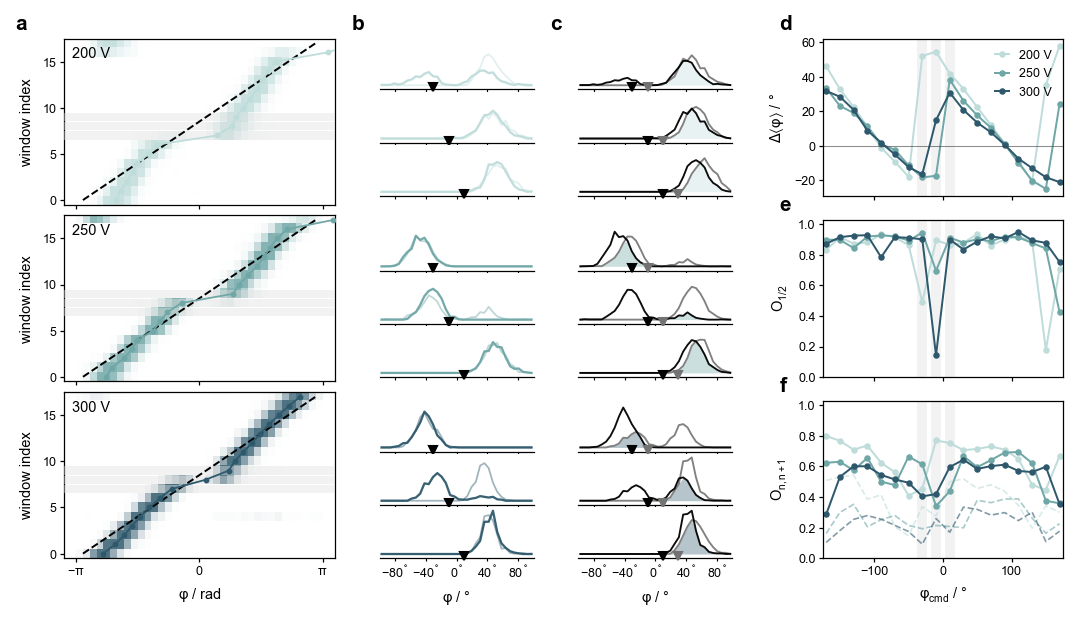

In [183]:
plot_exemplary_data_rotors(
    m_list=m_list,
    calibration_voltage_colors=calibration_voltage_colors,
    target_voltage_colors=target_voltage_colors,
    particle=None,
    rotor_index=3,
    rotor_class="target",
    voltage_order=(200, 250, 300),
    reference_voltage=300,
    center_phase="deg-80",
    example_phases=None,
    n_neighbor_windows=3,

    # Absolute-angle limits for column 2
    stationarity_hist_xlim_deg=(-100, 100),
    stationarity_hist_xticks_deg=(-80, -40, 0, 40, 80),

    # Absolute-angle limits for column 3
    neighbor_hist_xlim_deg=(-100, 100),
    neighbor_hist_xticks_deg=(-80, -40, 0, 40, 80),

    command_marker="v",
    command_marker_size=3.5,

    # Gap between columns 3 and 4
    metrics_column_gap=0.085,

    voltage_group_gap=0.040,
    selected_band_alpha=0.42,
    C=CK_colors,
    hist_bins=36,
    fig_width_mm=180,
    fig_height_mm=100,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=6,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig3a_voltage__exemplary_target_rotor_steering_connectivity",
    stator_variant=stator_variant,
)

#### iv. Plot summary statistics on stationarity and window overlap

In [29]:
def plot_umbrella_qc_histograms_from_measurements(
    m_list,
    voltage_layout="overlay",
    calibration_voltage_colors=None,
    target_voltage_colors=None,
    C=None,
    fig_width_mm=180,
    fig_height_mm=None,
    row_height_mm=42,
    horizontal_wspace=0.16,
    separate_rows_hspace=0.05,
    save_dir=None,
    save_prefix="umbrella_qc_histograms",
    stator_variant=None,
    delta_col=None,
    target_half_overlap_col="half_overlap",
    calib_half_overlap_col="half_overlap",
    neighbor_overlap_col="neighbor_overlap_mean",
    use_abs_delta=True,
    delta_bins=None,
    half_overlap_bins=None,
    neighbor_overlap_bins=None,
    half_overlap_nbins=50,
    neighbor_overlap_nbins=50,
    half_overlap_xlim=(0.5, 1.0),
    neighbor_overlap_xlim=(0.0, 1.0),
    threshold_delta_deg=10.0,
    threshold_half_overlap=0.80,
    threshold_neighbor_overlap=0.25,
    density=True,
    alpha=0.42,
    edge_lw=0.45,
    fontsize=8,
    axis_label_size=None,
    tick_label_size=None,
    title_size=None,
    annotation_size=None,
    legend_size=None,
    show_voltage_legend=True,
    dpi=300,
):
    """
    Plot umbrella-window QC histograms.

    voltage_layout
    --------------
    "overlay":
        All voltages are overlaid in one row.

    "separate_rows":
        One row per UMB measurement. Only the bottom row shows x-axis ticks,
        tick labels, and x-axis labels.

    Figure size
    -----------
    fig_width_mm:
        Total figure width.

    fig_height_mm:
        Total figure height. If None, the height is inferred from row_height_mm.

    Columns
    -------
    1) calibration O_1/2
    2) target-calibration steering mismatch |delta phi-tilde|
    3) target O_1/2
    4) target O_n,n+1

    Returns None.
    """

    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.lines import Line2D

    if C is None:
        raise ValueError("Pass C=CK_colors.")

    C = C() if callable(C) else dict(C)

    if calibration_voltage_colors is None:
        calibration_voltage_colors = {
            200: (238 / 255, 196 / 255, 105 / 255),
            250: (226 / 255, 172 / 255, 72 / 255),
            300: (198 / 255, 131 / 255, 41 / 255),
        }

    if target_voltage_colors is None:
        target_voltage_colors = {
            200: (190 / 255, 220 / 255, 218 / 255),
            250: (111 / 255, 166 / 255, 166 / 255),
            300: (46 / 255, 89 / 255, 108 / 255),
        }

    calibration_voltage_colors = {float(k): v for k, v in calibration_voltage_colors.items()}
    target_voltage_colors = {float(k): v for k, v in target_voltage_colors.items()}

    voltage_layout = str(voltage_layout).strip().lower()

    if voltage_layout not in {"overlay", "separate_rows"}:
        raise ValueError("voltage_layout must be 'overlay' or 'separate_rows'.")

    axis_label_size = fontsize if axis_label_size is None else axis_label_size
    tick_label_size = fontsize - 1 if tick_label_size is None else tick_label_size
    title_size = fontsize if title_size is None else title_size
    annotation_size = fontsize - 1.7 if annotation_size is None else annotation_size
    legend_size = fontsize - 1 if legend_size is None else legend_size

    black = C.get("black", (0, 0, 0))
    grey = C.get("grey", (0.35, 0.35, 0.35))
    lightgrey = C.get("lightgrey", (0.72, 0.72, 0.72))

    xlabel_half = r"$O_{1/2}$"
    xlabel_neighbor = r"$O_{n,n+1}$"
    xlabel_delta = r"$|\Delta\varphi\prime_n|$ / °"

    def mm_to_inch(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []

        if isinstance(obj, (list, tuple)):
            out = []

            for item in obj:
                out.extend(flatten(item))

            return out

        return [obj]

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def measurement_name(m, i=None):
        name = Path(path_string(m)).name

        return name if name else (f"m_list[{i}]" if i is not None else "unknown measurement")

    def is_umb(m):
        protocol = getattr(m, "protocol", None)

        if isinstance(protocol, dict):
            return any(isinstance(k, str) and k.lower().startswith("deg-") for k in protocol)

        filename = Path(path_string(m)).name.upper()

        return "UMB" in filename and "DIFF" not in filename

    def parse_voltage_from_name(name):
        hits = re.findall(r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])", str(name), flags=re.IGNORECASE)

        return float(hits[-1]) if hits else np.nan

    def voltage_label(voltage):
        if not np.isfinite(voltage):
            return "unknown"

        return f"{int(voltage)}V" if float(voltage).is_integer() else f"{float(voltage):g}V"

    def nearest_voltage_key(voltage, color_dict):
        if not np.isfinite(voltage) or len(color_dict) == 0:
            return None

        keys = np.asarray(sorted(color_dict), dtype=float)

        return float(keys[np.argmin(np.abs(keys - float(voltage)))])

    def voltage_color(voltage, rotor_class):
        color_dict = calibration_voltage_colors if str(rotor_class) == "calibration" else target_voltage_colors
        key = nearest_voltage_key(voltage, color_dict)

        return grey if key is None else color_dict[key]

    def color_luminance(color):
        r, g, b = np.asarray(color, dtype=float)[:3]

        return 0.2126 * r + 0.7152 * g + 0.0722 * b

    def overlay_order(prepared_rows, rotor_class):
        return sorted(prepared_rows, key=lambda row: color_luminance(voltage_color(row["voltage"], rotor_class)))

    def collect_measurements_with_qc(m_list):
        rows = []

        for source_index, m in enumerate(flatten(m_list)):
            if not is_umb(m):
                continue

            df = getattr(m, "voltage_stationarity_overlap_window_df", None)

            if not isinstance(df, pd.DataFrame) or len(df) == 0:
                continue

            d = df.copy()
            name = measurement_name(m, source_index)
            voltage = parse_voltage_from_name(name)

            if "measurement_index" not in d.columns:
                d["measurement_index"] = int(source_index)

            if "measurement_name" not in d.columns:
                d["measurement_name"] = name

            if "voltage" not in d.columns:
                d["voltage"] = voltage

            if "rotor_class" not in d.columns:
                if "ensemble" in d.columns:
                    d["rotor_class"] = d["ensemble"].astype(str)
                else:
                    raise KeyError(f"{name} needs a 'rotor_class' column or an older 'ensemble' column.")

            rows.append({
                "m": m,
                "source_index": int(source_index),
                "name": name,
                "voltage": float(voltage),
                "label": voltage_label(voltage),
                "df": d,
            })

        if not rows:
            raise ValueError(
                "No stored UMB QC tables found. "
                "Run compute_stationarity_overlap_target_rotors(...) first."
            )

        return sorted(
            rows,
            key=lambda row: (
                not np.isfinite(row["voltage"]),
                row["voltage"] if np.isfinite(row["voltage"]) else np.inf,
                row["source_index"],
            ),
        )

    def find_col(df, candidates, label):
        for col in candidates:
            if col is not None and col in df.columns:
                return col

        raise KeyError(
            f"Could not find the column for {label}.\n"
            f"Tried: {candidates}\n\n"
            f"Available columns:\n{list(df.columns)}"
        )

    def finite_values(df, col):
        x = pd.to_numeric(df[col], errors="coerce").to_numpy(float)

        return x[np.isfinite(x)]

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.60)
            spine.set_color(black)

        ax.tick_params(
            length=2.0,
            width=0.60,
            labelsize=tick_label_size,
            color=black,
            labelcolor=black,
            direction="out",
        )

        ax.grid(False)

    def draw_threshold(ax, threshold, threshold_kind):
        if threshold is None or not np.isfinite(threshold):
            return

        ax.axvline(float(threshold), color=grey, lw=0.8, ls=(0, (2.2, 1.6)), zorder=20)

        x0, x1 = ax.get_xlim()

        if threshold_kind == "below_good":
            ax.axvspan(x0, float(threshold), color=lightgrey, alpha=0.12, zorder=-20, linewidth=0)

        elif threshold_kind == "above_good":
            ax.axvspan(float(threshold), x1, color=lightgrey, alpha=0.12, zorder=-20, linewidth=0)

    def set_overlap_ticks(ax, xlim):
        if tuple(xlim) == (0.5, 1.0):
            ax.set_xticks([0.5, 0.75, 1.0])
            ax.set_xticklabels(["0.5", "0.75", "1"])

        elif tuple(xlim) == (0.0, 1.0):
            ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
            ax.set_xticklabels(["0", "", "0.5", "", "1"])

    def finish_hist_axis(
        ax,
        xlabel,
        threshold=None,
        threshold_kind=None,
        xlim=None,
        ylabel=None,
        show_xaxis=True,
    ):
        if xlim is not None:
            ax.set_xlim(*xlim)

        draw_threshold(ax, threshold, threshold_kind)

        if xlim is not None:
            set_overlap_ticks(ax, xlim)

        if show_xaxis:
            ax.set_xlabel(xlabel, fontsize=axis_label_size)
        else:
            ax.set_xlabel("")
            ax.tick_params(axis="x", which="both", bottom=False, top=False, labelbottom=False)

        if ylabel is not None:
            ax.set_ylabel(ylabel, fontsize=axis_label_size)
        else:
            ax.set_ylabel("")

        style_ax(ax)

    def draw_single_hist(ax, x, bins, color):
        ax.hist(
            x,
            bins=bins,
            density=bool(density),
            color=color,
            alpha=float(alpha),
            edgecolor=black,
            linewidth=float(edge_lw),
        )

    def draw_overlay_hist(ax, prepared_rows, value_key, bins, rotor_class):
        for row in overlay_order(prepared_rows, rotor_class):
            color = voltage_color(row["voltage"], rotor_class)

            ax.hist(
                row[value_key],
                bins=bins,
                density=bool(density),
                histtype="stepfilled",
                color=color,
                alpha=0.20,
                edgecolor=color,
                linewidth=float(edge_lw),
                label=row["label"],
            )

            ax.hist(
                row[value_key],
                bins=bins,
                density=bool(density),
                histtype="step",
                color=color,
                alpha=0.95,
                linewidth=max(0.70, float(edge_lw)),
            )

    rows = collect_measurements_with_qc(m_list)

    if half_overlap_bins is None:
        half_overlap_bins = np.linspace(
            float(half_overlap_xlim[0]),
            float(half_overlap_xlim[1]),
            int(half_overlap_nbins) + 1,
        )

    if neighbor_overlap_bins is None:
        neighbor_overlap_bins = np.linspace(
            float(neighbor_overlap_xlim[0]),
            float(neighbor_overlap_xlim[1]),
            int(neighbor_overlap_nbins) + 1,
        )

    prepared = []

    for row in rows:
        df = row["df"].copy()
        df["rotor_class"] = df["rotor_class"].astype(str)

        target_df = df[df["rotor_class"] == "target"].copy()
        calib_df = df[df["rotor_class"] == "calibration"].copy()

        if len(target_df) == 0 or len(calib_df) == 0:
            continue

        delta_col_use = find_col(
            target_df,
            [
                delta_col,
                "calib_target_error_deg",
                "delta_target_minus_calib_mean_phi_deg",
                "target_minus_calib_mean_phi_deg",
                "target_calib_error_deg",
            ],
            "target-calibration steering mismatch",
        )

        target_half_overlap_col_use = find_col(
            target_df,
            [target_half_overlap_col, "half_overlap", "O_half"],
            "target half-window overlap",
        )

        calib_half_overlap_col_use = find_col(
            calib_df,
            [calib_half_overlap_col, "half_overlap", "O_half"],
            "calibration half-window overlap",
        )

        neighbor_overlap_col_use = find_col(
            target_df,
            [
                neighbor_overlap_col,
                "neighbor_overlap_mean",
                "neighbor_overlap_min",
                "neighbor_overlap",
                "O_neighbor",
            ],
            "target neighboring-window overlap",
        )

        delta = finite_values(target_df, delta_col_use)
        delta_plot = np.abs(delta) if bool(use_abs_delta) else delta.copy()

        O_half_calib = finite_values(calib_df, calib_half_overlap_col_use)
        O_half_target = finite_values(target_df, target_half_overlap_col_use)
        O_neighbor_target = finite_values(target_df, neighbor_overlap_col_use)

        O_half_calib = O_half_calib[
            (O_half_calib >= float(half_overlap_xlim[0]))
            & (O_half_calib <= float(half_overlap_xlim[1]))
        ]

        O_half_target = O_half_target[
            (O_half_target >= float(half_overlap_xlim[0]))
            & (O_half_target <= float(half_overlap_xlim[1]))
        ]

        O_neighbor_target = O_neighbor_target[
            (O_neighbor_target >= float(neighbor_overlap_xlim[0]))
            & (O_neighbor_target <= float(neighbor_overlap_xlim[1]))
        ]

        if min(O_half_calib.size, O_half_target.size, O_neighbor_target.size, delta_plot.size) == 0:
            continue

        prepared.append({
            "label": row["label"],
            "name": row["name"],
            "voltage": row["voltage"],
            "target_df": target_df,
            "calib_df": calib_df,
            "O_half_calib": O_half_calib,
            "delta_plot": delta_plot,
            "O_half_target": O_half_target,
            "O_neighbor_target": O_neighbor_target,
        })

    if not prepared:
        raise ValueError("No UMB measurement had complete calibration and target QC values to plot.")

    if delta_bins is None:
        all_delta = np.concatenate([p["delta_plot"] for p in prepared])
        q98 = float(np.nanquantile(all_delta, 0.98))
        threshold_based = float(threshold_delta_deg) * 1.35 if threshold_delta_deg is not None else q98
        xmax = max(10.0, q98, threshold_based)

        if np.nanmax(all_delta) > 0:
            xmax = min(xmax, float(np.nanmax(all_delta)))

        xmax = max(xmax, 10.0)

        delta_bins = np.linspace(0.0, xmax, 41) if bool(use_abs_delta) else 40

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    ylabel = "density" if bool(density) else "counts"

    if voltage_layout == "overlay":
        fig_height_use = float(row_height_mm) if fig_height_mm is None else float(fig_height_mm)

        fig, axes = plt.subplots(
            1,
            4,
            figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_use)),
            squeeze=False,
            constrained_layout=False,
        )

        ax0, ax1, ax2, ax3 = axes[0]

        draw_overlay_hist(ax0, prepared, "O_half_calib", half_overlap_bins, "calibration")
        draw_overlay_hist(ax1, prepared, "delta_plot", delta_bins, "target")
        draw_overlay_hist(ax2, prepared, "O_half_target", half_overlap_bins, "target")
        draw_overlay_hist(ax3, prepared, "O_neighbor_target", neighbor_overlap_bins, "target")

        finish_hist_axis(
            ax0,
            xlabel=xlabel_half,
            threshold=threshold_half_overlap,
            threshold_kind="above_good",
            xlim=half_overlap_xlim,
            ylabel=ylabel,
        )

        finish_hist_axis(
            ax1,
            xlabel=xlabel_delta,
            threshold=threshold_delta_deg,
            threshold_kind="below_good",
            xlim=(0.0, max(delta_bins)) if bool(use_abs_delta) and np.ndim(delta_bins) > 0 else None,
        )

        finish_hist_axis(
            ax2,
            xlabel=xlabel_half,
            threshold=threshold_half_overlap,
            threshold_kind="above_good",
            xlim=half_overlap_xlim,
        )

        finish_hist_axis(
            ax3,
            xlabel=xlabel_neighbor,
            threshold=threshold_neighbor_overlap,
            threshold_kind="above_good",
            xlim=neighbor_overlap_xlim,
        )

        for ax in axes[0]:
            ax.set_yticks([])
            ax.tick_params(axis="y", length=0)

        axes[0, 0].set_title("calibration", fontsize=title_size, pad=3)
        axes[0, 1].set_title("target vs calibration", fontsize=title_size, pad=3)
        axes[0, 2].set_title("target", fontsize=title_size, pad=3)
        axes[0, 3].set_title("target", fontsize=title_size, pad=3)

        if show_voltage_legend:
            voltages = sorted({float(p["voltage"]) for p in prepared if np.isfinite(p["voltage"])})

            calibration_handles = [
                Line2D([0], [0], color=voltage_color(v, "calibration"), lw=4, label=voltage_label(v))
                for v in voltages
            ]

            target_handles = [
                Line2D([0], [0], color=voltage_color(v, "target"), lw=4, label=voltage_label(v))
                for v in voltages
            ]

            axes[0, 0].legend(
                handles=calibration_handles,
                title="bias voltage",
                frameon=False,
                fontsize=legend_size,
                title_fontsize=legend_size,
                loc="upper left",
            )

            axes[0, 2].legend(
                handles=target_handles,
                title="bias voltage",
                frameon=False,
                fontsize=legend_size,
                title_fontsize=legend_size,
                loc="upper left",
            )

        fig.subplots_adjust(
            left=0.055,
            right=0.990,
            bottom=0.19,
            top=0.88,
            wspace=float(horizontal_wspace),
        )

    else:
        nrows = len(prepared)
        fig_height_use = float(row_height_mm) * nrows if fig_height_mm is None else float(fig_height_mm)

        fig, axes = plt.subplots(
            nrows,
            4,
            figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_use)),
            squeeze=False,
            constrained_layout=False,
        )

        for r, p in enumerate(prepared):
            ax0, ax1, ax2, ax3 = axes[r]
            is_bottom_row = r == nrows - 1

            draw_single_hist(ax0, p["O_half_calib"], half_overlap_bins, voltage_color(p["voltage"], "calibration"))
            draw_single_hist(ax1, p["delta_plot"], delta_bins, voltage_color(p["voltage"], "target"))
            draw_single_hist(ax2, p["O_half_target"], half_overlap_bins, voltage_color(p["voltage"], "target"))
            draw_single_hist(ax3, p["O_neighbor_target"], neighbor_overlap_bins, voltage_color(p["voltage"], "target"))

            finish_hist_axis(
                ax0,
                xlabel=xlabel_half,
                threshold=threshold_half_overlap,
                threshold_kind="above_good",
                xlim=half_overlap_xlim,
                ylabel=ylabel,
                show_xaxis=is_bottom_row,
            )

            finish_hist_axis(
                ax1,
                xlabel=xlabel_delta,
                threshold=threshold_delta_deg,
                threshold_kind="below_good",
                xlim=(0.0, max(delta_bins)) if bool(use_abs_delta) and np.ndim(delta_bins) > 0 else None,
                show_xaxis=is_bottom_row,
            )

            finish_hist_axis(
                ax2,
                xlabel=xlabel_half,
                threshold=threshold_half_overlap,
                threshold_kind="above_good",
                xlim=half_overlap_xlim,
                show_xaxis=is_bottom_row,
            )

            finish_hist_axis(
                ax3,
                xlabel=xlabel_neighbor,
                threshold=threshold_neighbor_overlap,
                threshold_kind="above_good",
                xlim=neighbor_overlap_xlim,
                show_xaxis=is_bottom_row,
            )

            for ax in axes[r]:
                ax.set_yticks([])
                ax.tick_params(axis="y", length=0)

            n_target_particles = p["target_df"]["particle"].nunique() if "particle" in p["target_df"].columns else np.nan
            n_calib_particles = p["calib_df"]["particle"].nunique() if "particle" in p["calib_df"].columns else np.nan

            txt = (
                f"{p['label']}\n"
                f"calib.: {int(n_calib_particles)} particles, {len(p['calib_df'])} windows\n"
                f"target: {int(n_target_particles)} particles, {len(p['target_df'])} windows"
            )

            ax0.text(
                0.02,
                0.98,
                txt,
                transform=ax0.transAxes,
                ha="left",
                va="top",
                fontsize=annotation_size,
                color=grey,
            )

        axes[0, 0].set_title("calibration", fontsize=title_size, pad=3)
        axes[0, 1].set_title("target vs calibration", fontsize=title_size, pad=3)
        axes[0, 2].set_title("target", fontsize=title_size, pad=3)
        axes[0, 3].set_title("target", fontsize=title_size, pad=3)

        fig.subplots_adjust(
            left=0.055,
            right=0.990,
            bottom=0.085,
            top=0.965,
            wspace=float(horizontal_wspace),
            hspace=float(separate_rows_hspace),
        )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        prefix = (
            f"{stator_variant}__{save_prefix}"
            if stator_variant is not None and str(stator_variant).strip()
            else save_prefix
        )

        fig.savefig(save_dir / f"{prefix}.png", dpi=int(dpi), bbox_inches="tight")
        fig.savefig(save_dir / f"{prefix}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None

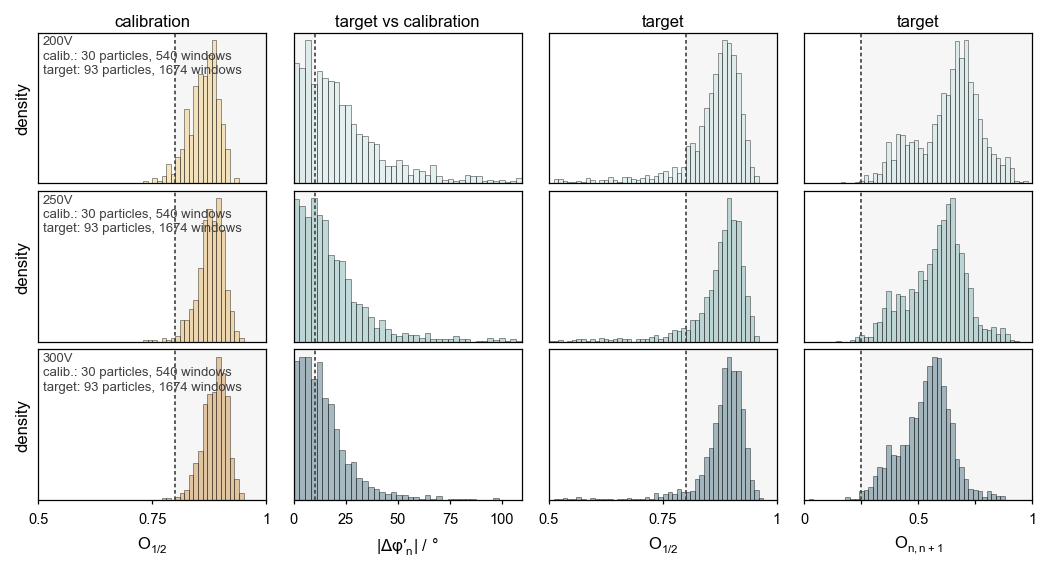

In [30]:
# plot_umbrella_qc_histograms_from_measurements(
#     m_list=m_list,
#     voltage_layout="separate_rows",
#     calibration_voltage_colors=calibration_voltage_colors,
#     target_voltage_colors=target_voltage_colors,
#     fig_width_mm=180,
#     fig_height_mm=90,
#     horizontal_wspace=0.12,
#     separate_rows_hspace=0.05,
#     half_overlap_xlim=(0.5, 1.0),
#     half_overlap_nbins=50,
#     neighbor_overlap_xlim=(0.0, 1.0),
#     neighbor_overlap_nbins=50,
#     C=CK_colors,
#     fontsize=8,
#     axis_label_size=8,
#     tick_label_size=7,
#     title_size=8,
#     annotation_size=6.3,
#     save_dir=save_dir_SI,
#     save_prefix="SI_toFig3a_voltage__comparison_different_umbrella_measurements",
# )

## SI | Calibration rotor metrics

In [31]:
def plot_calibration_bias_metric_convergence_heatmaps(
    m_list,
    durations_s=(1, 2, 3, 4, 5),
    example_window_deg=None,
    example_particles=None,
    example_xlim_deg=55,
    fig_width_mm=180,
    row_height_mm=62,
    save_dir=None,
    save_prefix="SI_calibration_bias_metric_convergence_heatmaps",
    stator_variant=None,
    C=CK_colors,
):
    """
    Per-UMB calibration-bias convergence diagnostic.

    For each UMB measurement, make one row block containing:
        1) three exemplary calibration-rotor distributions at one chosen window
        2) heatmap of median |Delta phi_i| / deg
        3) heatmap of median kappa_i / (k_B T rad^-2)
        4) heatmap of median O_{n,n+1}

    No pooling across UMBs in the heatmaps.
    Nothing is stored on m.
    Nothing is returned.
    Saves only if save_dir is not None.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    particle_col = "group"
    phi_col = "phi"
    phi0_offset_rad = -np.pi / 2
    min_locs_per_window = 20
    overlap_bins = 72
    density_bins_internal = 96
    dpi = 300

    C = C() if callable(C) else dict(C)

    black = C["black"]
    lightgrey = C["lightgrey"]
    warmgold = C["warmgold"]
    beige = C["beige"]

    durations_s = tuple(float(d) for d in durations_s)
    dur_sorted = sorted(durations_s)

    duration_colors = {}
    n_dur = max(1, len(dur_sorted) - 1)
    for i, d in enumerate(dur_sorted):
        f = i / n_dur if n_dur > 0 else 1.0
        c0 = np.array(beige[:3])
        c1 = np.array(warmgold[:3])
        duration_colors[d] = tuple((1 - f) * c0 + f * c1)

    def mm(x):
        return float(x) / 25.4

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == "":
            return str(name)
        return f"{str(stator_variant).strip()}__{name}"

    def style_ax(ax, labelsize=7):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=labelsize,
            color=black,
            labelcolor=black,
        )

        ax.xaxis.label.set_color(black)
        ax.yaxis.label.set_color(black)
        ax.title.set_color(black)

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for x in obj:
                out.extend(flatten(x))
            return out
        return [obj]

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown"

    def short_measurement_label(m, i=None):
        name = measurement_name(m, i)
        base = Path(name).stem
        return base if len(base) <= 50 else base[:50] + "..."

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()

        if "DIFF" in name and "UMB" not in name:
            return False

        if "UMB" in name:
            return True

        if hasattr(m, "protocol") and isinstance(m.protocol, dict):
            return any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol)

        return False

    def protocol_bounds(value):
        while (
            isinstance(value, (tuple, list))
            and len(value) == 1
            and isinstance(value[0], (tuple, list, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def iter_deg_windows(m):
        out = []

        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return out

        for key, val in m.protocol.items():
            if not isinstance(key, str) or not key.startswith("deg-"):
                continue

            try:
                deg = float(key.split("-")[1].split("_")[0]) % 360.0
                t0, t1 = protocol_bounds(val)
                phi0 = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))
                out.append((str(key), float(deg), phi0, float(t0), float(t1)))
            except Exception:
                continue

        out.sort(key=lambda x: x[1])
        return out

    def prepare_locs(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError(f"{measurement_name(m)} has no m.locs.")

        locs = m.locs.copy()

        if particle_col not in locs.columns:
            if "group_int" in locs.columns:
                locs[particle_col] = locs["group_int"].astype(int)
            else:
                raise KeyError(f"{measurement_name(m)} needs 'group' or 'group_int'.")

        if "t" not in locs.columns:
            if "averagetime" in locs.columns:
                locs["t"] = locs["averagetime"].astype(float)
            elif "time" in locs.columns:
                locs["t"] = locs["time"].astype(float)
            elif "time_s" in locs.columns:
                locs["t"] = locs["time_s"].astype(float)
            elif "frame" in locs.columns and hasattr(m, "_average_tpf"):
                locs["t"] = locs["frame"].astype(float) * float(m._average_tpf)
            elif "frame" in locs.columns:
                locs["t"] = locs["frame"].astype(float) * 0.005
            else:
                raise KeyError(f"{measurement_name(m)} needs t, averagetime, time, time_s, or frame.")

        if phi_col not in locs.columns:
            raise KeyError(f"{measurement_name(m)} needs phi column {phi_col!r}.")

        locs = locs[[particle_col, phi_col, "t"]].dropna().copy()
        locs[particle_col] = locs[particle_col].astype(int)
        locs = locs.sort_values([particle_col, "t"])

        return locs

    def as_int_list(x):
        if x is None:
            return []
        if isinstance(x, (str, bytes)):
            return []
        try:
            return sorted(set(int(v) for v in list(x)))
        except Exception:
            try:
                return [int(x)]
            except Exception:
                return []

    def get_calibration_particles(m):
        vals = as_int_list(getattr(m, "calibration_rotors", None))

        if len(vals) == 0:
            raise ValueError(
                f"{measurement_name(m)}: no calibration rotors found. "
                "Expected m.calibration_rotors."
            )

        return sorted(set(vals))

    def circ_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))
        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def circ_resultant(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        return float(np.abs(np.mean(np.exp(1j * phi))))

    def circ_std(phi):
        R = circ_resultant(phi)

        if not np.isfinite(R) or R <= 0:
            return np.nan

        return float(np.sqrt(max(0.0, -2.0 * np.log(R))))

    def overlap_coefficient(a, b, bins):
        a = np.asarray(a, dtype=float)
        b = np.asarray(b, dtype=float)

        a = a[np.isfinite(a)]
        b = b[np.isfinite(b)]

        if a.size < 5 or b.size < 5:
            return np.nan

        ha, edges = np.histogram(a, bins=bins, density=True)
        hb, _ = np.histogram(b, bins=bins, density=True)

        d = float(edges[1] - edges[0])

        return float(np.sum(np.minimum(ha, hb)) * d)

    def hist_density(vals, bins):
        vals = np.asarray(vals, dtype=float)
        vals = vals[np.isfinite(vals)]

        centers = 0.5 * (bins[:-1] + bins[1:])

        if vals.size < 3:
            return centers, np.full_like(centers, np.nan, dtype=float)

        h, edges = np.histogram(vals, bins=bins, density=True)
        centers = 0.5 * (edges[:-1] + edges[1:])

        return centers, h

    def get_actual_limits(arr, qlo=5, qhi=95, pad_frac=0.06, min_pad=1e-6):
        arr = np.asarray(arr, dtype=float)
        finite = arr[np.isfinite(arr)]

        if finite.size == 0:
            return 0.0, 1.0

        vmin = float(np.nanpercentile(finite, qlo))
        vmax = float(np.nanpercentile(finite, qhi))

        if not np.isfinite(vmin) or not np.isfinite(vmax):
            vmin = float(np.nanmin(finite))
            vmax = float(np.nanmax(finite))

        if vmax < vmin:
            vmin, vmax = vmax, vmin

        if np.isclose(vmax, vmin):
            pad = max(abs(vmin) * pad_frac, min_pad)
            return vmin - pad, vmax + pad

        pad = max((vmax - vmin) * pad_frac, min_pad)
        return vmin - pad, vmax + pad

    m_flat = flatten(m_list)
    m_umbs = [(i, m) for i, m in enumerate(m_flat) if is_umb(m)]

    if len(m_umbs) == 0:
        raise ValueError("No UMB-like measurements found.")

    all_rows = []
    all_overlap_rows = []
    example_density_rows = []
    measurement_meta = []

    bins_density = np.linspace(-np.pi, np.pi, density_bins_internal + 1)
    bins_overlap = np.linspace(-np.pi, np.pi, overlap_bins + 1)

    for umb_order, (mi, m) in enumerate(m_umbs):
        name = measurement_name(m, mi)
        label = short_measurement_label(m, mi)
        windows = iter_deg_windows(m)

        if len(windows) == 0:
            continue

        cal_particles = get_calibration_particles(m)
        locs = prepare_locs(m)
        locs = locs[locs[particle_col].isin(cal_particles)].copy()

        if len(locs) == 0:
            continue

        if example_window_deg is None:
            this_example_window_deg = float(windows[len(windows) // 4][1])
        else:
            this_example_window_deg = float(example_window_deg)

        this_example_window = min(
            windows,
            key=lambda w: abs(float(w[1]) - float(this_example_window_deg)),
        )
        _, this_example_window_deg, _, _, _ = this_example_window
        this_example_window_deg = float(this_example_window_deg)

        if example_particles is None:
            this_example_particles = cal_particles[:3]
        else:
            requested = [int(p) for p in example_particles]
            valid = [p for p in requested if p in set(cal_particles)]
            this_example_particles = valid[:3]

            if len(this_example_particles) < 3:
                remaining = [p for p in cal_particles if p not in set(this_example_particles)]
                this_example_particles += remaining[:3 - len(this_example_particles)]

        if len(this_example_particles) < 3:
            raise ValueError(
                f"{name}: need at least 3 calibration rotors for the example panels."
            )

        particle_cache = {}

        for pid, g in locs.groupby(particle_col, sort=False):
            pid = int(pid)
            particle_cache[pid] = {
                "t": g["t"].to_numpy(float),
                "phi": wrap_pi(g[phi_col].to_numpy(float)),
            }

        measurement_meta.append({
            "measurement_index": int(mi),
            "umb_order": int(umb_order),
            "measurement_name": str(name),
            "measurement_label": str(label),
            "example_window_deg": float(this_example_window_deg),
            "example_particles": list(this_example_particles),
        })

        for duration_s in dur_sorted:
            pooled_abs_by_deg = {}

            for phase, deg, phi0, t0, t1_full in windows:
                t1 = min(float(t1_full), float(t0) + float(duration_s))
                pooled_abs = []

                for pid in cal_particles:
                    pid = int(pid)

                    if pid not in particle_cache:
                        continue

                    t_all = particle_cache[pid]["t"]
                    phi_all = particle_cache[pid]["phi"]

                    i0 = np.searchsorted(t_all, float(t0), side="left")
                    i1 = np.searchsorted(t_all, float(t1), side="left")

                    if i1 <= i0:
                        continue

                    phi = phi_all[i0:i1]
                    n = int(phi.size)

                    if n < min_locs_per_window:
                        continue

                    psi_cmd = wrap_pi(phi - phi0)
                    mu = circ_mean(psi_cmd)

                    center_error_deg = float(np.rad2deg(mu)) if np.isfinite(mu) else np.nan
                    psi_centered = wrap_pi(psi_cmd - mu) if np.isfinite(mu) else psi_cmd.copy()

                    var_centered = float(np.nanvar(psi_centered))
                    kappa = (
                        float(1.0 / var_centered)
                        if np.isfinite(var_centered) and var_centered > 1e-12
                        else np.nan
                    )

                    all_rows.append({
                        "measurement_index": int(mi),
                        "umb_order": int(umb_order),
                        "measurement_name": str(name),
                        "measurement_label": str(label),
                        "duration_s": float(duration_s),
                        "particle": int(pid),
                        "phase": str(phase),
                        "deg": float(deg),
                        "n_locs": int(n),
                        "abs_center_error_deg": float(abs(center_error_deg)) if np.isfinite(center_error_deg) else np.nan,
                        "kappa_theta_over_kBT_rad2": float(kappa),
                        "circular_std_rad": float(circ_std(psi_centered)),
                    })

                    pooled_abs.append(wrap_pi(psi_centered + np.deg2rad(deg)))

                    if (
                        int(pid) in set(this_example_particles)
                        and abs(float(deg) - float(this_example_window_deg)) < 1e-9
                    ):
                        centers, dens = hist_density(psi_cmd, bins_density)
                        for xval, yval in zip(centers, dens):
                            example_density_rows.append({
                                "measurement_index": int(mi),
                                "particle": int(pid),
                                "duration_s": float(duration_s),
                                "x_rad": float(xval),
                                "density": float(yval),
                            })

                if len(pooled_abs):
                    pooled_abs_by_deg[float(deg)] = np.concatenate(pooled_abs)

            degs = sorted(pooled_abs_by_deg.keys())

            for jj, deg_a in enumerate(degs):
                deg_b = degs[(jj + 1) % len(degs)]

                ov = overlap_coefficient(
                    pooled_abs_by_deg[deg_a],
                    pooled_abs_by_deg[deg_b],
                    bins_overlap,
                )

                all_overlap_rows.append({
                    "measurement_index": int(mi),
                    "umb_order": int(umb_order),
                    "measurement_name": str(name),
                    "measurement_label": str(label),
                    "duration_s": float(duration_s),
                    "deg": float(deg_a),
                    "deg_next": float(deg_b),
                    "neighbor_overlap": float(ov),
                })

    df = pd.DataFrame(all_rows)
    overlap_df = pd.DataFrame(all_overlap_rows)
    example_density_df = pd.DataFrame(example_density_rows)
    meta_df = pd.DataFrame(measurement_meta)

    if len(df) == 0:
        raise ValueError("No calibration convergence rows computed.")

    n_umb = len(meta_df)
    fig_height_mm = float(row_height_mm) * float(n_umb)

    cmap = LinearSegmentedColormap.from_list(
        "white_to_gold",
        [(1, 1, 1), tuple(warmgold[:3])],
        N=256,
    )

    fig = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))

    outer = fig.add_gridspec(
        n_umb,
        4,
        left=0.05,
        right=0.985,
        bottom=0.04,
        top=0.985,
        wspace=0.45,
        hspace=0.34,
        width_ratios=[1.18, 1.0, 1.0, 1.0],
    )

    def draw_heatmap(ax, pivot_df, ylabel, cbar_label, panel_title):
        arr = pivot_df.to_numpy(dtype=float)

        if arr.size == 0:
            ax.axis("off")
            return

        vmin, vmax = get_actual_limits(arr, qlo=5, qhi=95, pad_frac=0.06)

        im = ax.imshow(
            arr,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
        )

        ax.set_xticks(np.arange(len(pivot_df.columns)))
        ax.set_xticklabels([f"{x:g}" for x in pivot_df.columns], fontsize=6.5)
        ax.set_xlabel("time per window / s", fontsize=7)

        yvals = list(pivot_df.index)
        ax.set_yticks(np.arange(len(yvals)))
        ax.set_yticklabels([f"{float(y):.0f}" for y in yvals], fontsize=6.5)
        ax.set_ylabel(ylabel, fontsize=7)

        ax.set_title(panel_title, fontsize=7, pad=4)

        cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
        cbar.ax.tick_params(labelsize=6, width=0.6, length=2)
        cbar.set_label(cbar_label, fontsize=7)

        style_ax(ax, labelsize=6.5)

    for row_i, meta in meta_df.sort_values("umb_order").reset_index(drop=True).iterrows():
        mi = int(meta["measurement_index"])
        label = str(meta["measurement_label"])
        ex_window_deg = float(meta["example_window_deg"])
        ex_particles = list(meta["example_particles"])

        example_gs = outer[row_i, 0].subgridspec(3, 1, hspace=0.10)
        ax_ex_list = [fig.add_subplot(example_gs[k, 0]) for k in range(3)]
        ax_err = fig.add_subplot(outer[row_i, 1])
        ax_kappa = fig.add_subplot(outer[row_i, 2])
        ax_ov = fig.add_subplot(outer[row_i, 3])

        xlim_rad = np.deg2rad(float(example_xlim_deg))

        ymax = 0.0
        for k, pid in enumerate(ex_particles[:3]):
            ax = ax_ex_list[k]
            subp = example_density_df[
                (example_density_df["measurement_index"].astype(int) == int(mi))
                & (example_density_df["particle"].astype(int) == int(pid))
            ].copy()

            for d in dur_sorted:
                s = subp[np.isclose(subp["duration_s"].astype(float), float(d))]
                if len(s) == 0:
                    continue

                ax.plot(
                    s["x_rad"],
                    s["density"],
                    color=duration_colors[d],
                    lw=1.05,
                    alpha=0.95,
                    label=f"{d:g} s",
                )

            ax.axvline(0, color=lightgrey, lw=0.7, zorder=0)
            ax.set_xlim(-xlim_rad, xlim_rad)

            tick = np.pi / 4
            if example_xlim_deg <= 35:
                tick = np.pi / 6
            if example_xlim_deg <= 25:
                tick = np.pi / 9

            ax.set_xticks([-tick, 0, tick])

            if np.isclose(tick, np.pi / 4):
                ticklabels = [r"$-\pi/4$", r"$0$", r"$\pi/4$"]
            elif np.isclose(tick, np.pi / 6):
                ticklabels = [r"$-\pi/6$", r"$0$", r"$\pi/6$"]
            elif np.isclose(tick, np.pi / 9):
                ticklabels = [r"$-\pi/9$", r"$0$", r"$\pi/9$"]
            else:
                ticklabels = [f"{-tick:.2f}", "0", f"{tick:.2f}"]

            if k == 2:
                ax.set_xticklabels(ticklabels, fontsize=6.5)
                ax.set_xlabel(r"$\Delta \varphi_i$ / rad", fontsize=7)
            else:
                ax.set_xticklabels([])

            ax.set_ylabel("density", fontsize=7)
            ax.set_title(f"p={pid}", fontsize=6.5, pad=2)

            if k == 0:
                ax.text(
                    0.0,
                    1.14,
                    f"{label}\nexample window {ex_window_deg:.0f}°",
                    transform=ax.transAxes,
                    ha="left",
                    va="bottom",
                    fontsize=7,
                    color=black,
                )
                ax.legend(
                    frameon=False,
                    fontsize=5.3,
                    title="used/window",
                    title_fontsize=5.7,
                    loc="upper right",
                    handlelength=1.1,
                    borderpad=0.1,
                    labelspacing=0.15,
                )

            style_ax(ax, labelsize=6)
            ymax = max(ymax, ax.get_ylim()[1])

        for ax in ax_ex_list:
            ax.set_ylim(0, ymax)

        sub_df = df[df["measurement_index"].astype(int) == int(mi)].copy()
        sub_ov_df = overlap_df[overlap_df["measurement_index"].astype(int) == int(mi)].copy()

        err_heat_df = (
            sub_df.groupby(["deg", "duration_s"], as_index=False)
                  .agg(value=("abs_center_error_deg", "median"))
        )
        kappa_heat_df = (
            sub_df.groupby(["deg", "duration_s"], as_index=False)
                  .agg(value=("kappa_theta_over_kBT_rad2", "median"))
        )
        overlap_heat_df = (
            sub_ov_df.groupby(["deg", "duration_s"], as_index=False)
                     .agg(value=("neighbor_overlap", "median"))
        )

        all_degs = sorted(set(err_heat_df["deg"].astype(float)).union(set(kappa_heat_df["deg"].astype(float))))
        all_degs_ov = sorted(set(overlap_heat_df["deg"].astype(float)))

        err_pivot = (
            err_heat_df.pivot(index="deg", columns="duration_s", values="value")
            .reindex(index=all_degs, columns=dur_sorted)
        )
        kappa_pivot = (
            kappa_heat_df.pivot(index="deg", columns="duration_s", values="value")
            .reindex(index=all_degs, columns=dur_sorted)
        )
        overlap_pivot = (
            overlap_heat_df.pivot(index="deg", columns="duration_s", values="value")
            .reindex(index=all_degs_ov, columns=dur_sorted)
        )

        draw_heatmap(
            ax=ax_err,
            pivot_df=err_pivot,
            ylabel=r"$\mathrm{\varphi}_\mathrm{cmd}$ / °",
            cbar_label=r"median $|\Delta \varphi_i|$ / °",
            panel_title=r"$|\Delta \varphi_i|$ / °",
        )
        draw_heatmap(
            ax=ax_kappa,
            pivot_df=kappa_pivot,
            ylabel=r"$\mathrm{\varphi}_\mathrm{cmd}$ / °",
            cbar_label=r"median $\kappa_i$ / $k_\mathrm{B}T$ rad$^{-2}$",
            panel_title=r"$\kappa_i$ / $k_\mathrm{B}T$ rad$^{-2}$",
        )
        draw_heatmap(
            ax=ax_ov,
            pivot_df=overlap_pivot,
            ylabel=r"$\mathrm{\varphi}_\mathrm{cmd}$ / °",
            cbar_label=r"median $O_{n,n+1}$",
            panel_title=r"$O_{n,n+1}$",
        )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        out = prefixed_name(save_prefix)
        fig.savefig(save_dir / f"{out}.png", dpi=dpi, bbox_inches="tight")
        fig.savefig(save_dir / f"{out}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None

#### i. Plot overview of calibration rotor metrics during umbrella sampling

In [32]:
# if full_execution:
#     plot_calibration_bias_metric_convergence_heatmaps(
#         m_list=m_list,
#         durations_s=(1, 2, 3, 4, 5),
#         example_window_deg=80,
#         example_particles=None,
#         example_xlim_deg=55,
#         fig_width_mm=180,
#         row_height_mm=62,
#         save_dir=save_dir,
#         save_prefix="SI_calibration_bias_metric_convergence_heatmaps",
#         stator_variant=stator_variant if "stator_variant" in globals() else None,
#         C=CK_colors,
#     )

## Reconstruction based on reliable calibration rotors via MBAR

#### i. MBAR based reconstruction for all target rotors

In [33]:
def run_MBAR_reconstruction(
    m_list,
    nbins=72,
    kappa_mode='by_angle',
    bias_potential='cosine',
    center_mode='ensemble',
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    pmin_nan=1e-12,
    min_keep=200,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-07,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    """
    Lean MBAR reconstruction using the calibration already stored by
    filter_calibration_rotors(...).

    Reads
    -----
    m.calibration_rotors
    m.target_rotors
    m.kappa_calibration_by_window
    m.autocorrelation_trim_s
    m.locs
    m.protocol

    Uses from m.kappa_calibration_by_window
    ---------------------------------------
    kappa:
        stored per-calibration-rotor/per-window kappa estimate

    mu_fit:
        stored fitted center in the original m.locs angular coordinate;
        used to calculate the ensemble umbrella center

    The calibration trajectories are therefore not reprocessed to estimate
    kappa or umbrella centers.

    Reconstructs
    ------------
    All rotors in:
        m.calibration_rotors
        m.target_rotors

    Kappa scaling
    -------------
    calibration rotor:
        stored calibrated kappa * kappa_rescale_calibration

    target rotor:
        stored calibrated kappa * kappa_rescale_target

    Stores
    ------
    m.reconstructed_energy_landscapes_by_center
    m.reconstructed_energy_landscapes_by_bias
    m.reconstructed_energy_landscapes

    m.energy_landscapes
    m.energy_landscapes_meta

    m.kappa_bias
    m.center_bias

    Notes
    -----
    - Progress bars are always shown.
    - Nothing is returned.
    - No summary/status DataFrame is generated.
    - MBAR is unbinned internally.
    - nbins controls only the final angular representation.
    """
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    particle_col = 'group'
    phi0_offset_rad = -np.pi / 2
    edges_cache = {}

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def as_int_list(values):
        if values is None:
            return []
        if isinstance(values, (str, bytes)):
            return []
        try:
            return sorted(set((int(v) for v in list(values))))
        except Exception:
            try:
                return [int(values)]
            except Exception:
                return []

    def measurement_name(m, index=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f'm_list[{index}]' if index is not None else 'unknown measurement'

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)
        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])
        return U

    def logsumexp(a, axis=None):
        a = np.asarray(a, dtype=float)
        amax = np.max(a, axis=axis, keepdims=True)
        out = amax + np.log(np.sum(np.exp(a - amax), axis=axis, keepdims=True))
        if axis is not None:
            out = np.squeeze(out, axis=axis)
        return out

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if phi.size == 0:
            return np.nan
        z = np.mean(np.exp(1j * phi))
        if np.abs(z) < 1e-15:
            return np.nan
        return float(np.angle(z))

    def circular_std(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if phi.size < 2:
            return np.nan
        R = np.abs(np.mean(np.exp(1j * phi)))
        R = np.clip(R, 1e-15, 1.0)
        return float(np.sqrt(-2.0 * np.log(R)))

    def circular_rolling_nanmean(values, window):
        values = np.asarray(values, dtype=float)
        if values.size == 0:
            return values.copy()
        window = int(window)
        if window <= 1:
            return values.copy()
        if window % 2 == 0:
            window += 1
        half = window // 2
        out = np.full(values.size, np.nan, dtype=float)
        for i in range(values.size):
            idx = [(i + shift) % values.size for shift in range(-half, half + 1)]
            local = values[idx]
            local = local[np.isfinite(local)]
            if local.size:
                out[i] = float(np.mean(local))
        return out

    def bias_names(value):
        value = str(value).lower()
        if value == 'cosine':
            return ['cosine']
        if value == 'harmonic':
            return ['harmonic']
        if value == 'both':
            return ['harmonic', 'cosine']
        raise ValueError("bias_potential must be 'cosine', 'harmonic', or 'both'.")

    def center_names(value):
        value = str(value).lower()
        if value == 'command':
            return ['command']
        if value == 'ensemble':
            return ['ensemble']
        if value == 'both':
            return ['command', 'ensemble']
        raise ValueError("center_mode must be 'command', 'ensemble', or 'both'.")

    def has_deg_protocol(m):
        return (
            hasattr(m, 'protocol')
            and isinstance(m.protocol, dict)
            and any((isinstance(key, str) and key.startswith('deg-') for key in m.protocol))
        )

    def is_umb(m):
        name = str(getattr(m, 'path', '')).upper()
        if 'DIFF' in name:
            return False
        if 'UMB' in name:
            return True
        return has_deg_protocol(m)

    def ensure_time_column(m):
        if not hasattr(m, 'locs') or m.locs is None:
            raise ValueError('m.locs is missing.')
        if 't' in m.locs.columns:
            return
        m.locs = m.locs.copy()
        if 'averagetime' in m.locs.columns:
            m.locs['t'] = m.locs['averagetime'].astype(float)
            return
        if 'time' in m.locs.columns:
            m.locs['t'] = m.locs['time'].astype(float)
            return
        if 'time_s' in m.locs.columns:
            m.locs['t'] = m.locs['time_s'].astype(float)
            return
        if 'frame' not in m.locs.columns:
            raise ValueError("m.locs needs 't', 'averagetime', 'time', 'time_s', or 'frame'.")
        dt = float(getattr(m, '_average_tpf', 0.005))
        m.locs['t'] = m.locs['frame'].astype(float) * dt

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]
        if isinstance(value, dict):
            start = value.get('start', value.get('start_time', value.get('t_start', value.get('t0', None))))
            stop = value.get(
                'end', value.get('end_time', value.get('t_end', value.get('t1', value.get('stop', None))))
            )
            if start is None or stop is None:
                raise ValueError(f'Cannot parse protocol bounds from {value}.')
            return (float(start), float(stop))
        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return (float(value[0]), float(value[1]))
        raise ValueError(f'Cannot parse protocol bounds from {value}.')

    def phase_deg(phase):
        return float(str(phase).split('-')[1].split('_')[0])

    def protocol_windows(m):
        if not has_deg_protocol(m):
            raise ValueError('No deg-* windows found in m.protocol.')
        rows = []
        for phase, bounds in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith('deg-'):
                continue
            try:
                deg = phase_deg(phase)
                start, stop = protocol_bounds(bounds)
            except Exception:
                continue
            command_phi0 = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))
            rows.append(
                {
                    'phase': str(phase),
                    'deg': float(deg),
                    'command_phi0': command_phi0,
                    'start': float(start),
                    'stop': float(stop),
                }
            )
        if len(rows) == 0:
            raise ValueError('No valid deg-* windows could be parsed.')
        return pd.DataFrame(rows).sort_values('command_phi0').reset_index(drop=True)

    def get_column(df, candidates):
        for column in candidates:
            if column in df.columns:
                return column
        raise KeyError(
            f'Could not find any of these columns: {candidates}\nAvailable columns:\n{list(df.columns)}'
        )

    def build_stored_calibration(m, calibration_rotors):
        stored = getattr(m, 'kappa_calibration_by_window', None)
        if not isinstance(stored, pd.DataFrame) or len(stored) == 0:
            raise ValueError(
                'm.kappa_calibration_by_window is missing or empty. Run filter_calibration_rotors(...) first.'
            )
        df = stored.copy()
        particle_col_stored = get_column(df, ['particle'])
        phase_col = get_column(df, ['phase'])
        kappa_col = get_column(df, ['kappa', 'kappa_vm', 'kappa_theta_over_kBT_rad2'])
        raw_center_col = get_column(df, ['mu_fit', 'mu_fit_rad'])
        calibration_set = set(map(int, calibration_rotors))
        df = df[df[particle_col_stored].astype(int).isin(calibration_set)].copy()
        if len(df) == 0:
            raise ValueError('None of m.calibration_rotors are present in m.kappa_calibration_by_window.')
        protocol_df = protocol_windows(m)
        rows = []
        for protocol_row in protocol_df.itertuples():
            phase = str(protocol_row.phase)
            g = df[df[phase_col].astype(str) == phase].copy()
            kappa = g[kappa_col].to_numpy(float)
            kappa = kappa[np.isfinite(kappa) & (kappa > 0)]
            fitted_centers = g[raw_center_col].to_numpy(float)
            fitted_centers = fitted_centers[np.isfinite(fitted_centers)]
            if kappa.size:
                kappa_mean = float(np.mean(kappa))
                kappa_std = float(np.std(kappa, ddof=1)) if kappa.size > 1 else np.nan
            else:
                kappa_mean = np.nan
                kappa_std = np.nan
            ensemble_phi0 = circular_mean(fitted_centers)
            if not np.isfinite(ensemble_phi0):
                ensemble_phi0 = float(protocol_row.command_phi0)
            delta = float(wrap_pi(ensemble_phi0 - protocol_row.command_phi0))
            rows.append(
                {
                    'phase': phase,
                    'deg': float(protocol_row.deg),
                    'command_phi0': float(protocol_row.command_phi0),
                    'command_phi0_deg': float(np.rad2deg(protocol_row.command_phi0)),
                    'ensemble_phi0': float(wrap_pi(ensemble_phi0)),
                    'ensemble_phi0_deg': float(np.rad2deg(wrap_pi(ensemble_phi0))),
                    'delta_ensemble_minus_command': delta,
                    'delta_ensemble_minus_command_deg': float(np.rad2deg(delta)),
                    'center_circstd': circular_std(fitted_centers),
                    'n_calibration_rotors': int(fitted_centers.size),
                    'kappa_mean_raw': kappa_mean,
                    'kappa_std_raw': kappa_std,
                }
            )
        calibration = pd.DataFrame(rows).sort_values('command_phi0').reset_index(drop=True)
        rolling = circular_rolling_nanmean(
            calibration['kappa_mean_raw'].to_numpy(float), rolling_mean_kappa_window
        )
        calibration['kappa_mean_rolling_raw'] = rolling
        if rolling_mean_kappa_ensemble:
            calibration['kappa_mean_used_raw'] = rolling
            kappa_source = f'rolling_mean_{int(rolling_mean_kappa_window)}'
        else:
            calibration['kappa_mean_used_raw'] = calibration['kappa_mean_raw']
            kappa_source = 'per_window_mean'
        used = calibration['kappa_mean_used_raw'].to_numpy(float)
        finite = np.isfinite(used) & (used > 0)
        if not np.any(finite):
            raise ValueError('No finite stored kappa values are available.')
        global_raw = float(np.mean(used[finite]))
        return (calibration, global_raw, kappa_source)

    def get_rotor_classes(m):
        calibration_rotors = as_int_list(getattr(m, 'calibration_rotors', None))
        target_rotors = as_int_list(getattr(m, 'target_rotors', None))
        overlap = sorted(set(calibration_rotors) & set(target_rotors))
        if overlap:
            raise ValueError(f'Rotors cannot be both calibration and target: {overlap}')
        rotor_class = {int(particle): 'calibration' for particle in calibration_rotors}
        rotor_class.update({int(particle): 'target' for particle in target_rotors})
        reconstruction_rotors = sorted(rotor_class)
        return (calibration_rotors, target_rotors, reconstruction_rotors, rotor_class)

    def lag1_corr(values):
        values = np.asarray(values, dtype=float)
        if values.size < 3:
            return 0.0
        a = values[:-1] - np.mean(values[:-1])
        b = values[1:] - np.mean(values[1:])
        denominator = np.sqrt(np.sum(a * a) * np.sum(b * b)) + 1e-30
        return float(np.sum(a * b) / denominator)

    def circular_lag1(phi):
        rho = 0.5 * (lag1_corr(np.cos(phi)) + lag1_corr(np.sin(phi)))
        return float(np.clip(rho, -0.99, 0.99))

    def collect_rotor_windows(m, particle):
        ensure_time_column(m)
        if 'phi' not in m.locs.columns:
            raise KeyError("m.locs needs 'phi'.")
        if particle_col not in m.locs.columns:
            raise KeyError(f'm.locs needs {particle_col!r}.')
        trim_s = float(getattr(m, 'autocorrelation_trim_s', np.nan))
        if not np.isfinite(trim_s) or trim_s < 0:
            raise ValueError('m.autocorrelation_trim_s is missing or invalid.')
        dt = float(getattr(m, '_average_tpf', 0.005))
        data = m.locs.loc[
            m.locs[particle_col].astype(int) == int(particle), [particle_col, 'phi', 't']
        ].copy()
        if len(data) == 0:
            raise ValueError(f'Particle {particle}: no localizations.')
        data = data.sort_values('t', kind='mergesort')
        data['phi'] = wrap_pi(data['phi'].to_numpy(float))
        n_trim = max(5, int(np.ceil(trim_s / dt)))
        samples = []
        phases = []
        command_centers = []
        for row in protocol_windows(m).itertuples():
            select = (data['t'] >= float(row.start)) & (data['t'] < float(row.stop))
            phi = data.loc[select, 'phi'].to_numpy(float)
            if phi.size < min_keep:
                continue
            if phi.size > n_trim + 5:
                phi = phi[n_trim:]
            if phi.size < min_keep:
                continue
            rho = circular_lag1(phi)
            denominator = 1.0 + rho
            if denominator > 1e-12:
                ess = phi.size * (1.0 - rho) / denominator
            else:
                ess = float(phi.size)
            if ess < 10:
                continue
            samples.append(wrap_pi(phi))
            phases.append(str(row.phase))
            command_centers.append(float(row.command_phi0))
        if len(samples) < 3:
            raise ValueError(f'Particle {particle}: fewer than three valid umbrella windows.')
        return {
            'samples': samples,
            'phases': phases,
            'command_centers': np.asarray(command_centers, dtype=float),
        }

    def values_for_phases(phases, calibration, column):
        phase_to_value = {str(row.phase): float(getattr(row, column)) for row in calibration.itertuples()}
        out = np.asarray([phase_to_value.get(str(phase), np.nan) for phase in phases], dtype=float)
        return out

    def get_edges_centers():
        if nbins in edges_cache:
            return edges_cache[nbins]
        edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        dphi = float(edges[1] - edges[0])
        edges_cache[nbins] = (edges, centers, dphi)
        return (edges, centers, dphi)

    def bias_energy(phi, centers, kappa, model):
        phi = np.asarray(phi, dtype=float)
        centers = np.asarray(centers, dtype=float)
        kappa = np.asarray(kappa, dtype=float)
        if kappa.ndim == 0:
            kappa = np.full(centers.size, float(kappa))
        delta = wrap_pi(phi[None, :] - centers[:, None])
        if model == 'cosine':
            return kappa[:, None] * (1.0 - np.cos(delta))
        if model == 'harmonic':
            return 0.5 * kappa[:, None] * delta**2
        raise ValueError('Unknown bias model.')

    def run_mbar(samples, centers, kappa, model):
        N_k = np.asarray([len(sample) for sample in samples], dtype=float)
        all_phi = wrap_pi(np.concatenate(samples))
        u_kn = bias_energy(all_phi, centers, kappa, model)
        log_N_k = np.log(N_k)
        f_k = np.zeros(len(samples), dtype=float)
        converged = False
        max_delta = np.nan
        for iteration in range(int(mbar_max_iter)):
            log_denominator = logsumexp(log_N_k[:, None] + f_k[:, None] - u_kn, axis=0)
            f_new = np.empty_like(f_k)
            for i in range(len(samples)):
                f_new[i] = -logsumexp(-u_kn[i] - log_denominator)
            f_new -= f_new[0]
            f_next = (1.0 - float(mbar_damp)) * f_k + float(mbar_damp) * f_new
            max_delta = float(np.max(np.abs(f_next - f_k)))
            f_k = f_next
            if max_delta < float(mbar_tol):
                converged = True
                break
        log_denominator = logsumexp(log_N_k[:, None] + f_k[:, None] - u_kn, axis=0)
        log_weights = -log_denominator
        log_weights -= logsumexp(log_weights)
        weights = np.exp(log_weights)
        edges, bin_centers, dphi = get_edges_centers()
        weighted_counts, _ = np.histogram(all_phi, bins=edges, weights=weights)
        probability = weighted_counts / dphi
        normalization = np.sum(probability) * dphi
        if normalization > 0:
            probability /= normalization
        energy = np.full(probability.size, np.nan, dtype=float)
        positive = probability > 0
        energy[positive] = -np.log(probability[positive])
        if pmin_nan is not None and pmin_nan > 0:
            energy[probability < float(pmin_nan)] = np.nan
        energy = zero_min(energy)
        weight_square_sum = float(np.sum(weights**2))
        ess = 1.0 / weight_square_sum if weight_square_sum > 0 else np.nan
        return {
            'phi': bin_centers,
            'P': probability,
            'U': energy,
            'converged': bool(converged),
            'n_iter': int(iteration + 1),
            'max_delta': float(max_delta),
            'ess': float(ess),
        }

    def pooled_landscape(samples):
        edges, centers, dphi = get_edges_centers()
        phi = wrap_pi(np.concatenate(samples))
        counts, _ = np.histogram(phi, bins=edges)
        probability = counts.astype(float) / (counts.sum() * dphi)
        energy = np.full(centers.size, np.nan, dtype=float)
        positive = probability > 0
        energy[positive] = -np.log(probability[positive])
        if pmin_nan is not None and pmin_nan > 0:
            energy[probability < float(pmin_nan)] = np.nan
        return (probability, zero_min(energy))

    def reconstruct_measurement(m, calibration_rotors, target_rotors, reconstruction_rotors, rotor_class):
        calibration, global_kappa_raw, kappa_source = build_stored_calibration(m, calibration_rotors)
        local_bias_names = bias_names(bias_potential)
        local_center_names = center_names(center_mode)
        primary_bias = 'cosine' if 'cosine' in local_bias_names else local_bias_names[0]
        primary_center = 'ensemble' if 'ensemble' in local_center_names else local_center_names[0]
        result = {
            center_name: {bias_name: {} for bias_name in local_bias_names}
            for center_name in local_center_names
        }
        diagnostics = {}
        for particle in tqdm(reconstruction_rotors, desc='MBAR rotors', leave=False):
            try:
                data = collect_rotor_windows(m, particle)
            except Exception:
                continue
            this_class = rotor_class[int(particle)]
            scale = (
                float(kappa_rescale_target) if this_class == 'target' else float(kappa_rescale_calibration)
            )
            if kappa_mode == 'global':
                kappa = np.full(len(data['phases']), global_kappa_raw * scale, dtype=float)
            elif kappa_mode == 'by_angle':
                kappa = values_for_phases(data['phases'], calibration, 'kappa_mean_used_raw') * scale
                missing = ~np.isfinite(kappa) | (kappa <= 0)
                kappa[missing] = global_kappa_raw * scale
            else:
                raise ValueError("kappa_mode must be 'global' or 'by_angle'.")
            centers = {}
            if 'command' in local_center_names:
                centers['command'] = data['command_centers']
            if 'ensemble' in local_center_names:
                centers['ensemble'] = values_for_phases(data['phases'], calibration, 'ensemble_phi0')
            pooled_P, pooled_U = pooled_landscape(data['samples'])
            for center_name in local_center_names:
                for bias_name in local_bias_names:
                    mbar = run_mbar(
                        samples=data['samples'], centers=centers[center_name], kappa=kappa, model=bias_name
                    )
                    result[center_name][bias_name][int(particle)] = pd.DataFrame(
                        {
                            'phi': mbar['phi'],
                            'P_mbar': mbar['P'],
                            'U_mbar': mbar['U'],
                            'P_wham': mbar['P'],
                            'U_wham': mbar['U'],
                            'P_pooled': pooled_P,
                            'U_naive': pooled_U,
                        }
                    )
                    if center_name == primary_center and bias_name == primary_bias:
                        diagnostics[int(particle)] = {
                            'rotor_class': this_class,
                            'kappa_rescale_applied': scale,
                            'mbar_converged': bool(mbar['converged']),
                            'mbar_n_iter': int(mbar['n_iter']),
                            'mbar_ess_unbiased': float(mbar['ess']),
                        }
        primary_landscapes = result[primary_center][primary_bias]
        energy_landscapes = {}
        for particle, table in primary_landscapes.items():
            diagnostic = diagnostics[int(particle)]
            energy_landscapes[int(particle)] = {
                'centers': table['phi'].to_numpy(copy=False),
                'E': table['U_mbar'].to_numpy(copy=False),
                'rotor_class': diagnostic['rotor_class'],
                'kappa_rescale_applied': diagnostic['kappa_rescale_applied'],
                'mbar_converged': diagnostic['mbar_converged'],
                'mbar_n_iter': diagnostic['mbar_n_iter'],
                'mbar_ess_unbiased': diagnostic['mbar_ess_unbiased'],
            }
        m.reconstructed_energy_landscapes_by_center = result
        m.reconstructed_energy_landscapes_by_bias = result[primary_center]
        m.reconstructed_energy_landscapes = primary_landscapes
        m.energy_landscapes = energy_landscapes
        m.center_bias = {
            'mode': str(center_mode),
            'primary_center': primary_center,
            'by_window': calibration[
                [
                    'phase',
                    'deg',
                    'command_phi0',
                    'command_phi0_deg',
                    'ensemble_phi0',
                    'ensemble_phi0_deg',
                    'delta_ensemble_minus_command',
                    'delta_ensemble_minus_command_deg',
                    'center_circstd',
                    'n_calibration_rotors',
                ]
            ].copy(),
        }
        m.kappa_bias = {
            'mode': str(kappa_mode),
            'source': 'm.kappa_calibration_by_window',
            'kappa_source': kappa_source,
            'global_raw': float(global_kappa_raw),
            'global_calibration': float(global_kappa_raw * float(kappa_rescale_calibration)),
            'global_target': float(global_kappa_raw * float(kappa_rescale_target)),
            'by_angle': calibration[
                [
                    'phase',
                    'deg',
                    'command_phi0',
                    'command_phi0_deg',
                    'kappa_mean_raw',
                    'kappa_std_raw',
                    'kappa_mean_rolling_raw',
                    'kappa_mean_used_raw',
                ]
            ].assign(
                kappa_mean_used_calibration=lambda d: d['kappa_mean_used_raw']
                * float(kappa_rescale_calibration),
                kappa_mean_used_target=lambda d: d['kappa_mean_used_raw'] * float(kappa_rescale_target),
            ),
        }
        m.energy_landscapes_meta = {
            'estimator': 'MBAR',
            'calibration_source': 'm.kappa_calibration_by_window',
            'nbins': int(nbins),
            'kappa_mode': str(kappa_mode),
            'bias_potential': str(bias_potential),
            'center_mode': str(center_mode),
            'primary_bias': primary_bias,
            'primary_center': primary_center,
            'kappa_rescale_calibration': float(kappa_rescale_calibration),
            'kappa_rescale_target': float(kappa_rescale_target),
            'calibration_rotors': list(map(int, calibration_rotors)),
            'target_rotors': list(map(int, target_rotors)),
        }

    measurements = flatten(m_list)
    umb_measurements = [(index, m) for index, m in enumerate(measurements) if is_umb(m)]
    if len(umb_measurements) == 0:
        raise ValueError('No UMB measurements found in m_list.')
    for measurement_index, m in tqdm(umb_measurements, desc='MBAR measurements'):
        calibration_rotors, target_rotors, reconstruction_rotors, rotor_class = get_rotor_classes(m)
        if len(calibration_rotors) == 0:
            raise ValueError(f'{measurement_name(m, measurement_index)}: m.calibration_rotors is empty.')
        if len(reconstruction_rotors) == 0:
            raise ValueError(
                f'{measurement_name(m, measurement_index)}: no calibration or target rotors are available.'
            )
        reconstruct_measurement(
            m=m,
            calibration_rotors=calibration_rotors,
            target_rotors=target_rotors,
            reconstruction_rotors=reconstruction_rotors,
            rotor_class=rotor_class,
        )
    return None

In [34]:
if full_execution:
    run_MBAR_reconstruction(
        m_list=m_list,
        nbins=72,    
        kappa_mode="by_angle",
        bias_potential="cosine",
        center_mode="ensemble",
        kappa_rescale_calibration=1.0,
        kappa_rescale_target=1.388,   
        pmin_nan=1e-12,
        min_keep=200,    
        rolling_mean_kappa_ensemble=True,
        rolling_mean_kappa_window=3,   
        mbar_tol=1e-7,
        mbar_max_iter=1000,
    )
else:
        run_MBAR_reconstruction(
        m_list=m_list,
        nbins=72,
        kappa_mode="by_angle",
        bias_potential="cosine",
        center_mode="ensemble",
        kappa_rescale_calibration=1.0,
        kappa_rescale_target=1.388,
        pmin_nan=1e-12,
        min_keep=200,
        rolling_mean_kappa_ensemble=True,
        rolling_mean_kappa_window=3,
        mbar_tol=1e-5,
        mbar_max_iter=300,
    )
    

MBAR measurements:   0%|          | 0/3 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/123 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/123 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/123 [00:00<?, ?it/s]

#### _ii. Inspect reconstructed energy landscapes per rotor (quick) based on MBAR_

In [35]:
def plot_MBAR_reconstruction_results(
    m_list,
    particles=None,
    ck=None,
    m_diff=None,
    diff_index=None,
    center_mode="both",              # "ensemble", "command", "both", or "primary"
    bias_potential="cosine",         # "primary", "cosine", or "harmonic"
    energy_col="U_wham",
    umb_token="UMB",
    diff_token="DIFF",
    particle_col="group",
    phi_col="phi",
    raw_hist_bins=72,
    diff_hist_bins=72,
    hist_density=True,
    smooth_wham_sigma=0.0,
    smooth_diff_sigma=0.0,
    min_diff_locs=1,
    max_particles=None,
    fig_width_mm=180,
    fig_height_mm=62,
    save_dir=None,
    save_prefix="WHAM_reconstruction",
    legend_fontsize=5.2,
    display_mode="append",           # "append", "replace", or "none"
    display_dpi=120,
    save_tight=False,
    keep_figs=False,
):
    """
    Computationally efficient complete plotting drop-in.

    One figure per rotor.

    Left:
        umbrella-window colorplot and angular histogram overlays

    Middle:
        WHAM reconstructed landscapes + DIFF inverse-Boltzmann landscape

    Right:
        RMSE of each reconstruction versus DIFF.
        RMSE is computed only over angular bins where DIFF has finite energy.

    Important display behavior:
        This version does NOT use display(fig). Instead it renders the figure
        to a PNG buffer, closes the matplotlib figure, and then displays the PNG.
        This prevents Jupyter from showing every figure twice.

    Parameters added relative to earlier version
    --------------------------------------------
    show : bool
        Whether to display figures in the notebook.
    display_mode : {"append", "replace", "none"}
        "append"  : show all figures below each other.
        "replace" : keep only the current figure visible.
        "none"    : do not display figures.
    display_dpi : int
        DPI used for the notebook preview PNG.
    save_tight : bool
        If True, save with bbox_inches="tight". False is much faster.
    keep_figs : bool
        If True, return live matplotlib figure objects in figs.
        If False, figs is empty and memory use is much lower.

    Returns
    -------
    metrics_df : pandas.DataFrame
    figs : dict
        particle -> matplotlib figure object, only if keep_figs=True.
    """

    import io
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    try:
        from scipy.ndimage import gaussian_filter1d
    except Exception:
        gaussian_filter1d = None

    try:
        from IPython.display import display, clear_output, Image as IPythonImage
        has_ipython_display = True
    except Exception:
        has_ipython_display = False

    if ck is None:
        ck = {
            "orange":     (215/255, 131/255,  41/255),
            "beige":      (225/255, 209/255, 180/255),
            "gold":       (226/255, 172/255,  72/255),
            "olive":      (140/255, 135/255,  59/255),
            "offwhite":   (222/255, 224/255, 213/255),
            "palecyan":   (167/255, 197/255, 197/255),
            "darkcyan":   (105/255, 155/255, 155/255),
            "lightblue":  ( 73/255, 139/255, 167/255),
            "darkblue":   ( 46/255,  89/255, 108/255),
            "darkred":    (102/255,  27/255,  35/255),
            "grey":       (0.25, 0.25, 0.25),
            "midgrey":    (0.45, 0.45, 0.45),
            "lightgrey":  (0.72, 0.72, 0.72),
        }

    hist_cmap = LinearSegmentedColormap.from_list(
        "ck_window_heatmap",
        [
            (1.0, 1.0, 1.0),
            ck.get("offwhite", (222/255, 224/255, 213/255)),
            ck.get("palecyan", (167/255, 197/255, 197/255)),
            ck.get("lightblue", (73/255, 139/255, 167/255)),
            ck.get("darkblue", (46/255, 89/255, 108/255)),
        ],
        N=256,
    )

    line_colors = [
        ck.get("darkblue", (46/255, 89/255, 108/255)),
        ck.get("orange", (215/255, 131/255, 41/255)),
        ck.get("darkcyan", (105/255, 155/255, 155/255)),
        ck.get("darkred", (102/255, 27/255, 35/255)),
        ck.get("olive", (140/255, 135/255, 59/255)),
        ck.get("gold", (226/255, 172/255, 72/255)),
    ]

    diff_color = ck.get("grey", (0.25, 0.25, 0.25))

    def mm_to_inch(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(y):
        y = np.asarray(y, dtype=float).copy()
        if np.isfinite(y).any():
            y -= np.nanmin(y)
        return y

    def smooth_periodic(y, sigma, preserve_nan=True):
        y = np.asarray(y, dtype=float).copy()

        if sigma is None or sigma <= 0 or gaussian_filter1d is None:
            return y

        finite = np.isfinite(y)
        if finite.sum() < 4:
            return y

        y_work = y.copy()

        if np.any(~finite):
            x = np.arange(len(y_work))
            x_ext = np.r_[x[finite] - len(y_work), x[finite], x[finite] + len(y_work)]
            y_ext = np.r_[y_work[finite], y_work[finite], y_work[finite]]
            y_work[~finite] = np.interp(x[~finite], x_ext, y_ext)

        y_s = gaussian_filter1d(y_work, float(sigma), mode="wrap")

        if preserve_nan:
            y_s[~finite] = np.nan

        return y_s

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"measurement_{i}" if i is not None else "measurement"

    def protocol_bounds(value):
        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple)):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("t0", None))
            t1 = value.get("end", value.get("t1", None))
            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")
            return float(t0), float(t1)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return []

        windows = []

        for key, value in m.protocol.items():
            if not isinstance(key, str) or not key.startswith("deg-"):
                continue

            try:
                deg = float(key.split("-")[1])
                t0, t1 = protocol_bounds(value)
                windows.append((deg, key, t0, t1))
            except Exception:
                continue

        return sorted(windows, key=lambda x: x[0])

    def is_umb(m):
        name = measurement_name(m).upper()

        if diff_token.upper() in name:
            return False

        has_deg = hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys()
        )

        return (umb_token.upper() in name) or has_deg

    def has_reconstruction(m):
        for attr in [
            "reconstructed_energy_landscapes_by_center",
            "reconstructed_energy_landscapes_by_bias",
            "reconstructed_energy_landscapes",
            "energy_landscapes",
            "wham_center_comparison",
        ]:
            obj = getattr(m, attr, None)
            if isinstance(obj, dict) and len(obj) > 0:
                return True
        return False

    def find_diff_measurement(m_flat):
        if diff_index is not None:
            idx = int(diff_index)
            if idx < 0 or idx >= len(m_flat):
                raise IndexError(f"diff_index={idx} is outside valid range 0..{len(m_flat)-1}.")
            return m_flat[idx]

        if m_diff is not None:
            return m_diff

        for m in m_flat:
            name = measurement_name(m).upper()
            if diff_token.upper() in name and umb_token.upper() not in name:
                return m

        for m in m_flat:
            if is_umb(m):
                continue
            if hasattr(m, "locs") and m.locs is not None and phi_col in m.locs.columns:
                return m

        return None

    measurement_cache = {}

    class MeasurementCache:
        def __init__(self, m):
            self.m = m
            self.name = measurement_name(m)
            self.windows = deg_windows(m)
            self.particle_index_cache = {}
            self.window_hist_cache = {}

            self.valid = hasattr(m, "locs") and m.locs is not None
            self.locs = m.locs if self.valid else None

            self.group = None
            self.phi = None
            self.t = None

            if not self.valid:
                return

            if particle_col in self.locs.columns:
                self.group = self.locs[particle_col].to_numpy()
                try:
                    self.group = self.group.astype(int, copy=False)
                except Exception:
                    self.group = np.asarray([int(x) for x in self.group], dtype=int)

            if phi_col in self.locs.columns:
                self.phi = wrap_pi(self.locs[phi_col].to_numpy(dtype=float, copy=False))

            if "t" in self.locs.columns:
                self.t = self.locs["t"].to_numpy(dtype=float, copy=False)
            elif "averagetime" in self.locs.columns:
                self.t = self.locs["averagetime"].to_numpy(dtype=float, copy=False)
            elif "frame" in self.locs.columns and hasattr(m, "_average_tpf"):
                self.t = self.locs["frame"].to_numpy(dtype=float, copy=False) * float(m._average_tpf)

        def get_particle_indices(self, particle):
            particle = int(particle)

            if particle in self.particle_index_cache:
                return self.particle_index_cache[particle]

            if self.group is None:
                idx = np.array([], dtype=int)
            else:
                idx = np.flatnonzero(self.group == particle)

            self.particle_index_cache[particle] = idx
            return idx

        def get_particle_phi(self, particle):
            if self.phi is None:
                return np.array([], dtype=float)

            idx = self.get_particle_indices(particle)
            if idx.size == 0:
                return np.array([], dtype=float)

            vals = self.phi[idx]
            vals = vals[np.isfinite(vals)]

            return vals

        def get_window_phi_values(self, particle):
            if self.phi is None or self.t is None or len(self.windows) == 0:
                return [(deg, key, np.array([], dtype=float)) for deg, key, _, _ in self.windows]

            idx_particle = self.get_particle_indices(particle)

            if idx_particle.size == 0:
                return [(deg, key, np.array([], dtype=float)) for deg, key, _, _ in self.windows]

            t_particle = self.t[idx_particle]
            phi_particle = self.phi[idx_particle]

            out = []

            for deg, key, t0, t1 in self.windows:
                keep = (
                    np.isfinite(t_particle)
                    & np.isfinite(phi_particle)
                    & (t_particle >= t0)
                    & (t_particle < t1)
                )
                out.append((deg, key, phi_particle[keep]))

            return out

        def get_window_hist_data(self, particle, bins, density):
            key = (int(particle), int(len(bins) - 1), bool(density))

            if key in self.window_hist_cache:
                return self.window_hist_cache[key]

            vals_by_window = self.get_window_phi_values(particle)
            centers = 0.5 * (bins[:-1] + bins[1:])

            H_counts = []
            H_plot = []
            degs = []

            for deg, phase_key, vals in vals_by_window:
                counts, _ = np.histogram(vals, bins=bins, density=False)
                H_counts.append(counts.astype(float))

                if bool(density):
                    if len(vals) > 0:
                        y, _ = np.histogram(vals, bins=bins, density=True)
                    else:
                        y = np.zeros(len(centers), dtype=float)
                else:
                    y = counts.astype(float)

                H_plot.append(np.asarray(y, dtype=float))
                degs.append(float(deg))

            out = {
                "centers": centers,
                "counts": np.asarray(H_counts, dtype=float),
                "plot_hist": np.asarray(H_plot, dtype=float),
                "degs": np.asarray(degs, dtype=float),
                "vals_by_window": vals_by_window,
            }

            self.window_hist_cache[key] = out
            return out

    def get_mcache(m):
        key = id(m)
        if key not in measurement_cache:
            measurement_cache[key] = MeasurementCache(m)
        return measurement_cache[key]

    def resolve_primary_center(m):
        requested = str(center_mode).lower()

        if requested not in {"both", "primary"}:
            if requested in {"calibrated", "calib", "measured"}:
                return "ensemble"
            return requested

        meta = getattr(m, "energy_landscapes_meta", None)
        if isinstance(meta, dict) and meta.get("primary_center", None) is not None:
            return str(meta["primary_center"]).lower()

        out = getattr(m, "wham_center_comparison", None)
        if isinstance(out, dict) and out.get("primary_center", None) is not None:
            return str(out["primary_center"]).lower()

        center_bias = getattr(m, "center_bias", None)
        if isinstance(center_bias, dict) and center_bias.get("primary_center", None) is not None:
            return str(center_bias["primary_center"]).lower()

        return "command"

    def resolve_primary_bias(m):
        requested = str(bias_potential).lower()

        if requested != "primary":
            return requested

        meta = getattr(m, "energy_landscapes_meta", None)
        if isinstance(meta, dict) and meta.get("primary_bias", None) is not None:
            return str(meta["primary_bias"]).lower()

        out = getattr(m, "wham_center_comparison", None)
        if isinstance(out, dict) and out.get("primary_bias", None) is not None:
            return str(out["primary_bias"]).lower()

        kappa_bias_obj = getattr(m, "kappa_bias", None)
        if isinstance(kappa_bias_obj, dict) and kappa_bias_obj.get("primary_bias", None) is not None:
            return str(kappa_bias_obj["primary_bias"]).lower()

        return "cosine"

    def get_available_centers(m):
        by_center = getattr(m, "reconstructed_energy_landscapes_by_center", None)

        if isinstance(by_center, dict):
            centers = [k for k, v in by_center.items() if isinstance(v, dict) and len(v) > 0]
            if len(centers) > 0:
                return centers

        return [resolve_primary_center(m)]

    def get_container(m, requested_center=None, requested_bias=None, allow_fallback=True):
        c = requested_center if requested_center is not None else resolve_primary_center(m)
        b = requested_bias if requested_bias is not None else resolve_primary_bias(m)

        by_center = getattr(m, "reconstructed_energy_landscapes_by_center", None)

        if isinstance(by_center, dict):
            if c in by_center and isinstance(by_center[c], dict):
                if b in by_center[c] and isinstance(by_center[c][b], dict):
                    return by_center[c][b], c, b

            if allow_fallback:
                for c2, db in by_center.items():
                    if not isinstance(db, dict):
                        continue
                    if b in db and isinstance(db[b], dict) and len(db[b]) > 0:
                        return db[b], c2, b

                for c2, db in by_center.items():
                    if not isinstance(db, dict):
                        continue
                    for b2, dd in db.items():
                        if isinstance(dd, dict) and len(dd) > 0:
                            return dd, c2, b2

        by_bias = getattr(m, "reconstructed_energy_landscapes_by_bias", None)

        if isinstance(by_bias, dict):
            if b in by_bias and isinstance(by_bias[b], dict):
                return by_bias[b], c, b

            if allow_fallback:
                for b2, dd in by_bias.items():
                    if isinstance(dd, dict) and len(dd) > 0:
                        return dd, c, b2

        flat = getattr(m, "reconstructed_energy_landscapes", None)
        if isinstance(flat, dict) and len(flat) > 0:
            return flat, c, b

        el = getattr(m, "energy_landscapes", None)
        if isinstance(el, dict) and len(el) > 0:
            return el, c, b

        out = getattr(m, "wham_center_comparison", None)

        if isinstance(out, dict):
            tbc = out.get("targets_by_center", None)

            if isinstance(tbc, dict):
                if c in tbc and isinstance(tbc[c], dict):
                    if b in tbc[c] and isinstance(tbc[c][b], dict):
                        return tbc[c][b], c, b

                if allow_fallback:
                    for c2, db in tbc.items():
                        if not isinstance(db, dict):
                            continue
                        if b in db and isinstance(db[b], dict) and len(db[b]) > 0:
                            return db[b], c2, b

                    for c2, db in tbc.items():
                        if not isinstance(db, dict):
                            continue
                        for b2, dd in db.items():
                            if isinstance(dd, dict) and len(dd) > 0:
                                return dd, c2, b2

            t = out.get("targets", None)

            if isinstance(t, dict) and len(t) > 0:
                return t, c, b

        return {}, c, b

    def available_particles_from_container(container):
        out = set()

        if isinstance(container, dict):
            for k in container.keys():
                try:
                    out.add(int(k))
                except Exception:
                    pass

        return out

    def entry_to_phi_E(entry):
        if isinstance(entry, pd.DataFrame):
            if "phi" in entry.columns:
                phi = np.asarray(entry["phi"], dtype=float)
            elif "centers" in entry.columns:
                phi = np.asarray(entry["centers"], dtype=float)
            else:
                raise KeyError("No phi/centers column in stored WHAM DataFrame.")

            if energy_col in entry.columns:
                E = np.asarray(entry[energy_col], dtype=float)
            elif "U_wham" in entry.columns:
                E = np.asarray(entry["U_wham"], dtype=float)
            elif "U_naive" in entry.columns:
                E = np.asarray(entry["U_naive"], dtype=float)
            elif "E" in entry.columns:
                E = np.asarray(entry["E"], dtype=float)
            else:
                raise KeyError("No usable energy column in stored WHAM DataFrame.")

        elif isinstance(entry, dict):
            if "phi" in entry:
                phi = np.asarray(entry["phi"], dtype=float)
            elif "centers" in entry:
                phi = np.asarray(entry["centers"], dtype=float)
            else:
                raise KeyError("No phi/centers key in stored WHAM dict.")

            if energy_col in entry:
                E = np.asarray(entry[energy_col], dtype=float)
            elif "U_wham" in entry:
                E = np.asarray(entry["U_wham"], dtype=float)
            elif "U_naive" in entry:
                E = np.asarray(entry["U_naive"], dtype=float)
            elif "E" in entry:
                E = np.asarray(entry["E"], dtype=float)
            else:
                raise KeyError("No usable energy key in stored WHAM dict.")

        else:
            raise TypeError(f"Unsupported landscape entry type: {type(entry)}")

        good = np.isfinite(phi) & np.isfinite(E)
        phi = wrap_pi(phi[good])
        E = E[good]

        order = np.argsort(phi)
        phi = phi[order]
        E = E[order]

        E = smooth_periodic(E, smooth_wham_sigma, preserve_nan=False)
        E = zero_min(E)

        return phi, E

    def get_entry_from_container(container, particle):
        particle = int(particle)

        if particle in container:
            return container[particle]

        particle_str = str(particle)
        if particle_str in container:
            return container[particle_str]

        raise KeyError(f"Particle {particle} not found in stored reconstruction.")

    diff_energy_cache = {}

    def compute_diff_energy(phi_samples):
        phi_samples = wrap_pi(np.asarray(phi_samples, dtype=float))
        phi_samples = phi_samples[np.isfinite(phi_samples)]

        edges = np.linspace(-np.pi, np.pi, int(diff_hist_bins) + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])

        if len(phi_samples) < int(min_diff_locs):
            return centers, np.full_like(centers, np.nan, dtype=float), np.zeros_like(centers, dtype=float)

        counts, _ = np.histogram(phi_samples, bins=edges, density=False)
        counts = counts.astype(float)

        dphi = float(edges[1] - edges[0])
        P = counts / max(float(np.sum(counts)) * dphi, 1e-300)

        with np.errstate(divide="ignore", invalid="ignore"):
            U = -np.log(np.maximum(P, 1e-300))

        U[counts <= 0] = np.nan

        if smooth_diff_sigma is not None and smooth_diff_sigma > 0:
            U = smooth_periodic(U, smooth_diff_sigma, preserve_nan=True)

        U = zero_min(U)

        return centers, U, counts

    def get_diff_landscape(diff_obj, particle):
        key = (id(diff_obj), int(particle), int(diff_hist_bins), float(smooth_diff_sigma or 0.0), int(min_diff_locs))

        if key in diff_energy_cache:
            return diff_energy_cache[key]

        if diff_obj is None:
            phi_samples = np.array([], dtype=float)
        else:
            cache = get_mcache(diff_obj)
            phi_samples = cache.get_particle_phi(particle)

        phi_diff, U_diff, diff_counts = compute_diff_energy(phi_samples)

        out = {
            "phi_samples": phi_samples,
            "phi_diff": phi_diff,
            "U_diff": U_diff,
            "diff_counts": diff_counts,
        }

        diff_energy_cache[key] = out
        return out

    def interp_periodic(phi_src, y_src, phi_target):
        phi_src = wrap_pi(phi_src)
        phi_target = wrap_pi(phi_target)

        order = np.argsort(phi_src)
        x = phi_src[order]
        y = np.asarray(y_src, dtype=float)[order]

        finite = np.isfinite(x) & np.isfinite(y)
        x = x[finite]
        y = y[finite]

        if len(x) < 2:
            return np.full_like(phi_target, np.nan, dtype=float)

        x_ext = np.r_[x - 2 * np.pi, x, x + 2 * np.pi]
        y_ext = np.r_[y, y, y]

        return np.interp(phi_target, x_ext, y_ext)

    def compare_metrics_on_diff_range(phi_diff, U_diff, phi_test, E_test):
        finite_diff = np.isfinite(phi_diff) & np.isfinite(U_diff)

        if finite_diff.sum() < 3:
            return {
                "n_bins": int(finite_diff.sum()),
                "coverage_deg": np.nan,
                "rmse": np.nan,
                "mae": np.nan,
                "corr": np.nan,
            }

        phi_eval = phi_diff[finite_diff]
        U_ref = U_diff[finite_diff]
        E_eval = interp_periodic(phi_test, E_test, phi_eval)

        keep = np.isfinite(U_ref) & np.isfinite(E_eval)

        if keep.sum() < 3:
            return {
                "n_bins": int(keep.sum()),
                "coverage_deg": np.nan,
                "rmse": np.nan,
                "mae": np.nan,
                "corr": np.nan,
            }

        U_ref = zero_min(U_ref[keep])
        E_eval = zero_min(E_eval[keep])

        delta = E_eval - U_ref

        rmse = float(np.sqrt(np.mean(delta**2)))
        mae = float(np.mean(np.abs(delta)))
        corr = float(np.corrcoef(U_ref, E_eval)[0, 1]) if np.std(U_ref) > 0 and np.std(E_eval) > 0 else np.nan
        coverage_deg = float(keep.sum() * 360.0 / len(U_diff))

        return {
            "n_bins": int(keep.sum()),
            "coverage_deg": coverage_deg,
            "rmse": rmse,
            "mae": mae,
            "corr": corr,
        }

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=7,
            color="black",
            labelcolor="black",
        )

    def set_phi_ticks(ax, labelsize=7):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"], fontsize=labelsize)

    def safe_legend(ax, *args, **kwargs):
        handles, labels = ax.get_legend_handles_labels()
        keep = [(h, l) for h, l in zip(handles, labels) if l and not str(l).startswith("_")]

        if len(keep) == 0:
            return None

        handles, labels = zip(*keep)
        return ax.legend(handles, labels, *args, **kwargs)

    def window_colors(n):
        base = [
            ck.get("darkblue",  (46/255, 89/255, 108/255)),
            ck.get("lightblue", (73/255, 139/255, 167/255)),
            ck.get("palecyan",  (167/255, 197/255, 197/255)),
            ck.get("gold",      (226/255, 172/255, 72/255)),
            ck.get("orange",    (215/255, 131/255, 41/255)),
            ck.get("darkred",   (102/255, 27/255, 35/255)),
        ]
        cmap = LinearSegmentedColormap.from_list("ck_window_lines", base)

        if n <= 1:
            return [cmap(0.5)]

        return [cmap(i / (n - 1)) for i in range(n)]

    def plot_window_colorplot(ax, m, particle):
        cache = get_mcache(m)
        bins = np.linspace(-np.pi, np.pi, int(raw_hist_bins) + 1)
        data = cache.get_window_hist_data(particle, bins=bins, density=hist_density)

        H = data["counts"]
        degs = data["degs"]

        if H.size == 0 or len(degs) == 0:
            ax.text(0.5, 0.5, "no windows", transform=ax.transAxes, ha="center", va="center", fontsize=7)
            style_ax(ax)
            return

        vmax = np.nanpercentile(H[H > 0], 98) if np.any(H > 0) else 1.0
        vmax = max(float(vmax), 1.0)

        ax.imshow(
            H,
            origin="lower",
            aspect="auto",
            extent=[-np.pi, np.pi, 0, len(degs)],
            cmap=hist_cmap,
            vmin=0,
            vmax=vmax,
            interpolation="nearest",
        )

        ax.set_ylabel("window", fontsize=7)
        ax.set_yticks([0.5, len(degs) - 0.5] if len(degs) > 1 else [0.5])
        ax.set_yticklabels(
            [f"{degs[0]:.0f}°", f"{degs[-1]:.0f}°"] if len(degs) > 1 else [f"{degs[0]:.0f}°"],
            fontsize=6,
        )
        set_phi_ticks(ax, labelsize=6)
        ax.set_xticklabels([])
        style_ax(ax)

    def plot_window_hist_overlays(ax, m, particle):
        cache = get_mcache(m)
        bins = np.linspace(-np.pi, np.pi, int(raw_hist_bins) + 1)
        data = cache.get_window_hist_data(particle, bins=bins, density=hist_density)

        centers = data["centers"]
        H_plot = data["plot_hist"]
        degs = data["degs"]
        colors = window_colors(len(degs))

        ymax = 0.0

        for i in range(len(degs)):
            if H_plot.size == 0:
                continue

            y = H_plot[i]

            if not np.isfinite(y).any():
                continue

            if np.nanmax(y) <= 0:
                continue

            ymax = max(ymax, np.nanmax(y))

            ax.plot(centers, y, lw=0.85, color=colors[i], alpha=0.92)

        ax.set_xlim(-np.pi, np.pi)
        ax.set_ylabel("density" if hist_density else "counts", fontsize=7)
        ax.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=7)

        if ymax > 0:
            ax.set_ylim(-0.02 * ymax, 1.08 * ymax)

        set_phi_ticks(ax, labelsize=6)
        style_ax(ax)

    def plot_metrics_panel(ax, metric_rows):
        ax.clear()

        if len(metric_rows) == 0:
            ax.axis("off")
            ax.text(
                0.02,
                0.92,
                "No finite DIFF overlap",
                ha="left",
                va="top",
                fontsize=7,
                transform=ax.transAxes,
            )
            return

        labels = []
        rmse = []
        colors = []
        alphas = []

        for row in metric_rows:
            labels.append(row["label"].replace("UMB ", "U"))
            rmse.append(row["rmse_vs_DIFF_kBT"])
            colors.append(row["_color"])
            alphas.append(0.45 if row.get("center", "") == "command" else 1.0)

        y = np.arange(len(labels))[::-1]
        rmse = np.asarray(rmse, dtype=float)

        finite_rmse = rmse[np.isfinite(rmse)]

        if finite_rmse.size:
            xmax = max(1.0, 1.18 * np.nanmax(finite_rmse))
        else:
            xmax = 1.0

        for yi, val, col, alpha in zip(y, rmse, colors, alphas):
            if np.isfinite(val):
                ax.barh(yi, val, height=0.62, color=col, alpha=alpha, linewidth=0)
                ax.text(
                    min(val + 0.03 * xmax, 0.93 * xmax),
                    yi,
                    f"{val:.2f}",
                    va="center",
                    ha="left",
                    fontsize=6,
                    color="black",
                )

        ax.set_xlim(0, xmax)
        ax.set_yticks(y)
        ax.set_yticklabels(labels, fontsize=6)
        ax.set_xlabel(r"RMSE vs DIFF / $k_\mathrm{B}T$", fontsize=7)
        ax.set_title("reconstruction error", fontsize=8)
        style_ax(ax)

    def render_save_close_display(fig, particle):
        png_data = None

        if display_mode != "none" and has_ipython_display:
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=display_dpi, bbox_inches=None)
            buf.seek(0)
            png_data = buf.getvalue()
            buf.close()

        if save_dir is not None:
            out_path = Path(save_dir) / f"{save_prefix}_particle-{int(particle):04d}.png"
            fig.savefig(
                out_path,
                dpi=dpi,
                bbox_inches="tight" if save_tight else None,
            )

        if keep_figs:
            figs[int(particle)] = fig
        else:
            plt.close(fig)

        if display_mode != "none":
            if has_ipython_display:
                if display_mode == "replace":
                    clear_output(wait=True)
                display(IPythonImage(data=png_data))
            else:
                if not keep_figs:
                    # Fallback for non-IPython backends: create no extra output here.
                    # In normal notebooks, the IPython PNG path above is used.
                    pass

    m_flat = flatten(m_list)
    diff_obj = find_diff_measurement(m_flat)

    umb_measurements = [m for m in m_flat if is_umb(m) and has_reconstruction(m)]

    if len(umb_measurements) == 0:
        raise ValueError("No UMB measurements with stored WHAM reconstructions found.")

    requested_mode = str(center_mode).lower()

    reconstruction_specs = []

    for i, m_umb in enumerate(umb_measurements):
        if requested_mode == "both":
            centers_to_try = []
            available = get_available_centers(m_umb)

            if "command" in available:
                centers_to_try.append("command")

            if "ensemble" in available:
                centers_to_try.append("ensemble")

            if len(centers_to_try) == 0:
                centers_to_try = [resolve_primary_center(m_umb)]

        elif requested_mode in {"command", "ensemble"}:
            centers_to_try = [requested_mode]

        else:
            centers_to_try = [resolve_primary_center(m_umb)]

        for c_try in centers_to_try:
            requested_bias = resolve_primary_bias(m_umb)
            container, c_used, b_used = get_container(
                m_umb,
                requested_center=c_try,
                requested_bias=requested_bias,
                allow_fallback=True,
            )

            if not isinstance(container, dict) or len(container) == 0:
                continue

            base_color = line_colors[i % len(line_colors)]
            is_command = c_used == "command"

            reconstruction_specs.append({
                "umb_index": i,
                "m": m_umb,
                "container": container,
                "center": c_used,
                "bias": b_used,
                "color": base_color,
                "alpha": 0.45 if is_command else 1.0,
                "lw": 1.15 if is_command else 1.65,
                "ls": "--" if is_command else "-",
                "label": f"UMB {i + 1} {c_used}" if requested_mode == "both" else f"UMB {i + 1}",
                "name": measurement_name(m_umb),
            })

    if len(reconstruction_specs) == 0:
        raise ValueError("No usable WHAM reconstruction containers found.")

    if particles is None:
        particle_sets = [available_particles_from_container(spec["container"]) for spec in reconstruction_specs]
        particles = sorted(set.union(*particle_sets)) if len(particle_sets) > 0 else []
    else:
        particles = [int(p) for p in particles]

    if max_particles is not None:
        particles = particles[:int(max_particles)]

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    figs = {}
    rows = []

    for particle in particles:
        curves = []

        for spec in reconstruction_specs:
            try:
                entry = get_entry_from_container(spec["container"], particle)
                phi, E = entry_to_phi_E(entry)
            except Exception:
                continue

            curves.append({
                "umb_index": spec["umb_index"],
                "m": spec["m"],
                "phi": phi,
                "E": E,
                "center": spec["center"],
                "bias": spec["bias"],
                "color": spec["color"],
                "alpha": spec["alpha"],
                "lw": spec["lw"],
                "ls": spec["ls"],
                "label": spec["label"],
                "name": spec["name"],
            })

        if len(curves) == 0:
            continue

        diff_data = get_diff_landscape(diff_obj, particle)
        phi_diff_samples = diff_data["phi_samples"]
        phi_diff = diff_data["phi_diff"]
        U_diff = diff_data["U_diff"]

        fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

        ax_heat = fig.add_axes([0.060, 0.58, 0.245, 0.31])
        ax_hist = fig.add_axes([0.060, 0.16, 0.245, 0.34])
        ax_E    = fig.add_axes([0.385, 0.16, 0.270, 0.73])
        ax_M    = fig.add_axes([0.720, 0.16, 0.255, 0.73])

        plot_window_colorplot(ax_heat, curves[0]["m"], particle)
        plot_window_hist_overlays(ax_hist, curves[0]["m"], particle)

        ymax_values = []

        for curve in curves:
            ax_E.plot(
                curve["phi"],
                curve["E"],
                color=curve["color"],
                lw=curve["lw"],
                ls=curve["ls"],
                alpha=curve["alpha"],
                label=curve["label"],
            )

            if np.isfinite(curve["E"]).any():
                ymax_values.append(np.nanmax(curve["E"]))

        if np.isfinite(U_diff).any():
            ax_E.plot(
                phi_diff,
                U_diff,
                color=diff_color,
                lw=1.35,
                ls="--",
                alpha=0.95,
                label=f"DIFF Boltzmann, n={len(phi_diff_samples)}",
            )
            ymax_values.append(np.nanmax(U_diff))

        set_phi_ticks(ax_E)
        ax_E.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=8)
        ax_E.set_ylabel(r"$U/k_\mathrm{B}T$", fontsize=8)
        ax_E.set_title(f"particle {int(particle)}", fontsize=8)
        safe_legend(
            ax_E,
            frameon=False,
            fontsize=legend_fontsize,
            handlelength=1.4,
            borderpad=0.2,
            labelspacing=0.25,
        )
        style_ax(ax_E)

        if len(ymax_values) > 0:
            ax_E.set_ylim(-0.25, max(2.0, 1.12 * np.nanmax(ymax_values)))

        metric_rows_particle = []

        if np.isfinite(U_diff).any():
            for curve in curves:
                met = compare_metrics_on_diff_range(phi_diff, U_diff, curve["phi"], curve["E"])

                row = {
                    "particle": int(particle),
                    "umb_index": int(curve["umb_index"]),
                    "measurement_name": curve["name"],
                    "label": curve["label"],
                    "center": curve["center"],
                    "bias": curve["bias"],
                    "n_diff_locs": int(len(phi_diff_samples)),
                    "n_overlap_bins": int(met["n_bins"]),
                    "angular_coverage_deg": float(met["coverage_deg"]),
                    "rmse_vs_DIFF_kBT": float(met["rmse"]),
                    "mae_vs_DIFF_kBT": float(met["mae"]),
                    "corr_vs_DIFF": float(met["corr"]),
                    "_color": curve["color"],
                }

                rows.append(row)
                metric_rows_particle.append(row)

        plot_metrics_panel(ax_M, metric_rows_particle)
        render_save_close_display(fig, particle)
        plt.show()
        plt.close(fig)
        

    # metrics_df = pd.DataFrame(rows)
    # return metrics_df, figs

In [ ]:
# if full_execution:
#     %matplotlib inline
#     plot_MBAR_reconstruction_results(
#         m_list,
#         particles=None,
#         ck=CK_colors,
#         center_mode="ensemble",
#         bias_potential="cosine",
#         max_particles=200,
#         fig_width_mm=180,
#         fig_height_mm=62,
#         legend_fontsize=5.2,
#         save_dir=None,
#     )

#### iii. Rotor gallery for point MBAR based reconstruction

In [37]:
def plot_MBAR_reconstruction_gallery(
    m_list,
    target_voltage_colors,
    calibration_voltage_colors,
    particles=None,
    split_target_other=True,
    show_diff=True,
    show_consistency=True,
    show_rmse=True,
    center_mode='ensemble',
    bias_potential='cosine',
    ncols=4,
    nrows_per_page=6,
    panel_width_mm=36,
    panel_height_mm=30,
    shared_ylim=True,
    energy_tick_spacing_kBT=4.0,
    sort_by='particle',
    diff_pmin=1e-12,
    diff_hist_bins=None,
    full_lw=1.2,
    diff_lw=0.9,
    fontsize=7,
    title_fontsize=6.1,
    tick_fontsize=5.8,
    annotation_fontsize=5.2,
    rmse_panel_width_ratio=0.28,
    shared_rmse_ylim=True,
    rmse_ylim=None,
    C=CK_colors,
    save_dir=None,
    save_prefix='SI_MBAR_reconstruction_gallery',
    save_svg=True,
):
    """
    Paginated MBAR reconstruction gallery.

    Main behavior
    -------------
    - No mean reconstruction is calculated or plotted.
    - Every UMB reconstruction is colored by its parsed bias voltage using
      target_voltage_colors.
    - Separate DIFF measurements in m_list are Boltzmann-inverted and shown
      as a dashed black reference.
    - Reconstruction consistency is calculated against DIFF after allowing
      one optimal additive vertical shift of the DIFF energy landscape.
    - show_rmse toggles the narrow voltage-colored RMSE bar panel.
    - energy_tick_spacing_kBT enforces the same energy tick spacing in every panel,
      also when shared_ylim=False.
    - The RMSE panel has its y tick on the right, no x tick labels, and a visible x axis.
    - NaN gaps in MBAR and DIFF curves remain gaps and are never bridged.

    Required stored reconstruction
    ------------------------------
    m.reconstructed_energy_landscapes_by_center
        [center_mode]
        [bias_potential]
        [particle]

    Notes
    -----
    - target_voltage_colors controls the UMB reconstruction colors.
    - calibration_voltage_colors is retained as an explicit input for
      consistency with the rest of the plotting pipeline.
    - Nothing is written back into m.
    - Returns None.
    """
    import math
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.ticker import MultipleLocator
    if not isinstance(target_voltage_colors, dict) or not target_voltage_colors:
        raise ValueError('target_voltage_colors must be a non-empty dictionary.')
    if not isinstance(calibration_voltage_colors, dict) or not calibration_voltage_colors:
        raise ValueError('calibration_voltage_colors must be a non-empty dictionary.')
    C = C() if callable(C) else dict(C)
    C.setdefault('black', (0, 0, 0))
    C.setdefault('grey', (0.25, 0.25, 0.25))
    C.setdefault('midgrey', (0.45, 0.45, 0.45))
    target_voltage_colors = {float(key): tuple(value) for key, value in target_voltage_colors.items()}
    calibration_voltage_colors = {float(key): tuple(value) for key, value in calibration_voltage_colors.items()}
    show_rmse = bool(show_rmse and show_consistency)

    def flatten(values):
        if values is None:
            return []
        if isinstance(values, (list, tuple)):
            return [item for value in values for item in flatten(value)]
        return [values]

    def mm(value):
        return float(value) / 25.4

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(values):
        values = np.asarray(values, dtype=float).copy()
        finite = np.isfinite(values)
        if np.any(finite):
            values[finite] -= np.nanmin(values[finite])
        return values

    def measurement_name(m):
        try:
            return Path(str(m.path)).name
        except Exception:
            return 'measurement'

    def natural_key(value):
        return [int(part) if part.isdigit() else part for part in re.split('(\\d+)', str(value))]

    def parse_voltage(m):
        text = str(getattr(m, 'path', measurement_name(m)))
        hits = re.findall('(?<!\\d)(\\d+(?:\\.\\d+)?)\\s*V(?![A-Za-z])', text, flags=re.IGNORECASE)
        if not hits:
            return np.nan
        return float(hits[-1])

    def voltage_label(voltage):
        if not np.isfinite(voltage):
            return 'unknown V'
        if abs(voltage - round(voltage)) < 1e-09:
            return f'{int(round(voltage))} V'
        return f'{voltage:g} V'

    def voltage_color(voltage):
        if not np.isfinite(voltage):
            return C['midgrey']
        keys = np.asarray(sorted(target_voltage_colors), dtype=float)
        nearest_key = float(keys[np.argmin(np.abs(keys - float(voltage)))])
        return target_voltage_colors[nearest_key]

    def is_diff_measurement(m):
        return 'DIFF' in str(getattr(m, 'path', '')).upper()

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_color(C['black'])
            spine.set_linewidth(0.6)
        ax.tick_params(length=2.0, width=0.6, labelsize=tick_fontsize, direction='out', color=C['black'], labelcolor=C['black'])
        ax.grid(False)

    def finite_limits(values, pad=0.08):
        finite_values = []
        for value in values:
            value = np.asarray(value, dtype=float)
            value = value[np.isfinite(value)]
            if value.size:
                finite_values.append(value)
        if not finite_values:
            return None
        finite_values = np.concatenate(finite_values)
        ymin = min(0.0, float(np.nanmin(finite_values)))
        ymax = max(0.0, float(np.nanmax(finite_values)))
        span = max(ymax - ymin, 1.0)
        return (ymin - pad * span, ymax + pad * span)

    def interp_periodic_no_gaps(phi_target, phi_source, values_source):
        """Interpolate only inside contiguous finite source segments; never bridge NaN gaps."""
        phi_target = wrap_pi(phi_target)
        phi_source = wrap_pi(phi_source)
        values_source = np.asarray(values_source, dtype=float)
        keep_phi = np.isfinite(phi_source)
        phi_source = phi_source[keep_phi]
        values_source = values_source[keep_phi]

        if phi_source.size < 2:
            return np.full_like(phi_target, np.nan, dtype=float)

        order = np.argsort(phi_source)
        x = phi_source[order]
        y = values_source[order]
        out = np.full_like(phi_target, np.nan, dtype=float)
        finite = np.isfinite(y)

        if not np.any(finite):
            return out

        starts = np.flatnonzero(finite & np.r_[True, ~finite[:-1]])
        stops = np.flatnonzero(finite & np.r_[~finite[1:], True])

        for i0, i1 in zip(starts, stops):
            xs = x[i0:i1 + 1]
            ys = y[i0:i1 + 1]
            if len(xs) == 1:
                close = np.isclose(phi_target, xs[0], atol=1e-10)
                out[close] = ys[0]
                continue
            inside = (phi_target >= xs[0]) & (phi_target <= xs[-1])
            out[inside] = np.interp(phi_target[inside], xs, ys)

        return out

    def read_point_reconstruction(m):
        try:
            curves = m.reconstructed_energy_landscapes_by_center[center_mode][bias_potential]
        except Exception as error:
            raise KeyError(f'No stored MBAR reconstruction for center_mode={center_mode!r}, bias_potential={bias_potential!r}.') from error
        output = {}
        for particle, landscape in curves.items():
            if not isinstance(landscape, pd.DataFrame):
                continue
            if 'phi' not in landscape.columns:
                continue
            if 'U_mbar' in landscape.columns:
                energy_column = 'U_mbar'
            elif 'U_MBAR' in landscape.columns:
                energy_column = 'U_MBAR'
            elif 'U_wham' in landscape.columns:
                energy_column = 'U_wham'
            else:
                continue
            phi = landscape['phi'].to_numpy(float)
            energy = landscape[energy_column].to_numpy(float)
            keep = np.isfinite(phi)
            phi = wrap_pi(phi[keep])
            energy = zero_min(energy[keep])
            order = np.argsort(phi)
            output[int(particle)] = {'phi': phi[order], 'energy': energy[order]}
        return output

    def diff_boltzmann_curve(diff_measurements, particle, phi_grid):
        phi_all = []
        for m_diff in diff_measurements:
            locs = getattr(m_diff, 'locs', None)
            if not isinstance(locs, pd.DataFrame) or 'phi' not in locs.columns:
                continue
            particle_column = 'group_int' if 'group_int' in locs.columns else 'group' if 'group' in locs.columns else None
            if particle_column is None:
                continue
            phi = locs.loc[locs[particle_column].astype(int) == int(particle), 'phi'].to_numpy(float)
            phi = wrap_pi(phi[np.isfinite(phi)])
            if phi.size:
                phi_all.append(phi)
        if not phi_all:
            return None
        phi = np.concatenate(phi_all)
        n_bins = int(diff_hist_bins) if diff_hist_bins is not None else int(len(phi_grid))
        edges = np.linspace(-np.pi, np.pi, n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        counts, _ = np.histogram(phi, bins=edges)
        counts = counts.astype(float)
        normalization = float(np.sum(counts)) * float(edges[1] - edges[0])
        if normalization <= 0:
            return None
        probability = counts / normalization
        energy = np.full(n_bins, np.nan, dtype=float)
        valid = counts > 0
        energy[valid] = -np.log(probability[valid])
        if np.any(valid):
            energy[valid] -= np.nanmin(energy[valid])
        return {'phi': centers, 'energy': energy, 'counts': counts, 'n_locs': int(len(phi))}

    def compare_reconstruction_to_diff(phi_reconstruction, energy_reconstruction, phi_diff, energy_diff):
        phi_diff = np.asarray(phi_diff, dtype=float)
        energy_diff = np.asarray(energy_diff, dtype=float)
        valid_diff = np.isfinite(phi_diff) & np.isfinite(energy_diff)
        n_diff_bins = int(np.sum(valid_diff))
        if n_diff_bins < 3:
            return {'n_bins': n_diff_bins, 'coverage_deg': np.nan, 'vertical_offset_kBT': np.nan, 'rmse_kBT': np.nan, 'mae_kBT': np.nan, 'corr': np.nan}
        phi_eval = phi_diff[valid_diff]
        diffusion = energy_diff[valid_diff]
        reconstruction = interp_periodic_no_gaps(phi_eval, phi_reconstruction, energy_reconstruction)
        keep = np.isfinite(reconstruction) & np.isfinite(diffusion)
        n_overlap = int(np.sum(keep))
        if n_overlap < 3:
            return {'n_bins': n_overlap, 'coverage_deg': np.nan, 'vertical_offset_kBT': np.nan, 'rmse_kBT': np.nan, 'mae_kBT': np.nan, 'corr': np.nan}
        reconstruction = reconstruction[keep]
        diffusion = diffusion[keep]
        vertical_offset = float(np.mean(reconstruction - diffusion))
        residual = reconstruction - (diffusion + vertical_offset)
        rmse = float(np.sqrt(np.mean(residual ** 2)))
        mae = float(np.mean(np.abs(residual)))
        correlation = float(np.corrcoef(reconstruction, diffusion)[0, 1]) if np.std(reconstruction) > 0 and np.std(diffusion) > 0 else np.nan
        coverage_deg = float(n_overlap * 360.0 / len(energy_diff))
        return {'n_bins': n_overlap, 'coverage_deg': coverage_deg, 'vertical_offset_kBT': vertical_offset, 'rmse_kBT': rmse, 'mae_kBT': mae, 'corr': correlation}
    all_measurements = flatten(m_list)
    diff_measurements = [m for m in all_measurements if is_diff_measurement(m)]
    umb_measurements = [m for m in all_measurements if not is_diff_measurement(m)]
    measurement_records = []
    for m in umb_measurements:
        try:
            reconstructions = read_point_reconstruction(m)
        except Exception:
            continue
        if not reconstructions:
            continue
        voltage = parse_voltage(m)
        measurement_records.append({'measurement': m, 'measurement_name': measurement_name(m), 'voltage': voltage, 'label': voltage_label(voltage), 'color': voltage_color(voltage), 'reconstructions': reconstructions})
    if not measurement_records:
        raise ValueError('No valid stored MBAR reconstruction was found in the supplied UMB measurements.')
    measurement_records.sort(key=lambda record: (record['voltage'] if np.isfinite(record['voltage']) else np.inf, natural_key(record['measurement_name'])))
    label_counts = {}
    for record in measurement_records:
        label = record['label']
        label_counts[label] = label_counts.get(label, 0) + 1
    label_seen = {}
    for record in measurement_records:
        label = record['label']
        if label_counts[label] > 1:
            label_seen[label] = label_seen.get(label, 0) + 1
            record['label'] = f'{label} run {label_seen[label]}'
    target_particles = set()
    for record in measurement_records:
        target_particles.update((int(particle) for particle in getattr(record['measurement'], 'target_rotors', [])))
    available_particles = sorted({int(particle) for record in measurement_records for particle in record['reconstructions']})
    if particles is None:
        particles_to_plot = available_particles
    else:
        particles_to_plot = [int(particle) for particle in particles if int(particle) in available_particles]
    if not particles_to_plot:
        raise ValueError('None of the requested particles has a stored MBAR reconstruction.')
    particle_data = {}
    for particle in particles_to_plot:
        overlays = []
        for record in measurement_records:
            if particle not in record['reconstructions']:
                continue
            reconstruction = record['reconstructions'][particle]
            overlays.append({'measurement': record['measurement'], 'measurement_name': record['measurement_name'], 'voltage': record['voltage'], 'label': record['label'], 'color': record['color'], 'phi': np.asarray(reconstruction['phi'], dtype=float), 'energy': np.asarray(reconstruction['energy'], dtype=float)})
        if not overlays:
            continue
        phi_reference = overlays[0]['phi'].copy()
        for overlay in overlays[1:]:
            same_grid = overlay['phi'].shape == phi_reference.shape
            if same_grid:
                same_grid = np.nanmax(np.abs(overlay['phi'] - phi_reference)) < 1e-10
            if not same_grid:
                overlay['energy'] = interp_periodic_no_gaps(phi_reference, overlay['phi'], overlay['energy'])
                overlay['phi'] = phi_reference.copy()
        if show_diff:
            diff_curve = diff_boltzmann_curve(diff_measurements, particle, phi_reference)
        else:
            diff_curve = None
        for overlay in overlays:
            if diff_curve is not None:
                overlay['consistency'] = compare_reconstruction_to_diff(overlay['phi'], overlay['energy'], diff_curve['phi'], diff_curve['energy'])
            else:
                overlay['consistency'] = None
        particle_data[particle] = {'phi': phi_reference, 'overlays': overlays, 'diff': diff_curve}
    particles_to_plot = [particle for particle in particles_to_plot if particle in particle_data]
    if sort_by == 'particle':
        particles_to_plot = sorted(particles_to_plot)
    elif sort_by in {'consistency', 'rmse'}:

        def mean_rmse(particle):
            values = []
            for overlay in particle_data[particle]['overlays']:
                metric = overlay['consistency']
                if metric is not None and np.isfinite(metric['rmse_kBT']):
                    values.append(metric['rmse_kBT'])
            if values:
                return float(np.nanmean(values))
            return np.inf
        particles_to_plot = sorted(particles_to_plot, key=mean_rmse)
    else:
        raise ValueError("sort_by must be 'particle', 'consistency', or 'rmse'.")
    if split_target_other:
        gallery_groups = [{'name': 'target', 'particles': [particle for particle in particles_to_plot if particle in target_particles]}, {'name': 'other', 'particles': [particle for particle in particles_to_plot if particle not in target_particles]}]
    else:
        gallery_groups = [{'name': 'all', 'particles': particles_to_plot}]
    gallery_groups = [group for group in gallery_groups if group['particles']]
    panels_per_page = int(ncols) * int(nrows_per_page)
    if panels_per_page <= 0:
        raise ValueError('ncols and nrows_per_page must be positive.')
    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
    for group in gallery_groups:
        group_values = []
        group_rmse = []

        for particle in group['particles']:
            pdata = particle_data[particle]
            group_values.extend(overlay['energy'] for overlay in pdata['overlays'])
            if pdata['diff'] is not None:
                group_values.append(pdata['diff']['energy'])
            for overlay in pdata['overlays']:
                metric = overlay['consistency']
                if metric is not None and np.isfinite(metric['rmse_kBT']):
                    group_rmse.append(metric['rmse_kBT'])

        group_ylim = finite_limits(group_values) if shared_ylim else None

        if rmse_ylim is not None:
            group_rmse_ylim = tuple(rmse_ylim)
        elif shared_rmse_ylim and group_rmse:
            group_rmse_ylim = (0, max(1.1, 1.12 * float(np.nanmax(group_rmse))))
        else:
            group_rmse_ylim = None

        n_pages = int(math.ceil(len(group['particles']) / panels_per_page))

        for page in range(n_pages):
            start = page * panels_per_page
            stop = min(start + panels_per_page, len(group['particles']))
            page_particles = group['particles'][start:stop]

            figure = plt.figure(figsize=(mm(panel_width_mm * ncols), mm(panel_height_mm * nrows_per_page)))
            outer = figure.add_gridspec(
                nrows_per_page, ncols,
                left=0.055, right=0.990, bottom=0.070, top=0.945,
                wspace=0.24, hspace=0.28,
            )

            landscape_axes = []
            rmse_axes = []

            for index, particle in enumerate(page_particles):
                row, column = divmod(index, ncols)
                if show_rmse:
                    inner = outer[row, column].subgridspec(1, 2, width_ratios=[1.0, float(rmse_panel_width_ratio)], wspace=0.08)
                    ax = figure.add_subplot(inner[0, 0])
                    ax_rmse = figure.add_subplot(inner[0, 1])
                    rmse_axes.append(ax_rmse)
                else:
                    ax = figure.add_subplot(outer[row, column])
                    ax_rmse = None
                landscape_axes.append(ax)

                pdata = particle_data[particle]

                for overlay in pdata['overlays']:
                    ax.plot(overlay['phi'], overlay['energy'], color=overlay['color'], lw=full_lw, label=overlay['label'], zorder=3)

                if pdata['diff'] is not None:
                    ax.plot(pdata['diff']['phi'], pdata['diff']['energy'], color=C['black'], lw=diff_lw, ls='--', label='DIFF', zorder=5)

                ax.set_xlim(-np.pi, np.pi)
                ax.set_xticks([-np.pi, 0, np.pi])
                ax.set_title(f'rotor {particle}', fontsize=title_fontsize, pad=2)

                if shared_ylim and group_ylim is not None:
                    ax.set_ylim(*group_ylim)
                elif not shared_ylim:
                    local_values = [overlay['energy'] for overlay in pdata['overlays']]
                    if pdata['diff'] is not None:
                        local_values.append(pdata['diff']['energy'])
                    local_ylim = finite_limits(local_values)
                    if local_ylim is not None:
                        ax.set_ylim(*local_ylim)

                if energy_tick_spacing_kBT is not None:
                    spacing = float(energy_tick_spacing_kBT)
                    if not np.isfinite(spacing) or spacing <= 0:
                        raise ValueError('energy_tick_spacing_kBT must be None or a positive number.')
                    ymin, ymax = ax.get_ylim()
                    ymin = -0.4
                    ymax = np.ceil(ymax / spacing) * spacing
                    if ymax <= ymin:
                        ymax = ymin + spacing
                    ax.set_ylim(ymin, ymax)
                    ax.yaxis.set_major_locator(MultipleLocator(spacing))

                if row == nrows_per_page - 1:
                    ax.set_xticklabels([r'$-\pi$', '0', r'$\pi$'])
                    ax.set_xlabel(r'$\varphi$ / rad', fontsize=fontsize)
                else:
                    ax.set_xticklabels([])

                if column == 0:
                    ax.set_ylabel(r'$G(\varphi)$ / $k_\mathrm{B}T$', fontsize=fontsize)
                else:
                    ax.set_yticklabels([])

                style_ax(ax)

                if show_rmse:
                    rmse_values, rmse_colors = [], []
                    for overlay in pdata['overlays']:
                        metric = overlay['consistency']
                        rmse_values.append(metric['rmse_kBT'] if metric is not None else np.nan)
                        rmse_colors.append(overlay['color'])

                    x = np.arange(len(rmse_values))
                    finite_rmse = np.isfinite(rmse_values)
                    if np.any(finite_rmse):
                        x_finite = x[finite_rmse]
                        values_finite = np.asarray(rmse_values, dtype=float)[finite_rmse]
                        colors_finite = [rmse_colors[i] for i in x_finite]
                        ax_rmse.bar(x_finite, values_finite, width=0.72, color=colors_finite, edgecolor='none')

                    ax_rmse.set_xlim(-0.6, max(len(rmse_values) - 0.4, 0.6))
                    ax_rmse.set_xticks([])
                    ax_rmse.set_yticks([1.0])
                    ax_rmse.set_yticklabels(['1'])

                    if group_rmse_ylim is not None:
                        ax_rmse.set_ylim(*group_rmse_ylim)
                    elif np.any(finite_rmse):
                        ymax = max(1.1, 1.12 * float(np.nanmax(np.asarray(rmse_values, dtype=float)[finite_rmse])))
                        ax_rmse.set_ylim(0, ymax)
                    else:
                        ax_rmse.set_ylim(0, 1.1)

                    style_ax(ax_rmse)
                    ax_rmse.spines['top'].set_visible(False)
                    ax_rmse.spines['left'].set_visible(False)
                    ax_rmse.spines['right'].set_visible(True)
                    ax_rmse.spines['bottom'].set_visible(True)
                    ax_rmse.yaxis.tick_right()
                    ax_rmse.tick_params(axis='x', bottom=True, labelbottom=False, length=0)
                    ax_rmse.tick_params(axis='y', labelsize=max(tick_fontsize - 0.8, 4.0), pad=1)

            legend_handles = {}
            for particle in page_particles:
                for overlay in particle_data[particle]['overlays']:
                    legend_handles.setdefault(overlay['label'], plt.Line2D([], [], color=overlay['color'], lw=full_lw))
            if show_diff:
                legend_handles['DIFF'] = plt.Line2D([], [], color=C['black'], lw=diff_lw, ls='--')

            if legend_handles:
                figure.legend(
                    legend_handles.values(), legend_handles.keys(),
                    frameon=False, fontsize=tick_fontsize, loc='upper center',
                    ncol=max(1, len(legend_handles)), bbox_to_anchor=(0.52, 0.997),
                    handlelength=1.5, columnspacing=1.2,
                )

            if save_dir is not None:
                suffix = f"_{group['name']}_page_{page + 1:02d}"
                figure.savefig(save_dir / f'{save_prefix}{suffix}.png', dpi=300, bbox_inches='tight')
                if save_svg:
                    figure.savefig(save_dir / f'{save_prefix}{suffix}.svg', bbox_inches='tight')

            plt.show()
            plt.close(figure)
    return None

In [ ]:
full_execution = True
if full_execution:
    plot_MBAR_reconstruction_gallery(
        m_list=m_list,
        target_voltage_colors=target_voltage_colors,
        calibration_voltage_colors=calibration_voltage_colors,
        show_diff=True,
        show_consistency=True,
        show_rmse=False,
        shared_ylim=False,
        energy_tick_spacing_kBT=4.0,
        shared_rmse_ylim=False,
        center_mode="ensemble",
        bias_potential="cosine",
        ncols=6,
        nrows_per_page=6,
        panel_width_mm=42,
        panel_height_mm=30,
        C=CK_colors,
        save_dir=save_dir_SI,
        save_prefix="SI_toFig3a_voltage__reconstruction_gallery",
    )

In [40]:
selected_target_rotors = [201, 3, 4, 24, 35, 44, 47, 80, 109, 122, 134, 136, 169, 193, 197, 202, 209, 210]

## Figure 3a – Effect of bias voltage on bias calibration and reconstruction

#### i. Run uncertainty analysis for selected rotors

In [41]:
def compute_MBAR_statistical_uncertainty_blocks(
    m_list,
    particles=None,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode=("target_only", "full"),
    nbins=72,
    pmin_nan=1e-12,
    n_bootstrap=500,
    block_s_target=0.25,
    block_s_calib=0.25,
    ci=(2.5, 97.5),
    seed=1,
    min_keep=200,
    min_calib_locs_per_window=50,
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    """
    Block-bootstrap uncertainty of target-rotor MBAR reconstructions.

    target_only:
        block-bootstrap target trajectories;
        keep the stored point-calibration fixed.

    full:
        block-bootstrap target trajectories;
        block-bootstrap trajectories of the fixed m.calibration_rotors;
        recompute ensemble centers and kappa.

    particles=None:
        analyze all m.target_rotors.

    m_list=m_list:
        analyze every UMB measurement.

    m_list=m_list[1]:
        analyze only the selected UMB measurement.

    Stores
    ------
    m.mbar_statistical_uncertainty_blocks = {
        "evals": evals,
        "summary_long": summary_long,
    }

    Nothing is returned.
    """
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    # ------------------------------------------------------------------
    # helpers
    # ------------------------------------------------------------------

    def flatten(values):
        if isinstance(values, (list, tuple)):
            out = []
            for value in values:
                out.extend(flatten(value))
            return out
        return [values]

    def measurement_name(m):
        return Path(str(getattr(m, "path", "UMB measurement"))).name

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)

        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])

        return U

    def align_to_reference(U, U_ref):
        U = np.asarray(U, dtype=float).copy()
        U_ref = np.asarray(U_ref, dtype=float)
        finite = np.isfinite(U) & np.isfinite(U_ref)

        if np.sum(finite) >= 3:
            U -= np.nanmedian(U[finite] - U_ref[finite])
        else:
            U = zero_min(U)

        return U

    def logsumexp(a, axis=None):
        a = np.asarray(a, dtype=float)
        amax = np.max(a, axis=axis, keepdims=True)
        out = amax + np.log(np.sum(np.exp(a - amax), axis=axis, keepdims=True))

        return np.squeeze(out) if axis is None else np.squeeze(out, axis=axis)

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        return float(np.angle(z)) if np.abs(z) > 1e-15 else np.nan

    def periodic_mean(values, window):
        values = np.asarray(values, dtype=float)
        window = int(window)

        if window <= 1:
            return values.copy()

        if window % 2 == 0:
            window += 1

        half = window // 2
        out = np.full(values.size, np.nan)

        for i in range(values.size):
            idx = [(i + shift) % values.size for shift in range(-half, half + 1)]
            local = values[idx]
            local = local[np.isfinite(local)]

            if local.size:
                out[i] = np.mean(local)

        return out

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()

        has_windows = (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(phase, str) and phase.startswith("deg-") for phase in m.protocol)
        )

        return "DIFF" not in name and ("UMB" in name or has_windows)

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            start = value.get(
                "start",
                value.get("start_time", value.get("t_start", value.get("t0"))),
            )

            stop = value.get(
                "end",
                value.get(
                    "end_time",
                    value.get("t_end", value.get("t1", value.get("stop"))),
                ),
            )

            if start is None or stop is None:
                raise ValueError(f"Cannot parse protocol bounds: {value}")

            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds: {value}")

    def ensure_time(m):
        if "t" in m.locs.columns:
            return

        m.locs = m.locs.copy()

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)

        elif "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)

        elif "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)

        elif "frame" in m.locs.columns:
            dt = float(getattr(m, "_average_tpf", 0.005))
            m.locs["t"] = m.locs["frame"].astype(float) * dt

        else:
            raise KeyError(
                "m.locs needs 't', 'averagetime', 'time', 'time_s', or 'frame'."
            )

    def lag1(values):
        values = np.asarray(values, dtype=float)

        if values.size < 3:
            return 0.0

        a = values[:-1] - np.mean(values[:-1])
        b = values[1:] - np.mean(values[1:])
        denominator = np.sqrt(np.sum(a * a) * np.sum(b * b)) + 1e-30

        return float(np.sum(a * b) / denominator)

    def circular_lag1(phi):
        rho = 0.5 * (lag1(np.cos(phi)) + lag1(np.sin(phi)))

        return float(np.clip(rho, -0.99, 0.99))

    def collect_target_traces(m, particle, phases):
        ensure_time(m)

        if "group" not in m.locs.columns or "phi" not in m.locs.columns:
            raise KeyError("m.locs needs 'group' and 'phi'.")

        data = m.locs.loc[
            m.locs["group"].astype(int) == int(particle),
            ["phi", "t"],
        ].copy()

        if data.empty:
            raise ValueError(f"Particle {particle}: no localizations.")

        data = data.sort_values("t", kind="mergesort")
        data["phi"] = wrap_pi(data["phi"].to_numpy(float))

        trim_s = float(m.autocorrelation_trim_s)
        dt = float(getattr(m, "_average_tpf", 0.005))
        n_trim = max(5, int(np.ceil(trim_s / dt)))

        traces = []

        for phase in phases:
            start, stop = protocol_bounds(m.protocol[str(phase)])
            selected = (data["t"] >= start) & (data["t"] < stop)

            phi = data.loc[selected, "phi"].to_numpy(float)
            t = data.loc[selected, "t"].to_numpy(float)

            if phi.size < min_keep:
                traces.append(None)
                continue

            if phi.size > n_trim + 5:
                phi = phi[n_trim:]
                t = t[n_trim:]

            if phi.size < min_keep:
                traces.append(None)
                continue

            finite = np.isfinite(phi) & np.isfinite(t)
            phi = wrap_pi(phi[finite])
            t = t[finite]

            rho = circular_lag1(phi)
            denominator = 1 + rho
            ess = phi.size * (1 - rho) / denominator if denominator > 1e-12 else float(phi.size)

            if ess < 10:
                traces.append(None)
                continue

            traces.append({
                "phase": str(phase),
                "phi": phi,
                "t": t,
            })

        return traces

    def collect_calibration_traces(m, calibration_rotors, phases):
        ensure_time(m)

        trim_s = float(m.autocorrelation_trim_s)
        dt = float(getattr(m, "_average_tpf", 0.005))
        n_trim = max(5, int(np.ceil(trim_s / dt)))

        cache = {}

        for particle in calibration_rotors:
            data = m.locs.loc[
                m.locs["group"].astype(int) == int(particle),
                ["phi", "t"],
            ].copy()

            if data.empty:
                continue

            data = data.sort_values("t", kind="mergesort")
            data["phi"] = wrap_pi(data["phi"].to_numpy(float))

            particle_traces = {}

            for phase in phases:
                start, stop = protocol_bounds(m.protocol[str(phase)])
                selected = (data["t"] >= start) & (data["t"] < stop)

                phi = data.loc[selected, "phi"].to_numpy(float)
                t = data.loc[selected, "t"].to_numpy(float)

                if phi.size > n_trim + 5:
                    phi = phi[n_trim:]
                    t = t[n_trim:]

                finite = np.isfinite(phi) & np.isfinite(t)
                phi = wrap_pi(phi[finite])
                t = t[finite]

                if phi.size >= min_calib_locs_per_window:
                    particle_traces[str(phase)] = {
                        "phi": phi,
                        "t": t,
                    }

            if particle_traces:
                cache[int(particle)] = particle_traces

        return cache

    def block_bootstrap(phi, t, block_s, rng):
        phi = np.asarray(phi, dtype=float)
        t = np.asarray(t, dtype=float)

        if phi.size == 0:
            return phi.copy()

        if phi.size < 3 or block_s is None or block_s <= 0:
            idx = rng.integers(0, phi.size, size=phi.size)
            return wrap_pi(phi[idx])

        dt = np.nanmedian(np.diff(t)) if t.size > 1 else np.nan

        if not np.isfinite(dt) or dt <= 0:
            block_n = max(1, int(round(phi.size / 10)))
        else:
            block_n = max(1, int(round(float(block_s) / dt)))

        block_n = min(block_n, phi.size)

        starts = np.arange(0, phi.size, block_n, dtype=int)
        blocks = [phi[start:min(start + block_n, phi.size)] for start in starts]

        if len(blocks) == 1:
            idx = rng.integers(0, phi.size, size=phi.size)
            return wrap_pi(phi[idx])

        n_blocks = int(np.ceil(phi.size / block_n))
        selected = rng.integers(0, len(blocks), size=n_blocks)

        return wrap_pi(np.concatenate([blocks[i] for i in selected])[:phi.size])

    def vm_kappa(phi, center):
        delta = wrap_pi(np.asarray(phi, dtype=float) - float(center))
        delta = delta[np.isfinite(delta)]

        if delta.size == 0:
            return np.nan

        R = np.hypot(np.mean(np.cos(delta)), np.mean(np.sin(delta)))

        if not np.isfinite(R) or R < 1e-8:
            return np.nan

        if R < 0.53:
            kappa = 2 * R + R**3 + 5 * R**5 / 6

        elif R < 0.85:
            kappa = -0.4 + 1.39 * R + 0.43 / max(1 - R, 1e-12)

        else:
            kappa = 1 / max(R**3 - 4 * R**2 + 3 * R, 1e-12)

        return float(max(kappa, 0))

    def run_mbar(samples, centers, kappa):
        counts = np.asarray([len(sample) for sample in samples], dtype=float)

        if len(samples) < 2:
            raise ValueError("MBAR needs at least two umbrella windows.")

        if np.any(counts <= 0):
            raise ValueError("Empty umbrella window encountered.")

        phi = wrap_pi(np.concatenate(samples))

        centers = np.asarray(centers, dtype=float)
        kappa = np.asarray(kappa, dtype=float)

        if centers.size != len(samples) or kappa.size != len(samples):
            raise ValueError(
                f"MBAR size mismatch: {len(samples)} samples, "
                f"{centers.size} centers, {kappa.size} kappa values."
            )

        if not np.all(np.isfinite(centers)):
            raise ValueError("Non-finite umbrella center encountered.")

        if not np.all(np.isfinite(kappa) & (kappa > 0)):
            raise ValueError("Non-finite or non-positive kappa encountered.")

        delta = wrap_pi(phi[None, :] - centers[:, None])

        if bias_potential == "cosine":
            u_kn = kappa[:, None] * (1 - np.cos(delta))

        elif bias_potential == "harmonic":
            u_kn = 0.5 * kappa[:, None] * delta**2

        else:
            raise ValueError("bias_potential must be 'cosine' or 'harmonic'.")

        log_counts = np.log(counts)
        f_k = np.zeros(len(samples))
        converged = False

        for iteration in range(int(mbar_max_iter)):
            log_denominator = logsumexp(
                log_counts[:, None] + f_k[:, None] - u_kn,
                axis=0,
            )

            f_new = np.asarray([
                -logsumexp(-u_kn[i] - log_denominator)
                for i in range(len(f_k))
            ])

            f_new -= f_new[0]
            f_next = (1 - float(mbar_damp)) * f_k + float(mbar_damp) * f_new

            max_delta = float(np.max(np.abs(f_next - f_k)))
            f_k = f_next

            if max_delta < float(mbar_tol):
                converged = True
                break

        log_denominator = logsumexp(
            log_counts[:, None] + f_k[:, None] - u_kn,
            axis=0,
        )

        log_weights = -log_denominator
        log_weights -= logsumexp(log_weights)

        weights = np.exp(log_weights)

        edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)
        phi_grid = 0.5 * (edges[:-1] + edges[1:])
        dphi = float(edges[1] - edges[0])

        probability, _ = np.histogram(phi, bins=edges, weights=weights)
        probability = probability.astype(float) / dphi

        normalization = probability.sum() * dphi

        if normalization > 0:
            probability /= normalization

        energy = np.full(probability.size, np.nan)
        positive = probability > 0

        energy[positive] = -np.log(probability[positive])

        if pmin_nan is not None and pmin_nan > 0:
            energy[probability < float(pmin_nan)] = np.nan

        weight_square_sum = np.sum(weights**2)

        return {
            "phi": phi_grid,
            "P": probability,
            "U": zero_min(energy),
            "converged": converged,
            "n_iter": iteration + 1,
            "ess": 1 / weight_square_sum if weight_square_sum > 0 else np.nan,
        }

    def point_parameters(m, phases):
        center_df = m.center_bias["by_window"]
        kappa_df = m.kappa_bias["by_angle"]

        center_column = "ensemble_phi0" if center_mode == "ensemble" else "command_phi0"

        center_map = dict(
            zip(
                center_df["phase"].astype(str),
                center_df[center_column].astype(float),
            )
        )

        kappa_map = dict(
            zip(
                kappa_df["phase"].astype(str),
                kappa_df["kappa_mean_used_target"].astype(float),
            )
        )

        centers = np.asarray([center_map[str(phase)] for phase in phases], dtype=float)
        kappa = np.asarray([kappa_map[str(phase)] for phase in phases], dtype=float)

        if str(m.kappa_bias["mode"]) == "global":
            kappa[:] = float(m.kappa_bias["global_target"])

        return wrap_pi(centers), kappa

    def command_centers_for_phases(m, phases):
        center_df = m.center_bias["by_window"]

        command_map = dict(
            zip(
                center_df["phase"].astype(str),
                center_df["command_phi0"].astype(float),
            )
        )

        return np.asarray([command_map[str(phase)] for phase in phases], dtype=float)

    def bootstrap_calibration(
        calibration_cache,
        phases,
        command_centers,
        point_centers,
        point_kappa,
        kappa_mode_use,
        rng,
    ):
        n_windows = len(phases)

        centers = np.full(n_windows, np.nan)
        kappa_raw = np.full(n_windows, np.nan)

        for j, phase in enumerate(phases):
            rotor_centers = []
            rotor_kappas = []

            for traces in calibration_cache.values():
                trace = traces.get(str(phase))

                if trace is None:
                    continue

                phi = block_bootstrap(
                    trace["phi"],
                    trace["t"],
                    block_s_calib,
                    rng,
                )

                if phi.size < min_calib_locs_per_window:
                    continue

                rotor_center = circular_mean(phi)

                if not np.isfinite(rotor_center):
                    continue

                rotor_kappa = vm_kappa(phi, rotor_center)

                if np.isfinite(rotor_kappa) and rotor_kappa > 0:
                    rotor_centers.append(rotor_center)
                    rotor_kappas.append(rotor_kappa)

            if rotor_centers:
                centers[j] = circular_mean(rotor_centers)

            if rotor_kappas:
                kappa_raw[j] = np.mean(rotor_kappas)

        missing_center = ~np.isfinite(centers)
        centers[missing_center] = point_centers[missing_center]

        finite_kappa = np.isfinite(kappa_raw) & (kappa_raw > 0)

        if np.any(finite_kappa):
            fill_kappa = np.nanmedian(kappa_raw[finite_kappa])
        else:
            fill_kappa = np.nanmedian(point_kappa / float(kappa_rescale_target))

        kappa_raw[~finite_kappa] = fill_kappa

        if rolling_mean_kappa_ensemble:
            kappa_smoothed = periodic_mean(
                kappa_raw,
                rolling_mean_kappa_window,
            )

            missing = ~np.isfinite(kappa_smoothed) | (kappa_smoothed <= 0)
            kappa_smoothed[missing] = kappa_raw[missing]

            kappa_raw = kappa_smoothed

        if kappa_mode_use == "global":
            kappa_raw[:] = np.nanmean(kappa_raw)

        elif kappa_mode_use != "by_angle":
            raise ValueError(
                "m.kappa_bias['mode'] must be 'global' or 'by_angle'."
            )

        centers_used = centers if center_mode == "ensemble" else command_centers
        kappa_used = kappa_raw * float(kappa_rescale_target)

        return wrap_pi(centers_used), kappa_used

    # ------------------------------------------------------------------
    # modes
    # ------------------------------------------------------------------

    modes = [uncertainty_mode] if isinstance(uncertainty_mode, str) else list(uncertainty_mode)
    modes = [str(mode).lower().replace("-", "_").strip() for mode in modes]

    invalid_modes = [mode for mode in modes if mode not in {"target_only", "full"}]

    if invalid_modes:
        raise ValueError(
            f"Unknown uncertainty modes: {invalid_modes}. "
            "Use 'target_only' and/or 'full'."
        )

    # ------------------------------------------------------------------
    # measurements
    # ------------------------------------------------------------------

    measurements = [m for m in flatten(m_list) if is_umb(m)]

    if not measurements:
        raise ValueError("No UMB measurements found.")

    for m in tqdm(
        measurements,
        desc="UMB measurements",
        total=len(measurements),
        dynamic_ncols=True,
    ):
        required = [
            "target_rotors",
            "calibration_rotors",
            "center_bias",
            "kappa_bias",
            "reconstructed_energy_landscapes_by_center",
        ]

        missing = [name for name in required if not hasattr(m, name)]

        if missing:
            raise AttributeError(
                f"{measurement_name(m)}: missing {missing}. "
                "Run run_MBAR_reconstruction(...) first."
            )

        try:
            point_landscapes = (
                m.reconstructed_energy_landscapes_by_center[
                    center_mode
                ][
                    bias_potential
                ]
            )

        except Exception as error:
            raise KeyError(
                f"{measurement_name(m)}: no stored MBAR reconstruction for "
                f"center_mode={center_mode!r}, bias_potential={bias_potential!r}."
            ) from error

        target_rotors = list(map(int, m.target_rotors))

        if particles is None:
            particles_to_compute = target_rotors.copy()
        else:
            particles_to_compute = [
                int(particle)
                for particle in particles
                if int(particle) in target_rotors
            ]

        particles_to_compute = [
            particle
            for particle in particles_to_compute
            if particle in point_landscapes
        ]

        if not particles_to_compute:
            raise ValueError(
                f"{measurement_name(m)}: no selected target rotors "
                "have a stored point-MBAR reconstruction."
            )

        calibration_rotors = list(map(int, m.calibration_rotors))
        kappa_mode_use = str(m.kappa_bias["mode"])

        evals = {}
        summary_parts = []

        # --------------------------------------------------------------
        # modes
        # --------------------------------------------------------------

        for mode in modes:
            curves = {}
            rows = []

            for particle in tqdm(
                particles_to_compute,
                desc=f"{mode} | target rotors",
                total=len(particles_to_compute),
                leave=False,
                dynamic_ncols=True,
            ):
                try:
                    reference_df = point_landscapes[int(particle)]

                    phi_ref = reference_df["phi"].to_numpy(float)
                    U_ref = zero_min(reference_df["U_mbar"].to_numpy(float))
                    P_ref = reference_df["P_mbar"].to_numpy(float)

                    all_phases = m.center_bias["by_window"]["phase"].astype(str).tolist()

                    target_traces = collect_target_traces(
                        m,
                        particle,
                        all_phases,
                    )

                    keep = np.asarray(
                        [trace is not None for trace in target_traces],
                        dtype=bool,
                    )

                    if np.sum(keep) < 3:
                        raise ValueError(
                            "Fewer than three valid target umbrella windows."
                        )

                    phases = [
                        phase
                        for phase, keep_window in zip(all_phases, keep)
                        if keep_window
                    ]

                    target_traces = [
                        trace
                        for trace in target_traces
                        if trace is not None
                    ]

                    point_centers, point_kappa = point_parameters(
                        m,
                        phases,
                    )

                    command_centers = command_centers_for_phases(
                        m,
                        phases,
                    )

                    calibration_cache = {}

                    if mode == "full":
                        calibration_cache = collect_calibration_traces(
                            m,
                            calibration_rotors,
                            phases,
                        )

                        if not calibration_cache:
                            raise ValueError(
                                "No usable calibration trajectories."
                            )

                    U_boot = []
                    kappa_boot = []
                    phi0_boot = []
                    ess_boot = []
                    n_iter_boot = []

                    n_failed = 0
                    first_error = None

                    rng = np.random.default_rng(
                        seed
                        + 100000 * modes.index(mode)
                        + int(particle)
                    )

                    for _ in tqdm(
                        range(int(n_bootstrap)),
                        desc=f"particle {particle}",
                        total=int(n_bootstrap),
                        leave=False,
                        dynamic_ncols=True,
                    ):
                        try:
                            target_samples = [
                                block_bootstrap(
                                    trace["phi"],
                                    trace["t"],
                                    block_s_target,
                                    rng,
                                )
                                for trace in target_traces
                            ]

                            if mode == "full":
                                centers, kappa = bootstrap_calibration(
                                    calibration_cache=calibration_cache,
                                    phases=phases,
                                    command_centers=command_centers,
                                    point_centers=point_centers,
                                    point_kappa=point_kappa,
                                    kappa_mode_use=kappa_mode_use,
                                    rng=rng,
                                )

                            else:
                                centers = point_centers.copy()
                                kappa = point_kappa.copy()

                            result = run_mbar(
                                samples=target_samples,
                                centers=centers,
                                kappa=kappa,
                            )

                            U_boot.append(
                                align_to_reference(
                                    result["U"],
                                    U_ref,
                                )
                            )

                            kappa_boot.append(kappa.copy())
                            phi0_boot.append(centers.copy())
                            ess_boot.append(result["ess"])
                            n_iter_boot.append(result["n_iter"])

                        except Exception as error:
                            n_failed += 1

                            if first_error is None:
                                first_error = f"{type(error).__name__}: {error}"

                    if not U_boot:
                        raise RuntimeError(
                            f"All bootstrap replicates failed for particle "
                            f"{particle}, mode {mode}. "
                            f"First bootstrap error: {first_error}"
                        )

                    U_boot = np.asarray(U_boot, dtype=float)
                    kappa_boot = np.asarray(kappa_boot, dtype=float)
                    phi0_boot = np.asarray(phi0_boot, dtype=float)

                    q_low, q_high = map(float, ci)

                    U_median, U_low, U_high = np.nanpercentile(
                        U_boot,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    U_std = np.nanstd(
                        U_boot,
                        axis=0,
                        ddof=1,
                    )

                    kappa_median, kappa_low, kappa_high = np.nanpercentile(
                        kappa_boot,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    phi0_delta = wrap_pi(
                        phi0_boot
                        - point_centers[None, :]
                    )

                    phi0_median, phi0_low, phi0_high = np.nanpercentile(
                        phi0_delta,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    finite = np.isfinite(U_ref)

                    G_range = (
                        np.nanmax(U_ref[finite])
                        - np.nanmin(U_ref[finite])
                        if np.any(finite)
                        else np.nan
                    )

                    sigma_mean = float(np.nanmean(U_std))
                    sigma_p90 = float(np.nanpercentile(U_std, 90))
                    ci_width_mean = float(np.nanmean(U_high - U_low))

                    landscape_df = pd.DataFrame({
                        "particle": int(particle),
                        "phi": phi_ref,
                        "U_MBAR_point": U_ref,
                        "P_MBAR_point": P_ref,
                        "U_boot_median": U_median,
                        "U_boot_low": U_low,
                        "U_boot_high": U_high,
                        "U_boot_std": U_std,
                    })

                    calibration_df = pd.DataFrame({
                        "phase": phases,
                        "phi0_point": point_centers,
                        "phi0_delta_median": phi0_median,
                        "phi0_delta_low": phi0_low,
                        "phi0_delta_high": phi0_high,
                        "phi0_delta_median_deg": np.rad2deg(phi0_median),
                        "phi0_delta_low_deg": np.rad2deg(phi0_low),
                        "phi0_delta_high_deg": np.rad2deg(phi0_high),
                        "kappa_point": point_kappa,
                        "kappa_boot_median": kappa_median,
                        "kappa_boot_low": kappa_low,
                        "kappa_boot_high": kappa_high,
                    })

                    curves[int(particle)] = {
                        "landscape_df": landscape_df,
                        "calibration_df": calibration_df,
                        "U_boot_curves": U_boot,
                        "kappa_boot_curves": kappa_boot,
                        "phi0_boot_curves": phi0_boot,
                        "phase_list": phases,
                        "calib_particles": calibration_rotors,
                    }

                    rows.append({
                        "particle": int(particle),
                        "uncertainty_mode": mode,
                        "status": "ok",
                        "error": "",
                        "n_bootstrap_requested": int(n_bootstrap),
                        "n_bootstrap_success": int(len(U_boot)),
                        "n_bootstrap_failed": int(n_failed),
                        "G_range_MBAR_kBT": float(G_range),
                        "sigma_G_mean_kBT": sigma_mean,
                        "sigma_G_p90_kBT": sigma_p90,
                        "CI_width_G_mean_kBT": ci_width_mean,
                        "relative_sigma_G_mean": (
                            sigma_mean / G_range
                            if np.isfinite(G_range) and G_range > 0
                            else np.nan
                        ),
                        "bootstrap_ESS_median": float(np.nanmedian(ess_boot)),
                        "bootstrap_n_iter_median": float(np.nanmedian(n_iter_boot)),
                        "n_target_locs_total": int(
                            sum(len(trace["phi"]) for trace in target_traces)
                        ),
                        "n_windows": int(len(phases)),
                        "n_calibration_rotors": int(len(calibration_rotors)),
                    })

                except Exception as error:
                    rows.append({
                        "particle": int(particle),
                        "uncertainty_mode": mode,
                        "status": "failed",
                        "error": f"{type(error).__name__}: {error}",
                    })

            summary_df = pd.DataFrame(rows)

            evals[mode] = {
                "curves": curves,
                "summary_df": summary_df,
            }

            summary_parts.append(summary_df)

        m.mbar_statistical_uncertainty_blocks = {
            "evals": evals,
            "summary_long": pd.concat(
                summary_parts,
                ignore_index=True,
            ),
        }

    return None

In [ ]:
selected_target_rotors = [201, 3, 4, 24, 35, 44, 47, 80, 109, 122, 134, 136, 169, 193, 197, 202, 209, 210]
# selected_target_rotors = m.target_rotors

In [43]:
compute_MBAR_statistical_uncertainty_blocks(
    m_list=m_list,
    particles=selected_target_rotors,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode=("full"),
    nbins=72,
    n_bootstrap=30,
    block_s_target=0.25,
    block_s_calib=0.25,
    kappa_rescale_target=1.388,
    mbar_tol=1e-5,
    mbar_max_iter=300,
    mbar_damp=0.8,
)

UMB measurements:   0%|                                                                          | 0/3 [00:00<…

full | target rotors:   0%|                                                                     | 0/18 [00:00<…

particle 201:   0%|                                                                             | 0/30 [00:00<…

particle 3:   0%|                                                                               | 0/30 [00:00<…

particle 4:   0%|                                                                               | 0/30 [00:00<…

particle 24:   0%|                                                                              | 0/30 [00:00<…

... (48 outputs left out)

particle 197:   0%|                                                                             | 0/30 [00:00<…

particle 202:   0%|                                                                             | 0/30 [00:00<…

particle 209:   0%|                                                                             | 0/30 [00:00<…

particle 210:   0%|                                                                             | 0/30 [00:00<…

#### ii. Plot 3a  Effect of bias strength

In [44]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from scipy.signal import find_peaks

def plot_fig3_bias_voltage_calibration_target_direct(
    m_list,
    calibration_voltage_colors,
    target_voltage_colors,
    calibration_particles,
    target_particles,
    calibration_example_particle,
    target_particle,
    representative_window_deg=0,
    uncertainty_mode="full",
    band_alpha=0.22,
    show_diff=True,
    fig_width_mm=180,
    fig_height_mm=58,
    kappa_ylim=None,
    target_steering_ylim=None,
    neff_ylim=None,
    steering_marker_fill_mode="all",  # "barrier_only" or "all"
    barrier_halfwidth_deg=30,
    barrier_min_prominence_kBT=1.0,
    barrier_min_distance_deg=90,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    C=None,
    save_dir=None,
    save_prefix="Fig3_bias_voltage_calibration_target",
):
    phi_col, rho_col, particle_col, time_col, frame_col = "phi", "rho", "group", "t", "frame"
    diff_hist_bins = 72
    overlap_nbins = 72
    overlap_include_periodic_pair = True
    layout_left, layout_right, layout_bottom, layout_top = 0.028, 0.992, 0.185, 0.900
    outer_width_ratios, outer_wspace = (1.38, 0.78, 0.78, 1.72), 0.170
    example_width_ratios, example_wspace, example_hspace = (1.0, 1.0), -0.18, 0.080
    metrics_hspace = 0.16
    voltage_label_x, voltage_label_y, voltage_label_ha = -0.035, 0.54, "right"
    calibration_overlap_ylim = (0.0, 1.0)
    min_locs_per_particle_window, min_locs_per_overlap_window, min_valid_windows_per_particle = 30, 30, 6
    energy_ylim = (-0.4, None)
    default_dt_s, phi_cmd_offset_rad = 0.005, -np.pi / 2
    scatter_rlim, top_arc_deg = 0.82, 120.0
    contour_bins, contour_sigma_bins = 180, 5.0
    contour_levels, contour_line_levels = (0.06, 0.12, 0.22, 0.36, 0.54, 0.74, 1.00), (0.18, 0.38, 0.62)
    contour_alpha_max, contour_clip_percentile, contour_gamma = 0.92, 99.6, 0.86
    strip_marker_size, strip_alpha, strip_jitter = 10, 0.40, 0.095
    box_width, box_face_alpha = 0.42, 0.22
    barrier_halfwidth = np.deg2rad(float(barrier_halfwidth_deg))
    min_peak_distance_bins_fraction = float(barrier_min_distance_deg) / 360.0

    if C is None:
        raise ValueError("Pass your CK color dictionary via C=CK_colors.")

    C = dict(C)
    C.setdefault("black", (0, 0, 0))
    C.setdefault("grey", (0.25, 0.25, 0.25))
    C.setdefault("midgrey", C["grey"])
    C.setdefault("lightgrey", (0.72, 0.72, 0.72))
    C.setdefault("free_grey", C.get("offwhite", C["lightgrey"]))
    C.setdefault("fit_darkgrey", C.get("darkgrey", C["grey"]))
    C.setdefault("palecyan", C.get("lightblue", C["lightgrey"]))
    C.setdefault("target_teal", C.get("palecyan", C.get("lightblue", C["grey"])))
    C.setdefault("lightblue", C["target_teal"])
    C.setdefault("darkblue", C.get("grey", C["black"]))
    C.setdefault("warmgold", C.get("gold", C.get("orange", C["grey"])))
    C.setdefault("orange", C["warmgold"])
    ENERGY_FALLBACK_COLORS = [C["target_teal"], C["lightblue"], C["darkblue"], C["warmgold"], C["orange"]]

    steering_marker_fill_mode = str(steering_marker_fill_mode).lower().strip()
    if steering_marker_fill_mode not in {"all", "barrier_only"}:
        raise ValueError("steering_marker_fill_mode must be 'all' or 'barrier_only'.")

    def mm(x):
        return float(x) / 25.4

    def wrap_pi(phi):
        phi = np.asarray(phi, dtype=float)
        return (phi + np.pi) % (2 * np.pi) - np.pi

    def circ_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if phi.size == 0:
            return np.nan
        z = np.mean(np.exp(1j * phi))
        return np.nan if np.abs(z) < 1e-15 else float(np.angle(z))

    def circ_std(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if phi.size < 2:
            return np.nan
        R = np.abs(np.mean(np.exp(1j * phi)))
        R = np.clip(R, 1e-15, 1.0)
        return float(np.sqrt(-2.0 * np.log(R)))

    def circ_dist(a, b):
        return np.abs(wrap_pi(np.asarray(a) - np.asarray(b)))

    def blend(c1, c2, t):
        c1, c2 = np.asarray(c1, float), np.asarray(c2, float)
        return tuple((1 - float(t)) * c1 + float(t) * c2)

    def zero_min(y):
        y = np.asarray(y, dtype=float).copy()
        finite = np.isfinite(y)
        if np.any(finite):
            y[finite] -= np.nanmin(y[finite])
        return y

    def barrier(y):
        y = np.asarray(y, dtype=float)
        finite = y[np.isfinite(y)]
        return np.nan if finite.size == 0 else float(np.nanmax(finite) - np.nanmin(finite))

    def finite_limits(arrays, pad=0.08, floor_zero=False):
        vals = []
        for a in arrays:
            a = np.asarray(a, dtype=float)
            a = a[np.isfinite(a)]
            if a.size:
                vals.append(a)

        if not vals:
            return None

        vals = np.concatenate(vals)
        ymin, ymax = float(np.nanmin(vals)), float(np.nanmax(vals))

        if floor_zero:
            ymin = 0.0

        span = max(ymax - ymin, 1.0)
        return ymin, ymax + pad * span

    def measurement_name(m):
        for attr in ("path", "filename", "file", "name"):
            if hasattr(m, attr):
                val = getattr(m, attr)
                if val is not None:
                    return Path(str(val)).name
        return "measurement"

    def is_diff(m):
        name = measurement_name(m).upper()
        return "DIFF" in name and "PSEUDO_DIFF" not in name

    def is_umb(m):
        if is_diff(m):
            return False

        name = measurement_name(m).upper()
        if "UMB" in name:
            return True

        protocol = getattr(m, "protocol", None)
        return isinstance(protocol, dict) and any(str(k).startswith("deg-") for k in protocol)

    def get_voltage(m):
        name = measurement_name(m)
        patterns = [
            r"(?<!\d)(\d{2,4})\s*V(?![A-Za-z])",
            r"bias[_\- ]?(\d{2,4})",
            r"voltage[_\- ]?(\d{2,4})",
            r"(\d{2,4})[_\- ]?volt",
        ]

        for pat in patterns:
            hit = re.search(pat, name, flags=re.IGNORECASE)
            if hit:
                return int(hit.group(1))

        for attr in ("bias_voltage_V", "voltage_V", "voltage", "bias_voltage"):
            if hasattr(m, attr):
                try:
                    return int(float(getattr(m, attr)))
                except Exception:
                    pass

        return np.nan

    def protocol_bounds(v):
        while isinstance(v, (tuple, list)) and len(v) == 1 and isinstance(v[0], (tuple, list)):
            v = v[0]

        if isinstance(v, dict):
            t0, t1 = v.get("start", v.get("t0")), v.get("end", v.get("t1"))
            if t0 is None or t1 is None:
                raise ValueError(f"Could not parse protocol bounds from {v}")
            return float(t0), float(t1)

        if isinstance(v, (tuple, list)) and len(v) >= 2:
            return float(v[0]), float(v[1])

        raise ValueError(f"Could not parse protocol bounds from {v}")

    def deg_windows(m):
        protocol = getattr(m, "protocol", None)
        if not isinstance(protocol, dict):
            return []

        out = []
        for key in protocol:
            hit = re.match(r"^deg-(-?\d+(?:\.\d+)?)$", str(key))
            if hit:
                out.append((float(hit.group(1)), str(key)))

        return sorted(out, key=lambda x: x[0])

    def ensure_locs(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError(f"{measurement_name(m)} has no m.locs")

        locs, changed = m.locs, False

        if particle_col not in locs.columns:
            if "group_int" not in locs.columns:
                raise ValueError(f"{measurement_name(m)} has neither {particle_col!r} nor 'group_int'")
            locs = locs.copy()
            locs[particle_col] = locs["group_int"].astype(int)
            changed = True

        if phi_col not in locs.columns or rho_col not in locs.columns:
            raise ValueError(f"{measurement_name(m)} must contain {phi_col!r} and {rho_col!r}")

        if time_col not in locs.columns:
            if frame_col not in locs.columns:
                raise ValueError(f"{measurement_name(m)} has neither {time_col!r} nor {frame_col!r}")
            dt = float(getattr(m, "_average_tpf", default_dt_s))
            locs = locs.copy()
            locs[time_col] = locs[frame_col].to_numpy(float) * dt
            changed = True

        if changed:
            m.locs = locs

        return locs

    def get_particles_from_measurement(m):
        locs = ensure_locs(m)
        return sorted(pd.unique(locs[particle_col].dropna()).astype(int))

    def particle_data_value(m, particle, keys, default=np.nan):
        if isinstance(keys, str):
            keys = [keys]

        pdata = getattr(m, "particle_data", None)
        if pdata is None:
            return default

        try:
            if isinstance(pdata, pd.DataFrame):
                for key in keys:
                    if key not in pdata.columns:
                        continue

                    if particle in pdata.index:
                        return float(pdata.loc[particle, key])

                    for id_col in (particle_col, "group", "group_int", "particle"):
                        if id_col in pdata.columns:
                            sub = pdata[pdata[id_col].astype(int) == int(particle)]
                            if len(sub):
                                return float(sub.iloc[0][key])

            if isinstance(pdata, dict):
                if int(particle) in pdata:
                    item = pdata[int(particle)]

                    if isinstance(item, dict):
                        for key in keys:
                            if key in item:
                                return float(item[key])

                    if isinstance(item, pd.Series):
                        for key in keys:
                            if key in item.index:
                                return float(item[key])

                for key in keys:
                    if key not in pdata:
                        continue

                    val = pdata[key]

                    if isinstance(val, dict) and int(particle) in val:
                        return float(val[int(particle)])

                    if isinstance(val, pd.Series) and int(particle) in val.index:
                        return float(val.loc[int(particle)])

        except Exception:
            pass

        return default

    def fitted_R(m, particle):
        R = particle_data_value(m, particle, "R")

        if np.isfinite(R) and R > 0:
            return float(R)

        locs = ensure_locs(m)
        rho = locs.loc[locs[particle_col].astype(int) == int(particle), rho_col].to_numpy(float)
        rho = rho[np.isfinite(rho) & (rho > 0)]

        if rho.size:
            return float(np.nanmedian(rho))

        raise RuntimeError(f"Could not determine R for particle {particle} in {measurement_name(m)}")

    def normalize_rho_to_plot_radius(rho, R_fit):
        rho = np.asarray(rho, dtype=float)
        finite = rho[np.isfinite(rho)]

        if finite.size == 0:
            return np.full_like(rho, np.nan), 1.0

        rho_med = float(np.nanmedian(finite))
        scale = float(R_fit) / rho_med if np.isfinite(rho_med) and rho_med > 0 and np.isfinite(R_fit) and R_fit > 0 else 1.0
        rho_scaled = rho * scale
        finite_scaled = rho_scaled[np.isfinite(rho_scaled)]
        rmax = np.nanpercentile(finite_scaled, 99.5) if finite_scaled.size else float(R_fit)

        if not np.isfinite(rmax) or rmax <= 0:
            rmax = float(R_fit)

        rho_plot = np.clip((rho_scaled / rmax) * 0.70, 0, np.inf)
        R_plot = (float(R_fit) / rmax) * 0.70
        return rho_plot, R_plot

    def gaussian_kernel1d(sigma_bins, truncate=4):
        sigma_bins = float(sigma_bins)

        if sigma_bins <= 0:
            return np.array([1.0])

        radius = max(1, int(np.ceil(truncate * sigma_bins)))
        x = np.arange(-radius, radius + 1, dtype=float)
        k = np.exp(-0.5 * (x / sigma_bins) ** 2)
        return k / np.sum(k)

    def smooth_2d_separable(arr, sigma_bins):
        arr, k = np.asarray(arr, dtype=float), gaussian_kernel1d(sigma_bins)
        pad = len(k) // 2

        tmp = np.pad(arr, ((0, 0), (pad, pad)), mode="edge")
        tmp = np.apply_along_axis(lambda x: np.convolve(x, k, mode="valid"), axis=1, arr=tmp)

        out = np.pad(tmp, ((pad, pad), (0, 0)), mode="edge")
        out = np.apply_along_axis(lambda x: np.convolve(x, k, mode="valid"), axis=0, arr=out)
        return out

    def contour_surface_cmap(base_color, alpha_max=0.92):
        r, g, b, _ = to_rgba(base_color)
        return LinearSegmentedColormap.from_list(
            "density_cmap",
            [
                (0.00, (1, 1, 1, 0.00)),
                (0.10, (r, g, b, 0.06 * alpha_max)),
                (0.25, (r, g, b, 0.16 * alpha_max)),
                (0.45, (r, g, b, 0.34 * alpha_max)),
                (0.65, (r, g, b, 0.56 * alpha_max)),
                (0.82, (r, g, b, 0.78 * alpha_max)),
                (1.00, (r, g, b, 1.00 * alpha_max)),
            ],
        )

    def style_example_ax(ax):
        ax.set_aspect("equal")
        ax.set_xlim(-scatter_rlim, scatter_rlim)
        ax.set_ylim(-0.08 * scatter_rlim, scatter_rlim)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)

        for sp in ax.spines.values():
            sp.set_visible(False)

    def style_boxed_ax(ax):
        for sp in ax.spines.values():
            sp.set_visible(True)
            sp.set_linewidth(0.60)
            sp.set_color(C["black"])

        ax.tick_params(
            length=2.0,
            width=0.60,
            labelsize=tick_label_size,
            colors=C["black"],
            pad=1.2,
            direction="out",
        )
        ax.grid(False)

    def set_phi_ticks(ax):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0.0, np.pi / 2, np.pi])
        ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])

    def window_stats_for_particle(sub, phi_cmd_raw):
        phi = wrap_pi(sub[phi_col].to_numpy(float))
        psi = wrap_pi(phi - phi_cmd_raw)
        dphi = circ_mean(psi)
        psi_centered = wrap_pi(psi - dphi)
        sigma = circ_std(psi_centered)
        kappa = 1.0 / sigma**2 if np.isfinite(sigma) and sigma > 0 else np.nan
        return dphi, sigma, kappa

    def build_example_row(m, voltage, example_particle):
        locs = ensure_locs(m).copy()
        locs[particle_col] = locs[particle_col].astype(int)

        match = [
            (deg, phase)
            for deg, phase in deg_windows(m)
            if abs(float(deg) - float(representative_window_deg)) < 1e-9
        ]

        if not match:
            return None

        deg, phase = match[0]
        t0, t1 = protocol_bounds(m.protocol[phase])
        phi_cmd_raw = float(wrap_pi(np.deg2rad(deg) + phi_cmd_offset_rad))

        sub = locs[
            (locs[time_col] >= t0)
            & (locs[time_col] < t1)
            & (locs[particle_col] == int(example_particle))
        ].copy()

        if len(sub) < min_locs_per_particle_window:
            return None

        phi = wrap_pi(sub[phi_col].to_numpy(float))
        rho = sub[rho_col].to_numpy(float)
        R_fit = fitted_R(m, example_particle)
        dphi, sigma, kappa = window_stats_for_particle(sub, phi_cmd_raw)
        mu_phi = circ_mean(phi)

        if not np.isfinite(mu_phi):
            mu_phi = phi_cmd_raw

        rotation = float(np.pi / 2 - phi_cmd_raw)
        phi_plot = wrap_pi(phi + rotation)
        rho_plot, R_plot = normalize_rho_to_plot_radius(rho, R_fit)
        x, y = rho_plot * np.cos(phi_plot), rho_plot * np.sin(phi_plot)
        phi_cmd_plot = wrap_pi(phi_cmd_raw + rotation)
        mu_phi_plot = wrap_pi(mu_phi + rotation)

        return {
            "bias_voltage_V": voltage,
            "particle": int(example_particle),
            "kappa_app_rad2": float(kappa),
            "abs_delta_phi_rad": abs(float(wrap_pi(dphi))),
            "abs_delta_phi_deg": float(np.rad2deg(abs(wrap_pi(dphi)))),
            "sigma_rad": float(sigma),
            "R_plot": float(R_plot),
            "x": x,
            "y": y,
            "x_cmd": float(R_plot * np.cos(phi_cmd_plot)),
            "y_cmd": float(R_plot * np.sin(phi_cmd_plot)),
            "x_mean": float(R_plot * np.cos(mu_phi_plot)),
            "y_mean": float(R_plot * np.sin(mu_phi_plot)),
        }

    def compute_window_data(particles, role):
        particle_set, rows = set(map(int, particles)), []

        for mi, m in enumerate([m for m in m_list if is_umb(m)]):
            locs = ensure_locs(m).copy()
            locs[particle_col] = locs[particle_col].astype(int)
            voltage, name = get_voltage(m), measurement_name(m)

            for wi, (deg, phase) in enumerate(deg_windows(m)):
                t0, t1 = protocol_bounds(m.protocol[phase])
                phi_cmd_raw = float(wrap_pi(np.deg2rad(deg) + phi_cmd_offset_rad))

                w = locs[
                    (locs[time_col] >= t0)
                    & (locs[time_col] < t1)
                    & (locs[particle_col].isin(particle_set))
                ]

                for pid, sub in w.groupby(particle_col):
                    if len(sub) < min_locs_per_particle_window:
                        continue

                    dphi, sigma, kappa = window_stats_for_particle(sub, phi_cmd_raw)
                    mu_phi = circ_mean(sub[phi_col].to_numpy(float))

                    rows.append({
                        "role": role,
                        "measurement_index": int(mi),
                        "measurement": name,
                        "bias_voltage_V": voltage,
                        "window_index": int(wi),
                        "deg": float(deg),
                        "phase": phase,
                        "particle": int(pid),
                        "n_locs": int(len(sub)),
                        "mu_phi_rad": float(mu_phi),
                        "delta_phi_rad": float(dphi),
                        "abs_delta_phi_rad": abs(float(wrap_pi(dphi))),
                        "abs_delta_phi_deg": float(np.rad2deg(abs(wrap_pi(dphi)))),
                        "sigma_rad": float(sigma),
                        "kappa_app_rad2": float(kappa),
                    })

        out = pd.DataFrame(rows)

        if out.empty:
            raise RuntimeError(f"No valid {role} window entries found.")

        return out

    def angular_histogram(phi):
        counts, _ = np.histogram(
            wrap_pi(phi),
            bins=int(overlap_nbins),
            range=(-np.pi, np.pi),
        )
        counts = counts.astype(float)
        return counts / counts.sum() if counts.sum() > 0 else np.full(int(overlap_nbins), np.nan)

    def distribution_overlap(p, q):
        p, q = np.asarray(p, float), np.asarray(q, float)
        ok = np.isfinite(p) & np.isfinite(q)

        if not np.any(ok):
            return np.nan

        return float(np.sum(np.minimum(p[ok], q[ok])))

    def compute_overlap_data(particles, role):
        particle_set, rows = set(map(int, particles)), []

        for mi, m in enumerate([m for m in m_list if is_umb(m)]):
            locs = ensure_locs(m).copy()
            locs[particle_col] = locs[particle_col].astype(int)
            voltage, name, windows = get_voltage(m), measurement_name(m), deg_windows(m)

            if len(windows) < 2:
                continue

            store = {}

            for wi, (deg, phase) in enumerate(windows):
                t0, t1 = protocol_bounds(m.protocol[phase])

                sub = locs[
                    (locs[time_col] >= t0)
                    & (locs[time_col] < t1)
                    & (locs[particle_col].isin(particle_set))
                ]

                for pid, part_sub in sub.groupby(particle_col):
                    if len(part_sub) < min_locs_per_overlap_window:
                        continue

                    store[(int(pid), int(wi))] = {
                        "hist": angular_histogram(part_sub[phi_col].to_numpy(float)),
                        "deg": float(deg),
                    }

            n_windows = len(windows)

            if overlap_include_periodic_pair:
                pairs = [(i, (i + 1) % n_windows) for i in range(n_windows)]
            else:
                pairs = [(i, i + 1) for i in range(n_windows - 1)]

            for pid in particle_set:
                for i, j in pairs:
                    if (int(pid), int(i)) not in store or (int(pid), int(j)) not in store:
                        continue

                    a, b = store[(int(pid), int(i))], store[(int(pid), int(j))]

                    rows.append({
                        "role": role,
                        "measurement_index": int(mi),
                        "measurement": name,
                        "bias_voltage_V": voltage,
                        "particle": int(pid),
                        "window_index": int(i),
                        "next_window_index": int(j),
                        "deg": a["deg"],
                        "next_deg": b["deg"],
                        "overlap": distribution_overlap(a["hist"], b["hist"]),
                    })

        out = pd.DataFrame(rows)

        if out.empty:
            raise RuntimeError(f"No valid {role} overlap entries found.")

        return out

    def choose_example_particle(summary_df, requested_particle, fallback_particles):
        if requested_particle is not None:
            return int(requested_particle)

        counts = summary_df.groupby("particle")["n_valid_windows"].sum().sort_values(ascending=False)
        return int(counts.index[0]) if len(counts) else int(list(fallback_particles)[0])

    def summarize_particle_windows(window_df):
        summary = window_df.groupby(
            ["bias_voltage_V", "measurement_index", "measurement", "particle"],
            as_index=False,
        ).agg(n_valid_windows=("deg", "nunique"))

        return summary[
            summary["n_valid_windows"] >= int(min_valid_windows_per_particle)
        ].copy()

    def compute_example_data(example_particle, voltage_order):
        rows = []

        for m in [m for m in m_list if is_umb(m)]:
            voltage = get_voltage(m)

            if np.isfinite(voltage) and int(voltage) not in set(map(int, voltage_order)):
                continue

            row = build_example_row(m, voltage, example_particle)

            if row is not None:
                rows.append(row)

        out = pd.DataFrame(rows)

        if out.empty:
            raise RuntimeError(f"No example rows found for particle {example_particle}.")

        return out

    def read_MBAR_uncertainty_curve(m, particle):
        stored = getattr(m, "mbar_statistical_uncertainty_blocks", None)

        if isinstance(stored, dict) and "evals" in stored:
            mode = str(uncertainty_mode).lower().replace("-", "_").strip()
            mode_data = stored["evals"].get(mode)

            if isinstance(mode_data, dict):
                curves = mode_data.get("curves", {})
                entry = curves.get(int(particle))

                if isinstance(entry, dict):
                    df = entry.get("landscape_df")

                    if isinstance(df, pd.DataFrame) and {"phi", "U_MBAR_point"}.issubset(df.columns):
                        phi = wrap_pi(df["phi"].to_numpy(float))
                        point = df["U_MBAR_point"].to_numpy(float)
                        low = df["U_boot_low"].to_numpy(float) if "U_boot_low" in df.columns else np.full_like(point, np.nan)
                        high = df["U_boot_high"].to_numpy(float) if "U_boot_high" in df.columns else np.full_like(point, np.nan)

                        order = np.argsort(phi)
                        phi, point, low, high = phi[order], point[order], low[order], high[order]
                        finite = np.isfinite(point)

                        if np.any(finite):
                            shift = np.nanmin(point[finite])
                            return {
                                "phi": phi,
                                "point": point - shift,
                                "low": low - shift,
                                "high": high - shift,
                            }

        landscapes = getattr(m, "energy_landscapes", None)

        if isinstance(landscapes, dict) and int(particle) in landscapes:
            entry = landscapes[int(particle)]

            if isinstance(entry, pd.DataFrame):
                phi_key = "phi" if "phi" in entry.columns else "phi_rad" if "phi_rad" in entry.columns else None
                y_key = "U_mbar" if "U_mbar" in entry.columns else "U_MBAR" if "U_MBAR" in entry.columns else "energy" if "energy" in entry.columns else None

                if phi_key is not None and y_key is not None:
                    phi = wrap_pi(entry[phi_key].to_numpy(float))
                    point = entry[y_key].to_numpy(float)
                    order = np.argsort(phi)
                    phi, point = phi[order], point[order]
                    finite = np.isfinite(point)

                    if np.any(finite):
                        shift = np.nanmin(point[finite])
                        point = point - shift
                        return {
                            "phi": phi,
                            "point": point,
                            "low": np.full_like(point, np.nan),
                            "high": np.full_like(point, np.nan),
                        }

            if isinstance(entry, dict):
                phi = entry.get("phi", entry.get("phi_rad"))
                point = entry.get(
                    "U_mbar",
                    entry.get(
                        "U_MBAR",
                        entry.get("energy", entry.get("energy_kBT")),
                    ),
                )

                if phi is not None and point is not None:
                    phi = wrap_pi(np.asarray(phi, float))
                    point = np.asarray(point, float)
                    order = np.argsort(phi)
                    phi, point = phi[order], point[order]
                    finite = np.isfinite(point)

                    if np.any(finite):
                        shift = np.nanmin(point[finite])
                        point = point - shift
                        return {
                            "phi": phi,
                            "point": point,
                            "low": np.full_like(point, np.nan),
                            "high": np.full_like(point, np.nan),
                        }

        raise AttributeError(
            f"{measurement_name(m)} has no readable MBAR curve for particle {particle}. "
            "Provide stored mbar_statistical_uncertainty_blocks or energy_landscapes."
        )

    def diff_curve(particle):
        phi_all = []

        for m in [m for m in m_list if is_diff(m)]:
            locs = getattr(m, "locs", None)

            if not isinstance(locs, pd.DataFrame) or "phi" not in locs.columns:
                continue

            if "group_int" in locs.columns:
                group_col = "group_int"
            elif "group" in locs.columns:
                group_col = "group"
            else:
                group_col = None

            if group_col is None:
                continue

            phi = locs.loc[
                locs[group_col].astype(int) == int(particle),
                "phi",
            ].to_numpy(float)

            phi = wrap_pi(phi[np.isfinite(phi)])

            if phi.size:
                phi_all.append(phi)

        if not phi_all:
            return None

        phi = np.concatenate(phi_all)
        edges = np.linspace(-np.pi, np.pi, int(diff_hist_bins) + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        counts = np.histogram(phi, bins=edges)[0].astype(float)
        norm = counts.sum() * float(edges[1] - edges[0])

        if norm <= 0:
            return None

        p = counts / norm
        U = np.full_like(p, np.nan, dtype=float)
        valid = counts > 0
        U[valid] = -np.log(p[valid])

        return {
            "phi": centers,
            "energy": zero_min(U),
        }

    def collect_energy_overlays(particle):
        overlays = []

        measurements = sorted(
            [m for m in m_list if is_umb(m)],
            key=lambda m: (
                get_voltage(m) if np.isfinite(get_voltage(m)) else 1e9,
                measurement_name(m),
            ),
        )

        for m in measurements:
            voltage = get_voltage(m)

            if np.isfinite(voltage):
                color = target_voltage_colors.get(
                    int(voltage),
                    ENERGY_FALLBACK_COLORS[len(overlays) % len(ENERGY_FALLBACK_COLORS)],
                )
                label = f"{int(voltage)} V"
            else:
                color = ENERGY_FALLBACK_COLORS[len(overlays) % len(ENERGY_FALLBACK_COLORS)]
                label = measurement_name(m)

            curve = read_MBAR_uncertainty_curve(m, particle)

            overlays.append({
                "voltage": voltage,
                "label": label,
                "color": color,
                "phi": curve["phi"],
                "point": curve["point"],
                "low": curve["low"],
                "high": curve["high"],
            })

        return overlays

    def draw_density_example(ax, row, color, voltage_label):
        style_example_ax(ax)

        x = np.asarray(row["x"], float)
        y = np.asarray(row["y"], float)
        R_plot = float(row["R_plot"])
        ok = np.isfinite(x) & np.isfinite(y)
        x, y = x[ok], y[ok]

        xedges = np.linspace(-scatter_rlim, scatter_rlim, contour_bins + 1)
        yedges = np.linspace(-0.08 * scatter_rlim, scatter_rlim, contour_bins + 1)
        H = np.histogram2d(x, y, bins=[xedges, yedges])[0].T
        H = smooth_2d_separable(H, contour_sigma_bins)
        positive = H[H > 0]
        clip_val = np.percentile(positive, contour_clip_percentile) if positive.size else 1.0
        H = np.clip(H / clip_val, 0, 1) ** contour_gamma

        xc = 0.5 * (xedges[:-1] + xedges[1:])
        yc = 0.5 * (yedges[:-1] + yedges[1:])
        X, Y = np.meshgrid(xc, yc)

        ax.contourf(
            X,
            Y,
            H,
            levels=contour_levels,
            cmap=contour_surface_cmap(color, contour_alpha_max),
            antialiased=True,
            zorder=2,
        )
        ax.contour(
            X,
            Y,
            H,
            levels=contour_line_levels,
            colors=[blend(color, C["fit_darkgrey"], 0.10)],
            linewidths=0.36,
            alpha=0.42,
            zorder=3,
        )

        theta = np.linspace(
            np.pi / 2 - np.deg2rad(top_arc_deg / 2),
            np.pi / 2 + np.deg2rad(top_arc_deg / 2),
            240,
        )

        ax.plot(
            R_plot * np.cos(theta),
            R_plot * np.sin(theta),
            color=C["free_grey"],
            lw=0.70,
            alpha=0.50,
            zorder=4,
        )
        ax.plot(
            [0, row["x_cmd"]],
            [0, row["y_cmd"]],
            color=C["fit_darkgrey"],
            lw=0.85,
            ls="--",
            zorder=5,
        )
        ax.plot(
            [0, row["x_mean"]],
            [0, row["y_mean"]],
            color=blend(color, C["fit_darkgrey"], 0.08),
            lw=1.05,
            zorder=6,
        )
        ax.scatter(
            [0],
            [0],
            s=8,
            color=C["free_grey"],
            zorder=7,
        )

        if voltage_label is not None:
            ax.text(
                voltage_label_x,
                voltage_label_y,
                voltage_label,
                transform=ax.transAxes,
                ha=voltage_label_ha,
                va="center",
                fontsize=annotation_size,
                color=C["black"],
                fontweight="normal",
                clip_on=False,
            )

    def strip_box_panel(
        ax,
        df,
        y_col,
        ylabel,
        voltage_colors,
        ylim=None,
        show_xlabel=True,
        fixed_yticks=None,
        fixed_yticklabels=None,
        marker_fill_mode="all",
        barrier_col=None,
    ):
        voltage_order_local = sorted(
            [v for v in pd.unique(df["bias_voltage_V"]) if np.isfinite(v)]
        )

        xpos = np.arange(1, len(voltage_order_local) + 1)
        rng = np.random.default_rng(1)
        data_by_voltage = []

        for i, v in enumerate(voltage_order_local, start=1):
            sub = df[df["bias_voltage_V"] == v].copy()
            vals = sub[y_col].to_numpy(float)
            finite = np.isfinite(vals)
            vals = vals[finite]
            sub = sub.loc[finite].copy()
            data_by_voltage.append(vals)

            if vals.size:
                jitter = np.clip(
                    rng.normal(0.0, strip_jitter, size=vals.size),
                    -2 * strip_jitter,
                    2 * strip_jitter,
                )

                base_col = voltage_colors.get(int(v), C["grey"])
                edge_col = blend(base_col, C["fit_darkgrey"], 0.16)
                xvals = np.full(vals.size, i) + jitter

                if (
                    marker_fill_mode == "barrier_only"
                    and barrier_col is not None
                    and barrier_col in sub.columns
                ):
                    is_barrier = sub[barrier_col].fillna(False).to_numpy(bool)

                    if np.any(~is_barrier):
                        ax.scatter(
                            xvals[~is_barrier],
                            vals[~is_barrier],
                            s=strip_marker_size,
                            facecolor="none",
                            edgecolor=edge_col,
                            linewidth=0.45,
                            alpha=0.75,
                            zorder=2,
                        )

                    if np.any(is_barrier):
                        ax.scatter(
                            xvals[is_barrier],
                            vals[is_barrier],
                            s=strip_marker_size,
                            facecolor=base_col,
                            edgecolor=edge_col,
                            linewidth=0.20,
                            alpha=strip_alpha,
                            zorder=3,
                        )

                else:
                    ax.scatter(
                        xvals,
                        vals,
                        s=strip_marker_size,
                        facecolor=base_col,
                        edgecolor=edge_col,
                        linewidth=0.20,
                        alpha=strip_alpha,
                        zorder=2,
                    )

        bp = ax.boxplot(
            data_by_voltage,
            positions=xpos,
            widths=box_width,
            patch_artist=True,
            showfliers=False,
            whis=(5, 95),
            zorder=4,
        )

        for patch, v in zip(bp["boxes"], voltage_order_local):
            color = voltage_colors.get(int(v), C["grey"])
            patch.set_facecolor((*color, box_face_alpha))
            patch.set_edgecolor(blend(color, C["fit_darkgrey"], 0.16))
            patch.set_linewidth(0.85)

        for med in bp["medians"]:
            med.set_color(C["fit_darkgrey"])
            med.set_linewidth(1.10)

        for artist in bp["whiskers"] + bp["caps"]:
            artist.set_color(C["midgrey"])
            artist.set_linewidth(0.80)

        ax.set_xticks(xpos)
        ax.set_xticklabels([f"{int(v)}" for v in voltage_order_local])

        if show_xlabel:
            ax.set_xlabel(
                "bias voltage / V",
                fontsize=axis_label_size,
                labelpad=1.2,
            )

        ax.set_ylabel(
            ylabel,
            fontsize=axis_label_size,
            labelpad=1.5,
        )

        if ylim is not None:
            ax.set_ylim(*ylim)

        if fixed_yticks is not None:
            ax.set_yticks(fixed_yticks)

        if fixed_yticklabels is not None:
            ax.set_yticklabels(fixed_yticklabels)

        style_boxed_ax(ax)

    def plot_nanseg(ax, x, y, **kwargs):
        x, y = np.asarray(x, float), np.asarray(y, float)
        ok = np.isfinite(x) & np.isfinite(y)
        idx = np.where(ok)[0]

        if len(idx) < 2:
            return

        breaks = np.where(np.diff(idx) > 1)[0]
        starts = np.r_[0, breaks + 1]
        ends = np.r_[breaks + 1, len(idx)]
        first = True

        for s, e in zip(starts, ends):
            seg = idx[s:e]

            if len(seg) < 2:
                continue

            current = dict(kwargs)

            if not first:
                current.pop("label", None)

            ax.plot(x[seg], y[seg], **current)
            first = False

    def smooth_periodic(y, width=3):
        y = np.asarray(y, float)

        if width <= 1:
            return y.copy()

        kernel = np.ones(int(width), float) / int(width)
        pad = int(width)
        ext = np.r_[y[-pad:], y, y[:pad]]
        out = np.convolve(ext, kernel, mode="same")
        return out[pad:-pad]

    def detect_barriers_from_curve(phi, G):
        phi = np.asarray(phi, float)
        G = np.asarray(G, float)
        ok = np.isfinite(phi) & np.isfinite(G)
        phi, G = phi[ok], G[ok]

        if len(phi) < 8:
            return []

        order = np.argsort(phi)
        phi, G = phi[order], G[order]
        Gs = smooth_periodic(G, width=3)
        n = len(Gs)
        distance = max(1, int(round(min_peak_distance_bins_fraction * n)))
        ext = np.r_[Gs, Gs, Gs]

        peaks, _ = find_peaks(
            ext,
            prominence=float(barrier_min_prominence_kBT),
            distance=distance,
        )
        peaks = peaks[(peaks >= n) & (peaks < 2 * n)] - n
        peaks = np.unique(peaks)

        minima, _ = find_peaks(
            -ext,
            distance=max(1, distance // 2),
        )
        minima = minima[(minima >= 0) & (minima < 3 * n)]

        out = []

        for idx in peaks:
            idx_ext = idx + n
            left = minima[minima < idx_ext]
            right = minima[minima > idx_ext]

            if not len(left) or not len(right):
                continue

            il = int(left[-1] % n)
            ir = int(right[0] % n)
            reference = 0.5 * (Gs[il] + Gs[ir])
            height = float(Gs[idx] - reference)

            if np.isfinite(height) and height >= float(barrier_min_prominence_kBT):
                out.append({
                    "phi_b": float(phi[idx]),
                    "height": height,
                    "idx": int(idx),
                })

        return out

    def integrated_autocorrelation(phi):
        phi = np.asarray(phi, float)
        phi = phi[np.isfinite(phi)]

        if len(phi) < 10:
            return np.nan, np.nan

        mu = circ_mean(phi)
        x = wrap_pi(phi - mu)
        x -= np.mean(x)
        n = len(x)
        fft_n = 1 << int(np.ceil(np.log2(2 * n)))

        acf = np.fft.irfft(
            np.abs(np.fft.rfft(x, fft_n)) ** 2,
            fft_n,
        )[:n]

        if acf[0] <= 0:
            return np.nan, np.nan

        acf /= acf[0]
        max_lag = max(2, int(0.25 * n))
        positive = np.where(acf[1:max_lag] <= 0)[0]
        cutoff = int(positive[0] + 1) if len(positive) else max_lag
        tau_frames = max(0.5, 0.5 + np.sum(acf[1:cutoff]))
        inefficiency = max(1.0, 2.0 * tau_frames)

        return float(tau_frames), float(inefficiency)

    def barrier_positions_by_measurement_particle(particles, voltage_order):
        particle_set = set(map(int, particles))
        voltage_set = set(map(int, voltage_order))
        out = {}

        for m in [m for m in m_list if is_umb(m)]:
            voltage = get_voltage(m)
            name = measurement_name(m)

            if not np.isfinite(voltage) or int(voltage) not in voltage_set:
                continue

            for particle in particle_set:
                try:
                    curve = read_MBAR_uncertainty_curve(m, int(particle))
                except Exception:
                    continue

                barriers = detect_barriers_from_curve(
                    curve["phi"],
                    curve["point"],
                )

                if barriers:
                    out[(name, int(particle))] = [
                        float(entry["phi_b"])
                        for entry in barriers
                    ]

        return out

    def mark_barrier_windows(window_df, particles, voltage_order):
        out = window_df.copy()
        barrier_map = barrier_positions_by_measurement_particle(
            particles,
            voltage_order,
        )

        flags = []

        for row in out.itertuples(index=False):
            barrier_positions = barrier_map.get(
                (str(row.measurement), int(row.particle)),
                [],
            )

            mu = float(row.mu_phi_rad) if np.isfinite(row.mu_phi_rad) else np.nan

            is_barrier = bool(
                np.isfinite(mu)
                and any(
                    circ_dist(mu, phi_b) <= barrier_halfwidth
                    for phi_b in barrier_positions
                )
            )

            flags.append(is_barrier)

        out["is_barrier_window"] = flags
        return out

    def compute_neff_barrier_df(particles, voltage_order):
        particle_set = set(map(int, particles))
        voltage_set = set(map(int, voltage_order))
        rows = []

        for m in [m for m in m_list if is_umb(m)]:
            voltage = get_voltage(m)
            name = measurement_name(m)

            if not np.isfinite(voltage) or int(voltage) not in voltage_set:
                continue

            locs = ensure_locs(m).copy()
            locs[particle_col] = locs[particle_col].astype(int)

            available_particles = sorted(
                particle_set.intersection(
                    set(locs[particle_col].unique())
                )
            )

            for particle in available_particles:
                try:
                    curve = read_MBAR_uncertainty_curve(
                        m,
                        int(particle),
                    )
                except Exception:
                    continue

                barriers = detect_barriers_from_curve(
                    curve["phi"],
                    curve["point"],
                )

                if not barriers:
                    continue

                window_rows = []

                for wi, (deg, phase) in enumerate(deg_windows(m)):
                    t0, t1 = protocol_bounds(m.protocol[phase])

                    sub = locs[
                        (locs[time_col] >= t0)
                        & (locs[time_col] < t1)
                        & (locs[particle_col] == int(particle))
                    ]

                    phi = wrap_pi(sub[phi_col].to_numpy(float))
                    phi = phi[np.isfinite(phi)]

                    if len(phi) < min_locs_per_particle_window:
                        continue

                    _, g = integrated_autocorrelation(phi)
                    g = float(g) if np.isfinite(g) and g > 0 else 1.0

                    window_rows.append({
                        "window_index": int(wi),
                        "phase": phase,
                        "deg": float(deg),
                        "phi": phi,
                        "g": g,
                    })

                if not window_rows:
                    continue

                for barrier_entry in barriers:
                    phi_b = float(barrier_entry["phi_b"])
                    raw_total = 0.0
                    effective_total = 0.0

                    for row in window_rows:
                        count = int(
                            np.sum(
                                circ_dist(row["phi"], phi_b)
                                <= barrier_halfwidth
                            )
                        )

                        raw_total += count
                        effective_total += count / row["g"]

                    rows.append({
                        "bias_voltage_V": int(voltage),
                        "measurement": name,
                        "particle": int(particle),
                        "barrier_phi_rad": phi_b,
                        "barrier_height_kBT": float(barrier_entry["height"]),
                        "raw_barrier_samples": float(raw_total),
                        "effective_barrier_samples": float(effective_total),
                    })

        out = pd.DataFrame(rows)

        if out.empty:
            raise RuntimeError(
                "No barrier-local N_eff data found for the selected target rotors."
            )

        return out

    def draw_energy_panel(ax, particle):
        overlays = collect_energy_overlays(particle)

        if not overlays:
            ax.text(
                0.5,
                0.5,
                "landscape not found",
                transform=ax.transAxes,
                ha="center",
                va="center",
                fontsize=tick_label_size,
                color=C["fit_darkgrey"],
            )
            set_phi_ticks(ax)
            ax.set_xlabel(
                r"$\varphi$ / rad",
                fontsize=axis_label_size,
            )
            ax.set_ylabel(
                r"$G(\varphi)$ / $k_\mathrm{B}T$",
                fontsize=axis_label_size,
            )
            style_boxed_ax(ax)
            return

        all_y = []

        for i, ov in enumerate(overlays):
            ax.fill_between(
                ov["phi"],
                ov["low"],
                ov["high"],
                color=ov["color"],
                alpha=float(band_alpha),
                lw=0,
                zorder=1,
            )
            all_y.extend([
                ov["point"],
                ov["low"],
                ov["high"],
            ])
            plot_nanseg(
                ax,
                ov["phi"],
                ov["point"],
                color=ov["color"],
                lw=1.25,
                alpha=0.95,
                zorder=3 + i,
                label=ov["label"],
            )

        if show_diff:
            dc = diff_curve(particle)

            if dc is not None:
                plot_nanseg(
                    ax,
                    dc["phi"],
                    dc["energy"],
                    color=C["black"],
                    lw=0.90,
                    ls="--",
                    alpha=0.9,
                    zorder=10,
                    label="bias-free",
                )
                all_y.append(dc["energy"])

        ylim = finite_limits(
            all_y,
            pad=0.10,
            floor_zero=False,
        )

        if ylim is not None:
            ymin = (
                float(energy_ylim[0])
                if energy_ylim is not None and energy_ylim[0] is not None
                else ylim[0]
            )
            ymax = (
                float(energy_ylim[1])
                if energy_ylim is not None and energy_ylim[1] is not None
                else ylim[1]
            )
            ax.set_ylim(ymin, ymax)

        ax.axhline(
            0,
            color=C["black"],
            lw=0.60,
            alpha=0.55,
            zorder=0,
        )

        set_phi_ticks(ax)

        ax.set_xlabel(
            r"$\varphi$ / rad",
            fontsize=axis_label_size,
            labelpad=2,
        )
        ax.set_ylabel(
            r"$G(\varphi)$ / $k_\mathrm{B}T$",
            fontsize=axis_label_size,
            labelpad=2,
        )

        dG = barrier(overlays[0]["point"])

        if np.isfinite(dG):
            ax.text(
                0.03,
                0.94,
                rf"$\Delta G={dG:.1f}\,k_\mathrm{{B}}T$",
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=annotation_size,
                color=C["black"],
            )

        ax.legend(
            frameon=False,
            fontsize=5.8,
            handlelength=1.8,
            loc="upper right",
        )

        style_boxed_ax(ax)

    calibration_particles = list(map(int, calibration_particles))

    if target_particles is None:
        all_particles = set()

        for m in m_list:
            if is_umb(m):
                all_particles.update(
                    get_particles_from_measurement(m)
                )

        target_particles = sorted([
            p
            for p in all_particles
            if p not in set(calibration_particles)
        ])
    else:
        target_particles = list(map(int, target_particles))

    calib_window_df = compute_window_data(
        calibration_particles,
        "calibration",
    )
    target_window_df = compute_window_data(
        target_particles,
        "target",
    )
    calib_overlap_df = compute_overlap_data(
        calibration_particles,
        "calibration",
    )

    calib_summary_df = summarize_particle_windows(
        calib_window_df
    )
    target_summary_df = summarize_particle_windows(
        target_window_df
    )

    voltage_order = sorted([
        v
        for v in pd.unique(
            pd.concat(
                [
                    calib_window_df["bias_voltage_V"],
                    target_window_df["bias_voltage_V"],
                ],
                ignore_index=True,
            )
        )
        if np.isfinite(v)
    ])

    calibration_example_particle = choose_example_particle(
        calib_summary_df,
        calibration_example_particle,
        calibration_particles,
    )
    target_particle = choose_example_particle(
        target_summary_df,
        target_particle,
        target_particles,
    )

    calib_example_df = compute_example_data(
        calibration_example_particle,
        voltage_order,
    )
    target_example_df = compute_example_data(
        target_particle,
        voltage_order,
    )

    target_window_df = mark_barrier_windows(
        target_window_df,
        target_particles,
        voltage_order,
    )

    neff_df = compute_neff_barrier_df(
        target_particles,
        voltage_order,
    )

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig = plt.figure(
        figsize=(mm(fig_width_mm), mm(fig_height_mm))
    )

    outer = fig.add_gridspec(
        1,
        4,
        left=layout_left,
        right=layout_right,
        bottom=layout_bottom,
        top=layout_top,
        width_ratios=outer_width_ratios,
        wspace=outer_wspace,
    )

    gs_examples = outer[0, 0].subgridspec(
        len(voltage_order),
        2,
        width_ratios=example_width_ratios,
        hspace=example_hspace,
        wspace=example_wspace,
    )
    gs_calib = outer[0, 1].subgridspec(
        2,
        1,
        hspace=metrics_hspace,
        height_ratios=(1.0, 1.0),
    )
    gs_target = outer[0, 2].subgridspec(
        2,
        1,
        hspace=metrics_hspace,
        height_ratios=(1.0, 1.0),
    )

    ax_a = [
        fig.add_subplot(gs_examples[i, 0])
        for i in range(len(voltage_order))
    ]
    ax_b = [
        fig.add_subplot(gs_examples[i, 1])
        for i in range(len(voltage_order))
    ]

    ax_kappa = fig.add_subplot(gs_calib[0, 0])
    ax_calib_overlap = fig.add_subplot(gs_calib[1, 0])
    ax_steer = fig.add_subplot(gs_target[0, 0])
    ax_neff = fig.add_subplot(gs_target[1, 0])
    ax_energy = fig.add_subplot(outer[0, 3])

    for ax, v in zip(ax_a, voltage_order):
        sub = calib_example_df[
            calib_example_df["bias_voltage_V"] == v
        ]
        color = calibration_voltage_colors.get(
            int(v),
            C["grey"],
        )

        if len(sub):
            draw_density_example(
                ax,
                sub.iloc[0],
                color,
                f"{int(v)} V",
            )
        else:
            style_example_ax(ax)

    for ax, v in zip(ax_b, voltage_order):
        sub = target_example_df[
            target_example_df["bias_voltage_V"] == v
        ]
        color = target_voltage_colors.get(
            int(v),
            C["grey"],
        )

        if len(sub):
            draw_density_example(
                ax,
                sub.iloc[0],
                color,
                None,
            )
        else:
            style_example_ax(ax)

    strip_box_panel(
        ax=ax_kappa,
        df=calib_window_df,
        y_col="kappa_app_rad2",
        ylabel=r"$\langle\kappa_{i}\rangle$ / $k_\mathrm{B}T\,\mathrm{rad}^{-2}$",
        voltage_colors=calibration_voltage_colors,
        ylim=kappa_ylim,
        show_xlabel=False,
    )

    strip_box_panel(
        ax=ax_steer,
        df=target_window_df,
        y_col="abs_delta_phi_deg",
        ylabel=r"$\langle|\Delta\varphi_{i}\rangle|$ / deg",
        voltage_colors=target_voltage_colors,
        ylim=target_steering_ylim,
        show_xlabel=False,
        marker_fill_mode=steering_marker_fill_mode,
        barrier_col="is_barrier_window",
    )

    strip_box_panel(
        ax=ax_calib_overlap,
        df=calib_overlap_df,
        y_col="overlap",
        ylabel=r"$O_{n,n+1}$",
        voltage_colors=calibration_voltage_colors,
        ylim=calibration_overlap_ylim,
        show_xlabel=True,
        fixed_yticks=[0, 0.5, 1.0],
        fixed_yticklabels=["0", "0.5", "1"],
    )

    strip_box_panel(
        ax=ax_neff,
        df=neff_df,
        y_col="effective_barrier_samples",
        ylabel=r"$N_{\mathrm{eff},b}$",
        voltage_colors=target_voltage_colors,
        ylim=neff_ylim,
        show_xlabel=True,
    )

    ax_kappa.tick_params(labelbottom=False)
    ax_steer.tick_params(labelbottom=False)

    draw_energy_panel(
        ax_energy,
        int(target_particle),
    )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(
            parents=True,
            exist_ok=True,
        )
        fig.savefig(
            save_dir / f"{save_prefix}.png",
            dpi=300,
        )
        fig.savefig(
            save_dir / f"{save_prefix}.svg",
        )

    plt.show()

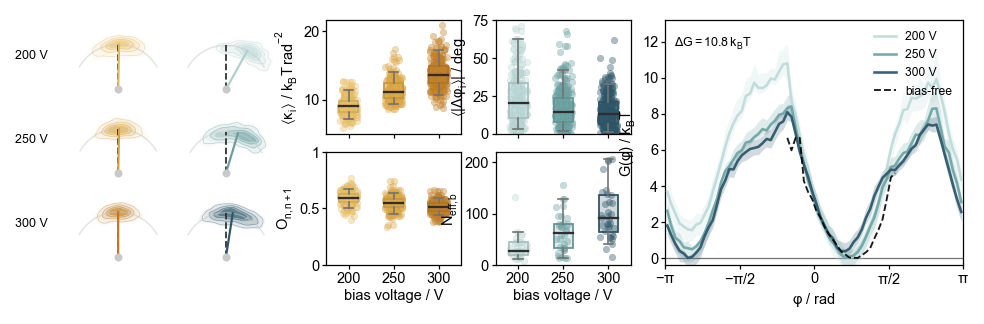

In [45]:
barrier_halfwidth_deg = 30

plot_fig3_bias_voltage_calibration_target_direct(
    m_list=m_list,

    calibration_particles=m.calibration_rotors[::2],
    target_particles=selected_target_rotors,
    calibration_example_particle=m.calibration_rotors[0],
    target_particle=selected_target_rotors[0],
    representative_window_deg=0,
    
    show_diff=True,
    fig_width_mm=160,
    fig_height_mm=58,
    
    kappa_ylim=None,
    target_steering_ylim=(0, 75),
    neff_ylim=(0, 220),
    
    steering_marker_fill_mode="all",  # "barrier_only" or "all"
    barrier_halfwidth_deg=barrier_halfwidth_deg,
    # barrier_min_prominence_kBT=1.0,
    # barrier_min_distance_deg=90,
    
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    annotation_size=6,
    calibration_voltage_colors=calibration_voltage_colors,
    target_voltage_colors=target_voltage_colors,
    C=CK_colors,
    
    save_dir=save_dir,
    save_prefix="Fig3a_bias_voltage_calibration_target",
)

## SI | Statistical uncertainty of free-energy landscape reconstruction from finite trajectories

In [42]:
if full_execution_uncertainty:
    compute_MBAR_statistical_uncertainty_blocks(
        m_list=m_list,
        particles=None,
        center_mode="ensemble",
        bias_potential="cosine",
        uncertainty_mode=("full"),
        nbins=72,
        n_bootstrap=5,
        block_s_target=0.25,
        block_s_calib=0.25,
        kappa_rescale_target=1.388,
    )

#### iii. Plot reconstruction gallery

In [ ]:
def plot_MBAR_reconstruction_gallery(
    m_list,
    target_voltage_colors,
    calibration_voltage_colors=None,
    display_mode="point",
    particles=None,
    split_target_other=True,
    show_diff=True,
    show_rmse=False,
    calibration_interval=(2.5, 97.5),
    center_mode="ensemble",
    bias_potential="cosine",
    ncols=4,
    nrows_per_page=6,
    panel_width_mm=42,
    panel_height_mm=30,
    rmse_panel_width_ratio=0.26,
    shared_ylim=False,
    energy_tick_spacing_kBT=4.0,
    shared_rmse_ylim=False,
    rmse_ylim=None,
    sort_by="particle",
    diff_hist_bins=72,
    band_alpha=0.22,
    line_lw=1.25,
    diff_lw=0.90,
    fontsize=7,
    title_fontsize=6.1,
    tick_fontsize=5.8,
    C=CK_colors,
    save_dir=None,
    save_prefix="SI_MBAR_reconstruction_gallery",
    save_svg=True,
):
    """
    Unified voltage-overlay MBAR reconstruction gallery.

    display_mode
    ------------
    "point"
        Stored point-MBAR reconstruction only.

    "calibration_sensitivity"
        Stored full-calibration point reconstruction with calibration-subset
        percentile band from m.mbar_calibration_ensemble_sensitivity.

    "bootstrap_target"
        Stored point reconstruction with target-only block-bootstrap band.

    "bootstrap_full"
        Stored point reconstruction with full block-bootstrap band.

    Behavior
    --------
    - All available UMB voltages are overlaid in one panel per rotor.
    - Curves and bands use target_voltage_colors.
    - No mean across measurements is computed.
    - NaN gaps are preserved.
    - Optional DIFF reference keeps empty histogram bins as NaN.
    - Optional RMSE bars compare each reconstruction with DIFF after allowing
      one optimal additive vertical shift of DIFF.
    - Nothing is written back into m.
    - Returns None.
    """

    import math
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.ticker import MultipleLocator

    display_mode = str(display_mode).lower().replace("-", "_").strip()
    valid_modes = {"point", "calibration_sensitivity", "bootstrap_target", "bootstrap_full"}

    if display_mode not in valid_modes:
        raise ValueError(f"display_mode must be one of {sorted(valid_modes)}.")

    if not isinstance(target_voltage_colors, dict) or not target_voltage_colors:
        raise ValueError("target_voltage_colors must be a non-empty dictionary.")

    target_voltage_colors = {float(k): tuple(v) for k, v in target_voltage_colors.items()}
    calibration_voltage_colors = {} if calibration_voltage_colors is None else {float(k): tuple(v) for k, v in calibration_voltage_colors.items()}

    C = C() if callable(C) else dict(C)
    C.setdefault("black", (0, 0, 0))
    C.setdefault("midgrey", (0.45, 0.45, 0.45))
    C.setdefault("lightgrey", (0.75, 0.75, 0.75))

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [xx for item in x for xx in flatten(item)]
        return [x]

    def mm(x):
        return float(x) / 25.4

    def wrap_pi(phi):
        phi = np.asarray(phi, dtype=float)
        return (phi + np.pi) % (2 * np.pi) - np.pi

    def zero_min(y):
        y = np.asarray(y, dtype=float).copy()
        finite = np.isfinite(y)
        if np.any(finite):
            y[finite] -= np.nanmin(y[finite])
        return y

    def measurement_name(m):
        try:
            return Path(str(m.path)).name
        except Exception:
            return "measurement"

    def natural_key(value):
        return [int(part) if part.isdigit() else part for part in re.split(r"(\d+)", str(value))]

    def parse_voltage(m):
        text = str(getattr(m, "path", measurement_name(m)))
        hits = re.findall(r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])", text, flags=re.IGNORECASE)
        return float(hits[-1]) if hits else np.nan

    def voltage_label(v):
        if not np.isfinite(v):
            return "unknown V"
        return f"{int(round(v))} V" if abs(v - round(v)) < 1e-9 else f"{v:g} V"

    def voltage_color(v):
        if not np.isfinite(v):
            return C["midgrey"]
        keys = np.asarray(sorted(target_voltage_colors), dtype=float)
        return target_voltage_colors[float(keys[np.argmin(np.abs(keys - float(v)))])]

    def is_diff(m):
        return "DIFF" in str(getattr(m, "path", "")).upper()

    def is_umb(m):
        if is_diff(m):
            return False
        protocol = getattr(m, "protocol", None)
        has_windows = isinstance(protocol, dict) and any(isinstance(k, str) and k.startswith("deg-") for k in protocol)
        return "UMB" in str(getattr(m, "path", "")).upper() or has_windows

    def style_energy_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(C["black"])
        ax.tick_params(length=2, width=0.6, labelsize=tick_fontsize, direction="out", color=C["black"], labelcolor=C["black"])
        ax.grid(False)

    def style_rmse_axis(ax):
        ax.spines["top"].set_visible(False)
        ax.spines["left"].set_visible(False)
        ax.spines["right"].set_linewidth(0.6)
        ax.spines["bottom"].set_linewidth(0.6)
        ax.spines["right"].set_color(C["black"])
        ax.spines["bottom"].set_color(C["black"])
        ax.yaxis.tick_right()
        ax.tick_params(axis="x", bottom=True, labelbottom=False, length=2, width=0.6, color=C["black"])
        ax.tick_params(axis="y", right=True, labelright=True, left=False, labelleft=False, length=2, width=0.6, labelsize=tick_fontsize, color=C["black"], labelcolor=C["black"])
        ax.grid(False)

    def finite_limits(values, pad=0.06):
        finite = []
        for value in values:
            value = np.asarray(value, dtype=float)
            value = value[np.isfinite(value)]
            if value.size:
                finite.append(value)
        if not finite:
            return None
        ymax = float(np.nanmax(np.concatenate(finite)))
        return 0.0, ymax + pad * max(ymax, 1.0)

    def interp_preserve_gaps(phi_target, phi_source, y_source):
        phi_target = wrap_pi(phi_target)
        phi_source = wrap_pi(phi_source)
        y_source = np.asarray(y_source, dtype=float)

        keep = np.isfinite(phi_source)
        x, y = phi_source[keep], y_source[keep]

        if x.size < 2:
            return np.full_like(phi_target, np.nan, dtype=float)

        order = np.argsort(x)
        x, y = x[order], y[order]
        finite_idx = np.where(np.isfinite(y))[0]

        if finite_idx.size < 2:
            return np.full_like(phi_target, np.nan, dtype=float)

        out = np.full_like(phi_target, np.nan, dtype=float)
        groups = np.split(finite_idx, np.where(np.diff(finite_idx) > 1)[0] + 1)

        for group in groups:
            if group.size < 2:
                continue
            xg, yg = x[group], y[group]
            mask = (phi_target >= xg[0]) & (phi_target <= xg[-1])
            out[mask] = np.interp(phi_target[mask], xg, yg)

        return out

    def read_point(m):
        try:
            curves = m.reconstructed_energy_landscapes_by_center[center_mode][bias_potential]
        except Exception:
            return {}

        out = {}

        for particle, df in curves.items():
            if not isinstance(df, pd.DataFrame) or "phi" not in df.columns:
                continue

            energy_col = next((col for col in ("U_mbar", "U_MBAR", "U_wham") if col in df.columns), None)
            if energy_col is None:
                continue

            phi = wrap_pi(df["phi"].to_numpy(float))
            point = zero_min(df[energy_col].to_numpy(float))
            order = np.argsort(phi)

            out[int(particle)] = {
                "phi": phi[order],
                "point": point[order],
                "low": None,
                "high": None,
            }

        return out

    def read_calibration_sensitivity(m):
        stored = getattr(m, "mbar_calibration_ensemble_sensitivity", None)

        if not isinstance(stored, dict) or "curves" not in stored:
            return {}

        qlow, qhigh = map(float, calibration_interval)

        if not 0 <= qlow < qhigh <= 100:
            raise ValueError("calibration_interval must contain ordered percentiles in [0, 100].")

        out = {}

        for particle, entry in stored["curves"].items():
            df = entry.get("landscape_df", None)
            subset_curves = np.asarray(entry.get("U_subset_curves", []), dtype=float)

            if not isinstance(df, pd.DataFrame) or "phi" not in df.columns or "U_MBAR_full_calib" not in df.columns:
                continue

            phi = wrap_pi(df["phi"].to_numpy(float))
            point = df["U_MBAR_full_calib"].to_numpy(float)

            if subset_curves.ndim != 2 or subset_curves.shape[1] != phi.size:
                continue

            finite_point = np.isfinite(point)

            if not np.any(finite_point):
                continue

            shift = np.nanmin(point[finite_point])
            point = point - shift

            subset_aligned = np.full_like(subset_curves, np.nan)

            for i, curve in enumerate(subset_curves):
                valid = np.isfinite(curve) & np.isfinite(point)
                if np.sum(valid) >= 3:
                    subset_aligned[i] = curve - np.nanmedian(curve[valid] - point[valid])

            low = np.nanpercentile(subset_aligned, qlow, axis=0)
            high = np.nanpercentile(subset_aligned, qhigh, axis=0)

            order = np.argsort(phi)

            out[int(particle)] = {
                "phi": phi[order],
                "point": point[order],
                "low": low[order],
                "high": high[order],
            }

        return out

    def read_bootstrap(m, mode):
        stored = getattr(m, "mbar_statistical_uncertainty_blocks", None)

        if not isinstance(stored, dict) or "evals" not in stored:
            return {}

        mode_data = stored["evals"].get(mode, None)

        if not isinstance(mode_data, dict):
            return {}

        out = {}

        for particle, entry in mode_data.get("curves", {}).items():
            df = entry.get("landscape_df", None)

            if not isinstance(df, pd.DataFrame):
                continue

            required = {"phi", "U_MBAR_point", "U_boot_low", "U_boot_high"}

            if not required.issubset(df.columns):
                continue

            phi = wrap_pi(df["phi"].to_numpy(float))
            point = df["U_MBAR_point"].to_numpy(float)
            low = df["U_boot_low"].to_numpy(float)
            high = df["U_boot_high"].to_numpy(float)

            finite_point = np.isfinite(point)

            if not np.any(finite_point):
                continue

            shift = np.nanmin(point[finite_point])
            point, low, high = point - shift, low - shift, high - shift
            order = np.argsort(phi)

            out[int(particle)] = {
                "phi": phi[order],
                "point": point[order],
                "low": low[order],
                "high": high[order],
            }

        return out

    def read_measurement(m):
        if display_mode == "point":
            return read_point(m)
        if display_mode == "calibration_sensitivity":
            return read_calibration_sensitivity(m)
        if display_mode == "bootstrap_target":
            return read_bootstrap(m, "target_only")
        return read_bootstrap(m, "full")

    def diff_curve(diff_measurements, particle):
        phi_all = []

        for m in diff_measurements:
            locs = getattr(m, "locs", None)

            if not isinstance(locs, pd.DataFrame) or "phi" not in locs.columns:
                continue

            group_col = "group_int" if "group_int" in locs.columns else "group" if "group" in locs.columns else None

            if group_col is None:
                continue

            phi = locs.loc[locs[group_col].astype(int) == int(particle), "phi"].to_numpy(float)
            phi = wrap_pi(phi[np.isfinite(phi)])

            if phi.size:
                phi_all.append(phi)

        if not phi_all:
            return None

        phi = np.concatenate(phi_all)
        edges = np.linspace(-np.pi, np.pi, int(diff_hist_bins) + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        counts, _ = np.histogram(phi, bins=edges)
        counts = counts.astype(float)

        norm = counts.sum() * float(edges[1] - edges[0])

        if norm <= 0:
            return None

        probability = counts / norm
        energy = np.full_like(probability, np.nan, dtype=float)
        valid = counts > 0
        energy[valid] = -np.log(probability[valid])
        energy = zero_min(energy)

        return {"phi": centers, "energy": energy}

    def compare_to_diff(phi_recon, energy_recon, diff):
        if diff is None:
            return np.nan

        valid_diff = np.isfinite(diff["phi"]) & np.isfinite(diff["energy"])

        if np.sum(valid_diff) < 3:
            return np.nan

        phi_eval = diff["phi"][valid_diff]
        diff_eval = diff["energy"][valid_diff]
        recon_eval = interp_preserve_gaps(phi_eval, phi_recon, energy_recon)
        keep = np.isfinite(recon_eval) & np.isfinite(diff_eval)

        if np.sum(keep) < 3:
            return np.nan

        recon_eval, diff_eval = recon_eval[keep], diff_eval[keep]
        offset = float(np.mean(recon_eval - diff_eval))
        return float(np.sqrt(np.mean((recon_eval - (diff_eval + offset)) ** 2)))

    all_measurements = flatten(m_list)
    umb_measurements = [m for m in all_measurements if is_umb(m)]
    diff_measurements = [m for m in all_measurements if is_diff(m)]

    records = []

    for m in umb_measurements:
        curves = read_measurement(m)

        if not curves:
            continue

        voltage = parse_voltage(m)

        records.append({
            "measurement": m,
            "name": measurement_name(m),
            "voltage": voltage,
            "label": voltage_label(voltage),
            "color": voltage_color(voltage),
            "curves": curves,
        })

    if not records:
        raise ValueError(f"No stored results were found for display_mode={display_mode!r}.")

    records.sort(key=lambda rec: (rec["voltage"] if np.isfinite(rec["voltage"]) else np.inf, natural_key(rec["name"])))

    target_particles = set()

    for rec in records:
        target_particles.update(int(p) for p in getattr(rec["measurement"], "target_rotors", []))

    available = sorted({int(p) for rec in records for p in rec["curves"]})
    particles_to_plot = available if particles is None else [int(p) for p in particles if int(p) in available]

    if not particles_to_plot:
        raise ValueError("None of the requested particles is available for this display mode.")

    particle_data = {}
    all_rmse = []

    for particle in particles_to_plot:
        overlays = []

        for rec in records:
            entry = rec["curves"].get(int(particle), None)

            if entry is None:
                continue

            overlay = {
                "voltage": rec["voltage"],
                "label": rec["label"],
                "color": rec["color"],
                "phi": entry["phi"],
                "point": entry["point"],
                "low": entry["low"],
                "high": entry["high"],
            }

            overlays.append(overlay)

        if not overlays:
            continue

        diff = diff_curve(diff_measurements, particle) if show_diff or show_rmse else None

        for overlay in overlays:
            overlay["rmse"] = compare_to_diff(overlay["phi"], overlay["point"], diff)

            if np.isfinite(overlay["rmse"]):
                all_rmse.append(overlay["rmse"])

        particle_data[int(particle)] = {"overlays": overlays, "diff": diff}

    particles_to_plot = [p for p in particles_to_plot if p in particle_data]

    if sort_by == "particle":
        particles_to_plot = sorted(particles_to_plot)

    elif sort_by in {"rmse", "consistency"}:
        def score(p):
            values = [ov["rmse"] for ov in particle_data[p]["overlays"] if np.isfinite(ov["rmse"])]
            return float(np.mean(values)) if values else np.inf

        particles_to_plot = sorted(particles_to_plot, key=score)

    else:
        raise ValueError("sort_by must be 'particle', 'rmse', or 'consistency'.")

    if split_target_other:
        groups = [
            {"name": "target", "particles": [p for p in particles_to_plot if p in target_particles]},
            {"name": "other", "particles": [p for p in particles_to_plot if p not in target_particles]},
        ]
    else:
        groups = [{"name": "all", "particles": particles_to_plot}]

    groups = [group for group in groups if group["particles"]]

    if shared_rmse_ylim:
        if rmse_ylim is not None:
            global_rmse_ylim = tuple(rmse_ylim)
        elif all_rmse:
            global_rmse_ylim = (0, max(1.1, 1.06 * float(np.max(all_rmse))))
        else:
            global_rmse_ylim = (0, 1.2)
    else:
        global_rmse_ylim = None

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    panels_per_page = int(ncols) * int(nrows_per_page)

    for group in groups:
        group_values = []

        for particle in group["particles"]:
            pdata = particle_data[particle]

            for overlay in pdata["overlays"]:
                group_values.append(overlay["point"])

                if overlay["low"] is not None:
                    group_values.extend([overlay["low"], overlay["high"]])

            if show_diff and pdata["diff"] is not None:
                group_values.append(pdata["diff"]["energy"])

        group_ylim = finite_limits(group_values) if shared_ylim else None
        n_pages = int(math.ceil(len(group["particles"]) / panels_per_page))

        for page in range(n_pages):
            start = page * panels_per_page
            stop = min((page + 1) * panels_per_page, len(group["particles"]))
            page_particles = group["particles"][start:stop]

            fig = plt.figure(figsize=(mm(panel_width_mm * ncols), mm(panel_height_mm * nrows_per_page)))
            outer = fig.add_gridspec(
                nrows_per_page,
                ncols,
                left=0.055,
                right=0.990,
                bottom=0.070,
                top=0.945,
                wspace=0.20,
                hspace=0.30,
            )

            for index, particle in enumerate(page_particles):
                row, col = divmod(index, int(ncols))

                if show_rmse:
                    cell = outer[row, col].subgridspec(1, 2, width_ratios=[1.0, rmse_panel_width_ratio], wspace=0.05)
                    ax = fig.add_subplot(cell[0, 0])
                    ax_rmse = fig.add_subplot(cell[0, 1])
                else:
                    ax = fig.add_subplot(outer[row, col])
                    ax_rmse = None

                pdata = particle_data[particle]
                local_values = []

                for overlay in pdata["overlays"]:
                    if overlay["low"] is not None and overlay["high"] is not None:
                        ax.fill_between(
                            overlay["phi"],
                            overlay["low"],
                            overlay["high"],
                            color=overlay["color"],
                            alpha=band_alpha,
                            lw=0,
                            zorder=1,
                        )

                    ax.plot(
                        overlay["phi"],
                        overlay["point"],
                        color=overlay["color"],
                        lw=line_lw,
                        label=overlay["label"],
                        zorder=3,
                    )

                    local_values.append(overlay["point"])

                    if overlay["low"] is not None:
                        local_values.extend([overlay["low"], overlay["high"]])

                if show_diff and pdata["diff"] is not None:
                    ax.plot(
                        pdata["diff"]["phi"],
                        pdata["diff"]["energy"],
                        color=C["black"],
                        lw=diff_lw,
                        ls="--",
                        label="DIFF",
                        zorder=5,
                    )

                    local_values.append(pdata["diff"]["energy"])

                if shared_ylim and group_ylim is not None:
                    ax.set_ylim(*group_ylim)
                else:
                    local_ylim = finite_limits(local_values)

                    if local_ylim is not None:
                        ax.set_ylim(*local_ylim)

                if energy_tick_spacing_kBT is not None:
                    spacing = float(energy_tick_spacing_kBT)

                    if not np.isfinite(spacing) or spacing <= 0:
                        raise ValueError("energy_tick_spacing_kBT must be None or positive.")

                    _, ymax = ax.get_ylim()
                    ax.set_ylim(0, ymax)
                    ax.yaxis.set_major_locator(MultipleLocator(spacing))

                ax.set_xlim(-np.pi, np.pi)
                ax.set_xticks([-np.pi, 0, np.pi])
                ax.set_title(f"rotor {particle}", fontsize=title_fontsize, pad=2)

                if row == int(nrows_per_page) - 1:
                    ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
                    ax.set_xlabel(r"$\varphi$ / rad", fontsize=fontsize)
                else:
                    ax.set_xticklabels([])

                if col == 0:
                    ax.set_ylabel(r"$G(\varphi)$ / $k_\mathrm{B}T$", fontsize=fontsize)
                else:
                    ax.set_yticklabels([])

                style_energy_axis(ax)

                if ax_rmse is not None:
                    heights = [overlay["rmse"] for overlay in pdata["overlays"]]

                    for x, (overlay, height) in enumerate(zip(pdata["overlays"], heights)):
                        if np.isfinite(height):
                            ax_rmse.bar(x, height, width=0.70, color=overlay["color"], edgecolor="none")

                    if global_rmse_ylim is not None:
                        ax_rmse.set_ylim(*global_rmse_ylim)
                    else:
                        finite_heights = [h for h in heights if np.isfinite(h)]
                        top = max(1.1, 1.06 * max(finite_heights)) if finite_heights else 1.2
                        ax_rmse.set_ylim(*(tuple(rmse_ylim) if rmse_ylim is not None else (0, top)))

                    ax_rmse.set_xlim(-0.6, max(len(heights) - 0.4, 0.6))
                    ax_rmse.set_xticks(range(len(heights)))
                    ax_rmse.set_xticklabels([])
                    ax_rmse.set_yticks([1.0])
                    ax_rmse.set_yticklabels(["1"])
                    style_rmse_axis(ax_rmse)

            for index in range(len(page_particles), panels_per_page):
                row, col = divmod(index, int(ncols))
                dummy = fig.add_subplot(outer[row, col])
                dummy.set_visible(False)

            legend_handles = {}

            for rec in records:
                if rec["label"] not in legend_handles:
                    legend_handles[rec["label"]] = plt.Line2D([], [], color=rec["color"], lw=line_lw)

            if show_diff:
                legend_handles["DIFF"] = plt.Line2D([], [], color=C["black"], lw=diff_lw, ls="--")

            fig.legend(
                legend_handles.values(),
                legend_handles.keys(),
                frameon=False,
                fontsize=tick_fontsize,
                loc="upper center",
                ncol=max(1, len(legend_handles)),
                bbox_to_anchor=(0.52, 0.997),
                handlelength=1.5,
                columnspacing=1.2,
            )

            if save_dir is not None:
                suffix = f"_{display_mode}_{group['name']}_page_{page + 1:02d}"
                fig.savefig(save_dir / f"{save_prefix}{suffix}.png", dpi=300, bbox_inches="tight")

                if save_svg:
                    fig.savefig(save_dir / f"{save_prefix}{suffix}.svg", bbox_inches="tight")

            plt.show()
            plt.close(fig)

    return None

In [ ]:
if full_execution_uncertainty:
    plot_MBAR_reconstruction_gallery(
        m_list=m_list,
        target_voltage_colors=target_voltage_colors,
        calibration_voltage_colors=calibration_voltage_colors,
        
        display_mode="bootstrap_full",
        particles=None,
        split_target_other=True,
        show_diff=False,
        show_rmse=False,
        ncols=5,
        nrows_per_page=6,
        panel_width_mm=42,
        panel_height_mm=30,
        shared_ylim=False,
        energy_tick_spacing_kBT=4.0,
        band_alpha=0.22,
        line_lw=1.25,
        
        C=CK_colors,
        save_dir=save_dir,
        save_prefix="SI_MBAR_full_bootstrap_voltage_overlay",
    )

#### iii. SI | Statistical uncertainty from finite sampling

In [ ]:
def plot_MBAR_statistical_uncertainty_blocks(
    m,
    example_particles=None,
    center_mode="ensemble",
    bias_potential="cosine",
    fig_width_mm=180,
    row_height_mm=34,
    hspace=0.24,
    C=None,
    save_dir=None,
    save_prefix="SI_MBAR_statistical_uncertainty_blocks",
    save_svg=False,
):
    """
    Plot lightweight MBAR block-bootstrap uncertainty.

    m=m_list[0]:
        plot one UMB measurement.

    m=m_list:
        plot every UMB measurement separately.

    Left:
        point MBAR reconstruction with full-bootstrap CI.

    Middle:
        local CI half-width for target_only and full.

    Right:
        mean target-only versus mean full CI half-width.

    Nothing is returned.
    """
    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec
    from pathlib import Path

    if C is None:
        C = CK_colors() if "CK_colors" in globals() and callable(CK_colors) else {}
    elif callable(C):
        C = C()

    C = dict(C)

    defaults = {
        "target_teal": (73/255, 139/255, 167/255),
        "darkblue": (46/255, 89/255, 108/255),
        "warmgold": (226/255, 172/255, 72/255),
        "grey": (0.25, 0.25, 0.25),
        "lightgrey": (0.72, 0.72, 0.72),
        "black": (0, 0, 0),
    }

    for key, value in defaults.items():
        C.setdefault(key, value)

    def flatten(values):
        if isinstance(values, (list, tuple)):
            out = []
            for value in values:
                out.extend(flatten(value))
            return out
        return [values]

    def is_umb(measurement):
        name = str(getattr(measurement, "path", "")).upper()

        has_windows = (
            hasattr(measurement, "protocol")
            and isinstance(measurement.protocol, dict)
            and any(
                isinstance(phase, str) and phase.startswith("deg-")
                for phase in measurement.protocol
            )
        )

        return "DIFF" not in name and ("UMB" in name or has_windows)

    def measurement_name(measurement, index):
        try:
            return Path(str(measurement.path)).stem
        except Exception:
            return f"UMB_{index + 1}"

    def mm(value):
        return float(value) / 25.4

    def zero_min(values):
        values = np.asarray(values, dtype=float).copy()
        finite = np.isfinite(values)

        if np.any(finite):
            values[finite] -= np.nanmin(values[finite])

        return values

    def half_width(band):
        return 0.5 * (
            np.asarray(band["high"], dtype=float)
            - np.asarray(band["low"], dtype=float)
        )

    def limits(arrays, pad=0.08, lower_zero=False):
        values = []

        for array in arrays:
            array = np.asarray(array, dtype=float)
            array = array[np.isfinite(array)]

            if array.size:
                values.append(array)

        if not values:
            return None

        values = np.concatenate(values)

        low = float(np.nanmin(values))
        high = float(np.nanmax(values))
        span = high - low

        if not np.isfinite(span) or span <= 0:
            span = max(abs(high), 1.0)

        low -= pad * span
        high += pad * span

        if lower_zero:
            low = 0.0

        return low, high

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(
            length=2,
            width=0.6,
            labelsize=7,
            direction="out",
            color="black",
            labelcolor="black",
        )

        ax.grid(False)

    def normalize_bands(raw):
        if "evals" not in raw:
            return raw

        bands = {}

        for mode, mode_data in raw["evals"].items():
            bands[mode] = {}

            for particle, particle_data in mode_data.get("curves", {}).items():
                landscape = particle_data.get("landscape_df")

                if landscape is None:
                    continue

                if (
                    "U_boot_low" not in landscape.columns
                    or "U_boot_high" not in landscape.columns
                ):
                    continue

                bands[mode][int(particle)] = {
                    "low": landscape["U_boot_low"].to_numpy(float),
                    "high": landscape["U_boot_high"].to_numpy(float),
                }

        return bands

    measurements = [measurement for measurement in flatten(m) if is_umb(measurement)]

    if not measurements:
        raise ValueError("No UMB measurements found.")

    for measurement_index, measurement in enumerate(measurements):

        if not hasattr(measurement, "mbar_statistical_uncertainty_blocks"):
            print(
                f"Skipped {measurement_name(measurement, measurement_index)}: "
                "no stored MBAR uncertainty."
            )
            continue

        bands = normalize_bands(
            measurement.mbar_statistical_uncertainty_blocks
        )

        if "full" not in bands:
            print(
                f"Skipped {measurement_name(measurement, measurement_index)}: "
                f"no full mode; available={list(bands)}."
            )
            continue

        try:
            point = (
                measurement
                .reconstructed_energy_landscapes_by_center[
                    center_mode
                ][
                    bias_potential
                ]
            )

        except Exception:
            print(
                f"Skipped {measurement_name(measurement, measurement_index)}: "
                "matching point-MBAR reconstruction is missing."
            )
            continue

        available = sorted(
            set(map(int, point))
            & set(map(int, bands["full"]))
        )

        if "target_only" in bands:
            available = sorted(
                set(available)
                & set(map(int, bands["target_only"]))
            )

        if not available:
            print(
                f"Skipped {measurement_name(measurement, measurement_index)}: "
                "no common point-MBAR and uncertainty particles."
            )
            continue

        if example_particles is None:
            ordered = sorted(
                available,
                key=lambda particle: np.nanmean(
                    half_width(
                        bands["full"][particle]
                    )
                ),
            )

            selected_particles = (
                [
                    ordered[0],
                    ordered[len(ordered) // 2],
                    ordered[-1],
                ]
                if len(ordered) >= 3
                else ordered
            )

        else:
            requested = list(
                map(
                    int,
                    example_particles,
                )
            )

            selected_particles = [
                particle
                for particle in requested
                if particle in available
            ]

            missing = [
                particle
                for particle in requested
                if particle not in available
            ]

            if missing:
                print(
                    f"{measurement_name(measurement, measurement_index)} | "
                    f"skipped unavailable particles: {missing}"
                )

        if not selected_particles:
            print(
                f"Skipped {measurement_name(measurement, measurement_index)}: "
                f"requested particles are unavailable. Available: {available}"
            )
            continue

        modes = [
            mode
            for mode in ("target_only", "full")
            if mode in bands
        ]

        energy_arrays = []
        width_arrays = []

        for particle in selected_particles:
            table = point[particle]

            energy_arrays.extend([
                table["U_mbar"].to_numpy(float),
                bands["full"][particle]["low"],
                bands["full"][particle]["high"],
            ])

            for mode in modes:
                width_arrays.append(
                    half_width(
                        bands[mode][particle]
                    )
                )

        energy_ylim = limits(
            energy_arrays,
            pad=0.08,
        )

        width_ylim = limits(
            width_arrays,
            pad=0.08,
            lower_zero=True,
        )

        n_rows = len(selected_particles)

        fig = plt.figure(
            figsize=(
                mm(fig_width_mm),
                mm(row_height_mm * n_rows),
            )
        )

        gs = gridspec.GridSpec(
            n_rows,
            3,
            figure=fig,
            left=0.07,
            right=0.985,
            bottom=0.12,
            top=0.94,
            width_ratios=[1.10, 1.05, 1.05],
            wspace=0.38,
            hspace=hspace,
        )

        fig.suptitle(
            measurement_name(
                measurement,
                measurement_index,
            ),
            fontsize=7,
            y=0.985,
        )

        ax_population = fig.add_subplot(
            gs[:, 2]
        )

        for row, particle in enumerate(
            selected_particles
        ):
            table = point[particle]

            phi = table[
                "phi"
            ].to_numpy(float)

            U_point = zero_min(
                table[
                    "U_mbar"
                ].to_numpy(float)
            )

            full_low = np.asarray(
                bands[
                    "full"
                ][
                    particle
                ][
                    "low"
                ],
                dtype=float,
            )

            full_high = np.asarray(
                bands[
                    "full"
                ][
                    particle
                ][
                    "high"
                ],
                dtype=float,
            )

            if not (
                len(phi)
                == len(U_point)
                == len(full_low)
                == len(full_high)
            ):
                raise ValueError(
                    f"{measurement_name(measurement, measurement_index)}, "
                    f"particle {particle}: inconsistent array lengths."
                )

            ax_energy = fig.add_subplot(
                gs[row, 0]
            )

            ax_width = fig.add_subplot(
                gs[row, 1]
            )

            ax_energy.axhline(
                0,
                color=C["lightgrey"],
                lw=0.55,
            )

            ax_energy.fill_between(
                phi,
                full_low,
                full_high,
                color=C["target_teal"],
                alpha=0.22,
                linewidth=0,
            )

            ax_energy.plot(
                phi,
                U_point,
                color=C["target_teal"],
                lw=1.45,
            )

            mean_full = float(
                np.nanmean(
                    half_width(
                        bands["full"][particle]
                    )
                )
            )

            ax_energy.text(
                0.03,
                0.94,
                rf"$\langle w_\mathrm{{CI}}\rangle={mean_full:.2f}\,k_\mathrm{{B}}T$",
                transform=ax_energy.transAxes,
                ha="left",
                va="top",
                fontsize=6.2,
                color=C["grey"],
            )

            if "target_only" in modes:
                ax_width.plot(
                    phi,
                    half_width(
                        bands[
                            "target_only"
                        ][
                            particle
                        ]
                    ),
                    color=C["darkblue"],
                    lw=1.05,
                    label=(
                        "target only"
                        if row == 0
                        else None
                    ),
                )

            ax_width.plot(
                phi,
                half_width(
                    bands[
                        "full"
                    ][
                        particle
                    ]
                ),
                color=C["black"],
                lw=1.25,
                label=(
                    "full"
                    if row == 0
                    else None
                ),
            )

            if row == 0:
                ax_width.legend(
                    frameon=False,
                    fontsize=6,
                    handlelength=1.6,
                    loc="upper left",
                )

            for ax in (
                ax_energy,
                ax_width,
            ):
                ax.set_xlim(
                    -np.pi,
                    np.pi,
                )

                ax.set_xticks([
                    -np.pi,
                    0,
                    np.pi,
                ])

                if row == n_rows - 1:
                    ax.set_xticklabels([
                        r"$-\pi$",
                        "0",
                        r"$\pi$",
                    ])

                    ax.set_xlabel(
                        r"$\varphi$ / rad",
                        fontsize=8,
                    )

                else:
                    ax.set_xticklabels([])

            if row == n_rows // 2:
                ax_energy.set_ylabel(
                    r"$G_\mathrm{MBAR}$ / $k_\mathrm{B}T$",
                    fontsize=8,
                )

                ax_width.set_ylabel(
                    r"CI half-width / $k_\mathrm{B}T$",
                    fontsize=8,
                )

            if energy_ylim is not None:
                ax_energy.set_ylim(
                    *energy_ylim
                )

            if width_ylim is not None:
                ax_width.set_ylim(
                    *width_ylim
                )

            style_ax(
                ax_energy
            )

            style_ax(
                ax_width
            )

        if "target_only" in modes:
            target_mean = np.asarray([
                np.nanmean(
                    half_width(
                        bands[
                            "target_only"
                        ][
                            particle
                        ]
                    )
                )
                for particle in available
            ])

            full_mean = np.asarray([
                np.nanmean(
                    half_width(
                        bands[
                            "full"
                        ][
                            particle
                        ]
                    )
                )
                for particle in available
            ])

            finite = (
                np.isfinite(target_mean)
                & np.isfinite(full_mean)
            )

            ax_population.scatter(
                target_mean[finite],
                full_mean[finite],
                s=20,
                color=C["darkblue"],
                alpha=0.78,
                edgecolor="none",
            )

            for particle in selected_particles:
                index = available.index(
                    particle
                )

                x = target_mean[index]
                y = full_mean[index]

                if not (
                    np.isfinite(x)
                    and np.isfinite(y)
                ):
                    continue

                ax_population.scatter(
                    [x],
                    [y],
                    s=48,
                    color=C["warmgold"],
                    edgecolor="black",
                    linewidth=0.45,
                )

                ax_population.text(
                    x,
                    y,
                    f" {particle}",
                    fontsize=6.2,
                    va="center",
                )

            values = np.r_[
                target_mean[finite],
                full_mean[finite],
            ]

            if values.size:
                high = max(
                    float(
                        np.nanmax(
                            values
                        )
                    )
                    * 1.08,
                    0.1,
                )

                ax_population.plot(
                    [0, high],
                    [0, high],
                    color=C["grey"],
                    lw=0.9,
                    ls="--",
                )

                ax_population.set_xlim(
                    0,
                    high,
                )

                ax_population.set_ylim(
                    0,
                    high,
                )

            ax_population.set_xlabel(
                r"mean target-only CI half-width / $k_\mathrm{B}T$",
                fontsize=8,
            )

            ax_population.set_ylabel(
                r"mean full CI half-width / $k_\mathrm{B}T$",
                fontsize=8,
            )

        style_ax(
            ax_population
        )

        if save_dir is not None:
            save_dir_use = Path(
                save_dir
            )

            save_dir_use.mkdir(
                parents=True,
                exist_ok=True,
            )

            measurement_prefix = (
                f"{measurement_index:02d}_"
                f"{save_prefix}"
            )

            fig.savefig(
                save_dir_use
                / f"{measurement_prefix}.png",
                dpi=300,
                bbox_inches="tight",
            )

            if save_svg:
                fig.savefig(
                    save_dir_use
                    / f"{measurement_prefix}.svg",
                    bbox_inches="tight",
                )

        plt.show()
        plt.close(fig)

    return None

In [ ]:
if full_executaion_uncertainty:
    plot_MBAR_statistical_uncertainty_blocks(
        m=m_list,
        example_particles=test_rotors,
    )

## SI | Reconstruction for different bias voltages

#### i. Compute reconstruction uncertainty and convergence

In [ ]:
compute_MBAR_statistical_uncertainty_blocks(
    m_list=m_list,
    particles=selected_target_rotors,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode="full",
    nbins=72,
    n_bootstrap=10,
    block_s_target=0.25,
    block_s_calib=0.25,
    kappa_rescale_target=1.388,
    mbar_tol=1e-5,
    mbar_max_iter=300,
    mbar_damp=0.8,
)

compute_MBAR_statistical_uncertainty_duration_convergence(
    m_list=m_list,
    durations_s=(1, 2, 3, 4, 5),
    particles=selected_target_rotors,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode="full",
    nbins=72,
    n_bootstrap=10,
    block_s_target=0.25,
    block_s_calib=0.25,
    kappa_rescale_target=1.388,
    mbar_tol=1e-5,
    mbar_max_iter=300,
    mbar_damp=0.8,
)

#### ii. Plot diagnoctics on barrier sampling

In [181]:
def plot_SI_bias_voltage_diagnostics(
    m_list,
    target_particles,
    calibration_particles,
    target_voltage_colors,
    C=CK_colors,
    gallery_particles=None,
    voltages=(200, 250, 300),
    uncertainty_mode="full",
    gallery_nrows=6,
    gallery_ncols=2,
    gallery_fig_width_mm=135,
    gallery_panel_height_mm=29,
    diagnostics_fig_width_mm=160,
    diagnostics_fig_height_mm=138,
    diagnostics_width_ratios=(1.55, 1.0),
    diagnostics_wspace=0.17,
    diagnostics_hspace=0.18,
    band_alpha=0.18,
    barrier_halfwidth_deg=30,
    barrier_min_prominence_kBT=1.0,
    barrier_min_distance_deg=90,
    barrier_nearest_windows=3,
    min_window_samples=20,
    hist_bins=72,
    max_acf_lag_fraction=0.25,
    shared_gallery_ylim=False,
    gallery_energy_ylim=(-0.4, None),
    show_barrier_regions=True,
    show_barrier_markers=True,
    show_scatter_connections=False,
    show_voltage_connections=True,
    show_voltage_strip=True,
    show_voltage_boxplot=True,
    scatter_marker_size=18,
    scatter_alpha=0.82,
    strip_marker_size=15,
    strip_alpha=0.40,
    strip_jitter=0.095,
    box_width=0.42,
    box_face_alpha=0.22,
    connection_alpha=0.10,
    panel_labels=("a", "b", "c", "d", "e"),
    panel_label_fontsize=10,
    panel_label_fontfamily="Arial",
    panel_label_fontweight="bold",
    panel_label_x_rel=-0.16,
    panel_label_y_rel=0.035,
    gallery_rotor_annotation=True,
    gallery_rotor_annotation_size=6,
    gallery_rotor_annotation_x=0.03,
    gallery_rotor_annotation_y=0.96,
    diagnostic_metrics=(
        ("steering_barrier_deg", r"$\langle |\Delta\varphi_{i,b}| \rangle$ / $^\circ$", False),
        ("tau_barrier_s", r"$\tau_{i,b}$ / s", False),
        ("half_overlap_barrier", r"$O_{1/2,i,b}$", False),
        ("effective_barrier_samples", r"$N_{\mathrm{eff},i,b}$", True),
        ("neighbor_overlap_barrier", r"$O_{i,i+1,b}$", False),
    ),
    save_dir=None,
    gallery_save_prefix="SI_bias_voltage_reconstruction_gallery",
    diagnostics_save_prefix="SI_bias_voltage_sampling_diagnostics",
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    annotation_size=6,
):
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from scipy.signal import find_peaks

    target_particles = list(map(int, target_particles))
    calibration_particles = list(map(int, calibration_particles))
    voltages = tuple(map(int, voltages))
    barrier_halfwidth = np.deg2rad(float(barrier_halfwidth_deg))
    min_peak_distance_fraction = float(barrier_min_distance_deg) / 360.0

    C = C() if callable(C) else dict(C)
    C.setdefault("black", (0, 0, 0))
    C.setdefault("grey", (0.25, 0.25, 0.25))
    C.setdefault("midgrey", C["grey"])
    C.setdefault("lightgrey", (0.72, 0.72, 0.72))
    C.setdefault("fit_darkgrey", C.get("darkgrey", C["grey"]))

    def mm(x):
        return float(x) / 25.4

    def wrap_pi(phi):
        phi = np.asarray(phi, float)
        return (phi + np.pi) % (2 * np.pi) - np.pi

    def circ_mean(phi):
        phi = np.asarray(phi, float)
        phi = phi[np.isfinite(phi)]
        if phi.size == 0:
            return np.nan
        z = np.mean(np.exp(1j * phi))
        return float(np.angle(z)) if np.abs(z) > 1e-15 else np.nan

    def circ_dist(a, b):
        return np.abs(wrap_pi(np.asarray(a, float) - np.asarray(b, float)))

    def blend(c1, c2, fraction):
        c1, c2 = np.asarray(c1, float), np.asarray(c2, float)
        return tuple((1.0 - float(fraction)) * c1 + float(fraction) * c2)

    def measurement_name(m):
        for attr in ("path", "filename", "file", "name"):
            value = getattr(m, attr, None)
            if value is not None:
                return Path(str(value)).name
        return "measurement"

    def get_voltage(m):
        name = measurement_name(m)
        for pattern in (r"(?<!\d)(\d{2,4})\s*V(?![A-Za-z])", r"bias[_\- ]?(\d{2,4})", r"voltage[_\- ]?(\d{2,4})", r"(\d{2,4})[_\- ]?volt"):
            hit = re.search(pattern, name, flags=re.IGNORECASE)
            if hit:
                return int(hit.group(1))
        for attr in ("bias_voltage_V", "voltage_V", "voltage", "bias_voltage"):
            try:
                return int(float(getattr(m, attr)))
            except Exception:
                pass
        return np.nan

    def is_diff(m):
        name = measurement_name(m).upper()
        return "DIFF" in name and "PSEUDO_DIFF" not in name

    def is_umb(m):
        if is_diff(m):
            return False
        if "UMB" in measurement_name(m).upper():
            return True
        protocol = getattr(m, "protocol", None)
        return isinstance(protocol, dict) and any(str(key).startswith("deg-") for key in protocol)

    def protocol_bounds(value):
        while isinstance(value, (tuple, list)) and len(value) == 1 and isinstance(value[0], (tuple, list, dict)):
            value = value[0]
        if isinstance(value, dict):
            start = value.get("start", value.get("start_time", value.get("t_start", value.get("t0"))))
            stop = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop")))))
            if start is None or stop is None:
                raise ValueError(f"Cannot parse protocol bounds: {value}")
            return float(start), float(stop)
        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])
        raise ValueError(f"Cannot parse protocol bounds: {value}")

    def deg_windows(m):
        protocol = getattr(m, "protocol", None)
        if not isinstance(protocol, dict):
            return []
        out = []
        for phase in protocol:
            hit = re.match(r"^deg-(-?\d+(?:\.\d+)?)$", str(phase))
            if hit:
                out.append((float(hit.group(1)), str(phase)))
        return sorted(out)

    def ensure_locs(m):
        locs = getattr(m, "locs", None)
        if not isinstance(locs, pd.DataFrame):
            return None
        locs = locs.copy()
        if "group" not in locs.columns and "group_int" in locs.columns:
            locs["group"] = locs["group_int"].astype(int)
        if "t" not in locs.columns:
            if "averagetime" in locs.columns:
                locs["t"] = locs["averagetime"].astype(float)
            elif "time" in locs.columns:
                locs["t"] = locs["time"].astype(float)
            elif "time_s" in locs.columns:
                locs["t"] = locs["time_s"].astype(float)
            elif "frame" in locs.columns:
                locs["t"] = locs["frame"].to_numpy(float) * float(getattr(m, "_average_tpf", 0.005))
        if not {"group", "phi", "t"}.issubset(locs.columns):
            return None
        locs["group"] = locs["group"].astype(int)
        return locs

    def periodic_interp(x_new, x, y):
        x_new, x, y = wrap_pi(x_new), wrap_pi(x), np.asarray(y, float)
        valid = np.isfinite(x) & np.isfinite(y)
        if np.sum(valid) < 2:
            return np.full(np.shape(x_new), np.nan)
        x, y = x[valid], y[valid]
        order = np.argsort(x)
        x, y = x[order], y[order]
        return np.interp(x_new, np.r_[x - 2 * np.pi, x, x + 2 * np.pi], np.r_[y, y, y])

    def smooth_periodic(y, width=3):
        y = np.asarray(y, float)
        width = max(1, int(width))
        if width <= 1:
            return y.copy()
        kernel = np.ones(width, float) / width
        extended = np.r_[y[-width:], y, y[:width]]
        return np.convolve(extended, kernel, mode="same")[width:-width]

    def extract_curve(m, particle):
        particle = int(particle)
        stored = getattr(m, "mbar_statistical_uncertainty_blocks", None)
        if isinstance(stored, dict) and isinstance(stored.get("evals"), dict):
            mode = str(uncertainty_mode).lower().replace("-", "_").strip()
            entry = stored["evals"].get(mode, {}).get("curves", {}).get(particle)
            if isinstance(entry, dict) and isinstance(entry.get("landscape_df"), pd.DataFrame):
                table = entry["landscape_df"]
                if {"phi", "U_MBAR_point"}.issubset(table.columns):
                    phi = wrap_pi(table["phi"].to_numpy(float))
                    energy = table["U_MBAR_point"].to_numpy(float)
                    low = table["U_boot_low"].to_numpy(float) if "U_boot_low" in table.columns else np.full_like(energy, np.nan)
                    high = table["U_boot_high"].to_numpy(float) if "U_boot_high" in table.columns else np.full_like(energy, np.nan)
                    order = np.argsort(phi)
                    phi, energy, low, high = phi[order], energy[order], low[order], high[order]
                    if np.any(np.isfinite(energy)):
                        shift = np.nanmin(energy)
                        return {"phi": phi, "energy": energy - shift, "low": low - shift, "high": high - shift}
        landscapes = getattr(m, "energy_landscapes", None)
        if not isinstance(landscapes, dict) or particle not in landscapes:
            return None
        entry = landscapes[particle]
        if isinstance(entry, pd.DataFrame):
            phi_key = next((key for key in ("phi", "phi_rad") if key in entry.columns), None)
            energy_key = next((key for key in ("U_mbar", "U_MBAR", "energy", "energy_kBT") if key in entry.columns), None)
            if phi_key is None or energy_key is None:
                return None
            phi = entry[phi_key].to_numpy(float)
            energy = entry[energy_key].to_numpy(float)
        elif isinstance(entry, dict):
            phi = entry.get("phi", entry.get("phi_rad", entry.get("centers")))
            energy = entry.get("U_mbar", entry.get("U_MBAR", entry.get("energy", entry.get("energy_kBT", entry.get("E")))))
            if phi is None or energy is None:
                return None
            phi, energy = np.asarray(phi, float), np.asarray(energy, float)
        else:
            return None
        phi = wrap_pi(phi)
        order = np.argsort(phi)
        phi, energy = phi[order], energy[order]
        if not np.any(np.isfinite(energy)):
            return None
        energy = energy - np.nanmin(energy)
        return {"phi": phi, "energy": energy, "low": np.full_like(energy, np.nan), "high": np.full_like(energy, np.nan)}

    def detect_barriers(curve):
        phi, energy = np.asarray(curve["phi"], float), np.asarray(curve["energy"], float)
        valid = np.isfinite(phi) & np.isfinite(energy)
        phi, energy = phi[valid], energy[valid]
        if len(phi) < 8:
            return []
        order = np.argsort(phi)
        phi, energy = phi[order], energy[order]
        smooth = smooth_periodic(energy, width=3)
        n = len(smooth)
        distance = max(1, int(round(min_peak_distance_fraction * n)))
        extended = np.r_[smooth, smooth, smooth]
        peaks, _ = find_peaks(extended, prominence=float(barrier_min_prominence_kBT), distance=distance)
        peaks = np.unique(peaks[(peaks >= n) & (peaks < 2 * n)] - n)
        minima, _ = find_peaks(-extended, distance=max(1, distance // 2))
        minima = minima[(minima >= 0) & (minima < 3 * n)]
        barriers = []
        for index in peaks:
            index_ext = index + n
            left = minima[minima < index_ext]
            right = minima[minima > index_ext]
            if not len(left) or not len(right):
                continue
            left_index, right_index = int(left[-1] % n), int(right[0] % n)
            reference = 0.5 * (smooth[left_index] + smooth[right_index])
            height = float(smooth[index] - reference)
            if np.isfinite(height) and height >= float(barrier_min_prominence_kBT):
                barriers.append({"phi_b": float(phi[index]), "height": height})
        return barriers

    def angular_hist(phi):
        counts, _ = np.histogram(wrap_pi(phi), bins=int(hist_bins), range=(-np.pi, np.pi))
        counts = counts.astype(float)
        return counts / counts.sum() if counts.sum() > 0 else np.full(int(hist_bins), np.nan)

    def histogram_overlap(hist_a, hist_b):
        hist_a, hist_b = np.asarray(hist_a, float), np.asarray(hist_b, float)
        valid = np.isfinite(hist_a) & np.isfinite(hist_b)
        return float(np.sum(np.minimum(hist_a[valid], hist_b[valid]))) if np.any(valid) else np.nan

    def integrated_autocorrelation(phi):
        phi = np.asarray(phi, float)
        phi = phi[np.isfinite(phi)]
        if len(phi) < 10:
            return np.nan, np.nan
        x = wrap_pi(phi - circ_mean(phi))
        x -= np.mean(x)
        n = len(x)
        fft_n = 1 << int(np.ceil(np.log2(2 * n)))
        acf = np.fft.irfft(np.abs(np.fft.rfft(x, fft_n)) ** 2, fft_n)[:n]
        if acf[0] <= 0:
            return np.nan, np.nan
        acf /= acf[0]
        max_lag = max(2, int(max_acf_lag_fraction * n))
        nonpositive = np.where(acf[1:max_lag] <= 0)[0]
        cutoff = int(nonpositive[0] + 1) if len(nonpositive) else max_lag
        tau_frames = max(0.5, 0.5 + np.sum(acf[1:cutoff]))
        return float(tau_frames), float(max(1.0, 2.0 * tau_frames))

    def split_half_overlap(phi):
        phi = np.asarray(phi, float)
        phi = phi[np.isfinite(phi)]
        if len(phi) < 2 * int(min_window_samples):
            return np.nan
        midpoint = len(phi) // 2
        return histogram_overlap(angular_hist(phi[:midpoint]), angular_hist(phi[midpoint:]))

    def collect_window_rows(m, particle):
        locs = ensure_locs(m)
        windows = deg_windows(m)
        if locs is None or not windows:
            return []
        rows = []
        dt = float(getattr(m, "_average_tpf", 0.005))
        n_windows = len(windows)
        for window_index, (_, phase) in enumerate(windows):
            start, stop = protocol_bounds(m.protocol[phase])
            window = locs[(locs["t"] >= start) & (locs["t"] < stop)]
            target_phi = window.loc[window["group"] == int(particle), "phi"].to_numpy(float)
            calibration_phi = window.loc[window["group"].isin(calibration_particles), "phi"].to_numpy(float)
            target_phi = wrap_pi(target_phi[np.isfinite(target_phi)])
            calibration_phi = wrap_pi(calibration_phi[np.isfinite(calibration_phi)])
            if len(target_phi) < int(min_window_samples):
                continue
            target_mean = circ_mean(target_phi)
            calibration_mean = circ_mean(calibration_phi) if len(calibration_phi) else np.nan
            tau_frames, g = integrated_autocorrelation(target_phi)
            rows.append({
                "window_index": int(window_index),
                "target_phi": target_phi,
                "target_hist": angular_hist(target_phi),
                "target_mean": target_mean,
                "steering_deg": float(np.rad2deg(circ_dist(target_mean, calibration_mean))) if np.isfinite(target_mean) and np.isfinite(calibration_mean) else np.nan,
                "tau_s": float(tau_frames * dt) if np.isfinite(tau_frames) else np.nan,
                "g": g,
                "half_overlap": split_half_overlap(target_phi),
            })
        if len(rows) < 2:
            for row in rows:
                row["neighbor_overlap"] = np.nan
            return rows
        rows_by_index = {row["window_index"]: row for row in rows}
        for row in rows:
            overlaps = []
            for neighbor_index in ((row["window_index"] - 1) % n_windows, (row["window_index"] + 1) % n_windows):
                neighbor = rows_by_index.get(neighbor_index)
                if neighbor is None:
                    continue
                overlap = histogram_overlap(row["target_hist"], neighbor["target_hist"])
                if np.isfinite(overlap):
                    overlaps.append(overlap)
            row["neighbor_overlap"] = float(np.mean(overlaps)) if overlaps else np.nan
        return rows

    def local_barrier_metrics(barrier, window_rows):
        barrier_phi = float(barrier["phi_b"])
        selected = sorted([row for row in window_rows if np.isfinite(row["target_mean"])], key=lambda row: float(circ_dist(row["target_mean"], barrier_phi)))[:max(1, int(barrier_nearest_windows))]
        if selected:
            distances = np.asarray([circ_dist(row["target_mean"], barrier_phi) for row in selected], float)
            weights = np.exp(-0.5 * (distances / max(barrier_halfwidth, 1e-9)) ** 2)
            weights = weights / weights.sum() if weights.sum() > 0 else np.ones(len(selected)) / len(selected)
        else:
            weights = np.array([], float)

        def weighted(key):
            values = np.asarray([row.get(key, np.nan) for row in selected], float)
            valid = np.isfinite(values) & np.isfinite(weights)
            if not np.any(valid):
                return np.nan
            local_weights = weights[valid]
            local_weights /= local_weights.sum()
            return float(np.sum(local_weights * values[valid]))

        effective_samples = 0.0
        for row in window_rows:
            count = int(np.sum(circ_dist(row["target_phi"], barrier_phi) <= barrier_halfwidth))
            g = row["g"] if np.isfinite(row["g"]) and row["g"] > 0 else 1.0
            effective_samples += count / g

        return {
            "steering_barrier_deg": weighted("steering_deg"),
            "tau_barrier_s": weighted("tau_s"),
            "half_overlap_barrier": weighted("half_overlap"),
            "effective_barrier_samples": float(effective_samples),
            "neighbor_overlap_barrier": weighted("neighbor_overlap"),
        }

    def diffusion_curve(particle):
        phi_sets = []
        for m in m_list:
            if not is_diff(m):
                continue
            locs = ensure_locs(m)
            if locs is None:
                continue
            phi = locs.loc[locs["group"] == int(particle), "phi"].to_numpy(float)
            phi = wrap_pi(phi[np.isfinite(phi)])
            if len(phi):
                phi_sets.append(phi)
        if not phi_sets:
            return None
        phi = np.concatenate(phi_sets)
        edges = np.linspace(-np.pi, np.pi, 73)
        counts, _ = np.histogram(phi, bins=edges)
        centers = 0.5 * (edges[:-1] + edges[1:])
        energy = np.full(len(centers), np.nan, float)
        valid = counts > 0
        energy[valid] = -np.log(counts[valid] / np.sum(counts))
        if np.any(np.isfinite(energy)):
            energy -= np.nanmin(energy)
        return {"phi": centers, "energy": energy}

    def plot_nan_segments(ax, x, y, **kwargs):
        x, y = np.asarray(x, float), np.asarray(y, float)
        indices = np.where(np.isfinite(x) & np.isfinite(y))[0]
        if len(indices) < 2:
            return
        breaks = np.where(np.diff(indices) > 1)[0]
        starts = np.r_[0, breaks + 1]
        stops = np.r_[breaks + 1, len(indices)]
        for segment_index, (start, stop) in enumerate(zip(starts, stops)):
            segment = indices[start:stop]
            if len(segment) < 2:
                continue
            current = dict(kwargs)
            if segment_index > 0:
                current.pop("label", None)
            ax.plot(x[segment], y[segment], **current)

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.60)
            spine.set_color(C["black"])
        ax.tick_params(length=2.0, width=0.60, pad=1.2, direction="out", labelsize=tick_label_size, colors=C["black"])
        ax.grid(False)

    def draw_voltage_strip_box(ax, rotor_values, seed):
        rng = np.random.default_rng(seed)
        data_by_voltage = []
        for position, voltage in enumerate(voltages, start=1):
            values = np.asarray([particle_values[voltage] for particle_values in rotor_values.values() if voltage in particle_values], float)
            values = values[np.isfinite(values)]
            data_by_voltage.append(values)
            if values.size and show_voltage_strip:
                color = target_voltage_colors.get(int(voltage), C["grey"])
                edge = blend(color, C["fit_darkgrey"], 0.16)
                jitter = np.clip(rng.normal(0.0, float(strip_jitter), size=values.size), -2.0 * float(strip_jitter), 2.0 * float(strip_jitter))
                ax.scatter(np.full(values.size, position) + jitter, values, s=strip_marker_size, facecolor=color, edgecolor=edge, linewidth=0.20, alpha=strip_alpha, zorder=2)
        if show_voltage_boxplot:
            boxplot = ax.boxplot(data_by_voltage, positions=np.arange(1, len(voltages) + 1), widths=box_width, patch_artist=True, showfliers=False, whis=(5, 95), zorder=4)
            for patch, voltage in zip(boxplot["boxes"], voltages):
                color = target_voltage_colors.get(int(voltage), C["grey"])
                patch.set_facecolor((*color, box_face_alpha))
                patch.set_edgecolor(blend(color, C["fit_darkgrey"], 0.16))
                patch.set_linewidth(0.85)
            for median in boxplot["medians"]:
                median.set_color(C["fit_darkgrey"])
                median.set_linewidth(1.10)
            for artist in boxplot["whiskers"] + boxplot["caps"]:
                artist.set_color(C["midgrey"])
                artist.set_linewidth(0.80)
        ax.set_xlim(0.5, len(voltages) + 0.5)
        ax.set_xticks(np.arange(1, len(voltages) + 1))
        ax.set_xticklabels([str(int(voltage)) for voltage in voltages])

    def to_roman(n):
        vals = [(1000, "m"), (900, "cm"), (500, "d"), (400, "cd"), (100, "c"), (90, "xc"), (50, "l"), (40, "xl"), (10, "x"), (9, "ix"), (5, "v"), (4, "iv"), (1, "i")]
        out, n = [], int(n)
        for v, s in vals:
            while n >= v:
                out.append(s)
                n -= v
        return "".join(out) if out else "i"

    def add_row_panel_labels(fig, left_axes, labels, x_rel=-0.16, y_rel=0.035, fontsize=10, fontfamily="Arial", fontweight="bold"):
        if labels is None:
            return
        labels = list(labels)
        if len(labels) < len(left_axes):
            labels = labels + [chr(97 + i) for i in range(len(labels), len(left_axes))]
        fig.canvas.draw_idle()
        for ax, label in zip(left_axes, labels[:len(left_axes)]):
            pos = ax.get_position()
            x = pos.x0 + float(x_rel) * pos.width
            y = pos.y1 + float(y_rel) * pos.height
            fig.text(x, y, str(label), ha="left", va="bottom", fontsize=fontsize, fontfamily=fontfamily, fontweight=fontweight, color="black")

    umbrella_measurements = [m for m in m_list if is_umb(m) and np.isfinite(get_voltage(m)) and int(get_voltage(m)) in voltages]
    records, overlays = [], {particle: {} for particle in target_particles}

    for particle in target_particles:
        reference = diffusion_curve(particle)
        for m in umbrella_measurements:
            voltage = int(get_voltage(m))
            curve = extract_curve(m, particle)
            if curve is None:
                continue
            barriers = detect_barriers(curve)
            window_rows = collect_window_rows(m, particle)
            if not barriers or not window_rows:
                continue
            overlays[particle][voltage] = {"curve": curve, "barriers": barriers, "diff": reference}
            for barrier in barriers:
                records.append({"particle": int(particle), "voltage": int(voltage), "barrier_height_kBT": float(barrier["height"]), **local_barrier_metrics(barrier, window_rows)})

    if not records:
        raise RuntimeError("No valid barrier-local diagnostics could be calculated.")

    records_df = pd.DataFrame(records)
    agg_cols = ["barrier_height_kBT"] + [metric for metric, _, _ in diagnostic_metrics]
    agg_map = {col: "mean" for col in agg_cols if col in records_df.columns}
    diagnostics_df = records_df.groupby(["particle", "voltage"], as_index=False).agg(agg_map)

    if gallery_particles is None:
        gallery_particles = [particle for particle in target_particles if overlays.get(particle)][:gallery_nrows * gallery_ncols]
    else:
        gallery_particles = [int(particle) for particle in gallery_particles if overlays.get(int(particle))]
    if not gallery_particles:
        raise RuntimeError("No valid gallery particles were found.")

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    shared_ylim = None
    if shared_gallery_ylim:
        values = []
        for particle in gallery_particles:
            for item in overlays[particle].values():
                for key in ("energy", "low", "high"):
                    current = np.asarray(item["curve"][key], float)
                    values.extend(current[np.isfinite(current)])
                if item["diff"] is not None:
                    current = np.asarray(item["diff"]["energy"], float)
                    values.extend(current[np.isfinite(current)])
        if values:
            values = np.asarray(values, float)
            shared_ylim = (
                gallery_energy_ylim[0] if gallery_energy_ylim[0] is not None else float(np.nanmin(values)),
                gallery_energy_ylim[1] if gallery_energy_ylim[1] is not None else float(np.nanmax(values) * 1.06),
            )

    fig_gallery, gallery_axes = plt.subplots(gallery_nrows, gallery_ncols, figsize=(mm(gallery_fig_width_mm), mm(gallery_panel_height_mm * gallery_nrows)), squeeze=False)
    gallery_axes = gallery_axes.ravel()

    for panel_index, (ax, particle) in enumerate(zip(gallery_axes, gallery_particles)):
        panel_values = []
        for voltage in voltages:
            item = overlays[particle].get(voltage)
            if item is None:
                continue
            curve = item["curve"]
            color = target_voltage_colors.get(voltage, C["grey"])
            if np.any(np.isfinite(curve["low"])) and np.any(np.isfinite(curve["high"])):
                ax.fill_between(curve["phi"], curve["low"], curve["high"], color=color, alpha=band_alpha, lw=0, zorder=1)
            plot_nan_segments(ax, curve["phi"], curve["energy"], color=color, lw=1.20, alpha=0.95, label=f"{voltage} V", zorder=3)
            panel_values.extend(np.asarray(curve["energy"], float)[np.isfinite(curve["energy"])])
            for barrier in item["barriers"]:
                phi_b = barrier["phi_b"]
                if show_barrier_regions:
                    ax.axvspan(phi_b - barrier_halfwidth, phi_b + barrier_halfwidth, color=color, alpha=0.035, lw=0, zorder=0)
                if show_barrier_markers:
                    energy_b = periodic_interp(phi_b, curve["phi"], curve["energy"])[()]
                    ax.scatter(phi_b, energy_b, s=18, facecolor=color, edgecolor=C["black"], linewidth=0.30, zorder=5)
        reference = next(iter(overlays[particle].values()))["diff"]
        if reference is not None:
            plot_nan_segments(ax, reference["phi"], reference["energy"], color=C["black"], lw=0.90, ls="--", alpha=0.90, label="bias-free diffusion", zorder=6)
            panel_values.extend(np.asarray(reference["energy"], float)[np.isfinite(reference["energy"])])
        ax.axhline(0, color=C["black"], lw=0.55, alpha=0.50, zorder=0)
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
        if shared_ylim is not None:
            ymin, ymax = shared_ylim
        elif panel_values:
            panel_values = np.asarray(panel_values, float)
            ymin = gallery_energy_ylim[0] if gallery_energy_ylim[0] is not None else float(np.nanmin(panel_values))
            ymax = gallery_energy_ylim[1] if gallery_energy_ylim[1] is not None else float(np.nanmax(panel_values) * 1.06)
        else:
            ymin, ymax = -0.4, 5.0
        ax.set_ylim(ymin, ymax)
        tick_start, tick_stop = 5.0 * np.ceil(ymin / 5.0), 5.0 * np.floor(ymax / 5.0)
        if tick_stop >= tick_start:
            ax.set_yticks(np.arange(tick_start, tick_stop + 0.1, 5.0))
        row, column = panel_index // gallery_ncols, panel_index % gallery_ncols
        if row == gallery_nrows - 1:
            ax.set_xlabel(r"$\varphi$ / rad")
        else:
            ax.tick_params(axis="x", which="both", labelbottom=False)
        if column == 0:
            ax.set_ylabel(r"$G(\varphi)$ / $k_\mathrm{B}T$")
        if gallery_rotor_annotation:
            rotor_text = f"rotor {to_roman(panel_index + 1)}"
            ax.text(gallery_rotor_annotation_x, gallery_rotor_annotation_y, rotor_text, transform=ax.transAxes, ha="left", va="top", fontsize=gallery_rotor_annotation_size, color=C["black"])
        style_axis(ax)

    for ax in gallery_axes[len(gallery_particles):]:
        ax.set_axis_off()

    handles, labels = gallery_axes[0].get_legend_handles_labels()
    if handles:
        gallery_axes[0].legend(handles, labels, frameon=False, fontsize=tick_label_size, handlelength=1.8, loc="upper right")

    fig_gallery.subplots_adjust(left=0.075, right=0.992, bottom=0.050, top=0.992, wspace=0.16, hspace=0.11)

    fig_diagnostics = plt.figure(figsize=(mm(diagnostics_fig_width_mm), mm(diagnostics_fig_height_mm)))
    metric_grid = fig_diagnostics.add_gridspec(
        len(diagnostic_metrics),
        2,
        left=0.100,
        right=0.992,
        bottom=0.065,
        top=0.992,
        width_ratios=diagnostics_width_ratios,
        wspace=diagnostics_wspace,
        hspace=diagnostics_hspace,
    )

    metric_axes = []
    for row_index in range(len(diagnostic_metrics)):
        ax_left = fig_diagnostics.add_subplot(metric_grid[row_index, 0])
        ax_right = fig_diagnostics.add_subplot(metric_grid[row_index, 1], sharey=ax_left)
        metric_axes.append((ax_left, ax_right))

    x_all = diagnostics_df["barrier_height_kBT"].to_numpy(float)
    x_all = x_all[np.isfinite(x_all)]
    if x_all.size:
        x_min, x_max = np.nanmin(x_all), np.nanmax(x_all)
        x_pad = 0.04 * (x_max - x_min) if x_max > x_min else 0.5
        x_limits = (x_min - x_pad, x_max + x_pad)
    else:
        x_limits = None

    for row_index, (metric, ylabel, log_y) in enumerate(diagnostic_metrics):
        ax_barrier, ax_voltage = metric_axes[row_index]
        current = diagnostics_df[["particle", "voltage", "barrier_height_kBT", metric]].copy()
        current = current[np.isfinite(current[metric]) & np.isfinite(current["barrier_height_kBT"])]
        if log_y:
            current = current[current[metric] > 0]
        if current.empty:
            ax_barrier.set_axis_off()
            ax_voltage.set_axis_off()
            continue

        if show_scatter_connections:
            for particle in target_particles:
                subset = current[current["particle"] == particle].sort_values("voltage")
                if len(subset) >= 2:
                    ax_barrier.plot(subset["barrier_height_kBT"], subset[metric], color=C["lightgrey"], lw=0.55, alpha=0.18, zorder=1)

        for _, row in current.iterrows():
            color = target_voltage_colors.get(int(row["voltage"]), C["grey"])
            ax_barrier.scatter(row["barrier_height_kBT"], row[metric], s=scatter_marker_size, facecolor=color, edgecolor=C["black"], linewidth=0.28, alpha=scatter_alpha, zorder=3)

        rotor_values = {}
        for particle in target_particles:
            subset = current[current["particle"] == particle]
            values = {int(v): float(y) for v, y in zip(subset["voltage"].to_numpy(int), subset[metric].to_numpy(float)) if np.isfinite(y)}
            if values:
                rotor_values[int(particle)] = values

        if show_voltage_connections:
            for values in rotor_values.values():
                xs = [voltages.index(voltage) + 1 for voltage in voltages if voltage in values]
                ys = [values[voltage] for voltage in voltages if voltage in values]
                if len(xs) >= 2:
                    ax_voltage.plot(xs, ys, color=C["lightgrey"], lw=0.55, alpha=connection_alpha, zorder=1)

        draw_voltage_strip_box(ax_voltage, rotor_values, seed=1 + row_index)

        if log_y:
            ax_barrier.set_yscale("log")
            ax_voltage.set_yscale("log")

        if x_limits is not None:
            ax_barrier.set_xlim(*x_limits)

        ax_barrier.set_ylabel(ylabel, fontsize=axis_label_size, labelpad=1.5)
        ax_voltage.set_ylabel(ylabel, fontsize=axis_label_size, labelpad=1.5)
        ax_voltage.tick_params(axis="y", which="both", left=True, labelleft=True)

        if row_index < len(diagnostic_metrics) - 1:
            ax_barrier.tick_params(axis="x", which="both", labelbottom=False)
            ax_voltage.tick_params(axis="x", which="both", labelbottom=False)
        else:
            ax_barrier.set_xlabel(r"$\Delta G_b$ / $k_\mathrm{B}T$", fontsize=axis_label_size, labelpad=1.5)
            ax_voltage.set_xlabel("bias voltage / V", fontsize=axis_label_size, labelpad=1.5)

        style_axis(ax_barrier)
        style_axis(ax_voltage)

    add_row_panel_labels(
        fig_diagnostics,
        [pair[0] for pair in metric_axes],
        panel_labels,
        x_rel=panel_label_x_rel,
        y_rel=panel_label_y_rel,
        fontsize=panel_label_fontsize,
        fontfamily=panel_label_fontfamily,
        fontweight=panel_label_fontweight,
    )

    if save_dir is not None:
        save_path = Path(save_dir)
        save_path.mkdir(parents=True, exist_ok=True)
        fig_gallery.savefig(save_path / f"{gallery_save_prefix}.png", dpi=300, bbox_inches="tight")
        fig_gallery.savefig(save_path / f"{gallery_save_prefix}.svg", bbox_inches="tight")
        fig_diagnostics.savefig(save_path / f"{diagnostics_save_prefix}.png", dpi=300, bbox_inches="tight")
        fig_diagnostics.savefig(save_path / f"{diagnostics_save_prefix}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig_gallery)
    plt.close(fig_diagnostics)
    return fig_gallery, fig_diagnostics

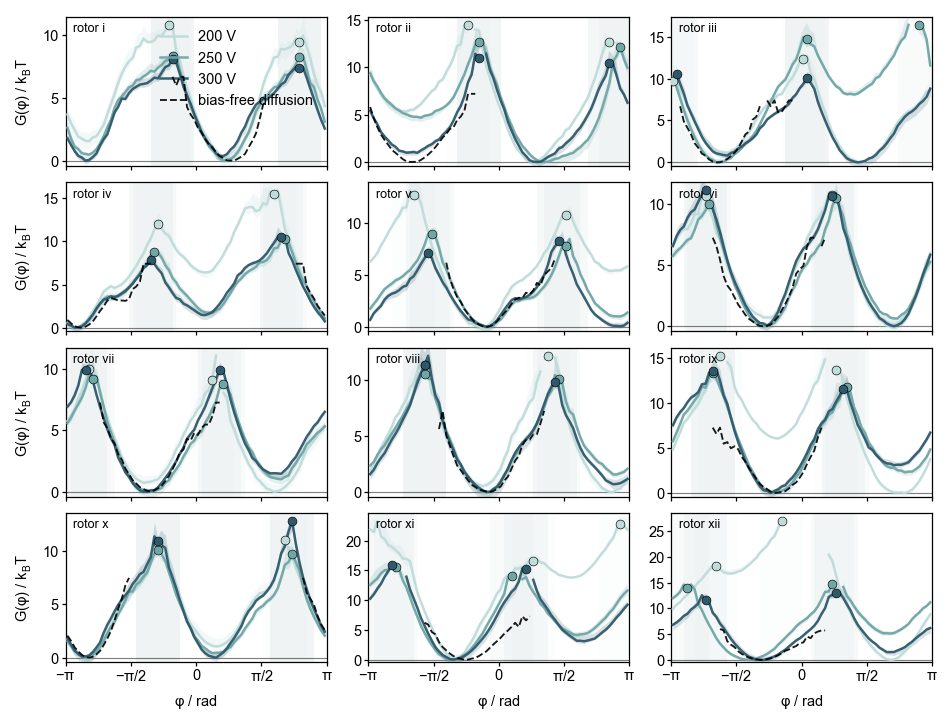

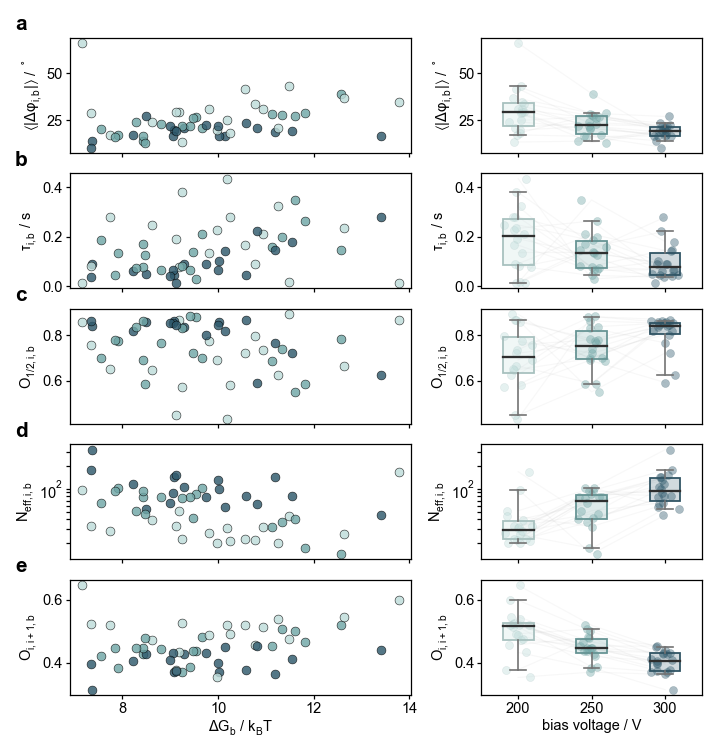

In [182]:
fig_gallery, fig_diagnostics = plot_SI_bias_voltage_diagnostics(
    m_list=m_list,
    target_particles=selected_target_rotors,
    calibration_particles=m.calibration_rotors,
    target_voltage_colors=target_voltage_colors,
    C=CK_colors,
    gallery_particles=None,
    voltages=(200, 250, 300),
    uncertainty_mode="full",
    gallery_nrows=4,
    gallery_ncols=3,
    gallery_fig_width_mm=160,
    gallery_panel_height_mm=29,
    
    diagnostics_fig_width_mm=120,
    diagnostics_fig_height_mm=120,
    diagnostics_width_ratios=(1.55, 1.0),
    diagnostics_wspace=0.25,
    diagnostics_hspace=0.18,
    
    panel_labels=("a", "b", "c", "d", "e"),
    panel_label_fontsize=10,
    panel_label_fontfamily="Arial",
    panel_label_fontweight="bold",
    panel_label_x_rel=-0.16,
    panel_label_y_rel=0.035,
    diagnostic_metrics=(
        ("steering_barrier_deg", r"$\langle |\Delta\varphi_{i,b}| \rangle$ / $^\circ$", False),
        ("tau_barrier_s", r"$\tau_{i,b}$ / s", False),
        ("half_overlap_barrier", r"$O_{1/2,i,b}$", False),
        ("effective_barrier_samples", r"$N_{\mathrm{eff},i,b}$", True),
        ("neighbor_overlap_barrier", r"$O_{i,i+1,b}$", False),
    ),
    save_dir=save_dir_SI,
    gallery_save_prefix="SI_toFig3a_voltage__reconstruction_gallery",
    diagnostics_save_prefix="SI_toFig3a_voltage__sampling_diagnostics",
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    annotation_size=6,
)

#### iii. Plot effect on reconstruction

In [158]:
def plot_SI_bias_voltage_reconstruction_quality(
    m_list,
    particles,
    target_voltage_colors,
    C,
    voltages=(200, 250, 300),
    uncertainty_mode="full",
    center_mode="ensemble",
    bias_potential="cosine",
    ci_width_stat="median",
    durations_s=None,
    rmse_min_common_bins=8,
    rmse_allow_vertical_shift=True,
    rmse_use_diff_zero_min=True,
    convergence_strip_marker_size=12,
    convergence_strip_alpha=0.28,
    convergence_strip_jitter=0.035,
    convergence_voltage_offset=0.16,
    convergence_summary_stat="median",
    convergence_summary_band="iqr",
    convergence_summary_lw=1.35,
    convergence_summary_ms=3.6,
    convergence_band_alpha=0.12,
    voltage_strip_marker_size=15,
    voltage_strip_alpha=0.35,
    voltage_strip_jitter=0.095,
    box_width=0.42,
    box_face_alpha=0.22,
    show_voltage_connections=True,
    connection_alpha=0.06,
    connection_lw=0.45,
    panel_labels=("a", "b", "c"),
    panel_label_fontsize=10,
    panel_label_fontfamily="Arial",
    panel_label_fontweight="bold",
    panel_label_x_rel=-0.14,
    panel_label_y_rel=0.04,
    convergence_ylabel=r"$\widetilde{w}_{i}^{\mathrm{CI}}(t_\mathrm{w})$ / $k_\mathrm{B}T$",
    final_uncertainty_ylabel=r"$\widetilde{w}_{i}^{\mathrm{CI}}$ / $k_\mathrm{B}T$",
    rmse_ylabel=r"$\mathrm{RMSE}_{\mathrm{mbar-diff}}$ / $k_\mathrm{B}T$",
    duration_xlabel=r"$t_\mathrm{w}$ / s",
    voltage_xlabel=r"$V_\mathrm{bias}$ / V",
    fig_width_mm=180,
    fig_height_mm=52,
    wspace=0.34,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    save_dir=None,
    save_prefix="SI_bias_voltage_reconstruction_quality",
):
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path

    particles = None if particles is None else {int(p) for p in particles}
    voltages = tuple(int(v) for v in voltages)
    mode_key = str(uncertainty_mode).lower().replace("-", "_").strip()
    ci_width_stat = str(ci_width_stat).lower().strip()
    convergence_summary_stat = str(convergence_summary_stat).lower().strip()
    convergence_summary_band = str(convergence_summary_band).lower().strip()
    if ci_width_stat not in {"median", "mean"}:
        raise ValueError("ci_width_stat must be 'median' or 'mean'.")
    if convergence_summary_stat not in {"median", "mean"}:
        raise ValueError("convergence_summary_stat must be 'median' or 'mean'.")
    if convergence_summary_band not in {"iqr", "sem", "none"}:
        raise ValueError("convergence_summary_band must be 'iqr', 'sem', or 'none'.")

    C = C() if callable(C) else dict(C)
    C.setdefault("black", (0, 0, 0))
    C.setdefault("grey", (0.25, 0.25, 0.25))
    C.setdefault("midgrey", (0.45, 0.45, 0.45))
    C.setdefault("lightgrey", (0.72, 0.72, 0.72))
    C.setdefault("fit_darkgrey", C.get("darkgrey", C["grey"]))

    def mm(value):
        return float(value) / 25.4

    def flatten(values):
        if isinstance(values, (list, tuple)):
            return [item for value in values for item in flatten(value)]
        return [values]

    def wrap_pi(phi):
        phi = np.asarray(phi, float)
        return (phi + np.pi) % (2 * np.pi) - np.pi

    def measurement_name(m):
        for attr in ("path", "filename", "file", "name"):
            value = getattr(m, attr, None)
            if value is not None:
                return str(value)
        return "measurement"

    def get_voltage(m):
        name = measurement_name(m)
        for pattern in (r"(?<!\d)(\d{2,4})\s*V(?![A-Za-z])", r"bias[_\- ]?(\d{2,4})", r"voltage[_\- ]?(\d{2,4})", r"(\d{2,4})[_\- ]?volt"):
            match = re.search(pattern, name, flags=re.IGNORECASE)
            if match:
                return int(match.group(1))
        for attr in ("bias_voltage_V", "voltage_V", "voltage", "bias_voltage"):
            try:
                return int(float(getattr(m, attr)))
            except Exception:
                pass
        return np.nan

    def is_diff(m):
        return "DIFF" in measurement_name(m).upper() and "PSEUDO_DIFF" not in measurement_name(m).upper()

    def ensure_locs(m):
        locs = getattr(m, "locs", None)
        if not isinstance(locs, pd.DataFrame):
            return None
        locs = locs.copy()
        if "group" not in locs.columns and "group_int" in locs.columns:
            locs["group"] = locs["group_int"]
        if not {"group", "phi"}.issubset(locs.columns):
            return None
        locs["group"] = pd.to_numeric(locs["group"], errors="coerce")
        locs = locs[np.isfinite(locs["group"])].copy()
        locs["group"] = locs["group"].astype(int)
        return locs

    def zero_min(values):
        values = np.asarray(values, float).copy()
        valid = np.isfinite(values)
        if np.any(valid):
            values[valid] -= np.nanmin(values[valid])
        return values

    def periodic_interp(x_new, x, y):
        x_new, x, y = wrap_pi(x_new), wrap_pi(x), np.asarray(y, float)
        valid = np.isfinite(x) & np.isfinite(y)
        if np.sum(valid) < 2:
            return np.full(np.shape(x_new), np.nan)
        x, y = x[valid], y[valid]
        order = np.argsort(x)
        x, y = x[order], y[order]
        return np.interp(x_new, np.r_[x - 2 * np.pi, x, x + 2 * np.pi], np.r_[y, y, y])

    def extract_table(entry):
        if isinstance(entry, dict) and isinstance(entry.get("landscape_df"), pd.DataFrame):
            return entry["landscape_df"]
        return entry if isinstance(entry, pd.DataFrame) else None

    def extract_uncertainty_curve(m, particle):
        stored = getattr(m, "mbar_statistical_uncertainty_blocks", None)
        if not isinstance(stored, dict):
            return None
        source = stored.get("evals", {}).get(mode_key, {}).get("curves", {}) if isinstance(stored.get("evals"), dict) else stored.get(mode_key, {})
        entry = source.get(int(particle), source.get(str(int(particle)))) if isinstance(source, dict) else None
        table = extract_table(entry)
        if not isinstance(table, pd.DataFrame):
            return None
        phi_key = next((key for key in ("phi", "phi_rad") if key in table.columns), None)
        point_key = next((key for key in ("U_MBAR_point", "U_mbar", "U_MBAR", "energy", "energy_kBT") if key in table.columns), None)
        low_key = next((key for key in ("U_boot_low", "low", "U_low") if key in table.columns), None)
        high_key = next((key for key in ("U_boot_high", "high", "U_high") if key in table.columns), None)
        if None in (phi_key, point_key, low_key, high_key):
            return None
        phi = wrap_pi(table[phi_key].to_numpy(float))
        point = table[point_key].to_numpy(float)
        low = table[low_key].to_numpy(float)
        high = table[high_key].to_numpy(float)
        valid_point = np.isfinite(point)
        if not np.any(valid_point):
            return None
        order = np.argsort(phi)
        phi, point, low, high = phi[order], point[order], point[order] * 0 + low[order], point[order] * 0 + high[order]
        shift = float(np.nanmin(point[np.isfinite(point)]))
        return {"phi": phi, "point": point - shift, "low": low - shift, "high": high - shift}

    def ci_half_width(low, high):
        width = 0.5 * (np.asarray(high, float) - np.asarray(low, float))
        width = width[np.isfinite(width) & (width >= 0)]
        if not len(width):
            return np.nan
        return float(np.nanmedian(width) if ci_width_stat == "median" else np.nanmean(width))

    def current_duration_entries(result, mode):
        if not isinstance(result, dict):
            return {}
        if isinstance(result.get("evals"), dict):
            mode_data = result["evals"].get(mode, {})
            return mode_data.get("curves", {}) if isinstance(mode_data, dict) else {}
        mode_data = result.get(mode, {})
        return mode_data if isinstance(mode_data, dict) else {}

    def extract_duration_records(m, voltage):
        convergence = getattr(m, "mbar_statistical_uncertainty_duration_convergence", None)
        if not isinstance(convergence, dict):
            return []
        settings = convergence.get("settings", {})
        if settings.get("center_mode") is not None and str(settings.get("center_mode")) != str(center_mode):
            return []
        if settings.get("bias_potential") is not None and str(settings.get("bias_potential")) != str(bias_potential):
            return []
        curves_by_duration = convergence.get("curves_by_duration", convergence.get("bands_by_duration", {}))
        if not isinstance(curves_by_duration, dict):
            return []
        records = []
        for duration_key, duration_result in curves_by_duration.items():
            try:
                duration = float(duration_key)
            except Exception:
                continue
            source = current_duration_entries(duration_result, mode_key)
            if not isinstance(source, dict):
                continue
            for particle_key, entry in source.items():
                try:
                    particle = int(particle_key)
                except Exception:
                    continue
                if particles is not None and particle not in particles:
                    continue
                if isinstance(entry, dict) and {"low", "high"}.issubset(entry):
                    low, high = np.asarray(entry["low"], float), np.asarray(entry["high"], float)
                else:
                    table = extract_table(entry)
                    if not isinstance(table, pd.DataFrame):
                        continue
                    low_key = next((key for key in ("U_boot_low", "low", "U_low") if key in table.columns), None)
                    high_key = next((key for key in ("U_boot_high", "high", "U_high") if key in table.columns), None)
                    if low_key is None or high_key is None:
                        continue
                    low, high = table[low_key].to_numpy(float), table[high_key].to_numpy(float)
                width = ci_half_width(low, high)
                if np.isfinite(width):
                    records.append({"particle": particle, "voltage": int(voltage), "duration_s": duration, "ci_half_width": width})
        return records

    all_measurements = flatten(m_list)
    diff_measurements = [m for m in all_measurements if is_diff(m)]

    def diffusion_curve(source_measurement, particle, nbins):
        source_path = Path(measurement_name(source_measurement))
        source_parent = str(source_path.parent)
        source_stem = source_path.stem.upper().replace("UMB", "").replace("DIFF", "")
        candidates = []
        for m_diff in diff_measurements:
            diff_path = Path(measurement_name(m_diff))
            score = 2 * (str(diff_path.parent) == source_parent)
            diff_stem = diff_path.stem.upper().replace("UMB", "").replace("DIFF", "")
            score += int(bool(source_stem and diff_stem and (source_stem in diff_stem or diff_stem in source_stem)))
            candidates.append((score, m_diff))
        candidates.sort(key=lambda item: item[0], reverse=True)
        phi_sets = []
        best_score = candidates[0][0] if candidates else 0
        for score, m_diff in candidates:
            if best_score > 0 and score < best_score:
                break
            locs = ensure_locs(m_diff)
            if locs is None:
                continue
            phi = locs.loc[locs["group"] == int(particle), "phi"].to_numpy(float)
            phi = wrap_pi(phi[np.isfinite(phi)])
            if len(phi):
                phi_sets.append(phi)
        if not phi_sets:
            return None
        phi = np.concatenate(phi_sets)
        edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)
        counts, _ = np.histogram(phi, bins=edges)
        centers = 0.5 * (edges[:-1] + edges[1:])
        energy = np.full(len(centers), np.nan)
        valid = counts > 0
        if np.any(valid):
            energy[valid] = -np.log(counts[valid] / np.sum(counts))
            if rmse_use_diff_zero_min:
                energy = zero_min(energy)
        return {"phi": centers, "energy": energy}

    def rmse_to_diff(curve, diff):
        if curve is None or diff is None:
            return np.nan
        diff_on_phi = periodic_interp(curve["phi"], diff["phi"], diff["energy"])
        point = np.asarray(curve["point"], float)
        valid = np.isfinite(point) & np.isfinite(diff_on_phi)
        if np.sum(valid) < int(rmse_min_common_bins):
            return np.nan
        offset = float(np.nanmean(diff_on_phi[valid] - point[valid])) if rmse_allow_vertical_shift else 0.0
        return float(np.sqrt(np.nanmean((point[valid] + offset - diff_on_phi[valid]) ** 2)))

    current_records, convergence_records = [], []
    for measurement_index, m in enumerate(all_measurements):
        voltage = get_voltage(m)
        if not np.isfinite(voltage) or int(voltage) not in voltages or is_diff(m):
            continue
        voltage = int(voltage)
        convergence_records.extend(extract_duration_records(m, voltage))
        local_particles = particles
        if local_particles is None:
            stored = getattr(m, "mbar_statistical_uncertainty_blocks", None)
            source = stored.get("evals", {}).get(mode_key, {}).get("curves", {}) if isinstance(stored, dict) and isinstance(stored.get("evals"), dict) else {}
            local_particles = {int(p) for p in source if str(p).lstrip("-").isdigit()}
        for particle in sorted(local_particles or []):
            curve = extract_uncertainty_curve(m, particle)
            if curve is None:
                continue
            width = ci_half_width(curve["low"], curve["high"])
            diff = diffusion_curve(m, particle, nbins=len(curve["phi"]))
            rmse = rmse_to_diff(curve, diff)
            current_records.append({"rotor_id": (measurement_index, int(particle)), "particle": int(particle), "voltage": voltage, "ci_half_width": width, "rmse_diff": rmse})

    if not current_records:
        raise ValueError("No compatible m.mbar_statistical_uncertainty_blocks results were found.")
    if not convergence_records:
        raise ValueError("No compatible m.mbar_statistical_uncertainty_duration_convergence results were found.")

    if durations_s is None:
        durations = sorted({float(record["duration_s"]) for record in convergence_records})
    else:
        durations = sorted({float(value) for value in durations_s})
        convergence_records = [record for record in convergence_records if any(np.isclose(record["duration_s"], duration) for duration in durations)]

    plt.rcParams.update({"font.size": fontsize, "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"], "mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic", "mathtext.bf": "Arial:bold", "axes.linewidth": 0.60, "axes.labelsize": axis_label_size, "xtick.labelsize": tick_label_size, "ytick.labelsize": tick_label_size, "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42})

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.60)
            spine.set_color(C["black"])
        ax.tick_params(length=2.0, width=0.60, pad=1.2, direction="out", labelsize=tick_label_size, colors=C["black"])
        ax.grid(False)

    def blend(c1, c2, fraction):
        c1, c2 = np.asarray(c1, float), np.asarray(c2, float)
        return tuple((1 - float(fraction)) * c1 + float(fraction) * c2)

    def draw_voltage_strip_box(ax, records, metric, seed):
        rng = np.random.default_rng(seed)
        data = []
        rotor_values = {}
        for record in records:
            if np.isfinite(record.get(metric, np.nan)):
                rotor_values.setdefault(record["rotor_id"], {})[record["voltage"]] = record[metric]
        if show_voltage_connections:
            for values in rotor_values.values():
                xs = [voltages.index(v) + 1 for v in voltages if v in values]
                ys = [values[v] for v in voltages if v in values]
                if len(xs) >= 2:
                    ax.plot(xs, ys, color=C["lightgrey"], lw=connection_lw, alpha=connection_alpha, zorder=1)
        for position, voltage in enumerate(voltages, 1):
            values = np.asarray([record[metric] for record in records if record["voltage"] == voltage and np.isfinite(record.get(metric, np.nan))], float)
            data.append(values)
            if len(values):
                jitter = np.clip(rng.normal(0, voltage_strip_jitter, len(values)), -2 * voltage_strip_jitter, 2 * voltage_strip_jitter)
                color = target_voltage_colors.get(voltage, C["grey"])
                ax.scatter(position + jitter, values, s=voltage_strip_marker_size, facecolor=color, edgecolor=blend(color, C["fit_darkgrey"], 0.16), linewidth=0.20, alpha=voltage_strip_alpha, zorder=2)
        bp = ax.boxplot(data, positions=np.arange(1, len(voltages) + 1), widths=box_width, patch_artist=True, showfliers=False, whis=(5, 95), zorder=4)
        for patch, voltage in zip(bp["boxes"], voltages):
            color = target_voltage_colors.get(voltage, C["grey"])
            patch.set_facecolor((*color, box_face_alpha))
            patch.set_edgecolor(blend(color, C["fit_darkgrey"], 0.16))
            patch.set_linewidth(0.85)
        for median in bp["medians"]:
            median.set_color(C["fit_darkgrey"])
            median.set_linewidth(1.10)
        for artist in bp["whiskers"] + bp["caps"]:
            artist.set_color(C["midgrey"])
            artist.set_linewidth(0.80)
        ax.set_xlim(0.5, len(voltages) + 0.5)
        ax.set_xticks(np.arange(1, len(voltages) + 1))
        ax.set_xticklabels([str(v) for v in voltages])

    fig, axes = plt.subplots(1, 3, figsize=(mm(fig_width_mm), mm(fig_height_mm)))
    ax_conv, ax_ci, ax_rmse = axes

    rng = np.random.default_rng(7)
    duration_step = np.nanmedian(np.diff(durations)) if len(durations) > 1 else 1.0
    offsets = np.linspace(-convergence_voltage_offset, convergence_voltage_offset, len(voltages)) * duration_step
    for voltage_index, voltage in enumerate(voltages):
        color = target_voltage_colors.get(voltage, C["grey"])
        centers, lows, highs = [], [], []
        for duration in durations:
            values = np.asarray([record["ci_half_width"] for record in convergence_records if record["voltage"] == voltage and np.isclose(record["duration_s"], duration) and np.isfinite(record["ci_half_width"])], float)
            if len(values):
                x0 = duration + offsets[voltage_index]
                jitter = np.clip(rng.normal(0, convergence_strip_jitter * duration_step, len(values)), -2 * convergence_strip_jitter * duration_step, 2 * convergence_strip_jitter * duration_step)
                ax_conv.scatter(np.full(len(values), x0) + jitter, values, s=convergence_strip_marker_size, facecolor=color, edgecolor="none", alpha=convergence_strip_alpha, zorder=2)
                center = np.nanmedian(values) if convergence_summary_stat == "median" else np.nanmean(values)
                if convergence_summary_band == "iqr":
                    low, high = np.nanpercentile(values, [25, 75])
                elif convergence_summary_band == "sem":
                    sem = np.nanstd(values, ddof=1) / np.sqrt(len(values)) if len(values) > 1 else np.nan
                    low, high = center - sem, center + sem
                else:
                    low = high = np.nan
            else:
                center = low = high = np.nan
            centers.append(center)
            lows.append(low)
            highs.append(high)
        centers, lows, highs = np.asarray(centers), np.asarray(lows), np.asarray(highs)
        xsummary = np.asarray(durations) + offsets[voltage_index]
        valid = np.isfinite(centers)
        if convergence_summary_band != "none":
            band_valid = np.isfinite(lows) & np.isfinite(highs)
            ax_conv.fill_between(xsummary, lows, highs, where=band_valid, color=color, alpha=convergence_band_alpha, lw=0, zorder=1)
        if np.any(valid):
            ax_conv.plot(xsummary[valid], centers[valid], color=color, lw=convergence_summary_lw, marker="o", ms=convergence_summary_ms, label=f"{voltage} V", zorder=4)
    ax_conv.set_xlabel(duration_xlabel)
    ax_conv.set_ylabel(convergence_ylabel)
    ax_conv.set_xticks(durations)
    ax_conv.legend(frameon=False, fontsize=tick_label_size, handlelength=1.6)
    style_axis(ax_conv)

    draw_voltage_strip_box(ax_ci, current_records, "ci_half_width", seed=11)
    ax_ci.set_xlabel(voltage_xlabel)
    ax_ci.set_ylabel(final_uncertainty_ylabel)
    style_axis(ax_ci)

    draw_voltage_strip_box(ax_rmse, current_records, "rmse_diff", seed=13)
    ax_rmse.set_xlabel(voltage_xlabel)
    ax_rmse.set_ylabel(rmse_ylabel)
    style_axis(ax_rmse)

    fig.subplots_adjust(left=0.065, right=0.992, bottom=0.20, top=0.94, wspace=wspace)
    if panel_labels is not None:
        labels = list(panel_labels)
        fig.canvas.draw_idle()
        for index, ax in enumerate(axes):
            if index >= len(labels):
                break
            position = ax.get_position()
            fig.text(position.x0 + panel_label_x_rel * position.width, position.y1 + panel_label_y_rel * position.height, str(labels[index]), ha="left", va="bottom", fontsize=panel_label_fontsize, fontfamily=panel_label_fontfamily, fontweight=panel_label_fontweight, color=C["black"])

    if save_dir is not None:
        save_path = Path(save_dir)
        save_path.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path / f"{save_prefix}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_path / f"{save_prefix}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return fig

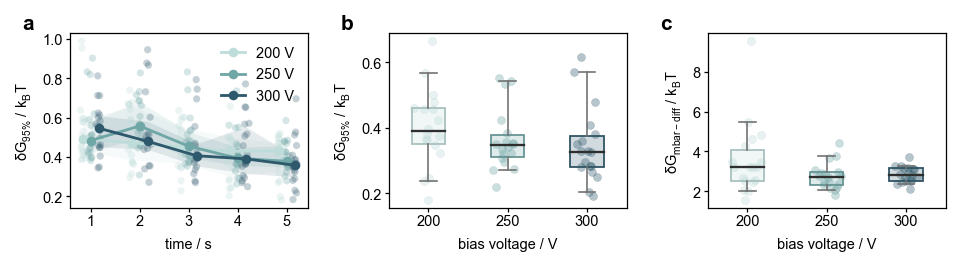

In [171]:
fig_quality = plot_SI_bias_voltage_reconstruction_quality(
    m_list=m_list,
    particles=selected_target_rotors,
    target_voltage_colors=target_voltage_colors,
    C=CK_colors,
    voltages=(200, 250, 300),
    durations_s=(1, 2, 3, 4, 5),


    box_width=0.42,
    box_face_alpha=0.22,
    show_voltage_connections=True,
    panel_label_x_rel=-0.2,
    panel_label_y_rel=0,

    convergence_ylabel=r"$\delta G_{95\%}$ / $k_\mathrm{B}T$",
    final_uncertainty_ylabel=r"$\delta G_{95\%}$ / $k_\mathrm{B}T$",
    rmse_ylabel=r"$\delta G_{\mathrm{mbar}-\mathrm{diff}}$ / $k_\mathrm{B}T$",
    duration_xlabel=r"time / s",
    voltage_xlabel=r"bias voltage / V",

    fig_width_mm=160,
    fig_height_mm=40,
    wspace=0.34,

    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,

    save_dir=save_dir_SI,
    save_prefix="SI_toFig3a_voltage__reconstruction_quality",
)

In [ ]:
raise SystemExit

In [ ]:
this code below has not yet been implemented

#### i. Compute convergence of metrics

In [371]:
def compute_target_region_duration_metrics(
    m_list,
    durations_s=(1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5),
    particles=None,
    center_mode="ensemble",
    angular_cutoff_deg=40.0,
    smooth_nbins=3,
    min_extrema_separation_deg=60.0,
    min_locs_per_window=20,
    min_locs_per_overlap_window=20,
    overlap_bins=72,
    apply_autocorrelation_trim=False,
):
    import numpy as np
    import pandas as pd
    from tqdm.auto import tqdm

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [v for y in x for v in flatten(y)]
        return [x]

    def unique_ints(x):
        if x is None:
            return []
        try:
            x = list(x)
        except TypeError:
            x = [x]
        return list(dict.fromkeys(int(v) for v in x))

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        has_windows = (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(
                isinstance(k, str) and k.startswith("deg-")
                for k in m.protocol
            )
        )
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def wrap_pi(x):
        return (np.asarray(x, float) + np.pi) % (2 * np.pi) - np.pi

    def circ_mean(x):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]

        if x.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * x))
        return float(np.angle(z)) if np.abs(z) > 1e-15 else np.nan

    def kappa_vm(x):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]

        if x.size < 3:
            return np.nan

        R = float(np.clip(np.abs(np.mean(np.exp(1j * x))), 0, 0.999999))

        if R < 0.53:
            kappa = 2 * R + R**3 + 5 * R**5 / 6
        elif R < 0.85:
            kappa = -0.4 + 1.39 * R + 0.43 / (1 - R)
        else:
            kappa = 1 / (R**3 - 4 * R**2 + 3 * R)

        n = x.size

        if n <= 15:
            if kappa < 2:
                kappa = max(
                    kappa - 2 / (n * max(kappa, 1e-12)),
                    0,
                )
            else:
                kappa = (
                    (n - 1) ** 3
                    * kappa
                    / (n**3 + n)
                )

        return float(kappa)

    def overlap(a, b):
        a = wrap_pi(a)
        b = wrap_pi(b)

        a = a[np.isfinite(a)]
        b = b[np.isfinite(b)]

        if a.size < 5 or b.size < 5:
            return np.nan

        edges = np.linspace(
            -np.pi,
            np.pi,
            int(overlap_bins) + 1,
        )

        ha, _ = np.histogram(
            a,
            bins=edges,
            density=True,
        )

        hb, _ = np.histogram(
            b,
            bins=edges,
            density=True,
        )

        return float(
            np.sum(
                np.minimum(ha, hb)
                * np.diff(edges)
            )
        )

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(
                value[0],
                (list, tuple, dict),
            )
        ):
            value = value[0]

        if isinstance(value, dict):
            start = value.get(
                "start",
                value.get(
                    "start_time",
                    value.get(
                        "t_start",
                        value.get("t0"),
                    ),
                ),
            )

            stop = value.get(
                "end",
                value.get(
                    "end_time",
                    value.get(
                        "t_end",
                        value.get(
                            "t1",
                            value.get("stop"),
                        ),
                    ),
                ),
            )

            if start is None or stop is None:
                raise ValueError(
                    f"Cannot parse protocol bounds: {value}"
                )

            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(
            f"Cannot parse protocol bounds: {value}"
        )

    def get_windows(protocol):
        rows = []

        for phase, value in protocol.items():
            if not (
                isinstance(phase, str)
                and phase.startswith("deg-")
            ):
                continue

            start, stop = protocol_bounds(value)

            rows.append({
                "phase": str(phase),
                "start": float(start),
                "stop": float(stop),
            })

        if not rows:
            raise ValueError(
                "No deg-* umbrella windows found."
            )

        return (
            pd.DataFrame(rows)
            .sort_values("start")
            .reset_index(drop=True)
        )

    def ensure_time(m):
        if "t" in m.locs.columns:
            return

        m.locs = m.locs.copy()

        for col in (
            "averagetime",
            "time",
            "time_s",
        ):
            if col in m.locs.columns:
                m.locs["t"] = m.locs[col].astype(float)
                return

        if "frame" not in m.locs.columns:
            raise KeyError(
                "m.locs requires t, averagetime, "
                "time, time_s, or frame."
            )

        dt = float(
            getattr(
                m,
                "_average_tpf",
                getattr(m, "average_tpf", 0.005),
            )
        )

        m.locs["t"] = (
            m.locs["frame"].astype(float)
            * dt
        )

    def smooth_periodic(y, n):
        y = np.asarray(y, float)

        if n is None or int(n) <= 1:
            return y.copy()

        n = int(n)
        pad = n // 2

        extended = np.r_[
            y[-pad:],
            y,
            y[:pad],
        ]

        return np.convolve(
            extended,
            np.ones(n) / n,
            mode="same",
        )[pad:pad + len(y)]

    def find_extrema(phi, energy, minimum=True):
        left = np.roll(energy, 1)
        right = np.roll(energy, -1)

        if minimum:
            candidates = np.where(
                (energy <= left)
                & (energy <= right)
            )[0]
        else:
            candidates = np.where(
                (energy >= left)
                & (energy >= right)
            )[0]

        if candidates.size == 0:
            candidates = np.arange(len(energy))

        order = np.argsort(
            energy[candidates]
            if minimum
            else -energy[candidates]
        )

        candidates = candidates[order]
        chosen = []
        min_separation = np.deg2rad(
            float(min_extrema_separation_deg)
        )

        for index in candidates:
            if all(
                np.abs(
                    wrap_pi(
                        phi[index] - phi[previous]
                    )
                )
                >= min_separation
                for previous in chosen
            ):
                chosen.append(int(index))

            if len(chosen) == 2:
                break

        return phi[np.asarray(chosen, int)]

    def classify_position(position, wells, barriers):
        well_distance = (
            float(
                np.min(
                    np.abs(
                        wrap_pi(position - wells)
                    )
                )
            )
            if len(wells)
            else np.inf
        )

        barrier_distance = (
            float(
                np.min(
                    np.abs(
                        wrap_pi(position - barriers)
                    )
                )
            )
            if len(barriers)
            else np.inf
        )

        if min(
            well_distance,
            barrier_distance,
        ) > np.deg2rad(float(angular_cutoff_deg)):
            return None

        return (
            "well"
            if well_distance <= barrier_distance
            else "barrier"
        )

    def get_item(mapping, particle):
        if not isinstance(mapping, dict):
            return None

        if int(particle) in mapping:
            return mapping[int(particle)]

        if str(int(particle)) in mapping:
            return mapping[str(int(particle))]

        return None

    def first_existing(container, candidates):
        return next(
            (
                key
                for key in candidates
                if key in container
            ),
            None,
        )

    def extract_point_curve(table, particle):
        if hasattr(table, "columns"):
            phi_key = first_existing(
                table.columns,
                (
                    "phi",
                    "phi_rad",
                    "angle",
                    "angle_rad",
                ),
            )

            energy_key = first_existing(
                table.columns,
                (
                    "U_mbar",
                    "U_MBAR",
                    "energy_kBT",
                    "energy",
                    "G",
                ),
            )

            if phi_key is None or energy_key is None:
                raise KeyError(
                    f"Could not extract point-MBAR curve "
                    f"for particle {particle}."
                )

            phi = table[phi_key].to_numpy(float)
            energy = table[energy_key].to_numpy(float)

        elif isinstance(table, dict):
            phi_key = first_existing(
                table,
                (
                    "phi",
                    "phi_rad",
                    "angle",
                    "angle_rad",
                    "centers",
                ),
            )

            energy_key = first_existing(
                table,
                (
                    "U_mbar",
                    "U_MBAR",
                    "energy_kBT",
                    "energy",
                    "G",
                    "E",
                ),
            )

            if phi_key is None or energy_key is None:
                raise KeyError(
                    f"Could not extract point-MBAR curve "
                    f"for particle {particle}."
                )

            phi = np.asarray(
                table[phi_key],
                float,
            )

            energy = np.asarray(
                table[energy_key],
                float,
            )

        else:
            raise TypeError(
                f"Unsupported point-MBAR format "
                f"for particle {particle}."
            )

        if len(phi) != len(energy):
            raise ValueError(
                f"Point-MBAR phi and energy lengths differ "
                f"for particle {particle}."
            )

        finite = (
            np.isfinite(phi)
            & np.isfinite(energy)
        )

        phi = wrap_pi(phi[finite])
        energy = energy[finite]

        if len(phi) < 3:
            raise ValueError(
                f"Too few finite point-MBAR bins "
                f"for particle {particle}."
            )

        order = np.argsort(phi)

        return {
            "phi": phi[order],
            "energy": energy[order],
        }

    def get_reference_curve(m, particle):
        raw = getattr(
            m,
            "energy_landscapes",
            None,
        )

        if not isinstance(raw, dict):
            raise AttributeError(
                "m.energy_landscapes is missing. "
                "Run the ordinary full point-MBAR "
                "reconstruction first."
            )

        table = get_item(
            raw,
            particle,
        )

        if table is None:
            raise KeyError(
                f"Particle {particle} is missing from "
                "m.energy_landscapes."
            )

        return extract_point_curve(
            table,
            particle,
        )

    def get_full_window_centers(m):
        if not hasattr(m, "center_bias"):
            raise AttributeError(
                "m.center_bias is missing. "
                "Run the ordinary full point-MBAR "
                "reconstruction first."
            )

        by_window = m.center_bias["by_window"].copy()

        center_column = (
            "ensemble_phi0"
            if center_mode == "ensemble"
            else "command_phi0"
        )

        if center_column not in by_window.columns:
            raise KeyError(
                f"{center_column!r} is missing from "
                "m.center_bias['by_window']."
            )

        return by_window[
            ["phase", center_column]
        ].rename(
            columns={
                center_column: "window_center"
            }
        )

    measurements = [
        m
        for m in flatten(m_list)
        if is_umb(m)
    ]

    if not measurements:
        raise ValueError(
            "No UMB measurements found."
        )

    durations = tuple(
        sorted(
            set(
                float(value)
                for value in durations_s
            )
        )
    )

    if (
        not durations
        or any(value <= 0 for value in durations)
    ):
        raise ValueError(
            "durations_s must contain positive values."
        )

    for measurement_index, m in enumerate(
        tqdm(
            measurements,
            desc="Target well/barrier metrics",
            dynamic_ncols=True,
        )
    ):
        ensure_time(m)

        if "group" not in m.locs.columns:
            if "group_int" in m.locs.columns:
                m.locs = m.locs.copy()
                m.locs["group"] = (
                    m.locs["group_int"].astype(int)
                )
            else:
                raise KeyError(
                    "m.locs requires 'group' or 'group_int'."
                )

        if "phi" not in m.locs.columns:
            raise KeyError(
                "m.locs requires column 'phi'."
            )

        target_rotors = unique_ints(
            getattr(
                m,
                "target_rotors",
                None,
            )
        )

        requested_particles = (
            unique_ints(particles)
            if particles is not None
            else target_rotors
        )

        target_set = set(target_rotors)

        selected_particles = [
            particle
            for particle in requested_particles
            if particle in target_set
        ]

        if not selected_particles:
            raise ValueError(
                f"UMB {measurement_index}: "
                "no target rotors selected."
            )

        missing_from_target = [
            particle
            for particle in requested_particles
            if particle not in target_set
        ]

        if missing_from_target:
            print(
                f"UMB {measurement_index}: skipped non-target "
                f"particles {missing_from_target}"
            )

        phase_df = get_windows(
            m.protocol
        )

        window_centers = get_full_window_centers(
            m
        )

        trim_s = (
            float(
                getattr(
                    m,
                    "autocorrelation_trim_s",
                    0.0,
                )
            )
            if apply_autocorrelation_trim
            else 0.0
        )

        region_info = {}

        for particle in selected_particles:
            curve = get_reference_curve(
                m,
                particle,
            )

            phi = curve["phi"]
            energy = curve["energy"]

            smoothed_energy = smooth_periodic(
                energy,
                smooth_nbins,
            )

            wells = find_extrema(
                phi,
                smoothed_energy,
                minimum=True,
            )

            barriers = find_extrema(
                phi,
                smoothed_energy,
                minimum=False,
            )

            if len(wells) < 2 or len(barriers) < 2:
                raise RuntimeError(
                    f"Particle {particle}: could not identify "
                    "two wells and two barriers."
                )

            window_info = phase_df.merge(
                window_centers,
                on="phase",
                how="left",
            )

            if window_info[
                "window_center"
            ].isna().any():
                missing_phases = window_info.loc[
                    window_info[
                        "window_center"
                    ].isna(),
                    "phase",
                ].tolist()

                raise ValueError(
                    f"Particle {particle}: missing window "
                    f"centers for {missing_phases}."
                )

            window_info["window_center"] = wrap_pi(
                window_info[
                    "window_center"
                ].to_numpy(float)
            )

            window_info["region"] = [
                classify_position(
                    position,
                    wells,
                    barriers,
                )
                for position in window_info[
                    "window_center"
                ]
            ]

            ordered_windows = (
                window_info
                .sort_values("window_center")
                .reset_index(drop=True)
            )

            pair_rows = []

            for i in range(len(ordered_windows)):
                j = (
                    i + 1
                ) % len(ordered_windows)

                midpoint = circ_mean([
                    ordered_windows.loc[
                        i,
                        "window_center",
                    ],
                    ordered_windows.loc[
                        j,
                        "window_center",
                    ],
                ])

                pair_rows.append({
                    "phase_a": ordered_windows.loc[
                        i,
                        "phase",
                    ],
                    "phase_b": ordered_windows.loc[
                        j,
                        "phase",
                    ],
                    "midpoint": float(midpoint),
                    "region": classify_position(
                        midpoint,
                        wells,
                        barriers,
                    ),
                })

            region_info[int(particle)] = {
                "wells": np.asarray(
                    wells,
                    float,
                ),
                "barriers": np.asarray(
                    barriers,
                    float,
                ),
                "windows": window_info.copy(),
                "pairs": pd.DataFrame(pair_rows),
            }

        groups = m.locs[
            "group"
        ].astype(int).to_numpy()

        times = m.locs[
            "t"
        ].astype(float).to_numpy()

        phi_all = m.locs[
            "phi"
        ].astype(float).to_numpy()

        rotor_rows = []

        for duration in tqdm(
            durations,
            desc="Time per window",
            leave=False,
            dynamic_ncols=True,
        ):
            for particle in selected_particles:
                info = region_info[
                    int(particle)
                ]

                phase_phi = {}
                phase_metrics = {}

                for _, window in info[
                    "windows"
                ].iterrows():
                    start = (
                        float(window["start"])
                        + trim_s
                    )

                    stop = min(
                        float(window["stop"]),
                        float(window["start"])
                        + float(duration),
                    )

                    mask = (
                        (groups == int(particle))
                        & (times >= start)
                        & (times < stop)
                    )

                    values = wrap_pi(
                        phi_all[mask]
                    )

                    values = values[
                        np.isfinite(values)
                    ]

                    phase = window["phase"]
                    phase_phi[phase] = values

                    if values.size < int(
                        min_locs_per_window
                    ):
                        phase_metrics[phase] = {
                            "center_error": np.nan,
                            "kappa": np.nan,
                            "half_overlap": np.nan,
                        }
                        continue

                    mean_angle = circ_mean(
                        values
                    )

                    centered = wrap_pi(
                        values - mean_angle
                    )

                    half = values.size // 2

                    phase_metrics[phase] = {
                        "center_error": float(
                            np.abs(
                                np.rad2deg(
                                    wrap_pi(
                                        mean_angle
                                        - float(
                                            window[
                                                "window_center"
                                            ]
                                        )
                                    )
                                )
                            )
                        ),
                        "kappa": kappa_vm(
                            centered
                        ),
                        "half_overlap": (
                            overlap(
                                centered[:half],
                                centered[half:],
                            )
                            if (
                                half >= 5
                                and values.size - half >= 5
                            )
                            else np.nan
                        ),
                    }

                collected = {
                    region: {
                        metric: []
                        for metric in (
                            "center_error",
                            "kappa",
                            "half_overlap",
                            "neighbor_overlap",
                        )
                    }
                    for region in (
                        "well",
                        "barrier",
                    )
                }

                for _, window in info[
                    "windows"
                ].iterrows():
                    region = window["region"]

                    if region not in collected:
                        continue

                    values = phase_metrics[
                        window["phase"]
                    ]

                    for metric in (
                        "center_error",
                        "kappa",
                        "half_overlap",
                    ):
                        if np.isfinite(
                            values[metric]
                        ):
                            collected[
                                region
                            ][metric].append(
                                float(values[metric])
                            )

                for _, pair in info[
                    "pairs"
                ].iterrows():
                    region = pair["region"]

                    if region not in collected:
                        continue

                    a = phase_phi[
                        pair["phase_a"]
                    ]

                    b = phase_phi[
                        pair["phase_b"]
                    ]

                    if (
                        a.size
                        < int(
                            min_locs_per_overlap_window
                        )
                        or b.size
                        < int(
                            min_locs_per_overlap_window
                        )
                    ):
                        continue

                    value = overlap(
                        a,
                        b,
                    )

                    if np.isfinite(value):
                        collected[
                            region
                        ][
                            "neighbor_overlap"
                        ].append(
                            float(value)
                        )

                output = {
                    "measurement_index": int(
                        measurement_index
                    ),
                    "particle": int(
                        particle
                    ),
                    "duration_s": float(
                        duration
                    ),
                }

                for region in (
                    "well",
                    "barrier",
                ):
                    for metric in (
                        "center_error",
                        "kappa",
                        "half_overlap",
                        "neighbor_overlap",
                    ):
                        values = collected[
                            region
                        ][metric]

                        output[
                            f"{metric}_{region}"
                        ] = (
                            float(
                                np.nanmedian(values)
                            )
                            if values
                            else np.nan
                        )

                        output[
                            f"n_{metric}_{region}"
                        ] = int(
                            len(values)
                        )

                rotor_rows.append(
                    output
                )

        rotor_df = pd.DataFrame(
            rotor_rows
        )

        m.target_region_duration_metrics = {
            "durations_s": tuple(
                durations
            ),
            "particles": tuple(
                selected_particles
            ),
            "reference_region_info": region_info,
            "rotor_df": rotor_df,
            "settings": {
                "reference_source": (
                    "ordinary point MBAR: "
                    "m.energy_landscapes"
                ),
                "center_mode": str(
                    center_mode
                ),
                "angular_cutoff_deg": float(
                    angular_cutoff_deg
                ),
                "smooth_nbins": int(
                    smooth_nbins
                ),
                "min_extrema_separation_deg": float(
                    min_extrema_separation_deg
                ),
                "min_locs_per_window": int(
                    min_locs_per_window
                ),
                "min_locs_per_overlap_window": int(
                    min_locs_per_overlap_window
                ),
                "overlap_bins": int(
                    overlap_bins
                ),
                "apply_autocorrelation_trim": bool(
                    apply_autocorrelation_trim
                ),
            },
        }

    return None

In [ ]:
def compute_target_region_duration_metrics_by_voltage(
    m_list,
    durations_s=(1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5),
    particles=None,
    particles_by_voltage=None,
    center_mode="ensemble",
    angular_cutoff_deg=40.0,
    smooth_nbins=3,
    min_extrema_separation_deg=60.0,
    min_locs_per_window=20,
    min_locs_per_overlap_window=20,
    overlap_bins=72,
    apply_autocorrelation_trim=False,
):
    import re
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [v for y in x for v in flatten(y)]
        return [x]

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        has_windows = hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(key, str) and key.startswith("deg-") for key in m.protocol
        )
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def extract_voltage(m):
        for attr in ("voltage", "voltage_V", "bias_voltage", "umb_voltage", "UMB_voltage"):
            value = getattr(m, attr, None)
            if value is None:
                continue
            try:
                value = float(value)
                return int(value) if value.is_integer() else value
            except (TypeError, ValueError):
                pass

        for container_name in ("metadata", "meta", "settings"):
            container = getattr(m, container_name, None)
            if not isinstance(container, dict):
                continue
            for key in ("voltage", "voltage_V", "bias_voltage", "umb_voltage", "UMB_voltage"):
                if key not in container:
                    continue
                try:
                    value = float(container[key])
                    return int(value) if value.is_integer() else value
                except (TypeError, ValueError):
                    pass

        name = Path(str(getattr(m, "path", ""))).name
        matches = re.findall(r"(?<!\d)(\d+(?:\.\d+)?)\s*[Vv](?![A-Za-z])", name)
        if not matches:
            matches = re.findall(r"(?:^|[_\-\s])(\d+(?:\.\d+)?)(?=[_\-\s]|$)", name)

        if not matches:
            raise ValueError(f"Could not determine the voltage from measurement {name!r}.")

        value = float(matches[-1])
        return int(value) if value.is_integer() else value

    def extract_replicate(m):
        for attr in ("replicate", "replicate_index", "repeat", "run"):
            value = getattr(m, attr, None)
            if value is not None:
                return value

        name = Path(str(getattr(m, "path", ""))).name
        match = re.search(r"(?:rep(?:licate)?|run|repeat)[_\-\s]*(\d+)", name, flags=re.IGNORECASE)
        return int(match.group(1)) if match else np.nan

    measurements = [m for m in flatten(m_list) if is_umb(m)]
    if not measurements:
        raise ValueError("No UMB measurements found.")

    combined_rows = []

    for measurement_index, m in enumerate(tqdm(measurements, desc="Voltage-resolved duration metrics", dynamic_ncols=True)):
        voltage = extract_voltage(m)

        if particles_by_voltage is not None:
            selected_particles = particles_by_voltage.get(voltage, particles_by_voltage.get(str(voltage)))
        else:
            selected_particles = particles

        compute_target_region_duration_metrics(
            m_list=[m],
            durations_s=durations_s,
            particles=selected_particles,
            center_mode=center_mode,
            angular_cutoff_deg=angular_cutoff_deg,
            smooth_nbins=smooth_nbins,
            min_extrema_separation_deg=min_extrema_separation_deg,
            min_locs_per_window=min_locs_per_window,
            min_locs_per_overlap_window=min_locs_per_overlap_window,
            overlap_bins=overlap_bins,
            apply_autocorrelation_trim=apply_autocorrelation_trim,
        )

        rotor_df = m.target_region_duration_metrics["rotor_df"].copy()
        rotor_df["measurement_index"] = measurement_index
        rotor_df["voltage_V"] = voltage
        rotor_df["replicate"] = extract_replicate(m)
        rotor_df["measurement_name"] = Path(str(getattr(m, "path", f"UMB_{measurement_index}"))).name

        first_columns = ["measurement_index", "measurement_name", "voltage_V", "replicate", "particle", "duration_s"]
        rotor_df = rotor_df[first_columns + [column for column in rotor_df.columns if column not in first_columns]]

        m.target_region_duration_metrics["voltage_V"] = voltage
        m.target_region_duration_metrics["replicate"] = extract_replicate(m)
        m.target_region_duration_metrics["rotor_df"] = rotor_df
        combined_rows.append(rotor_df)

    combined_df = pd.concat(combined_rows, ignore_index=True)
    combined_df = combined_df.sort_values(
        ["voltage_V", "replicate", "measurement_index", "particle", "duration_s"],
        kind="stable",
        na_position="last",
    ).reset_index(drop=True)

    return combined_df

In [ ]:
target_region_duration_metrics_df = compute_target_region_duration_metrics_by_voltage(
    m_list=m_list,
    durations_s=(1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5),
    particles=None,
    center_mode="ensemble",
    angular_cutoff_deg=40.0,
    smooth_nbins=3,
    min_extrema_separation_deg=60.0,
    min_locs_per_window=20,
    min_locs_per_overlap_window=20,
    overlap_bins=72,
    apply_autocorrelation_trim=False,
)

#### ii. Plot convergence of metrics for target rotors

In [ ]:
def plot_target_region_metric_convergence(
    m_list,
    measurement_index=0,
    region_labels=("well", "barrier"),
    panel_labels=("a", "b", "c", "d"),
    panel_label_x=-0.22,
    panel_label_y=1.05,
    panel_label_fontsize=8,
    fig_width_mm=180,
    fig_height_mm=52,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    target_colors=None,
    line_lw=1.05,
    marker_size=3.2,
    band_alpha=0.12,
    n_y_ticks=(5, 5, 5, 5),
    save_dir=None,
    save_prefix="target_region_metric_convergence",
    stator_variant=None,
    C=None,
    dpi=300,
):
    import numpy as np
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.ticker import MaxNLocator, FormatStrFormatter

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [v for y in x for v in flatten(y)]
        return [x]

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        has_windows = (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol)
        )
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def rgb(x):
        x = np.asarray(x, float).ravel()[:3]
        if np.nanmax(x) > 1:
            x = x / 255
        return tuple(map(float, x))

    def mm(x):
        return float(x) / 25.4

    if C is None:
        C = {"black": (0, 0, 0)}

    C = C() if callable(C) else dict(C)
    black = rgb(C.get("black", (0, 0, 0)))

    if target_colors is None:
        target_colors = {
            "well": (111 / 255, 166 / 255, 166 / 255),
            "barrier": (46 / 255, 89 / 255, 108 / 255),
        }

    styles = {
        "well": {
            "color": rgb(target_colors["well"]),
            "marker": "o",
            "linestyle": "-",
        },
        "barrier": {
            "color": rgb(target_colors["barrier"]),
            "marker": "s",
            "linestyle": "--",
        },
    }

    measurements = [m for m in flatten(m_list) if is_umb(m)]

    if not 0 <= int(measurement_index) < len(measurements):
        raise IndexError(
            f"measurement_index={measurement_index} is invalid. "
            f"Available indices: {list(range(len(measurements)))}"
        )

    m = measurements[int(measurement_index)]

    if not hasattr(m, "target_region_duration_metrics"):
        raise AttributeError(
            "m.target_region_duration_metrics is missing. "
            "Run compute_target_region_duration_metrics(...) first."
        )

    df = m.target_region_duration_metrics["rotor_df"].copy()

    if df.empty:
        raise ValueError(
            "target_region_duration_metrics['rotor_df'] is empty."
        )

    durations = np.asarray(
        sorted(df["duration_s"].dropna().astype(float).unique()),
        float,
    )

    metrics = [
        (
            "center_error",
            r"$\langle|\Delta\varphi|\rangle$ / °",
            "%.0f",
        ),
        (
            "kappa",
            r"$\langle\kappa\rangle$ / $k_\mathrm{B}T\,\mathrm{rad}^{-2}$",
            "%.0f",
        ),
        (
            "half_overlap",
            r"$\langle O_{1/2}\rangle$",
            "%.2f",
        ),
        (
            "neighbor_overlap",
            r"$\langle O_{n,n+1}\rangle$",
            "%.2f",
        ),
    ]

    if np.isscalar(n_y_ticks):
        n_y_ticks = (int(n_y_ticks),) * 4
    else:
        n_y_ticks = tuple(map(int, n_y_ticks))

    if len(n_y_ticks) != 4:
        raise ValueError("n_y_ticks must contain four values.")

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.6,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(mm(fig_width_mm), mm(fig_height_mm)),
    )

    legend_handles = []

    for ai, (ax, (metric, ylabel, y_format)) in enumerate(zip(axes, metrics)):
        for region, label in zip(("well", "barrier"), region_labels):
            column = f"{metric}_{region}"
            rows = []

            for duration in durations:
                values = df.loc[
                    np.isclose(
                        df["duration_s"].to_numpy(float),
                        float(duration),
                    ),
                    column,
                ].to_numpy(float)

                values = values[np.isfinite(values)]

                if values.size:
                    rows.append((
                        float(duration),
                        float(np.mean(values)),
                        float(np.std(values, ddof=1)) if values.size > 1 else 0.0,
                    ))

            if not rows:
                continue

            x, mean, std = [np.asarray(v, float) for v in zip(*rows)]
            lower, upper = mean - std, mean + std

            if metric in {"half_overlap", "neighbor_overlap"}:
                lower = np.clip(lower, 0, 1)
                upper = np.clip(upper, 0, 1)

            style = styles[region]

            ax.fill_between(
                x,
                lower,
                upper,
                color=style["color"],
                alpha=band_alpha,
                linewidth=0,
                zorder=1,
            )

            line, = ax.plot(
                x,
                mean,
                color=style["color"],
                marker=style["marker"],
                linestyle=style["linestyle"],
                lw=line_lw,
                ms=marker_size,
                markerfacecolor=style["color"],
                markeredgecolor=black,
                markeredgewidth=0.45,
                alpha=0.98,
                zorder=5,
                label=str(label),
            )

            if ai == 0:
                legend_handles.append(line)

        ax.set_xlabel("time / s", fontsize=axis_label_size)
        ax.set_ylabel(ylabel, fontsize=axis_label_size)

        ax.set_xlim(
            np.floor(durations.min()) - 0.15,
            np.ceil(durations.max()) + 0.15,
        )

        integer_xticks = np.arange(
            int(np.ceil(durations.min())),
            int(np.floor(durations.max())) + 1,
        )

        ax.set_xticks(integer_xticks)
        ax.set_xticklabels([str(int(x)) for x in integer_xticks])

        # Keep half-second positions as short unlabeled x ticks.
        half_xticks = durations[
            ~np.isclose(durations, np.round(durations))
        ]
        ax.set_xticks(half_xticks, minor=True)

        ax.tick_params(
            axis="x",
            which="minor",
            length=1.4,
            width=0.5,
        )

        # Every visible y tick is a labeled major tick.
        ax.yaxis.set_major_locator(
            MaxNLocator(
                nbins=n_y_ticks[ai],
                min_n_ticks=4,
            )
        )
        ax.yaxis.set_major_formatter(
            FormatStrFormatter(y_format)
        )
        ax.yaxis.set_minor_locator(
            plt.NullLocator()
        )

        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

        ax.tick_params(
            which="major",
            length=2.0,
            width=0.6,
            labelsize=tick_label_size,
            color=black,
            labelcolor=black,
            pad=1.5,
        )

        ax.grid(False)

        if panel_labels is not None and ai < len(panel_labels):
            ax.text(
                panel_label_x,
                panel_label_y,
                str(panel_labels[ai]),
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=panel_label_fontsize,
                fontname="Arial",
                fontweight="bold",
                color=black,
            )

    axes[0].legend(
        handles=legend_handles,
        labels=[str(handle.get_label()) for handle in legend_handles],
        loc="upper right",
        frameon=False,
        fontsize=annotation_size,
        handlelength=1.8,
        borderaxespad=0.2,
        labelspacing=0.25,
        handletextpad=0.4,
    )

    fig.subplots_adjust(
        left=0.065,
        right=0.99,
        bottom=0.20,
        top=0.97,
        wspace=0.48,
    )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        prefix = (
            f"{stator_variant}__"
            if stator_variant is not None and str(stator_variant).strip()
            else ""
        )
        filename = f"{prefix}{save_prefix}"

        fig.savefig(
            save_dir / f"{filename}.png",
            dpi=int(dpi),
            bbox_inches="tight",
        )
        fig.savefig(
            save_dir / f"{filename}.svg",
            bbox_inches="tight",
        )

    return fig

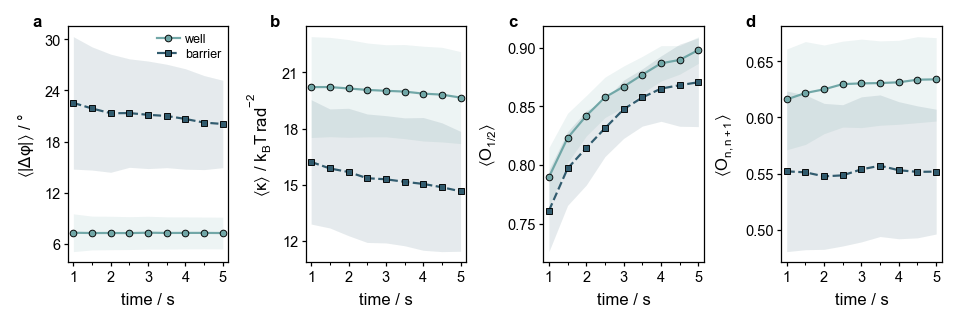

In [378]:
fig_target_region_convergence = plot_target_region_metric_convergence(
    m_list=m_list,
    measurement_index=0,
    region_labels=("well", "barrier"),
    panel_labels=("a", "b", "c", "d"),
    panel_label_x=-0.22,
    panel_label_y=1.05,
    panel_label_fontsize=8,
    fig_width_mm=160,
    fig_height_mm=52,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    target_colors={
        "well": (111 / 255, 166 / 255, 166 / 255),
        "barrier": (46 / 255, 89 / 255, 108 / 255),
    },
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d__convergence_target_metric_stats",
    stator_variant=stator_variant if "stator_variant" in globals() else None,
    C=CK_colors,
)



# Code not used

## _[SI | Sensitivity of reconstruction with different calibration rotors subsets]_

#### i. Perform reconstruction based on bias from different calibration rotor subsets

In [ ]:
def compute_MBAR_calibration_ensemble_sensitivity(
    m_list,
    particles=None,
    center_mode="ensemble",
    bias_potential="cosine",
    subset_mode="random_subsets",
    subset_size=None,
    n_subsets=100,
    explicit_subsets=None,
    nbins=72,
    pmin_nan=1e-12,
    subset_interval=(2.5, 97.5),
    seed=1,
    min_keep=200,
    kappa_mode=None,
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    """
    Test the sensitivity of target-rotor MBAR reconstructions to the
    selected calibration-rotor ensemble.

    For every calibration subset:

        stored rotor-wise kappa
            -> arithmetic mean across selected calibration rotors

        stored rotor-wise mu_fit
            -> circular mean across selected calibration rotors

        optional periodic rolling mean of kappa

        subset-specific kappa and center
            -> MBAR reconstruction using the complete target trajectories

    No temporal blocks or bootstrap resampling are used.

    Measurement selection
    ---------------------
    m_list=m_list:
        process every UMB measurement

    m_list=m_list[1]:
        process only that measurement

    Particle selection
    ------------------
    particles=None:
        process all m.target_rotors of each measurement

    particles=[...]:
        process only the selected target rotors

    Stores for every processed UMB measurement
    -------------------------------------------
    m.mbar_calibration_ensemble_sensitivity = {
        "curves": curves,
        "summary_df": summary_df,
    }

    Nothing is returned.
    """
    import math
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    # ==================================================================
    # helpers
    # ==================================================================

    def flatten(obj):
        if isinstance(obj, (list, tuple)):
            out = []

            for item in obj:
                out.extend(flatten(item))

            return out

        return [obj]

    def measurement_name(m):
        try:
            return Path(str(m.path)).name
        except Exception:
            return "UMB measurement"

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)

        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])

        return U

    def align_to_reference(U, U_ref):
        U = np.asarray(U, dtype=float).copy()
        U_ref = np.asarray(U_ref, dtype=float)

        finite = np.isfinite(U) & np.isfinite(U_ref)

        if np.sum(finite) >= 3:
            U -= np.nanmedian(U[finite] - U_ref[finite])

        return U

    def logsumexp(a, axis=None):
        a = np.asarray(a, dtype=float)

        amax = np.max(
            a,
            axis=axis,
            keepdims=True,
        )

        out = amax + np.log(
            np.sum(
                np.exp(a - amax),
                axis=axis,
                keepdims=True,
            )
        )

        if axis is None:
            return np.squeeze(out)

        return np.squeeze(
            out,
            axis=axis,
        )

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(
            np.exp(1j * phi)
        )

        if abs(z) < 1e-15:
            return np.nan

        return float(
            np.angle(z)
        )

    def periodic_mean(values, window):
        values = np.asarray(values, dtype=float)

        if values.size == 0:
            return values.copy()

        window = int(window)

        if window <= 1:
            return values.copy()

        if window % 2 == 0:
            window += 1

        half = window // 2

        out = np.full(
            values.size,
            np.nan,
        )

        for i in range(values.size):
            idx = [
                (i + shift) % values.size
                for shift in range(-half, half + 1)
            ]

            local = values[idx]
            local = local[np.isfinite(local)]

            if local.size:
                out[i] = float(
                    np.mean(local)
                )

        return out

    def has_deg_protocol(m):
        return (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(
                isinstance(key, str)
                and key.startswith("deg-")
                for key in m.protocol
            )
        )

    def is_umb(m):
        name = str(
            getattr(m, "path", "")
        ).upper()

        if "DIFF" in name:
            return False

        return (
            "UMB" in name
            or has_deg_protocol(m)
        )

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            start = value.get(
                "start",
                value.get(
                    "start_time",
                    value.get(
                        "t_start",
                        value.get("t0"),
                    ),
                ),
            )

            stop = value.get(
                "end",
                value.get(
                    "end_time",
                    value.get(
                        "t_end",
                        value.get(
                            "t1",
                            value.get("stop"),
                        ),
                    ),
                ),
            )

            if start is None or stop is None:
                raise ValueError(
                    f"Cannot parse protocol bounds: {value}"
                )

            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(
            f"Cannot parse protocol bounds: {value}"
        )

    def protocol_windows(m):
        rows = []

        for phase, bounds in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue

            deg = float(
                phase.split("-")[1].split("_")[0]
            )

            start, stop = protocol_bounds(
                bounds
            )

            rows.append({
                "phase": str(phase),
                "deg": float(deg),
                "command_phi0": float(
                    wrap_pi(
                        np.deg2rad(deg) - np.pi / 2
                    )
                ),
                "start": float(start),
                "stop": float(stop),
            })

        if not rows:
            raise ValueError(
                "No valid deg-* umbrella windows found."
            )

        return (
            pd.DataFrame(rows)
            .sort_values("command_phi0")
            .reset_index(drop=True)
        )

    def get_column(df, candidates):
        for column in candidates:
            if column in df.columns:
                return column

        raise KeyError(
            f"Could not find any of {candidates}. "
            f"Available columns: {list(df.columns)}"
        )

    def ensure_time(m):
        if "t" in m.locs.columns:
            return

        m.locs = m.locs.copy()

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)

        elif "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)

        elif "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)

        elif "frame" in m.locs.columns:
            dt = float(
                getattr(
                    m,
                    "_average_tpf",
                    0.005,
                )
            )

            m.locs["t"] = (
                m.locs["frame"].astype(float)
                * dt
            )

        else:
            raise KeyError(
                "m.locs needs t, averagetime, time, time_s, or frame."
            )

    def lag1(values):
        values = np.asarray(
            values,
            dtype=float,
        )

        if values.size < 3:
            return 0.0

        a = values[:-1] - np.mean(values[:-1])
        b = values[1:] - np.mean(values[1:])

        denominator = (
            np.sqrt(
                np.sum(a * a)
                * np.sum(b * b)
            )
            + 1e-30
        )

        return float(
            np.sum(a * b)
            / denominator
        )

    def circular_lag1(phi):
        rho = 0.5 * (
            lag1(np.cos(phi))
            + lag1(np.sin(phi))
        )

        return float(
            np.clip(
                rho,
                -0.99,
                0.99,
            )
        )

    def collect_target_samples(m, particle, windows):
        ensure_time(m)

        if "group" not in m.locs.columns:
            raise KeyError(
                "m.locs needs 'group'."
            )

        if "phi" not in m.locs.columns:
            raise KeyError(
                "m.locs needs 'phi'."
            )

        trim_s = float(
            m.autocorrelation_trim_s
        )

        if not np.isfinite(trim_s) or trim_s < 0:
            raise ValueError(
                "m.autocorrelation_trim_s is missing or invalid."
            )

        dt = float(
            getattr(
                m,
                "_average_tpf",
                0.005,
            )
        )

        n_trim = max(
            5,
            int(
                np.ceil(
                    trim_s / dt
                )
            ),
        )

        data = m.locs.loc[
            m.locs["group"].astype(int) == int(particle),
            ["phi", "t"],
        ].copy()

        if data.empty:
            raise ValueError(
                f"Particle {particle}: no localizations."
            )

        data = data.sort_values(
            "t",
            kind="mergesort",
        )

        data["phi"] = wrap_pi(
            data["phi"].to_numpy(float)
        )

        samples = []
        phases = []

        for row in windows.itertuples():
            select = (
                (data["t"] >= float(row.start))
                & (data["t"] < float(row.stop))
            )

            phi = data.loc[
                select,
                "phi",
            ].to_numpy(float)

            if phi.size < int(min_keep):
                continue

            if phi.size > n_trim + 5:
                phi = phi[n_trim:]

            if phi.size < int(min_keep):
                continue

            rho = circular_lag1(phi)

            denominator = 1 + rho

            ess = (
                phi.size
                * (1 - rho)
                / denominator
                if denominator > 1e-12
                else float(phi.size)
            )

            if ess < 10:
                continue

            samples.append(
                wrap_pi(phi)
            )

            phases.append(
                str(row.phase)
            )

        if len(samples) < 3:
            raise ValueError(
                f"Particle {particle}: fewer than three valid umbrella windows."
            )

        return samples, phases

    def stored_calibration_arrays(m, phases):
        df = m.kappa_calibration_by_window.copy()

        particle_col = get_column(
            df,
            ["particle"],
        )

        phase_col = get_column(
            df,
            ["phase"],
        )

        kappa_col = get_column(
            df,
            [
                "kappa",
                "kappa_vm",
                "kappa_theta_over_kBT_rad2",
            ],
        )

        center_col = get_column(
            df,
            [
                "mu_fit",
                "mu_fit_rad",
            ],
        )

        calibration_rotors = np.asarray(
            sorted(
                set(
                    map(
                        int,
                        m.calibration_rotors,
                    )
                )
            ),
            dtype=int,
        )

        df = df[
            df[particle_col]
            .astype(int)
            .isin(calibration_rotors)
        ].copy()

        if df.empty:
            raise ValueError(
                "No calibration-rotor fits found in "
                "m.kappa_calibration_by_window."
            )

        rotor_to_row = {
            particle: i
            for i, particle in enumerate(calibration_rotors)
        }

        phase_to_col = {
            phase: i
            for i, phase in enumerate(phases)
        }

        kappa = np.full(
            (
                len(calibration_rotors),
                len(phases),
            ),
            np.nan,
        )

        center = np.full_like(
            kappa,
            np.nan,
        )

        for row in df.itertuples(index=False):
            particle = int(
                getattr(
                    row,
                    particle_col,
                )
            )

            phase = str(
                getattr(
                    row,
                    phase_col,
                )
            )

            if particle not in rotor_to_row or phase not in phase_to_col:
                continue

            i = rotor_to_row[particle]
            j = phase_to_col[phase]

            kval = float(
                getattr(
                    row,
                    kappa_col,
                )
            )

            mu = float(
                getattr(
                    row,
                    center_col,
                )
            )

            if np.isfinite(kval) and kval > 0:
                kappa[i, j] = kval

            if np.isfinite(mu):
                center[i, j] = mu

        return (
            calibration_rotors,
            kappa,
            center,
        )

    def calibration_from_subset(
        selected_rows,
        kappa_by_rotor,
        center_by_rotor,
        command_center,
    ):
        selected_rows = np.asarray(
            selected_rows,
            dtype=int,
        )

        n_windows = kappa_by_rotor.shape[1]

        kappa_raw = np.full(
            n_windows,
            np.nan,
        )

        ensemble_center = np.full(
            n_windows,
            np.nan,
        )

        for j in range(n_windows):
            kval = kappa_by_rotor[
                selected_rows,
                j,
            ]

            kval = kval[
                np.isfinite(kval)
                & (kval > 0)
            ]

            if kval.size:
                kappa_raw[j] = float(
                    np.mean(kval)
                )

            ensemble_center[j] = circular_mean(
                center_by_rotor[
                    selected_rows,
                    j,
                ]
            )

            if not np.isfinite(
                ensemble_center[j]
            ):
                ensemble_center[j] = command_center[j]

        if rolling_mean_kappa_ensemble:
            kappa_used = periodic_mean(
                kappa_raw,
                rolling_mean_kappa_window,
            )

        else:
            kappa_used = kappa_raw.copy()

        finite = (
            np.isfinite(kappa_used)
            & (kappa_used > 0)
        )

        if not np.any(finite):
            raise ValueError(
                "Selected calibration subset has no finite kappa values."
            )

        global_kappa = float(
            np.mean(
                kappa_used[finite]
            )
        )

        if kappa_mode == "global":
            kappa_used = np.full(
                n_windows,
                global_kappa,
            )

        elif kappa_mode == "by_angle":
            missing = (
                ~np.isfinite(kappa_used)
                | (kappa_used <= 0)
            )

            kappa_used[missing] = global_kappa

        else:
            raise ValueError(
                "kappa_mode must be 'global' or 'by_angle'."
            )

        return (
            kappa_used,
            wrap_pi(ensemble_center),
        )

    def run_mbar(samples, centers, kappa):
        counts = np.asarray(
            [
                len(sample)
                for sample in samples
            ],
            dtype=float,
        )

        phi = wrap_pi(
            np.concatenate(samples)
        )

        centers = np.asarray(
            centers,
            dtype=float,
        )

        kappa = np.asarray(
            kappa,
            dtype=float,
        )

        delta = wrap_pi(
            phi[None, :]
            - centers[:, None]
        )

        if bias_potential == "cosine":
            u_kn = (
                kappa[:, None]
                * (
                    1
                    - np.cos(delta)
                )
            )

        elif bias_potential == "harmonic":
            u_kn = (
                0.5
                * kappa[:, None]
                * delta**2
            )

        else:
            raise ValueError(
                "bias_potential must be 'cosine' or 'harmonic'."
            )

        log_counts = np.log(
            counts
        )

        f_k = np.zeros(
            len(samples)
        )

        converged = False
        max_delta = np.nan

        for iteration in range(
            int(mbar_max_iter)
        ):
            log_denominator = logsumexp(
                log_counts[:, None]
                + f_k[:, None]
                - u_kn,
                axis=0,
            )

            f_new = np.asarray([
                -logsumexp(
                    -u_kn[i]
                    - log_denominator
                )
                for i in range(len(f_k))
            ])

            f_new -= f_new[0]

            f_next = (
                (1 - float(mbar_damp))
                * f_k
                + float(mbar_damp)
                * f_new
            )

            max_delta = float(
                np.max(
                    np.abs(
                        f_next - f_k
                    )
                )
            )

            f_k = f_next

            if max_delta < float(mbar_tol):
                converged = True
                break

        log_denominator = logsumexp(
            log_counts[:, None]
            + f_k[:, None]
            - u_kn,
            axis=0,
        )

        log_weights = -log_denominator

        log_weights -= logsumexp(
            log_weights
        )

        weights = np.exp(
            log_weights
        )

        edges = np.linspace(
            -np.pi,
            np.pi,
            int(nbins) + 1,
        )

        phi_grid = 0.5 * (
            edges[:-1]
            + edges[1:]
        )

        dphi = float(
            edges[1]
            - edges[0]
        )

        probability, _ = np.histogram(
            phi,
            bins=edges,
            weights=weights,
        )

        probability = (
            probability.astype(float)
            / dphi
        )

        norm = float(
            probability.sum()
            * dphi
        )

        if norm > 0:
            probability /= norm

        energy = np.full(
            probability.size,
            np.nan,
        )

        positive = (
            probability > 0
        )

        energy[positive] = -np.log(
            probability[positive]
        )

        if pmin_nan is not None and pmin_nan > 0:
            energy[
                probability
                < float(pmin_nan)
            ] = np.nan

        weight_square_sum = float(
            np.sum(
                weights**2
            )
        )

        ess = (
            1 / weight_square_sum
            if weight_square_sum > 0
            else np.nan
        )

        return {
            "phi": phi_grid,
            "U": zero_min(energy),
            "converged": bool(converged),
            "n_iter": int(iteration + 1),
            "ess": float(ess),
        }

    # ==================================================================
    # measurements
    # ==================================================================

    measurements = [
        m
        for m in flatten(m_list)
        if is_umb(m)
    ]

    if not measurements:
        raise ValueError(
            "No UMB measurements found."
        )

    for m in tqdm(
        measurements,
        total=len(measurements),
        desc="MBAR sensitivity measurements",
        dynamic_ncols=True,
    ):
        required = [
            "locs",
            "protocol",
            "calibration_rotors",
            "target_rotors",
            "kappa_calibration_by_window",
            "autocorrelation_trim_s",
            "reconstructed_energy_landscapes_by_center",
        ]

        missing = [
            name
            for name in required
            if not hasattr(m, name)
        ]

        if missing:
            raise AttributeError(
                f"{measurement_name(m)}: missing {missing}"
            )

        try:
            point_landscapes = (
                m
                .reconstructed_energy_landscapes_by_center[
                    center_mode
                ][
                    bias_potential
                ]
            )

        except Exception as exc:
            raise KeyError(
                f"{measurement_name(m)}: no point MBAR reconstruction "
                f"for center_mode={center_mode!r}, "
                f"bias_potential={bias_potential!r}."
            ) from exc

        windows = protocol_windows(m)

        phases = windows[
            "phase"
        ].tolist()

        command_center = windows[
            "command_phi0"
        ].to_numpy(float)

        target_rotors = list(
            map(
                int,
                m.target_rotors,
            )
        )

        if particles is None:
            particles_to_compute = target_rotors.copy()

        else:
            requested_particles = list(
                map(
                    int,
                    particles,
                )
            )

            particles_to_compute = [
                particle
                for particle in requested_particles
                if particle in target_rotors
            ]

        particles_to_compute = [
            particle
            for particle in particles_to_compute
            if particle in point_landscapes
        ]

        if not particles_to_compute:
            raise ValueError(
                f"{measurement_name(m)}: no selected target rotors "
                "have a stored point MBAR reconstruction."
            )

        kappa_mode_use = (
            str(kappa_mode)
            if kappa_mode is not None
            else str(
                getattr(
                    m,
                    "energy_landscapes_meta",
                    {},
                ).get(
                    "kappa_mode",
                    getattr(
                        m,
                        "kappa_bias",
                        {},
                    ).get(
                        "mode",
                        "by_angle",
                    ),
                )
            )
        )

        (
            calibration_rotors,
            kappa_by_rotor,
            center_by_rotor,
        ) = stored_calibration_arrays(
            m,
            phases,
        )

        if len(calibration_rotors) < 2:
            raise ValueError(
                f"{measurement_name(m)}: at least two "
                "calibration rotors are required."
            )

        rng = np.random.default_rng(
            seed
        )

        # ==============================================================
        # calibration subsets
        # ==============================================================

        if subset_mode == "leave_one_out":
            subset_rows = [
                np.delete(
                    np.arange(
                        len(calibration_rotors)
                    ),
                    i,
                )
                for i in range(
                    len(calibration_rotors)
                )
            ]

            subset_labels = [
                f"leave_out_{particle}"
                for particle in calibration_rotors
            ]

        elif subset_mode == "random_subsets":
            subset_size_use = (
                max(
                    2,
                    int(
                        np.ceil(
                            0.7
                            * len(calibration_rotors)
                        )
                    ),
                )
                if subset_size is None
                else int(subset_size)
            )

            subset_size_use = min(
                max(
                    2,
                    subset_size_use,
                ),
                len(calibration_rotors),
            )

            n_requested = min(
                int(n_subsets),
                math.comb(
                    len(calibration_rotors),
                    subset_size_use,
                ),
            )

            subset_rows = []
            seen = set()

            while len(subset_rows) < n_requested:
                rows = tuple(
                    sorted(
                        rng.choice(
                            len(calibration_rotors),
                            subset_size_use,
                            replace=False,
                        )
                    )
                )

                if rows not in seen:
                    seen.add(rows)

                    subset_rows.append(
                        np.asarray(
                            rows,
                            dtype=int,
                        )
                    )

            subset_labels = [
                f"random_{i:03d}"
                for i in range(
                    len(subset_rows)
                )
            ]

        elif subset_mode == "explicit_subsets":
            if explicit_subsets is None:
                raise ValueError(
                    "explicit_subsets is required for "
                    "subset_mode='explicit_subsets'."
                )

            rotor_to_row = {
                particle: i
                for i, particle in enumerate(
                    calibration_rotors
                )
            }

            subset_rows = []

            for subset in explicit_subsets:
                subset = sorted(
                    set(
                        map(
                            int,
                            subset,
                        )
                    )
                )

                unknown = [
                    particle
                    for particle in subset
                    if particle not in rotor_to_row
                ]

                if unknown:
                    raise ValueError(
                        f"{measurement_name(m)}: unknown "
                        f"calibration rotors: {unknown}"
                    )

                subset_rows.append(
                    np.asarray(
                        [
                            rotor_to_row[particle]
                            for particle in subset
                        ],
                        dtype=int,
                    )
                )

            subset_labels = [
                f"explicit_{i:03d}"
                for i in range(
                    len(subset_rows)
                )
            ]

            subset_size_use = None

        else:
            raise ValueError(
                "subset_mode must be 'random_subsets', "
                "'leave_one_out', or 'explicit_subsets'."
            )

        if subset_mode == "leave_one_out":
            subset_size_use = None

        # ==============================================================
        # full calibration reference
        # ==============================================================

        full_rows = np.arange(
            len(calibration_rotors),
            dtype=int,
        )

        (
            full_kappa,
            full_ensemble_center,
        ) = calibration_from_subset(
            full_rows,
            kappa_by_rotor,
            center_by_rotor,
            command_center,
        )

        full_center = (
            full_ensemble_center
            if center_mode == "ensemble"
            else command_center.copy()
        )

        # ==============================================================
        # subset calibration parameters
        # ==============================================================

        subset_parameters = []

        for label, rows in tqdm(
            list(
                zip(
                    subset_labels,
                    subset_rows,
                )
            ),
            total=len(subset_rows),
            desc="Calibration subsets",
            leave=False,
            dynamic_ncols=True,
        ):
            (
                subset_kappa,
                subset_ensemble_center,
            ) = calibration_from_subset(
                rows,
                kappa_by_rotor,
                center_by_rotor,
                command_center,
            )

            subset_parameters.append({
                "label": label,
                "rotors": tuple(
                    map(
                        int,
                        calibration_rotors[rows],
                    )
                ),
                "kappa": subset_kappa,
                "center": (
                    subset_ensemble_center
                    if center_mode == "ensemble"
                    else command_center.copy()
                ),
            })

        kappa_subset_curves = np.asarray([
            subset["kappa"]
            for subset in subset_parameters
        ])

        phi0_subset_curves = np.asarray([
            subset["center"]
            for subset in subset_parameters
        ])

        # ==============================================================
        # target reconstructions
        # ==============================================================

        curves = {}
        summary_rows = []

        phase_to_index = {
            phase: i
            for i, phase in enumerate(phases)
        }

        for particle in tqdm(
            particles_to_compute,
            total=len(particles_to_compute),
            desc=(
                f"Target rotors "
                f"({len(particles_to_compute)})"
            ),
            leave=False,
            dynamic_ncols=True,
        ):
            reference_df = point_landscapes[
                int(particle)
            ]

            phi_ref = reference_df[
                "phi"
            ].to_numpy(float)

            U_ref = zero_min(
                reference_df[
                    "U_mbar"
                ].to_numpy(float)
            )

            (
                samples,
                used_phases,
            ) = collect_target_samples(
                m,
                particle,
                windows,
            )

            phase_idx = np.asarray(
                [
                    phase_to_index[phase]
                    for phase in used_phases
                ],
                dtype=int,
            )

            scale = float(
                kappa_rescale_target
            )

            full_result = run_mbar(
                samples=samples,
                centers=full_center[
                    phase_idx
                ],
                kappa=(
                    full_kappa[
                        phase_idx
                    ]
                    * scale
                ),
            )

            U_full_recomputed = align_to_reference(
                full_result["U"],
                U_ref,
            )

            finite_full = (
                np.isfinite(
                    U_full_recomputed
                )
                & np.isfinite(
                    U_ref
                )
            )

            full_rmse = (
                float(
                    np.sqrt(
                        np.mean(
                            (
                                U_full_recomputed[
                                    finite_full
                                ]
                                - U_ref[
                                    finite_full
                                ]
                            ) ** 2
                        )
                    )
                )
                if np.any(finite_full)
                else np.nan
            )

            U_subset_curves = []
            subset_rows_out = []

            for subset in subset_parameters:
                result = run_mbar(
                    samples=samples,
                    centers=subset[
                        "center"
                    ][
                        phase_idx
                    ],
                    kappa=(
                        subset[
                            "kappa"
                        ][
                            phase_idx
                        ]
                        * scale
                    ),
                )

                if not np.allclose(
                    result["phi"],
                    phi_ref,
                ):
                    raise ValueError(
                        "Subset and point-MBAR grids differ."
                    )

                U = align_to_reference(
                    result["U"],
                    U_ref,
                )

                finite = (
                    np.isfinite(U)
                    & np.isfinite(U_ref)
                )

                residual = (
                    U[finite]
                    - U_ref[finite]
                )

                U_subset_curves.append(
                    U
                )

                subset_rows_out.append({
                    "particle": int(particle),
                    "subset_label": subset["label"],
                    "subset_size": len(
                        subset["rotors"]
                    ),
                    "calibration_rotors": subset["rotors"],
                    "rmse_vs_full_kBT": (
                        float(
                            np.sqrt(
                                np.mean(
                                    residual**2
                                )
                            )
                        )
                        if residual.size
                        else np.nan
                    ),
                    "mae_vs_full_kBT": (
                        float(
                            np.mean(
                                np.abs(
                                    residual
                                )
                            )
                        )
                        if residual.size
                        else np.nan
                    ),
                    "max_abs_vs_full_kBT": (
                        float(
                            np.max(
                                np.abs(
                                    residual
                                )
                            )
                        )
                        if residual.size
                        else np.nan
                    ),
                    "corr_vs_full": (
                        float(
                            np.corrcoef(
                                U[finite],
                                U_ref[finite],
                            )[0, 1]
                        )
                        if np.sum(finite) > 2
                        else np.nan
                    ),
                    "converged": bool(
                        result["converged"]
                    ),
                    "n_iter": int(
                        result["n_iter"]
                    ),
                    "ess_unbiased": float(
                        result["ess"]
                    ),
                })

            U_subset_curves = np.asarray(
                U_subset_curves
            )

            (
                U_median,
                U_low,
                U_high,
            ) = np.nanpercentile(
                U_subset_curves,
                [
                    50,
                    subset_interval[0],
                    subset_interval[1],
                ],
                axis=0,
            )

            U_std = np.nanstd(
                U_subset_curves,
                axis=0,
                ddof=1,
            )

            subset_df = pd.DataFrame(
                subset_rows_out
            )

            curves[int(particle)] = {
                "landscape_df": pd.DataFrame({
                    "particle": int(particle),
                    "phi": phi_ref,
                    "U_MBAR_full_calib": U_ref,
                    "U_MBAR_full_calib_recomputed": U_full_recomputed,
                    "U_subset_median": U_median,
                    "U_subset_low": U_low,
                    "U_subset_high": U_high,
                    "U_subset_std": U_std,
                }),
                "subset_df": subset_df,
                "U_subset_curves": U_subset_curves,
                "kappa_subset_curves": (
                    kappa_subset_curves[
                        :,
                        phase_idx,
                    ]
                ),
                "phi0_subset_curves": (
                    phi0_subset_curves[
                        :,
                        phase_idx,
                    ]
                ),
                "kappa_full_calib": (
                    full_kappa[
                        phase_idx
                    ]
                ),
                "phi0_full_calib": (
                    full_center[
                        phase_idx
                    ]
                ),
                "subset_param_labels": list(
                    subset_labels
                ),
                "phase_list": list(
                    used_phases
                ),
            }

            summary_rows.append({
                "particle": int(particle),
                "status": "ok",
                "n_subsets": len(
                    subset_parameters
                ),
                "subset_size": subset_size_use,
                "full_reconstruction_rmse_kBT": full_rmse,
                "sensitivity_rmse_median_kBT": float(
                    np.nanmedian(
                        subset_df[
                            "rmse_vs_full_kBT"
                        ]
                    )
                ),
                "sensitivity_rmse_p90_kBT": float(
                    np.nanpercentile(
                        subset_df[
                            "rmse_vs_full_kBT"
                        ],
                        90,
                    )
                ),
                "sensitivity_sigma_G_mean_kBT": float(
                    np.nanmean(
                        U_std
                    )
                ),
            })

        m.mbar_calibration_ensemble_sensitivity = {
            "curves": curves,
            "summary_df": pd.DataFrame(
                summary_rows
            ),
        }

    return None

In [ ]:
if full_execution_uncertainty:
    compute_MBAR_calibration_ensemble_sensitivity(
        m_list=m_list,
        particles=None,
        center_mode="ensemble",
        bias_potential="cosine",
        subset_mode="random_subsets",
        kappa_mode = "by_angle",
        subset_size=10,
        n_subsets=10,
        nbins=72,
        kappa_rescale_calibration=1.0,
        kappa_rescale_target=1.388,
    )

#### ii. Plot reconstruction gallery 

In [ ]:
if full_execution_uncertainty:
    plot_MBAR_reconstruction_gallery(
        m_list=m_list,
        target_voltage_colors=target_voltage_colors,
        calibration_voltage_colors=calibration_voltage_colors,
        display_mode="calibration_sensitivity",
        particles=None,
        split_target_other=True,
        show_diff=True,
        show_rmse=False,
        calibration_interval=(2.5, 97.5),
        ncols=5,
        nrows_per_page=6,
        panel_width_mm=42,
        panel_height_mm=30,
        shared_ylim=False,
        energy_tick_spacing_kBT=4.0,
        sort_by="particle",
        C=CK_colors,
        save_dir=None,
    )

#### iii. Plot sensitivity of reconstruction towards calibration rotor subsets

In [ ]:
def plot_MBAR_calibration_ensemble_sensitivity(
    m_list,
    measurement_index=0,
    example_particles=None,
    max_example_particles=2,
    fig_width_mm=180,
    fig_height_mm=None,
    C=None,
    save_dir=None,
    subset_interval=(16, 84),
    save_prefix="SI_MBAR_calibration_ensemble_sensitivity",
):
    """
    Calibration-ensemble sensitivity of MBAR reconstruction.

    Top row
    -------
    Subset-induced changes in umbrella centers, kappa values, and bias potentials.

    Lower rows
    ----------
    Full target-rotor reconstructions with subset-induced uncertainty bands,
    corresponding residual bands, and all-target RMSE distributions.

    If example_particles is provided, every valid listed rotor is shown.
    If example_particles=None, max_example_particles controls automatic selection.

    The RMSE panel always uses all successfully reconstructed target rotors.

    Nothing is returned.
    """

    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec
    from pathlib import Path

    # ================================================================
    # visual settings
    # ================================================================

    show = True
    save_svg = False

    summary_band_alpha = 0.55
    target_band_alpha = 0.48
    residual_band_alpha = 0.48

    target_full_lw = 1.35
    residual_median_lw = 0.8
    show_residual_median = True

    rmse_jitter = 0.13
    rmse_point_size = 4
    rmse_point_alpha = 0.32
    rmse_box_width = 0.52
    rmse_whis = (5, 95)
    rmse_tick_every = 5

    summary_wspace = 0.35
    example_hspace = 0.18
    example_wspace = 0.35

    # ================================================================
    # helpers
    # ================================================================

    def flatten(values):
        out = []
        for value in values:
            out.extend(value if isinstance(value, (list, tuple)) else [value])
        return out

    def mm(value):
        return float(value) / 25.4

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)
        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])
        return U

    def parse_window_angle_deg(phase):
        match = re.search(r"deg[-_]?(-?\d+(?:\.\d+)?)", str(phase))
        return float(match.group(1)) if match else np.nan

    def natural_key(value):
        return [int(x) if x.isdigit() else x for x in re.split(r"(\d+)", str(value))]

    def style_ax(ax, labelsize=7):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")
        ax.tick_params(length=2, width=0.6, labelsize=labelsize, direction="out", color="black", labelcolor="black")
        ax.grid(False)

    def percentile_axis0(values, percentile):
        values = np.asarray(values, dtype=float)

        if values.ndim == 1:
            finite = values[np.isfinite(values)]
            return float(np.percentile(finite, percentile)) if finite.size else np.nan

        out = np.full(values.shape[1], np.nan)

        for i in range(values.shape[1]):
            finite = values[:, i]
            finite = finite[np.isfinite(finite)]

            if finite.size:
                out[i] = np.percentile(finite, percentile)

        return out

    def finite_limits(values, pad=0.08, symmetric=False, include_zero=False):
        finite = []

        for value in values:
            value = np.asarray(value, dtype=float)
            value = value[np.isfinite(value)]

            if value.size:
                finite.append(value)

        if not finite:
            return None

        finite = np.concatenate(finite)

        low = float(np.min(finite))
        high = float(np.max(finite))

        if include_zero:
            low = min(low, 0)
            high = max(high, 0)

        if symmetric:
            limit = max(abs(low), abs(high))
            limit = 1 if limit == 0 else limit
            return -limit * (1 + pad), limit * (1 + pad)

        span = high - low
        span = 1 if span <= 0 else span

        return low - pad * span, high + pad * span

    def restraint_potential(phi, phi0, kappa):
        return float(kappa) * (1 - np.cos(wrap_pi(phi - float(phi0))))

    def angular_sort(phi, *values):
        phi = wrap_pi(phi)
        keep = np.isfinite(phi)

        for value in values:
            keep &= np.isfinite(value)

        phi = phi[keep]
        values = [np.asarray(value)[keep] for value in values]

        order = np.argsort(phi)

        return (phi[order], *[value[order] for value in values])

    def get_colors(colors):
        if colors is None:
            colors = CK_colors() if "CK_colors" in globals() and callable(CK_colors) else {}
        elif callable(colors):
            colors = colors()

        colors = dict(colors)

        defaults = {
            "target_teal": (73 / 255, 139 / 255, 167 / 255),
            "darkblue": (46 / 255, 89 / 255, 108 / 255),
            "lightblue": (73 / 255, 139 / 255, 167 / 255),
            "warmgold": (226 / 255, 172 / 255, 72 / 255),
            "beige": (225 / 255, 209 / 255, 180 / 255),
            "palecyan": (167 / 255, 197 / 255, 197 / 255),
            "teal": (93 / 255, 151 / 255, 151 / 255),
            "grey": (0.25, 0.25, 0.25),
            "midgrey": (0.45, 0.45, 0.45),
            "lightgrey": (0.72, 0.72, 0.72),
            "black": (0, 0, 0),
        }

        for key, value in defaults.items():
            colors.setdefault(key, value)

        return colors

    # ================================================================
    # stored sensitivity result
    # ================================================================

    measurements = flatten(m_list)
    m = measurements[int(measurement_index)]

    if not hasattr(m, "mbar_calibration_ensemble_sensitivity"):
        raise AttributeError(
            "m.mbar_calibration_ensemble_sensitivity is missing. "
            "Run compute_MBAR_calibration_ensemble_sensitivity(...) first."
        )

    result = m.mbar_calibration_ensemble_sensitivity

    if not isinstance(result, dict) or "curves" not in result:
        raise TypeError("Stored MBAR calibration sensitivity output is invalid.")

    curves = result["curves"]
    summary_df = result.get("summary_df", pd.DataFrame()).copy()

    if not curves:
        raise ValueError("No stored target-rotor sensitivity curves found.")

    C = get_colors(C)

    qlow, qhigh = map(float, subset_interval)

    if not 0 <= qlow < qhigh <= 100:
        raise ValueError("subset_interval must contain two valid percentiles.")

    available_particles = sorted(map(int, curves))

    # ================================================================
    # calibration-window arrays
    # ================================================================

    top_entry = None

    for particle in available_particles:
        entry = curves[particle]

        if {"phase_list", "kappa_subset_curves", "phi0_subset_curves", "kappa_full_calib", "phi0_full_calib"}.issubset(entry):
            top_entry = entry
            break

    if top_entry is None:
        raise KeyError("Stored sensitivity result lacks the calibration-window arrays.")

    phase_list = list(top_entry["phase_list"])

    kappa_subset = np.asarray(top_entry["kappa_subset_curves"], dtype=float)
    phi0_subset = np.asarray(top_entry["phi0_subset_curves"], dtype=float)

    kappa_full = np.asarray(top_entry["kappa_full_calib"], dtype=float)
    phi0_full = np.asarray(top_entry["phi0_full_calib"], dtype=float)

    n_windows = len(phase_list)

    if kappa_subset.shape[1] != n_windows or phi0_subset.shape[1] != n_windows:
        raise ValueError("Calibration-window arrays do not match phase_list.")

    window_deg = np.asarray([parse_window_angle_deg(phase) for phase in phase_list])

    if np.any(~np.isfinite(window_deg)):
        window_x = np.arange(n_windows)
        window_xlabel = "umbrella window"
        window_xticks = np.arange(n_windows)

    else:
        window_x = window_deg
        window_xlabel = r"$\varphi_\mathrm{cmd}$ / $^\circ$"
        window_xticks = np.arange(0, 361, 90)

    # ================================================================
    # window-wise calibration summaries
    # ================================================================

    delta_phi_subset = np.rad2deg(wrap_pi(phi0_subset - phi0_full[None, :]))

    delta_kappa_subset = 100 * (kappa_subset - kappa_full[None, :]) / np.maximum(np.abs(kappa_full[None, :]), 1e-12)

    delta_phi_low = percentile_axis0(delta_phi_subset, qlow)
    delta_phi_median = percentile_axis0(delta_phi_subset, 50)
    delta_phi_high = percentile_axis0(delta_phi_subset, qhigh)

    delta_kappa_low = percentile_axis0(delta_kappa_subset, qlow)
    delta_kappa_median = percentile_axis0(delta_kappa_subset, 50)
    delta_kappa_high = percentile_axis0(delta_kappa_subset, qhigh)

    phi_relative = np.linspace(-np.pi / 2, np.pi / 2, 401)

    bias_rmse_subset = np.full((kappa_subset.shape[0], n_windows), np.nan)

    for window in range(n_windows):
        phi_absolute = wrap_pi(phi_relative + phi0_full[window])
        full_bias = restraint_potential(phi_absolute, phi0_full[window], kappa_full[window])

        for subset in range(kappa_subset.shape[0]):
            if not np.isfinite(kappa_subset[subset, window]) or not np.isfinite(phi0_subset[subset, window]) or kappa_subset[subset, window] <= 0:
                continue

            subset_bias = restraint_potential(phi_absolute, phi0_subset[subset, window], kappa_subset[subset, window])

            bias_rmse_subset[subset, window] = np.sqrt(np.mean((subset_bias - full_bias) ** 2))

    bias_rmse_low = percentile_axis0(bias_rmse_subset, qlow)
    bias_rmse_median = percentile_axis0(bias_rmse_subset, 50)
    bias_rmse_high = percentile_axis0(bias_rmse_subset, qhigh)

    order = np.argsort(window_x)

    window_x = window_x[order]

    delta_phi_low = delta_phi_low[order]
    delta_phi_median = delta_phi_median[order]
    delta_phi_high = delta_phi_high[order]

    delta_kappa_low = delta_kappa_low[order]
    delta_kappa_median = delta_kappa_median[order]
    delta_kappa_high = delta_kappa_high[order]

    bias_rmse_low = bias_rmse_low[order]
    bias_rmse_median = bias_rmse_median[order]
    bias_rmse_high = bias_rmse_high[order]

    # ================================================================
    # choose target examples
    # ================================================================

    if example_particles is None:

        if len(summary_df) and "particle" in summary_df and "sensitivity_rmse_median_kBT" in summary_df:
            sorted_summary = summary_df.sort_values("sensitivity_rmse_median_kBT")
            n_pick = min(int(max_example_particles), len(sorted_summary))
            indices = np.linspace(0, len(sorted_summary) - 1, n_pick).round().astype(int)
            example_particles = [int(sorted_summary.iloc[index]["particle"]) for index in indices]

        else:
            example_particles = available_particles[:int(max_example_particles)]

    else:
        example_particles = list(example_particles)

    example_particles = [int(particle) for particle in example_particles if int(particle) in curves]

    if not example_particles:
        raise ValueError("No valid example target rotors selected.")

    # ================================================================
    # target landscape uncertainty
    # ================================================================

    target_plot_data = {}

    energy_limits_data = []
    residual_limits_data = []

    for particle in example_particles:

        entry = curves[particle]
        landscape = entry["landscape_df"]

        phi = landscape["phi"].to_numpy(float)
        full_energy = zero_min(landscape["U_MBAR_full_calib"].to_numpy(float))

        subset_energy = np.asarray(entry["U_subset_curves"], dtype=float)
        subset_aligned = np.full_like(subset_energy, np.nan)

        for subset in range(subset_energy.shape[0]):

            curve = subset_energy[subset]
            finite = np.isfinite(curve) & np.isfinite(full_energy)

            if np.sum(finite) >= 3:
                offset = np.nanmedian(curve[finite] - full_energy[finite])
                subset_aligned[subset] = curve - offset

        residual = subset_aligned - full_energy[None, :]

        energy_low = percentile_axis0(subset_aligned, qlow)
        energy_high = percentile_axis0(subset_aligned, qhigh)

        residual_low = percentile_axis0(residual, qlow)
        residual_median = percentile_axis0(residual, 50)
        residual_high = percentile_axis0(residual, qhigh)

        phi, full_energy, energy_low, energy_high, residual_low, residual_median, residual_high = angular_sort(
            phi, full_energy, energy_low, energy_high, residual_low, residual_median, residual_high
        )

        target_plot_data[particle] = {
            "phi": phi,
            "full": full_energy,
            "energy_low": energy_low,
            "energy_high": energy_high,
            "residual_low": residual_low,
            "residual_median": residual_median,
            "residual_high": residual_high,
        }

        energy_limits_data.extend([full_energy, energy_low, energy_high])
        residual_limits_data.extend([residual_low, residual_high])

    energy_ylim = finite_limits(energy_limits_data, pad=0.08, include_zero=True)
    residual_ylim = finite_limits(residual_limits_data, pad=0.08, symmetric=True)

    # ================================================================
    # all-target RMSE
    # ================================================================

    rmse_parts = []

    for particle in available_particles:

        subset_df = curves[particle].get("subset_df", pd.DataFrame()).copy()

        if len(subset_df) and "subset_label" in subset_df and "rmse_vs_full_kBT" in subset_df:
            subset_df["particle"] = particle
            rmse_parts.append(subset_df[["particle", "subset_label", "rmse_vs_full_kBT"]])

    if not rmse_parts:
        raise ValueError("No target-rotor subset RMSE values found.")

    rmse_df = pd.concat(rmse_parts, ignore_index=True)

    rmse_df["rmse_vs_full_kBT"] = pd.to_numeric(rmse_df["rmse_vs_full_kBT"], errors="coerce")

    rmse_df = rmse_df[np.isfinite(rmse_df["rmse_vs_full_kBT"])]

    subset_order = sorted(rmse_df["subset_label"].astype(str).unique(), key=natural_key)

    # ================================================================
    # figure layout
    # ================================================================

    n_examples = len(example_particles)

    if fig_height_mm is None:
        fig_height_mm = 62 + 34 * n_examples

    figure = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))

    outer = gridspec.GridSpec(
        2,
        1,
        figure=figure,
        left=0.07,
        right=0.985,
        bottom=0.075,
        top=0.975,
        height_ratios=[0.78, max(1.0, 0.62 * n_examples)],
        hspace=0.34,
    )

    summary_grid = outer[0].subgridspec(1, 3, wspace=summary_wspace)

    example_grid = outer[1].subgridspec(
        n_examples,
        3,
        width_ratios=[1, 1, 1.15],
        hspace=example_hspace,
        wspace=example_wspace,
    )

    # ================================================================
    # calibration summaries
    # ================================================================

    ax_phi = figure.add_subplot(summary_grid[0, 0])
    ax_kappa = figure.add_subplot(summary_grid[0, 1])
    ax_bias_rmse = figure.add_subplot(summary_grid[0, 2])

    ax_phi.axhline(0, color=C["lightgrey"], lw=0.7)
    ax_phi.fill_between(window_x, delta_phi_low, delta_phi_high, color=C["beige"], alpha=summary_band_alpha, lw=0)
    ax_phi.plot(window_x, delta_phi_median, color=C["warmgold"], lw=1.1)
    ax_phi.set_ylabel(r"$\Delta\varphi_{0,i}$ / $^\circ$", fontsize=8)

    ax_kappa.axhline(0, color=C["lightgrey"], lw=0.7)
    ax_kappa.fill_between(window_x, delta_kappa_low, delta_kappa_high, color=C["beige"], alpha=summary_band_alpha, lw=0)
    ax_kappa.plot(window_x, delta_kappa_median, color=C["warmgold"], lw=1.1)
    ax_kappa.set_ylabel(r"$\Delta\kappa_i$ / %", fontsize=8)

    ax_bias_rmse.fill_between(window_x, bias_rmse_low, bias_rmse_high, color=C["beige"], alpha=summary_band_alpha, lw=0)
    ax_bias_rmse.plot(window_x, bias_rmse_median, color=C["warmgold"], lw=1.1)
    ax_bias_rmse.set_ylabel(r"RMSE$(U_i^\mathrm{subset},U_i^\mathrm{full})$ / $k_\mathrm{B}T$", fontsize=8)

    for ax in [ax_phi, ax_kappa, ax_bias_rmse]:

        ax.set_xlabel(window_xlabel, fontsize=8)

        if np.all(np.isfinite(window_deg)):
            ax.set_xlim(0, 360)
            ax.set_xticks(window_xticks)

        style_ax(ax)

    # ================================================================
    # target uncertainty
    # ================================================================

    landscape_axes = []
    residual_axes = []

    for row, particle in enumerate(example_particles):

        ax_landscape = figure.add_subplot(example_grid[row, 0])
        ax_residual = figure.add_subplot(example_grid[row, 1])

        landscape_axes.append(ax_landscape)
        residual_axes.append(ax_residual)

        data = target_plot_data[particle]

        ax_landscape.fill_between(
            data["phi"],
            data["energy_low"],
            data["energy_high"],
            color=C["palecyan"],
            alpha=target_band_alpha,
            lw=0,
            label=f"{qlow:.0f}–{qhigh:.0f}% subset interval" if row == 0 else None,
        )

        ax_landscape.plot(
            data["phi"],
            data["full"],
            color=C["black"],
            lw=target_full_lw,
            label="full calibration ensemble" if row == 0 else None,
        )

        ax_landscape.text(
            0.03,
            0.94,
            f"rotor {particle}",
            transform=ax_landscape.transAxes,
            ha="left",
            va="top",
            fontsize=6.2,
            color=C["grey"],
        )

        if row == 0:
            ax_landscape.legend(frameon=False, fontsize=6, loc="upper right", handlelength=1.6)

        ax_residual.axhline(0, color=C["midgrey"], lw=0.7)

        ax_residual.fill_between(
            data["phi"],
            data["residual_low"],
            data["residual_high"],
            color=C["palecyan"],
            alpha=residual_band_alpha,
            lw=0,
        )

        if show_residual_median:
            ax_residual.plot(data["phi"], data["residual_median"], color=C["darkblue"], lw=residual_median_lw)

        for ax in [ax_landscape, ax_residual]:

            ax.set_xlim(-np.pi, np.pi)
            ax.set_xticks([-np.pi, 0, np.pi])

            if row == n_examples - 1:
                ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
                ax.set_xlabel(r"$\varphi$ / rad", fontsize=8)

            else:
                ax.set_xticklabels([])

            style_ax(ax)

        if energy_ylim is not None:
            ax_landscape.set_ylim(*energy_ylim)

        if residual_ylim is not None:
            ax_residual.set_ylim(*residual_ylim)

        ax_landscape.set_ylabel(r"$G_\mathrm{MBAR}$ / $k_\mathrm{B}T$", fontsize=8)
        ax_residual.set_ylabel(r"$G_\mathrm{subset}-G_\mathrm{full}$ / $k_\mathrm{B}T$", fontsize=8)

    # ================================================================
    # all-target RMSE
    # ================================================================

    ax_rmse = figure.add_subplot(example_grid[:, 2])

    positions = np.arange(1, len(subset_order) + 1)

    rng = np.random.default_rng(1)

    box_data = []

    for position, label in zip(positions, subset_order):

        values = rmse_df.loc[
            rmse_df["subset_label"].astype(str) == str(label),
            "rmse_vs_full_kBT",
        ].to_numpy(float)

        values = values[np.isfinite(values)]

        box_data.append(values)

        if values.size:

            x = position + rng.uniform(-rmse_jitter, rmse_jitter, values.size)

            ax_rmse.scatter(
                x,
                values,
                s=rmse_point_size,
                color=C["teal"],
                alpha=rmse_point_alpha,
                edgecolor="none",
                zorder=2,
            )

    boxplot = ax_rmse.boxplot(
        box_data,
        positions=positions,
        widths=rmse_box_width,
        patch_artist=True,
        showfliers=False,
        whis=rmse_whis,
        zorder=3,
    )

    for box in boxplot["boxes"]:
        box.set(facecolor=C["palecyan"], edgecolor=C["darkblue"], alpha=0.45, linewidth=0.7)

    for median in boxplot["medians"]:
        median.set(color=C["darkblue"], linewidth=1)

    for line in boxplot["whiskers"] + boxplot["caps"]:
        line.set(color=C["darkblue"], linewidth=0.7)

    global_median = np.nanmedian(rmse_df["rmse_vs_full_kBT"])

    ax_rmse.axhline(global_median, color=C["grey"], lw=0.8, ls="--")

    ax_rmse.set_xlim(0.4, len(subset_order) + 0.6)
    ax_rmse.set_xticks(positions)

    labels = []

    for i in range(len(subset_order)):

        show_label = (
            len(subset_order) <= 20
            or i == 0
            or (i + 1) % rmse_tick_every == 0
            or i == len(subset_order) - 1
        )

        labels.append(str(i + 1) if show_label else "")

    ax_rmse.set_xticklabels(labels, fontsize=6)

    ax_rmse.set_xlabel("calibration-rotor subset", fontsize=8)
    ax_rmse.set_ylabel(r"RMSE$(G_\mathrm{subset},G_\mathrm{full})$ / $k_\mathrm{B}T$", fontsize=8)

    style_ax(ax_rmse)

    # ================================================================
    # save, show, close
    # ================================================================

    if save_dir is not None:

        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        figure.savefig(save_dir / f"{save_prefix}.png", dpi=300, bbox_inches="tight")

        if save_svg:
            figure.savefig(save_dir / f"{save_prefix}.svg", bbox_inches="tight")

    if show:
        plt.show()

    plt.close(figure)

In [ ]:
if full_execution_uncertainty:
    plot_MBAR_calibration_ensemble_sensitivity(
        m_list=m_list,
        measurement_index=0,
        example_particles=test_rotors,
        max_example_particles=2,
        subset_interval=(2.5, 97.5),
        save_dir=None,
    )

## _[SI | Convergence of reconstruction results]_

#### i. Compute convergence of reconstruction

In [133]:
def compute_MBAR_statistical_uncertainty_duration_convergence(
    m_list,
    durations_s=(1, 2, 3, 4, 5),
    particles=None,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode=("full",),
    nbins=72,
    pmin_nan=1e-12,
    n_bootstrap=50,
    block_s_target=0.25,
    block_s_calib=0.25,
    ci=(2.5, 97.5),
    seed=1,
    min_keep=50,
    min_calib_locs_per_window=50,
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    import copy
    import inspect
    import warnings
    import numpy as np
    import pandas as pd
    from tqdm.auto import tqdm

    if "run_MBAR_reconstruction" not in globals():
        raise NameError("run_MBAR_reconstruction(...) is not defined.")
    if "compute_MBAR_statistical_uncertainty_blocks" not in globals():
        raise NameError("compute_MBAR_statistical_uncertainty_blocks(...) is not defined.")

    def flatten(values):
        if isinstance(values, (list, tuple)):
            return [item for value in values for item in flatten(value)]
        return [values]

    def measurement_name(m):
        for attr in ("path", "filename", "file", "name"):
            value = getattr(m, attr, None)
            if value is not None:
                return str(value)
        return "measurement"

    def is_umb(m):
        name = measurement_name(m).upper()
        protocol = getattr(m, "protocol", None)
        has_windows = isinstance(protocol, dict) and any(isinstance(key, str) and key.startswith("deg-") for key in protocol)
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def protocol_bounds(value):
        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict)):
            value = value[0]
        if isinstance(value, dict):
            start = value.get("start", value.get("start_time", value.get("t_start", value.get("t0"))))
            stop = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop")))))
            if start is None or stop is None:
                raise ValueError(f"Cannot parse protocol bounds: {value}")
            return float(start), float(stop)
        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])
        raise ValueError(f"Cannot parse protocol bounds: {value}")

    def shortened_protocol(original_protocol, duration_s):
        protocol = copy.copy(original_protocol)
        bounds = []
        for phase, value in original_protocol.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue
            start, stop = protocol_bounds(value)
            new_stop = min(stop, start + float(duration_s))
            protocol[phase] = (start, new_stop)
            bounds.append((start, new_stop))
        if not bounds:
            raise ValueError("No deg-* umbrella windows found.")
        if "umbrella" in protocol:
            protocol["umbrella"] = (min(start for start, _ in bounds), max(stop for _, stop in bounds))
        return protocol

    def normalize_modes(value):
        modes = (value,) if isinstance(value, str) else tuple(value)
        modes = tuple(str(mode).lower().replace("-", "_").strip() for mode in modes)
        if not modes:
            raise ValueError("uncertainty_mode must contain at least one mode.")
        return modes

    def make_filtered_caller(function):
        signature = inspect.signature(function)
        accepts_kwargs = any(parameter.kind == inspect.Parameter.VAR_KEYWORD for parameter in signature.parameters.values())
        supported = set(signature.parameters)
        if accepts_kwargs:
            return lambda kwargs: function(**kwargs)
        return lambda kwargs: function(**{key: value for key, value in kwargs.items() if key in supported})

    def local_particles_for_measurement(m):
        if particle_set is None:
            return None

        locs = getattr(m, "locs", None)
        if not isinstance(locs, pd.DataFrame):
            return sorted(particle_set)

        group_key = "group" if "group" in locs.columns else "group_int" if "group_int" in locs.columns else None
        if group_key is None:
            return sorted(particle_set)

        present = set(pd.to_numeric(locs[group_key], errors="coerce").dropna().astype(int).unique())
        return sorted(particle_set & present)

    def zero_min(values):
        values = np.asarray(values, float).copy()
        valid = np.isfinite(values)
        shift = float(np.nanmin(values[valid])) if np.any(valid) else 0.0
        values[valid] -= shift
        return values, shift

    def extract_point_curves(m, local_particle_set):
        candidates = []
        reconstructed = getattr(m, "reconstructed_energy_landscapes_by_center", None)

        if isinstance(reconstructed, dict):
            center_data = reconstructed.get(center_mode, {})
            if isinstance(center_data, dict):
                potential_data = center_data.get(bias_potential)
                if isinstance(potential_data, dict):
                    candidates.append(potential_data)

        landscapes = getattr(m, "energy_landscapes", None)
        if isinstance(landscapes, dict):
            candidates.append(landscapes)

        for candidate in candidates:
            copied = {}

            for particle, entry in candidate.items():
                try:
                    particle = int(particle)
                except Exception:
                    continue

                if local_particle_set is not None and particle not in local_particle_set:
                    continue

                phi = point = None
                if isinstance(entry, pd.DataFrame):
                    phi_key = next((key for key in ("phi", "phi_rad") if key in entry.columns), None)
                    point_key = next((key for key in ("U_mbar", "U_MBAR", "U_MBAR_point", "energy", "energy_kBT") if key in entry.columns), None)
                    if phi_key is not None and point_key is not None:
                        phi = entry[phi_key].to_numpy(float)
                        point = entry[point_key].to_numpy(float)
                elif isinstance(entry, dict):
                    phi = entry.get("phi", entry.get("phi_rad"))
                    point = entry.get("U_mbar", entry.get("U_MBAR", entry.get("U_MBAR_point", entry.get("energy", entry.get("energy_kBT")))))

                if phi is None or point is None:
                    continue

                phi, point = np.asarray(phi, float), np.asarray(point, float)
                if phi.shape != point.shape or phi.size == 0:
                    continue

                order = np.argsort(phi)
                phi, point = phi[order], point[order]
                point, shift = zero_min(point)

                copied[particle] = {
                    "phi": phi.astype(np.float32, copy=False),
                    "point": point.astype(np.float32, copy=False),
                    "shift": shift,
                }

            if copied:
                return copied

        raise RuntimeError(f"No readable point-MBAR curves found for {measurement_name(m)}.")

    def periodic_interp(x_new, x, y):
        x_new, x, y = np.asarray(x_new, float), np.asarray(x, float), np.asarray(y, float)
        valid = np.isfinite(x) & np.isfinite(y)
        if np.sum(valid) < 2:
            return np.full(x_new.shape, np.nan)
        x, y = x[valid], y[valid]
        order = np.argsort(x)
        x, y = x[order], y[order]
        return np.interp(x_new, np.r_[x - 2 * np.pi, x, x + 2 * np.pi], np.r_[y, y, y])

    def current_result_entries(result, mode):
        if not isinstance(result, dict):
            return {}

        if isinstance(result.get("evals"), dict):
            mode_data = result["evals"].get(mode, {})
            return mode_data.get("curves", {}) if isinstance(mode_data, dict) else {}

        mode_data = result.get(mode, {})
        return mode_data if isinstance(mode_data, dict) else {}

    def extract_combined_curves(point_curves, result, modes):
        combined = {}

        for mode in modes:
            source = current_result_entries(result, mode)
            mode_curves = {}

            for particle, point_entry in point_curves.items():
                entry = source.get(particle, source.get(str(particle)))
                if entry is None:
                    continue

                table = entry.get("landscape_df") if isinstance(entry, dict) else entry if isinstance(entry, pd.DataFrame) else None
                band_phi = band_point = low = high = None

                if isinstance(table, pd.DataFrame):
                    phi_key = next((key for key in ("phi", "phi_rad") if key in table.columns), None)
                    point_key = next((key for key in ("U_MBAR_point", "U_mbar", "U_MBAR", "energy") if key in table.columns), None)
                    low_key = next((key for key in ("U_boot_low", "low", "U_low") if key in table.columns), None)
                    high_key = next((key for key in ("U_boot_high", "high", "U_high") if key in table.columns), None)

                    if low_key is not None and high_key is not None:
                        low = table[low_key].to_numpy(float)
                        high = table[high_key].to_numpy(float)
                        band_phi = table[phi_key].to_numpy(float) if phi_key is not None else None
                        band_point = table[point_key].to_numpy(float) if point_key is not None else None

                elif isinstance(entry, dict) and "low" in entry and "high" in entry:
                    low = np.asarray(entry["low"], float)
                    high = np.asarray(entry["high"], float)
                    band_phi = entry.get("phi", entry.get("phi_rad"))
                    band_point = entry.get("point", entry.get("U_MBAR_point"))

                if low is None or high is None:
                    continue

                phi = np.asarray(point_entry["phi"], float)
                point = np.asarray(point_entry["point"], float)
                low, high = np.asarray(low, float), np.asarray(high, float)

                shift = point_entry["shift"]
                if band_point is not None:
                    band_point = np.asarray(band_point, float)
                    finite = np.isfinite(band_point)
                    if np.any(finite):
                        shift = float(np.nanmin(band_point[finite]))

                low, high = low - shift, high - shift

                if band_phi is not None:
                    band_phi = np.asarray(band_phi, float)
                    if len(band_phi) == len(low):
                        order = np.argsort(band_phi)
                        band_phi, low, high = band_phi[order], low[order], high[order]
                        if len(band_phi) != len(phi) or not np.allclose(band_phi, phi, atol=1e-6, rtol=0):
                            low = periodic_interp(phi, band_phi, low)
                            high = periodic_interp(phi, band_phi, high)
                elif len(low) != len(phi) or len(high) != len(phi):
                    continue

                mode_curves[particle] = {
                    "phi": phi.astype(np.float32, copy=False),
                    "point": point.astype(np.float32, copy=False),
                    "low": low.astype(np.float32, copy=False),
                    "high": high.astype(np.float32, copy=False),
                }

            if mode_curves:
                combined[mode] = mode_curves

        return combined

    durations_s = tuple(sorted(set(float(duration) for duration in durations_s)))
    modes = normalize_modes(uncertainty_mode)
    particle_set = None if particles is None else set(map(int, particles))

    if not durations_s or any(duration <= 0 for duration in durations_s):
        raise ValueError("durations_s must contain positive durations.")

    measurements = [m for m in flatten(m_list) if is_umb(m)]
    if not measurements:
        raise ValueError("No UMB measurements found.")

    run_reconstruction = make_filtered_caller(run_MBAR_reconstruction)
    run_uncertainty = make_filtered_caller(compute_MBAR_statistical_uncertainty_blocks)

    temporary_attrs = (
        "reconstructed_energy_landscapes_by_center",
        "energy_landscapes",
        "mbar_status",
        "mbar_statistical_uncertainty_blocks",
    )

    for measurement_index, m in enumerate(tqdm(measurements, desc="Duration convergence | UMB measurements", dynamic_ncols=True)):
        local_particles = local_particles_for_measurement(m)
        if local_particles is not None and not local_particles:
            continue

        local_particle_set = None if local_particles is None else set(local_particles)
        original_protocol = m.protocol
        original_attrs = {attr: getattr(m, attr) for attr in temporary_attrs if hasattr(m, attr)}
        curves_by_duration = {}

        reconstruction_kwargs = {
            "m_list": m,
            "particles": local_particles,
            "nbins": nbins,
            "pmin_nan": pmin_nan,
            "min_keep": min_keep,
            "center_mode": center_mode,
            "bias_potential": bias_potential,
            "kappa_mode": "by_angle",
            "kappa_rescale_calibration": kappa_rescale_calibration,
            "kappa_rescale_target": kappa_rescale_target,
            "rolling_mean_kappa_ensemble": rolling_mean_kappa_ensemble,
            "rolling_mean_kappa_window": rolling_mean_kappa_window,
            "mbar_tol": mbar_tol,
            "mbar_max_iter": mbar_max_iter,
            "mbar_damp": mbar_damp,
        }

        uncertainty_kwargs = {
            "m_list": m,
            "particles": local_particles,
            "center_mode": center_mode,
            "bias_potential": bias_potential,
            "uncertainty_mode": modes,
            "nbins": nbins,
            "pmin_nan": pmin_nan,
            "n_bootstrap": n_bootstrap,
            "block_s_target": block_s_target,
            "block_s_calib": block_s_calib,
            "ci": ci,
            "min_keep": min_keep,
            "min_calib_locs_per_window": min_calib_locs_per_window,
            "kappa_rescale_target": kappa_rescale_target,
            "rolling_mean_kappa_ensemble": rolling_mean_kappa_ensemble,
            "rolling_mean_kappa_window": rolling_mean_kappa_window,
            "mbar_tol": mbar_tol,
            "mbar_max_iter": mbar_max_iter,
            "mbar_damp": mbar_damp,
        }

        try:
            for duration_index, duration_s in enumerate(tqdm(durations_s, desc="Time per umbrella window", leave=False, dynamic_ncols=True)):
                m.protocol = shortened_protocol(original_protocol, duration_s)

                for attr in temporary_attrs:
                    if hasattr(m, attr):
                        delattr(m, attr)

                run_reconstruction(reconstruction_kwargs)
                point_curves = extract_point_curves(m, local_particle_set)

                uncertainty_kwargs["seed"] = int(seed) + 1000000 * measurement_index + 1000 * duration_index

                with warnings.catch_warnings():
                    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
                    warnings.filterwarnings("ignore", message="Degrees of freedom <= 0 for slice", category=RuntimeWarning)
                    run_uncertainty(uncertainty_kwargs)

                combined = extract_combined_curves(
                    point_curves=point_curves,
                    result=getattr(m, "mbar_statistical_uncertainty_blocks", None),
                    modes=modes,
                )

                if not combined:
                    raise RuntimeError(
                        f"No complete point + uncertainty curves found for "
                        f"{measurement_name(m)}, duration={duration_s:g} s."
                    )

                curves_by_duration[float(duration_s)] = combined

                for attr in temporary_attrs:
                    if hasattr(m, attr):
                        delattr(m, attr)

                del point_curves, combined

        finally:
            m.protocol = original_protocol

            for attr in temporary_attrs:
                if hasattr(m, attr):
                    delattr(m, attr)

            for attr, value in original_attrs.items():
                setattr(m, attr, value)

        m.mbar_statistical_uncertainty_duration_convergence = {
            "durations_s": durations_s,
            "curves_by_duration": curves_by_duration,
            "settings": {
                "particles": local_particles,
                "center_mode": str(center_mode),
                "bias_potential": str(bias_potential),
                "uncertainty_mode": modes,
                "n_bootstrap": int(n_bootstrap),
                "ci": tuple(map(float, ci)),
            },
        }

    return None

In [ ]:
# if full_execution_convergence:
compute_MBAR_statistical_uncertainty_duration_convergence(
    m_list=m_list,
    durations_s=(1, 2, 3, 4, 5),
    particles=selected_target_rotors,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode=("full",),
    nbins=72,
    n_bootstrap=10,
    block_s_target=0.25,
    block_s_calib=0.25,
    min_keep=50,
    min_calib_locs_per_window=50,
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-5,
    mbar_max_iter=300,
    mbar_damp=0.8,
)

#### ii. Plot convergence results

In [137]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import find_peaks


def plot_MBAR_duration_convergence_voltage_overlay(
    m_list,
    particles,
    target_voltage_colors,
    C,
    durations_s=None,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode="full",
    voltage_order=(200, 250, 300),
    summary_stat="median",
    show_individual_rotors=True,
    show_summary_band=True,
    band_mode="iqr",
    ci_width_stat="median",
    barrier_min_prominence_kBT=1.0,
    barrier_min_distance_deg=90,
    smooth_nbins=3,
    rmse_allow_vertical_shift=True,
    rmse_use_diff_zero_min=True,
    fig_width_mm=180,
    fig_height_mm=60,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    C_diff=None,
    save_dir=None,
    save_prefix="SI_duration_convergence_voltage_overlay",
):
    particles = None if particles is None else {int(p) for p in particles}
    voltage_order = tuple(int(v) for v in voltage_order)
    mode_key = str(uncertainty_mode).lower().replace("-", "_").strip()
    summary_stat = str(summary_stat).lower()
    band_mode = str(band_mode).lower()
    ci_width_stat = str(ci_width_stat).lower()

    if summary_stat not in {"median", "mean"}:
        raise ValueError("summary_stat must be 'median' or 'mean'.")
    if band_mode not in {"iqr", "sem"}:
        raise ValueError("band_mode must be 'iqr' or 'sem'.")
    if ci_width_stat not in {"median", "mean"}:
        raise ValueError("ci_width_stat must be 'median' or 'mean'.")

    if callable(C):
        C = C()
    C = dict(C)
    C.setdefault("black", (0, 0, 0))
    C.setdefault("grey", (0.25, 0.25, 0.25))
    C.setdefault("midgrey", (0.45, 0.45, 0.45))
    C.setdefault("lightgrey", (0.72, 0.72, 0.72))
    C.setdefault("verylightgrey", (0.88, 0.88, 0.88))
    C_diff = C["grey"] if C_diff is None else C_diff

    def mm(x):
        return float(x) / 25.4

    def flatten(values):
        if isinstance(values, (list, tuple)):
            return [item for value in values for item in flatten(value)]
        return [values]

    def wrap_pi(x):
        x = np.asarray(x, float)
        return (x + np.pi) % (2 * np.pi) - np.pi

    def measurement_name(m):
        for attr in ("path", "filename", "file", "name"):
            value = getattr(m, attr, None)
            if value is not None:
                return str(value)
        return "measurement"

    def measurement_label(m):
        return Path(measurement_name(m)).name

    def get_voltage(m):
        name = measurement_name(m)
        patterns = (
            r"(?<!\d)(\d{2,4})\s*V(?![A-Za-z])",
            r"bias[_\- ]?(\d{2,4})",
            r"voltage[_\- ]?(\d{2,4})",
            r"(\d{2,4})[_\- ]?volt",
        )
        for pattern in patterns:
            match = re.search(pattern, name, flags=re.IGNORECASE)
            if match:
                return int(match.group(1))
        for attr in ("bias_voltage_V", "voltage_V", "voltage", "bias_voltage"):
            try:
                return int(float(getattr(m, attr)))
            except Exception:
                pass
        return np.nan

    def is_diff(m):
        name = measurement_name(m).upper()
        return "DIFF" in name and "PSEUDO_DIFF" not in name

    def ensure_locs(m):
        locs = getattr(m, "locs", None)
        if not isinstance(locs, pd.DataFrame):
            return None
        locs = locs.copy()
        if "group" not in locs.columns and "group_int" in locs.columns:
            locs["group"] = locs["group_int"]
        if not {"group", "phi"}.issubset(locs.columns):
            return None
        locs["group"] = locs["group"].astype(int)
        return locs

    def zero_min(y):
        y = np.asarray(y, float).copy()
        valid = np.isfinite(y)
        if np.any(valid):
            y[valid] -= np.nanmin(y[valid])
        return y

    def periodic_interp(x_new, x, y):
        x_new = wrap_pi(x_new)
        x, y = wrap_pi(x), np.asarray(y, float)
        valid = np.isfinite(x) & np.isfinite(y)
        if np.sum(valid) < 2:
            return np.full(np.shape(x_new), np.nan)
        x, y = x[valid], y[valid]
        order = np.argsort(x)
        x, y = x[order], y[order]
        return np.interp(x_new, np.r_[x - 2 * np.pi, x, x + 2 * np.pi], np.r_[y, y, y])

    def smooth_periodic(y, width=3):
        y = np.asarray(y, float)
        width = max(1, int(width))
        if width <= 1 or len(y) < 3:
            return y.copy()
        pad = min(width, len(y))
        kernel = np.ones(width, float) / width
        return np.convolve(np.r_[y[-pad:], y, y[:pad]], kernel, mode="same")[pad:-pad]

    def detect_barrier_heights(phi, energy):
        phi, energy = np.asarray(phi, float), np.asarray(energy, float)
        valid = np.isfinite(phi) & np.isfinite(energy)
        phi, energy = phi[valid], energy[valid]
        if len(phi) < 8:
            return []

        order = np.argsort(phi)
        phi, energy = phi[order], energy[order]
        smooth = smooth_periodic(energy, width=smooth_nbins)
        n = len(smooth)
        distance = max(1, int(round(float(barrier_min_distance_deg) / 360.0 * n)))
        extended = np.r_[smooth, smooth, smooth]

        peaks, _ = find_peaks(extended, prominence=float(barrier_min_prominence_kBT), distance=distance)
        peaks = np.unique(peaks[(peaks >= n) & (peaks < 2 * n)] - n)
        minima, _ = find_peaks(-extended, distance=max(1, distance // 2))
        minima = minima[(minima >= 0) & (minima < 3 * n)]

        heights = []
        for idx in peaks:
            idx_ext = idx + n
            left = minima[minima < idx_ext]
            right = minima[minima > idx_ext]
            if not len(left) or not len(right):
                continue
            il, ir = int(left[-1] % n), int(right[0] % n)
            reference = 0.5 * (smooth[il] + smooth[ir])
            height = float(smooth[idx] - reference)
            if np.isfinite(height) and height >= float(barrier_min_prominence_kBT):
                heights.append(height)
        return heights

    def ci_half_width(low, high):
        low, high = np.asarray(low, float), np.asarray(high, float)
        width = 0.5 * (high - low)
        width = width[np.isfinite(width) & (width >= 0)]
        if not len(width):
            return np.nan
        return float(np.nanmedian(width) if ci_width_stat == "median" else np.nanmean(width))

    def rmse_after_vertical_shift(y, reference):
        y, reference = np.asarray(y, float), np.asarray(reference, float)
        valid = np.isfinite(y) & np.isfinite(reference)
        if np.sum(valid) < 3:
            return np.nan
        offset = float(np.nanmean(reference[valid] - y[valid])) if rmse_allow_vertical_shift else 0.0
        return float(np.sqrt(np.nanmean((y[valid] + offset - reference[valid]) ** 2)))

    all_measurements = flatten(m_list)
    diff_measurements = [m for m in all_measurements if is_diff(m)]

    def diff_curve_for_particle(source_measurement, particle, nbins):
        source_name = measurement_name(source_measurement)
        source_parent = str(Path(source_name).parent)
        source_stem = Path(source_name).stem.upper().replace("UMB", "").replace("DIFF", "")

        candidates = []
        for m_diff in diff_measurements:
            diff_name = measurement_name(m_diff)
            score = 0
            if str(Path(diff_name).parent) == source_parent:
                score += 2
            diff_stem = Path(diff_name).stem.upper().replace("UMB", "").replace("DIFF", "")
            if source_stem and diff_stem and (source_stem in diff_stem or diff_stem in source_stem):
                score += 1
            candidates.append((score, m_diff))

        candidates.sort(key=lambda item: item[0], reverse=True)
        phi_sets = []

        for score, m_diff in candidates:
            if candidates and candidates[0][0] > 0 and score < candidates[0][0]:
                break
            locs = ensure_locs(m_diff)
            if locs is None:
                continue
            phi = locs.loc[locs["group"] == int(particle), "phi"].to_numpy(float)
            phi = wrap_pi(phi[np.isfinite(phi)])
            if len(phi):
                phi_sets.append(phi)

        if not phi_sets:
            return None

        phi_all = np.concatenate(phi_sets)
        edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)
        counts, _ = np.histogram(phi_all, bins=edges)
        centers = 0.5 * (edges[:-1] + edges[1:])
        energy = np.full(len(centers), np.nan)
        valid = counts > 0

        if np.any(valid):
            energy[valid] = -np.log(counts[valid] / np.sum(counts))
            if rmse_use_diff_zero_min:
                energy = zero_min(energy)

        return {"phi": centers, "energy": energy}

    stored_measurements = []
    for measurement_index, m in enumerate(all_measurements):
        convergence = getattr(m, "mbar_statistical_uncertainty_duration_convergence", None)
        voltage = get_voltage(m)

        if not isinstance(convergence, dict):
            continue
        if not np.isfinite(voltage) or int(voltage) not in voltage_order:
            continue

        curves_by_duration = convergence.get("curves_by_duration", convergence.get("bands_by_duration", {}))
        if not isinstance(curves_by_duration, dict) or not curves_by_duration:
            continue

        settings = convergence.get("settings", {})
        stored_center_mode = settings.get("center_mode")
        stored_bias_potential = settings.get("bias_potential")

        if stored_center_mode is not None and str(stored_center_mode) != str(center_mode):
            continue
        if stored_bias_potential is not None and str(stored_bias_potential) != str(bias_potential):
            continue

        stored_measurements.append({
            "index": int(measurement_index),
            "measurement": m,
            "measurement_name": measurement_label(m),
            "voltage": int(voltage),
            "curves_by_duration": curves_by_duration,
        })

    if not stored_measurements:
        raise ValueError(
            "No compatible measurements with stored duration convergence were found. "
            "Check uncertainty_mode, center_mode, bias_potential, and voltage_order."
        )

    if durations_s is None:
        durations_s = sorted({
            float(duration)
            for item in stored_measurements
            for duration in item["curves_by_duration"]
        })
    else:
        durations_s = sorted(set(float(duration) for duration in durations_s))

    records = []
    for item in stored_measurements:
        m = item["measurement"]
        curves_by_duration = item["curves_by_duration"]

        for duration in durations_s:
            duration_key = next((key for key in curves_by_duration if np.isclose(float(key), duration)), None)
            if duration_key is None:
                continue

            mode_data = curves_by_duration[duration_key].get(mode_key, {})
            if not isinstance(mode_data, dict):
                continue

            for particle_key, curve in mode_data.items():
                try:
                    particle = int(particle_key)
                except Exception:
                    continue
                if particles is not None and particle not in particles:
                    continue
                if not isinstance(curve, dict):
                    continue

                phi = curve.get("phi", curve.get("phi_rad"))
                point = curve.get("point", curve.get("energy", curve.get("U_mbar", curve.get("U_MBAR"))))
                low = curve.get("low")
                high = curve.get("high")

                if phi is None or point is None or low is None or high is None:
                    continue

                phi = np.asarray(phi, float)
                point = np.asarray(point, float)
                low = np.asarray(low, float)
                high = np.asarray(high, float)

                if not (phi.shape == point.shape == low.shape == high.shape) or phi.size < 3:
                    continue

                order = np.argsort(wrap_pi(phi))
                phi = wrap_pi(phi)[order]
                point, low, high = point[order], low[order], high[order]

                finite_point = np.isfinite(point)
                if not np.any(finite_point):
                    continue

                shift = float(np.nanmin(point[finite_point]))
                point = point - shift
                low = low - shift
                high = high - shift

                barriers = detect_barrier_heights(phi, point)
                barrier_height = float(np.mean(barriers)) if barriers else np.nan
                uncertainty = ci_half_width(low, high)

                diff = diff_curve_for_particle(m, particle, nbins=len(phi))
                rmse_diff = np.nan
                if diff is not None:
                    diff_on_phi = periodic_interp(phi, diff["phi"], diff["energy"])
                    rmse_diff = rmse_after_vertical_shift(point, diff_on_phi)

                records.append({
                    "rotor_id": (item["index"], particle),
                    "measurement_index": item["index"],
                    "measurement": item["measurement_name"],
                    "voltage": item["voltage"],
                    "particle": particle,
                    "duration_s": float(duration),
                    "deltaG_b": barrier_height,
                    "ci_half_width": uncertainty,
                    "rmse_diff": rmse_diff,
                })

    if not records:
        raise ValueError(
            f"No valid records were extracted for uncertainty_mode='{mode_key}'. "
            "Check that the requested particles were included in the convergence computation."
        )

    def summarize(matrix):
        matrix = np.asarray(matrix, float)
        if summary_stat == "mean":
            center = np.nanmean(matrix, axis=0)
        else:
            center = np.nanmedian(matrix, axis=0)

        if band_mode == "sem":
            n = np.sum(np.isfinite(matrix), axis=0)
            std = np.nanstd(matrix, axis=0, ddof=1)
            spread = np.divide(std, np.sqrt(n), out=np.full_like(std, np.nan), where=n > 1)
            low, high = center - spread, center + spread
        else:
            low = np.nanpercentile(matrix, 25, axis=0)
            high = np.nanpercentile(matrix, 75, axis=0)

        return center, low, high

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.60)
            spine.set_color(C["black"])
        ax.tick_params(length=2.0, width=0.60, pad=1.2, direction="out")
        ax.grid(False)

    uncertainty_label = (
        r"median CI half-width / $k_\mathrm{B}T$"
        if ci_width_stat == "median"
        else r"mean CI half-width / $k_\mathrm{B}T$"
    )
    metric_specs = (
        ("deltaG_b", r"$\Delta G_b$ / $k_\mathrm{B}T$"),
        ("ci_half_width", uncertainty_label),
        ("rmse_diff", r"RMSE to DIFF / $k_\mathrm{B}T$"),
    )

    fig, axes = plt.subplots(1, 3, figsize=(mm(fig_width_mm), mm(fig_height_mm)), squeeze=False)
    axes = axes.ravel()
    rotor_ids = sorted({record["rotor_id"] for record in records})

    for ax, (metric_key, ylabel) in zip(axes, metric_specs):
        for voltage in voltage_order:
            color = target_voltage_colors.get(int(voltage), C["grey"])
            rotor_rows = []

            for rotor_id in rotor_ids:
                values = []
                for duration in durations_s:
                    matches = [
                        record[metric_key]
                        for record in records
                        if record["rotor_id"] == rotor_id
                        and record["voltage"] == int(voltage)
                        and np.isclose(record["duration_s"], float(duration))
                        and np.isfinite(record[metric_key])
                    ]
                    values.append(float(np.mean(matches)) if matches else np.nan)

                values = np.asarray(values, float)
                if not np.any(np.isfinite(values)):
                    continue

                rotor_rows.append(values)
                if show_individual_rotors and np.sum(np.isfinite(values)) >= 2:
                    ax.plot(durations_s, values, color=color, lw=0.75, alpha=0.25, marker="o", ms=2.4, zorder=1)

            if not rotor_rows:
                continue

            matrix = np.vstack(rotor_rows)
            center, low, high = summarize(matrix)
            valid = np.isfinite(center)

            if show_summary_band and np.any(np.isfinite(low)) and np.any(np.isfinite(high)):
                ax.fill_between(durations_s, low, high, color=color, alpha=0.14, linewidth=0, zorder=2)

            if np.sum(valid) >= 2:
                ax.plot(
                    np.asarray(durations_s)[valid],
                    center[valid],
                    color=color,
                    lw=1.8,
                    marker="o",
                    ms=4.2,
                    label=f"{int(voltage)} V",
                    zorder=3,
                )

        ax.set_xlabel("data used per window / s")
        ax.set_ylabel(ylabel)
        ax.set_xticks(durations_s)
        style_axis(ax)

    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        axes[0].legend(handles, labels, frameon=False, fontsize=tick_label_size, handlelength=1.8, loc="best")

    fig.subplots_adjust(left=0.065, right=0.992, bottom=0.18, top=0.98, wspace=0.34)

    if save_dir is not None:
        save_path = Path(save_dir)
        save_path.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path / f"{save_prefix}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_path / f"{save_prefix}.svg", bbox_inches="tight")

    plt.show()
    return fig

In [138]:
# if full_execution_convergence:
fig_duration_voltage_overlay = plot_MBAR_duration_convergence_voltage_overlay(
    m_list=m_list,
    particles=selected_target_rotors,
    target_voltage_colors=target_voltage_colors,
    C=CK_colors,
    durations_s=(1, 2, 3, 4, 5),
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode="full",
    voltage_order=(200, 250, 300),
    summary_stat="median",
    show_individual_rotors=True,
    show_summary_band=True,
    band_mode="iqr",
    ci_width_stat="median",
    barrier_min_prominence_kBT=1.0,
    barrier_min_distance_deg=90,
    smooth_nbins=3,
    rmse_allow_vertical_shift=True,
    rmse_use_diff_zero_min=True,
    fig_width_mm=180,
    fig_height_mm=60,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    save_dir=save_dir if "save_dir" in globals() else None,
    save_prefix="SI_duration_convergence_voltage_overlay",
)

ValueError: No compatible measurements with stored duration convergence were found. Check uncertainty_mode, center_mode, bias_potential, and voltage_order.